# Project 1: Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Group:** Amir Masnavi (1221579), Inês Oliveira (1231205), Manuela Leite (1200720)

This notebook holds the whole project in five parts, one per task. Each part was developed as a separate task notebook and is kept here unchanged, with its own section numbers, so "Part 4, Section 9" is Section 9 of Task 4. The parts run in order with Restart and Run All, because each one reads the files the previous ones saved in `prepared/`. Each part starts from an empty namespace. The data file `Charging_Data_educational.csv` goes next to this notebook.

| Part | Task | Run time |
| --- | --- | --- |
| 1 | Task 1: Understand, audit and prepare the data | about 1 minute |
| 2 | Task 2: Define the prediction and evaluation setting | about 12 seconds |
| 3 | Task 3: Individual and ensemble prediction models | about 6 minutes |
| 4 | Task 4: Optimising the selected models, choosing the threshold and the final evaluation | about 40 minutes |
| 5 | Task 5: Final model selection and evaluation | about 1.5 minutes |


# Part 1 · Task 1: Understand, audit and prepare the data

## TP1 · Task 1: Understand, audit and prepare the data
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

---
## 1. Setup

The paths are relative, so the notebook has to be run from the folder that contains `Charging_Data_educational.csv`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_merged"    # figures of this notebook
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"

# Time periods. They are justified in Sections 7 and 11 but defined once here.
BURN_IN_END = pd.Timestamp("2020-04-01")   # sessions before this date are not used for modelling
TRAIN_END = pd.Timestamp("2021-07-01")     # train:      2020-04-01 to 2021-06-30
VAL_END = pd.Timestamp("2021-10-01")       # validation: 2021-07-01 to 2021-09-30; test: 2021-10-01 to the end

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
C_NORMAL, C_ABN, C_GREY = "#4C72B0", "#C44E52", "#7F7F7F"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a preparation decision together with its evidence (the full log is shown in Section 15)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


def abnormal_rate(frame, by):
    """Number of sessions and share of abnormal sessions per group."""
    return frame.groupby(by, observed=True)[TARGET].agg(sessions="size", abnormal_rate="mean")


def auc(y, x):
    """Univariate ROC-AUC without direction: 0.5 = no signal, 1.0 = perfect separation of the two classes."""
    a = roc_auc_score(y, x)
    return max(a, 1 - a)

---
## 2. Load and first look

We start by loading the file and looking at a few rows, the column types and whether the raw text is clean.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Sessions (rows): {len(raw):,} | columns: {raw.shape[1]}")
display(raw.head(3).T)

Sessions (rows): 441,077 | columns: 47


,0,1,2
UserID,11182,27510,10877
Charging Post ID,24,67,45
Location Information,Shopping Mall,Government Agency,Park B
District Name,Tongxiang,Xiuzhou,Tongxiang
Order creation time,2019-12-31 21:26:58\t,2019-12-31 21:50:58\t,2019-12-31 22:19:34\t
Transaction power/kwh,37.65,12.03,44.04
Electricity cost/Yuan,33.62,10.74,39.33
Service charge/Yuan,26.62,8.51,31.14
Transaction Amount/Yuan,60.24,19.25,70.47
Actual Payment/Yuan,60.24,19.25,70.47


In [3]:
overview = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "unique values": raw.nunique(),
    "missing": raw.isna().sum(),
})
display(overview)

,type,unique values,missing
UserID,int64,56115,0
Charging Post ID,int64,92,0
Location Information,str,13,0
District Name,str,3,0
Order creation time,str,438764,0
Transaction power/kwh,float64,7053,0
Electricity cost/Yuan,float64,6320,0
Service charge/Yuan,float64,5129,0
Transaction Amount/Yuan,float64,8487,0
Actual Payment/Yuan,float64,8412,0


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
UserID,441077.0,13262.864430,14286.825468,1.000000,2478.000000,8819.000000,19614.000000,56117.000000
Charging Post ID,441077.0,48.829583,25.045206,1.000000,26.000000,51.000000,69.000000,92.000000
Transaction power/kwh,441077.0,16.436574,13.253881,0.000000,5.440000,15.150000,24.740000,117.740000
Electricity cost/Yuan,441077.0,12.158460,10.830214,0.000000,3.340000,10.110000,18.160000,121.160000
Service charge/Yuan,441077.0,7.450791,8.152830,0.000000,1.070000,5.100000,10.990000,101.260000
Transaction Amount/Yuan,441077.0,19.609251,15.958935,0.000000,6.270000,18.440000,29.700000,147.170000
Actual Payment/Yuan,441077.0,18.487883,15.924672,0.000000,4.600000,16.650000,29.370000,147.170000
Temperature(℃),441077.0,19.708336,8.481954,-3.200000,12.700000,21.000000,26.900000,33.600000
Relative Humidity(%),441077.0,75.030351,12.656150,32.000000,67.000000,76.000000,84.000000,99.000000
Precipitation(mm),441077.0,3.510698,10.833238,0.000000,0.000000,0.000000,1.200000,152.100000


In [5]:
# We check for hidden spaces/tabs because they create duplicate categories ("Park" vs "Park\t") and break date parsing
text_cols = raw.select_dtypes(include=["object", "string"]).columns
whitespace = pd.DataFrame({
    "rows with extra spaces/tabs": [int((raw[c] != raw[c].str.strip()).sum()) for c in text_cols],
    "unique values (raw)": [raw[c].nunique() for c in text_cols],
    "unique values (stripped)": [raw[c].str.strip().nunique() for c in text_cols],
}, index=text_cols)
display(whitespace)

,rows with extra spaces/tabs,unique values (raw),unique values (stripped)
Location Information,18370,13,13
District Name,0,3,3
Order creation time,441077,438764,438764
Start Time,0,438689,438689
End Time,0,438679,438679
Payment time,441077,421831,421831
end_cause,0,15,15
tariff_period,0,7,7


One row is one charging session, and the file has 441,077 sessions and 47 columns. The four timestamps are read as text, so
we have to convert them to dates ourselves. Only four columns have missing values; we look at them in Section 6.

Something we did not expect is that `Order creation time` and `Payment time` end with a TAB character in every row, and
`Location Information` has one in 18,370 rows (all of them `Industrial Park`). Right now this does not create extra
categories, because each label is written in only one way. A future file that mixes both spellings would create a fake
extra category, though, so we strip the spaces and tabs from all text columns. This loses no information.

---
## 3. Variables and when they are known

The prediction is made at `Start Time`, so a column is only useful if its value already exists at that moment. Before any
analysis we grouped the 47 columns by when they become known:

| Group | Columns | Known at the start? | Note |
|-------|---------|---------------------|------|
| Identifiers | `UserID`, `Charging Post ID` | yes | key fields; `UserID` has 56,115 values (see Sections 9.5 and 12) |
| Location | `Location Information` (station), `District Name` | yes | |
| Start time | `Start Time` | yes | defines the prediction moment; we derive hour and day of week from it |
| Weather | `Temperature(℃)`, `Relative Humidity(%)`, `Precipitation(mm)` | assumed | the brief says to treat weather as a forecast available at the start |
| Tariff | `electricity_price`, `tariff_period` | yes | depend only on the start hour |
| Post history | 13 `post_*` columns | yes | built from earlier completed sessions of the same post (checked in Section 5.2) |
| User history | 13 `user_*` columns and `is_new_user` | yes, if the account is known | built from earlier completed sessions of the same account |
| Concurrency | `user_active_sessions_at_start` | yes | other sessions of the same account already running |
| Borderline | `Order creation time` | unclear | often stamped *after* the start (Section 8.2) |
| After the session | energy, the four money columns, `End Time`, `Payment time` | no | they describe the result, so they are leakers |
| Outcome | `end_cause` | no | only used to build the target (Section 5) |

In [6]:
POST_HIST = [c for c in raw.columns if c.startswith("post_")]
USER_HIST = [c for c in raw.columns if c.startswith("user_") and c != "user_active_sessions_at_start"] + ["is_new_user"]
column_groups = {
    "identifiers": ["UserID", "Charging Post ID"],
    "location": ["Location Information", "District Name"],
    "start time": ["Start Time"],
    "weather": ["Temperature(℃)", "Relative Humidity(%)", "Precipitation(mm)"],
    "tariff": ["electricity_price", "tariff_period"],
    "post history": POST_HIST,
    "user history": USER_HIST,
    "concurrency": ["user_active_sessions_at_start"],
    "borderline": ["Order creation time"],
    "after the session": ["Transaction power/kwh", "Electricity cost/Yuan", "Service charge/Yuan",
                          "Transaction Amount/Yuan", "Actual Payment/Yuan", "End Time", "Payment time"],
    "outcome": ["end_cause"],
}
assert sorted(sum(column_groups.values(), [])) == sorted(raw.columns), "every column must be in exactly one group"
display(pd.Series({g: len(c) for g, c in column_groups.items()}, name="columns").to_frame())

,columns
identifiers,2
location,2
start time,1
weather,3
tariff,2
post history,13
user history,14
concurrency,1
borderline,1
after the session,7


Counting the groups, 38 of the 47 columns (including the two identifiers) could be known at the start, and most of them (27)
describe the history of the post or of the user. Seven columns are only known after the session ends, and `end_cause` is the
outcome itself, so these eight never become predictors. `Order creation time` is less clear, so we look at it in Section 8.2
before deciding.

---
## 4. Cleaning and consistency checks

The project brief says that *potential data-quality problems must be investigated before corrective action is taken*. So in
this section we only do operations that lose nothing: we strip spaces, convert the timestamps and give the columns shorter
names. No row is removed, imputed or capped here.

In [7]:
RENAME = {
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Order creation time": "order_time", "Transaction power/kwh": "energy_kwh", "Electricity cost/Yuan": "electricity_cost",
    "Service charge/Yuan": "service_charge", "Transaction Amount/Yuan": "amount", "Actual Payment/Yuan": "actual_payment",
    "Start Time": "start_time", "End Time": "end_time", "Payment time": "payment_time",
    "Temperature(℃)": "temperature", "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
TIME_COLS = ["order_time", "start_time", "end_time", "payment_time"]

df = raw.copy()
df.insert(0, "row_id", np.arange(len(df)))          # link back to the original file
for c in text_cols:
    df[c] = df[c].str.strip()
df = df.rename(columns=RENAME)
for c in TIME_COLS:
    df[c] = pd.to_datetime(df[c], format="%Y-%m-%d %H:%M:%S", errors="coerce")

print("Timestamps that could not be parsed:", int(df[TIME_COLS].isna().sum().sum()))
print("File sorted by start time:", df["start_time"].is_monotonic_increasing)
print("Sessions start between", df["start_time"].min(), "and", df["start_time"].max())
log_decision("4", "Text and dates", "Strip spaces/tabs, parse the four timestamps, use short column names.",
             "TAB on 100% of order/payment times and on 18,370 location labels; all timestamps parse.")

Timestamps that could not be parsed: 0
File sorted by start time: True
Sessions start between 2019-12-31 21:27:03 and 2021-12-31 23:52:14


### 4.1 Duplicated sessions

"Duplicate" can mean different things, so we checked several levels. We looked for identical rows, for the same account on
the same post at the same second, and for two sessions starting at the same second on the same post, which should be
physically impossible.

In [8]:
duplicates = pd.Series({
    "identical rows": raw.duplicated().sum(),
    "same user + post + start time": df.duplicated(["user_id", "post_id", "start_time"]).sum(),
    "same post + start time (impossible)": df.duplicated(["post_id", "start_time"]).sum(),
    "same user + start time (different posts)": df.duplicated(["user_id", "start_time"]).sum(),
}, name="rows").to_frame()
display(duplicates)

same_second = df[df.duplicated(["user_id", "start_time"], keep=False)].sort_values(["user_id", "start_time"])
print("Accounts with two sessions starting in the same second:", same_second["user_id"].nunique())
display(same_second[["user_id", "post_id", "start_time", "end_time", "end_cause"]].head(6))

,rows
identical rows,0
same user + post + start time,0
same post + start time (impossible),0
same user + start time (different posts),17


Accounts with two sessions starting in the same second: 15


,user_id,post_id,start_time,end_time,end_cause
167535,23,4,2020-12-04 11:13:49,2020-12-04 11:30:37,BMS failure
167536,23,74,2020-12-04 11:13:49,2020-12-04 12:02:37,User stops charging
34710,39,12,2020-05-20 23:55:30,2020-05-21 03:24:28,Charging ends normally
34711,39,47,2020-05-20 23:55:30,2020-05-21 00:43:06,Charging ends normally
360955,39,27,2021-09-30 23:31:00,2021-10-01 00:52:49,Charging ends normally
360956,39,63,2021-09-30 23:31:00,2021-09-30 23:35:37,User stops charging


There are no identical rows and no impossible repetitions. The only case we found is 17 pairs where one account starts two
sessions on two different posts in the same second. This looks like fleet or operator accounts that charge several vehicles
at once, so we keep these sessions as real observations.

### 4.2 Logical consistency

Next we tested a few rules that should always hold if the data are coherent, for example that a session cannot end before it
starts.

In [9]:
# Helper columns for the checks below. They are only known after the session, so they are never predictors
df["duration_h"] = (df["end_time"] - df["start_time"]).dt.total_seconds() / 3600
df["order_lag_min"] = (df["order_time"] - df["start_time"]).dt.total_seconds() / 60     # > 0: order stamped after the start
df["payment_lag_h"] = (df["payment_time"] - df["end_time"]).dt.total_seconds() / 3600

money = ["energy_kwh", "electricity_cost", "service_charge", "amount", "actual_payment"]
nested = [("post_previous_sessions_1D", "post_previous_sessions_7D", "post_previous_sessions_30D"),
          ("user_previous_sessions_30D", "user_previous_sessions_180D", "user_previous_sessions_730D")]

consistency = pd.Series({
    "end time before start time": (df["duration_h"] < 0).sum(),
    "duration of 24 h or more": (df["duration_h"] >= 24).sum(),
    "order created after the start": (df["order_lag_min"] > 0).sum(),
    "payment recorded before the end": (df["payment_lag_h"] < 0).sum(),
    "zero energy delivered": (df["energy_kwh"] == 0).sum(),
    "negative energy or money": (df[money] < 0).any(axis=1).sum(),
    "amount ≠ electricity cost + service charge (> 0.01)":
        ((df["amount"] - df["electricity_cost"] - df["service_charge"]).abs() > 0.01).sum(),
    "actual payment ≠ amount (> 0.01)": ((df["actual_payment"] - df["amount"]).abs() > 0.01).sum(),
    "history windows not nested (e.g. 1D > 7D)":
        sum(((df[a] > df[b]) | (df[b] > df[c])).sum() for a, b, c in nested),
    "previous abnormal > previous sessions (30D)":
        ((df["post_previous_abnormal_30D"] > df["post_previous_sessions_30D"])
         | (df["user_previous_abnormal_30D"] > df["user_previous_sessions_30D"])).sum(),
}, name="sessions").to_frame()
display(consistency)
print(f"Longest session: {df['duration_h'].max():.2f} h | "
      f"order stamped after the start in {(df['order_lag_min'] > 0).mean():.1%} of sessions")

,sessions
end time before start time,0
duration of 24 h or more,0
order created after the start,248588
payment recorded before the end,87202
zero energy delivered,54621
negative energy or money,0
amount ≠ electricity cost + service charge (> 0.01),0
actual payment ≠ amount (> 0.01),45812
history windows not nested (e.g. 1D > 7D),0
previous abnormal > previous sessions (30D),0


Longest session: 23.99 h | order stamped after the start in 56.4% of sessions


The basic rules hold. No session ends before it starts, no amount is negative, the total amount is always the electricity
cost plus the service charge, and the history windows are nested as expected (1 day ≤ 7 days ≤ 30 days).

A few results needed more thought. The longest session lasts 23.99 h, so the sessions seem to be cut off at 24 h. 54,621
sessions delivered zero energy, but most of them are abnormal (Section 5.3), so we think they are failed starts rather than
errors. `Order creation time` is stamped after the start in 248,588 sessions (56%), which makes it doubtful as a predictor
(Section 8.2). We also found 87,202 sessions where the payment is recorded before the end, and 45,812 where the paid amount
differs from the total (maybe discounts or coupons). We could not explain these timing and payment fields.

None of this needs fixing for our model, because duration, energy and payment are only known after the session. So we do not
remove any row.

### 4.3 Structure of location, weather and tariff

Here we checked how location, weather and tariff are organised, because this affects how we can use them later.

In [10]:
print("Maximum number of stations per post:", df.groupby("post_id")["location"].nunique().max())
print("Maximum number of districts per station:", df.groupby("location")["district"].nunique().max())
display(df.groupby(["district", "location"]).agg(posts=("post_id", "nunique"), sessions=("row_id", "size")))

for c in ["temperature", "humidity", "precipitation"]:
    per_day = df.groupby(["district", df["start_time"].dt.date])[c].nunique().max()
    print(f"Different '{c}' values within one district and day: {per_day}")

print("electricity_price values:", sorted(df["electricity_price"].unique()),
      "| different prices per tariff period:", df.groupby("tariff_period")["electricity_price"].nunique().max())

Maximum number of stations per post: 1


Maximum number of districts per station: 1


posts  sessions
district  location                                      
Nanhu     Financial Industrial Park          8     18923
          Technology Park                    4     28867
          Tourist Attraction                 8     23659
Tongxiang Bus Station                        8     60809
          Industrial Park                    8     18370
          Park A                             8     27845
          Park B                             8     57294
          Shopping Mall                      8     56605
Xiuzhou   Expressway Service District A      4     15075
          Expressway Service District B      4     12401
          Expressway Service District C      8     50187
          Government Agency                  8     36551
          Wholesale Market                   8     34491

Different 'temperature' values within one district and day: 1
Different 'humidity' values within one district and day: 1


Different 'precipitation' values within one district and day: 1
electricity_price values: [np.float64(0.3784), np.float64(0.9014), np.float64(1.2064)] | different prices per tariff period: 1


Location is a clean hierarchy: each of the 92 posts belongs to one station, and each of the 13 stations to one district. This
means `location` and `district` are just coarser versions of `post_id`, which can still help when a post has never been seen
before.

Weather has one value per district and day, not one per hour. That would fit a daily forecast, but if the values were
measured during the day they would contain information from after the start. We cannot check this, so it stays an
assumption (Section 15). Finally, `electricity_price` has only 3 values and is fixed by `tariff_period`, so it adds nothing
and we drop it in Section 12.

---
## 5. The target `is_Abnormal`

### 5.1 Building the target

The brief defines `is_Abnormal`, but the file does not contain it. It only has `end_cause`, with 15 values, so we had to
decide which causes count as abnormal.

We decided that a session is normal when it ends with `Charging ends normally` or `User stops charging`, and abnormal for
the other 13 causes, which are all equipment, communication or vehicle faults or failures. Our reasoning is that when the
user stops charging, it is the user's own choice and not a failure of the equipment. In Section 5.2 we check this choice
against the dataset's own history columns.

In [11]:
# First we look at all the end causes before deciding what counts as abnormal
display(
    df["end_cause"]
    .value_counts(dropna=False)
    .rename_axis("end_cause")
    .reset_index(name="sessions")
)

,end_cause,sessions
0,Charging ends normally,203201
1,User stops charging,155942
2,Other faults of the charging pile,20114
3,DC Output Fault,14813
4,Vehicle communications failure,13936
5,Faulty charging connection,8539
6,BMS failure,8170
7,Failure of non-system control loop components ...,6941
8,Vehicle charging faults,6429
9,Power conversion unit failure,1653


,sessions,median_minutes,zero_energy_share,label
end_cause,,,,
Charging ends normally,203201,46.67,0.01,normal
User stops charging,155942,30.90,0.05,normal
Other faults of the charging pile,20114,1.85,0.68,abnormal
DC Output Fault,14813,11.67,0.13,abnormal
Vehicle communications failure,13936,1.50,0.93,abnormal
Faulty charging connection,8539,15.62,0.31,abnormal
BMS failure,8170,25.72,0.14,abnormal
Failure of non-system control loop components and assemblies,6941,1.15,0.82,abnormal
Vehicle charging faults,6429,1.35,0.84,abnormal


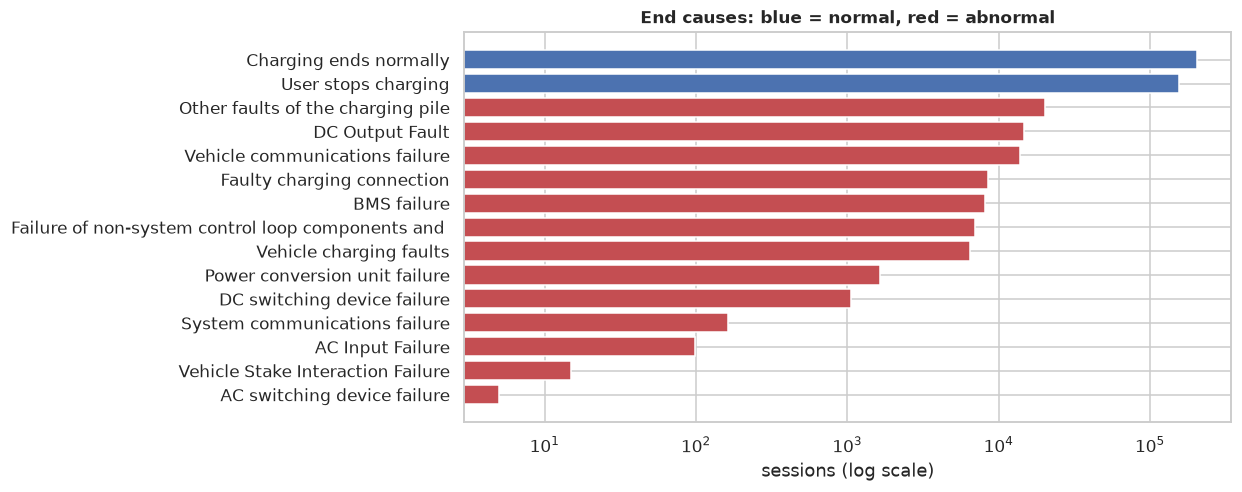

Abnormal: 81,934 sessions (18.58%) | normal: 359,143 | about 1 abnormal for every 4.4 normal
If 'User stops charging' were also abnormal, the abnormal share would be 53.93%


In [12]:
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}
fault_causes = set(df["end_cause"].unique()) - NORMAL_CAUSES
assert len(fault_causes) == 13 and all(("fault" in c.lower()) or ("failure" in c.lower()) for c in fault_causes)
df[TARGET] = (~df["end_cause"].isin(NORMAL_CAUSES)).astype("int8")

causes = df.groupby("end_cause").agg(
    sessions=("row_id", "size"),
    median_minutes=("duration_h", lambda s: s.median() * 60),
    zero_energy_share=("energy_kwh", lambda s: (s == 0).mean()),
).sort_values("sessions", ascending=False)
causes["label"] = np.where(causes.index.isin(NORMAL_CAUSES), "normal", "abnormal")
display(causes.round(2))

fig, ax = plt.subplots(figsize=(9, 4.6))
c_sorted = causes.sort_values("sessions")
ax.barh(c_sorted.index.str.slice(0, 50), c_sorted["sessions"],
        color=np.where(c_sorted["label"] == "abnormal", C_ABN, C_NORMAL))
ax.set_xscale("log")
ax.set_xlabel("sessions (log scale)")
ax.set_title("End causes: blue = normal, red = abnormal")
savefig(fig, "05_1_end_causes")

share = df[TARGET].mean()
print(f"Abnormal: {df[TARGET].sum():,} sessions ({share:.2%}) | normal: {(df[TARGET] == 0).sum():,} "
      f"| about 1 abnormal for every {(1 - share) / share:.1f} normal")
print(f"If 'User stops charging' were also abnormal, the abnormal share would be "
      f"{(df['end_cause'] != 'Charging ends normally').mean():.2%}")

With this definition 18.58% of the sessions are abnormal, about 1 abnormal for every 4.4 normal ones. The classes are
unbalanced, so accuracy alone would be misleading: a model that always says "normal" is already 81% accurate. The definition
also matters a lot. If user stops counted as abnormal too, the abnormal share would jump to 53.93% and the problem would be
completely different.

The table also shows that most fault causes end after 1–2 minutes and deliver no energy at all, which already suggests that
energy and duration are consequences of the outcome. The 13 fault causes range from 20,114 sessions down to 5, but this does
not matter for a binary target.

### 5.2 Does the data support our definition?

The dataset authors already computed, for each session, the number of earlier abnormal sessions of the same post and of the
same user (for example `post_previous_abnormal_30D`). They used their own definition of "abnormal", which gave us an idea: if
we count the same thing with our label and get the same numbers, the authors most likely used the same definition as us.

A session *j* counts as an earlier session of session *i* if it ended before *i* started (`end_j ≤ start_i`) and inside the
window (the last 30 days). We compare our definition A with an alternative B, where user stops are also abnormal.

In [13]:
def count_previous_abnormal(frame, key, days, label):
    """For every session: how many earlier sessions of the same key (post or user) ended before this session
    started, inside the last `days` days, and were abnormal according to `label`."""
    start = frame["start_time"].to_numpy("datetime64[ns]").astype("int64")
    end = frame["end_time"].to_numpy("datetime64[ns]").astype("int64")
    window = days * 86_400 * 10**9
    result = np.zeros(len(frame), dtype="int64")
    for idx in frame.groupby(key).indices.values():
        order = np.argsort(end[idx])
        ends = end[idx][order]
        cum_abnormal = np.concatenate([[0], np.cumsum(label[idx][order])])
        upto = np.searchsorted(ends, start[idx], side="right")             # ended before (or when) this one started
        since = np.searchsorted(ends, start[idx] - window, side="right")   # ... and inside the window
        result[idx] = cum_abnormal[upto] - cum_abnormal[since]
    return result


options = {"A (ours): normal = ends normally + user stops": NORMAL_CAUSES,
           "B: normal = ends normally only": {"Charging ends normally"}}
agreement = {}
for name, normal in options.items():
    label = (~df["end_cause"].isin(normal)).astype(int).to_numpy()
    agreement[name] = {
        "post, 30 days": (count_previous_abnormal(df, "post_id", 30, label) == df["post_previous_abnormal_30D"]).mean(),
        "user, 30 days": (count_previous_abnormal(df, "user_id", 30, label) == df["user_previous_abnormal_30D"]).mean(),
    }
print("Share of rows where our count equals the column supplied with the dataset:")
display((pd.DataFrame(agreement).T * 100).round(2))

Share of rows where our count equals the column supplied with the dataset:


,"post, 30 days","user, 30 days"
A (ours): normal = ends normally + user stops,100.00,99.98
B: normal = ends normally only,0.26,35.85


In [14]:
# We guessed that the rates are smoothed as (abnormal + 1) / (sessions + 5); here we test it for all six windows
windows = ["post_previous_{}_1D", "post_previous_{}_7D", "post_previous_{}_30D",
           "user_previous_{}_30D", "user_previous_{}_180D", "user_previous_{}_730D"]
max_error = max(
    ((df[w.format("abnormal")] + 1) / (df[w.format("sessions")] + 5) - df[w.format("abnormal_rate")]).abs().max()
    for w in windows)
print(f"Largest difference between the formula and the supplied rate: {max_error:.1e}")
print("Rate of an entity without any history: (0 + 1) / (0 + 5) =", (0 + 1) / (0 + 5))

Largest difference between the formula and the supplied rate: 1.1e-16
Rate of an entity without any history: (0 + 1) / (0 + 5) = 0.2


With definition A our counts match the supplied columns in about 100% of the rows, while with B they match far less often.
So the dataset's history columns were built with the same definition of "abnormal" as ours, and we use definition A as the
target.

This check also taught us two other things. The counts only include sessions that ended before the current one started, so
the history columns contain no information from the future and can be used as predictors. And the rates follow the formula
(abnormal + 1) / (sessions + 5), a smoothing that avoids rates of exactly 0 or 1. Because of it, a post or user without
history always gets the rate 0.2, which is close to, but not the same as, the real abnormal share (0.186). We need to
remember this for new users (cold start, Section 9.5).

### 5.3 Label quality: "normal" sessions that delivered no energy

Since energy is so closely linked to the outcome, we also wanted to see which sessions delivered no energy at all.

In [15]:
zero_energy = df["energy_kwh"].eq(0)
display(pd.crosstab(df[TARGET].map({0: "normal", 1: "abnormal"}), zero_energy.map({False: "energy > 0", True: "energy = 0"})))
zn = df[zero_energy & (df[TARGET] == 0)]
print(f"Normal sessions with zero energy: {len(zn):,} ({len(zn) / (df[TARGET] == 0).sum():.1%} of normal sessions) | "
      f"causes: {zn['end_cause'].value_counts().to_dict()} | median duration: {zn['duration_h'].median() * 60:.2f} min")

energy_kwh,energy = 0,energy > 0
is_Abnormal,,
abnormal,45563,36371
normal,9058,350085


Normal sessions with zero energy: 9,058 (2.5% of normal sessions) | causes: {'User stops charging': 7730, 'Charging ends normally': 1328} | median duration: 0.95 min


As expected for failures, 45,563 abnormal sessions delivered no energy. What surprised us is that 9,058 sessions labelled
normal (2.5% of the normal class) also delivered no energy. Most of them are `User stops charging` after about one minute,
which looks like users who plugged in and changed their mind.

We decided to keep them as normal. To remove them we would need the energy, which is only known after the session, so we
could not apply the same filter when predicting. They add some label noise that a start-time model cannot fix.

In [16]:
log_decision("5", "Target", "is_Abnormal = 1 when end_cause is one of the 13 fault/failure causes; "
             "'Charging ends normally' and 'User stops charging' are normal.",
             "Our counts reproduce the dataset's own previous-abnormal columns in ~100% of rows (alternative B does not). "
             "Share 18.58% (53.93% if user stops were abnormal).")
log_decision("5", "Label noise", "Keep the 9,058 zero-energy sessions labelled normal.",
             "Plausible user cancellations; filtering on energy (post-session) cannot be repeated at prediction time.")

---
## 6. Missing values

The slides say that missing data can take many forms (`<empty>`, `0`, `999`, `unknown`, …). Before choosing a strategy, we
must understand why a value is missing.

> **Note.** From here on, any analysis that guides a modelling decision uses only the training period (2020-04-01 to
> 2021-06-30, chosen in Sections 7 and 11), so that the validation and test periods do not influence our choices. We call
> this subset `dev`. The whole file is only used to describe data quality and changes over time.

In [17]:
df["period"] = np.select([df["start_time"] < BURN_IN_END, df["start_time"] < TRAIN_END, df["start_time"] < VAL_END],
                         ["burn-in", "train", "validation"], "test")
dev = df[df["period"] == "train"]

FLAG_OF = {   # "time since ..." column -> its "no history" indicator
    "post_hours_since_previous_completed_session": "post_no_previous_completed_session",
    "post_hours_since_previous_completed_abnormal": "post_no_previous_completed_abnormal",
    "user_days_since_previous_completed_session": "user_no_previous_completed_session",
    "user_days_since_previous_completed_abnormal": "user_no_previous_completed_abnormal",
}
print("Columns with missing values:", df.columns[df.isna().any()].tolist())
missing = pd.DataFrame({
    "missing": [df[c].isna().sum() for c in FLAG_OF],
    "missing %": [round(df[c].isna().mean() * 100, 2) for c in FLAG_OF],
    "no-history flag = 1": [df[f].eq(1).sum() for f in FLAG_OF.values()],
    "rows where NaN and flag disagree": [(df[c].isna() != df[f].eq(1)).sum() for c, f in FLAG_OF.items()],
}, index=list(FLAG_OF))
display(missing)

Columns with missing values: ['post_hours_since_previous_completed_session', 'post_hours_since_previous_completed_abnormal', 'user_days_since_previous_completed_session', 'user_days_since_previous_completed_abnormal']


,missing,missing %,no-history flag = 1,rows where NaN and flag disagree
post_hours_since_previous_completed_session,92,0.02,92,0
post_hours_since_previous_completed_abnormal,367,0.08,367,0
user_days_since_previous_completed_session,56647,12.84,56647,0
user_days_since_previous_completed_abnormal,136279,30.90,136279,0


In [18]:
# Look for disguised missing values: typical codes in numeric columns and "unknown"-like labels in text columns
numeric_cols = [c for c in raw.select_dtypes("number").columns if c not in ("UserID", "Charging Post ID")]
codes = {c: int(raw[c].isin([-1, -99, -999, 999, 9999]).sum()) for c in numeric_cols}
print("Numeric columns containing -1, -99, -999, 999 or 9999:", {c: n for c, n in codes.items() if n} or "none")
unknown_words = {"unknown", "unk", "na", "n/a", "", "-", "none", "null"}
print("Text labels meaning 'unknown':",
      {c: [v for v in df[c].unique() if str(v).lower() in unknown_words] for c in ["location", "district", "tariff_period", "end_cause"]})

# Does being missing say something about the outcome? (training period only)
info = pd.DataFrame({c: {"abnormal rate if missing": dev.loc[dev[c].isna(), TARGET].mean(),
                         "abnormal rate if present": dev.loc[dev[c].notna(), TARGET].mean(),
                         "missing in training period": int(dev[c].isna().sum())} for c in FLAG_OF}).T
display(info.round(3))

Numeric columns containing -1, -99, -999, 999 or 9999: {'user_previous_sessions_30D': 2, 'user_previous_sessions_180D': 1, 'user_previous_sessions_730D': 4, 'user_previous_abnormal_730D': 1}
Text labels meaning 'unknown': {'location': [], 'district': [], 'tariff_period': [], 'end_cause': []}


,abnormal rate if missing,abnormal rate if present,missing in training period
post_hours_since_previous_completed_session,NaN,0.178,0.0
post_hours_since_previous_completed_abnormal,NaN,0.178,0.0
user_days_since_previous_completed_session,0.203,0.175,32829.0
user_days_since_previous_completed_abnormal,0.144,0.193,80433.0


Only four "time since the previous …" columns have missing values, and every missing value matches its no-history flag, with
0 disagreements. So the value is missing because the event never happened (there was no earlier session, or no earlier
failure), not because it is unknown. This is what is called *structural* missingness. Disguised missing values were not a problem either: the few values equal to 999 or 9999 are ordinary session counts of very active (fleet) accounts, and
no text label means "unknown".

The two post columns are only missing at the very start of the file (the first sessions of each post), so they have no
missing values in the training period. The two user columns stay missing for 12–30% of the sessions, because new users keep
arriving. The missingness also carries information: users with no earlier failure are abnormal less often (see the table).

To decide what to do, we went through the options on the slide *Dealing with missing values*. Deleting the rows would remove
12–30% of the data, and exactly the new users the model must handle. Filling with the mean or median does not make sense,
because "never happened" is not a typical value, and it would also reduce the variance and distort the distribution.
Model-based imputation (regression, kNN) would invent a "plausible" value for something we know never happened. So we do not
delete or impute anything. Tree models can work with `NaN` directly, so for them we keep the `NaN` and the flags. For linear
and distance models we fill the value with the training maximum ("never happened" is close to "a very long time ago") and
keep the flag; this value is learned on the training period only (Section 13).

In [19]:
log_decision("6", "Missing values", "No deletion, no mean/median or model imputation. Trees: keep NaN + flags. "
             "Linear models: fill with the training maximum + keep the flags.",
             "NaN equals the no-history flag in 100% of rows (structural); missingness is related to the outcome.")

---
## 7. Changes over time

The brief asks whether *session volume, class prevalence, predictor distributions and user/post activity remain stable over
time*. This matters for us because, if they change, a random train/test split would give over-optimistic results.

### 7.1 Volume, abnormal share and activity per month

,sessions,abnormal_pct,active_users,active_posts,new_user_pct,mean_post_sessions_30D
start_time,,,,,,
2020-01,6217,25.0,1963,92,31.4,52.8
2020-02,1391,26.3,516,83,23.7,45.1
2020-03,6392,24.8,1797,92,20.9,67.5
2020-04,11136,22.1,2622,92,15.5,160.8
2020-05,15033,19.2,3153,92,12.4,222.4
2020-06,17513,16.0,3185,91,9.7,237.2
2020-07,22032,18.2,3704,92,8.8,272.0
2020-08,25562,20.1,4733,92,10.4,334.1
2020-09,20231,18.6,4642,92,12.7,316.5


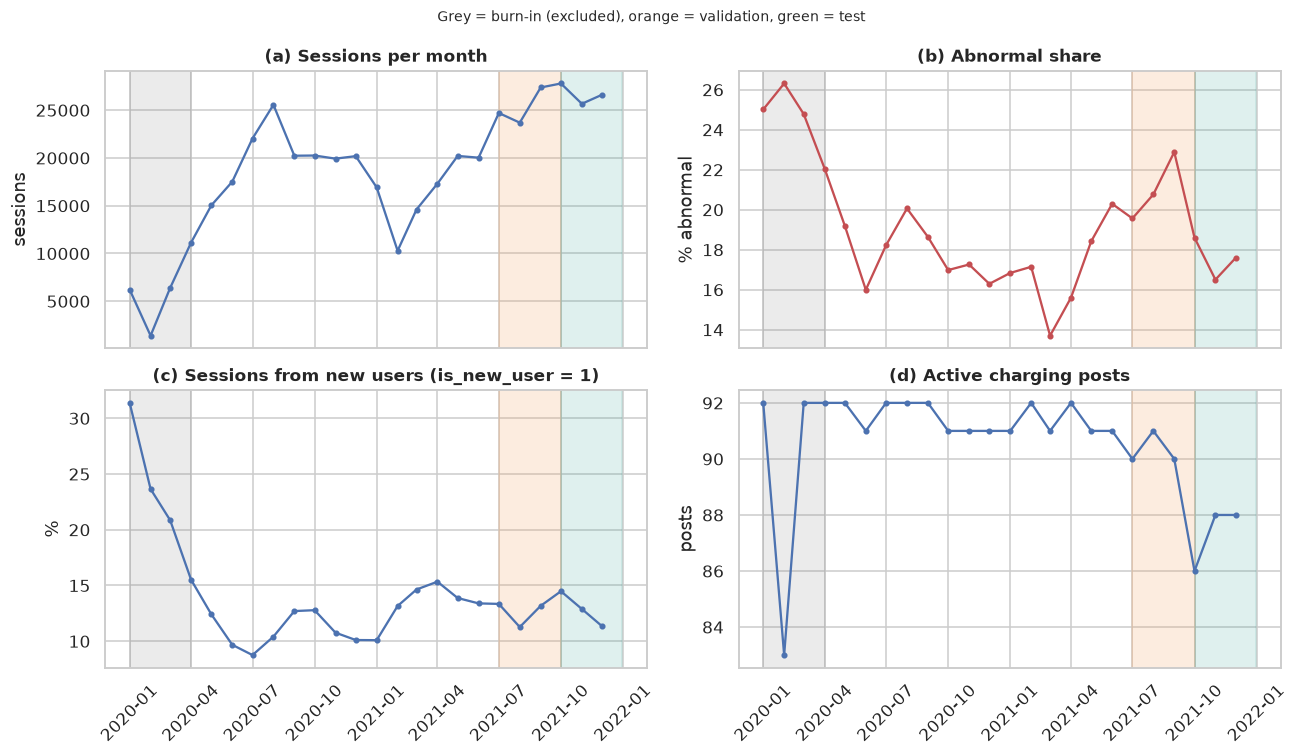

In [20]:
d = df[df["start_time"] >= "2020-01-01"]          # the file starts on the evening of 31-Dec-2019 (17 sessions)
monthly = d.groupby(d["start_time"].dt.to_period("M")).agg(
    sessions=(TARGET, "size"),
    abnormal_pct=(TARGET, "mean"),
    active_users=("user_id", "nunique"),
    active_posts=("post_id", "nunique"),
    new_user_pct=("is_new_user", "mean"),
    mean_post_sessions_30D=("post_previous_sessions_30D", "mean"),
)
monthly[["abnormal_pct", "new_user_pct"]] *= 100
display(monthly.round(1))

x = monthly.index.to_timestamp()
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
panels = [("sessions", "(a) Sessions per month", "sessions"),
          ("abnormal_pct", "(b) Abnormal share", "% abnormal"),
          ("new_user_pct", "(c) Sessions from new users (is_new_user = 1)", "%"),
          ("active_posts", "(d) Active charging posts", "posts")]
for ax, (col, title, ylabel) in zip(axes.ravel(), panels):
    ax.axvspan(x.min(), BURN_IN_END, color=C_GREY, alpha=.15)
    ax.axvspan(TRAIN_END, VAL_END, color="#f4a261", alpha=.2)
    ax.axvspan(VAL_END, x.max() + pd.offsets.MonthEnd(1), color="#2a9d8f", alpha=.15)
    ax.plot(x, monthly[col], marker="o", ms=3, color=C_ABN if col == "abnormal_pct" else C_NORMAL)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Grey = burn-in (excluded), orange = validation, green = test", fontsize=9)
fig.tight_layout()
savefig(fig, "07_1_monthly_volume_prevalence_activity")

Volume changes a lot. It starts at about 6,200 sessions in January 2020 and drops to 1,391 in February 2020, probably because
of the COVID-19 restrictions (this is outside knowledge, not something in the data). It then grows to over 25,000 by August
2020, dips again around February 2021 and reaches 25–28k per month in autumn 2021.

The abnormal share moves too. It is 25–26% in Q1-2020, falls to about 16% in mid-2020, reaches its lowest point of 13.7% in
March 2021, rises to 22.9% in September 2021 and ends around 17–19%. With 10–28k sessions per month, we do not think these
are random fluctuations.

The first months look different from the rest. In January 2020, 31% of the sessions come from "new" users, compared with
about 9–15% later, and the 30-day post counts are still filling up. The file starts on 31-Dec-2019, so "new user" really
means first session in the file, not first session ever, and the history columns are incomplete at the start. About 90–92
posts are active every month until September 2021, when four posts stop (Section 7.4).

### 7.2 Does the *type* of failure change?

The abnormal share could stay stable while the type of failure changes underneath, so we grouped the 13 fault causes into four
families and looked at how much each family adds to the abnormal share in each quarter.

end_cause,Connection fault,DC output fault,Other charger faults,Vehicle side
start_time,,,,
2020Q1,7.1,2.9,7.0,8.0
2020Q2,4.0,3.2,6.7,4.7
2020Q3,1.1,5.2,7.2,5.6
2020Q4,1.0,3.3,5.8,6.8
2021Q1,1.1,3.2,5.4,6.2
2021Q2,1.4,3.0,6.8,7.1
2021Q3,2.3,2.9,9.0,6.9
2021Q4,1.9,2.8,6.0,7.0


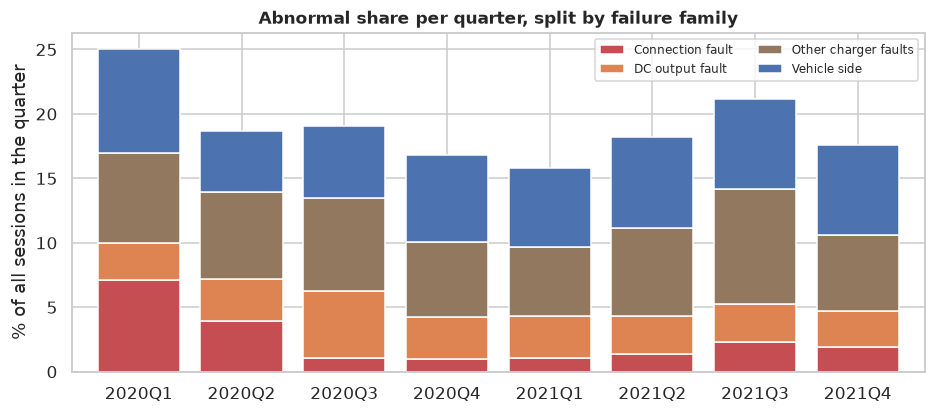

In [21]:
FAMILY = {
    "Faulty charging connection": "Connection fault",
    "DC Output Fault": "DC output fault",
    "Vehicle communications failure": "Vehicle side",
    "BMS failure": "Vehicle side",
    "Vehicle charging faults": "Vehicle side",
    "Vehicle Stake Interaction Failure": "Vehicle side",
}
quarter = d["start_time"].dt.to_period("Q")
abn = d[d[TARGET] == 1]
family = abn["end_cause"].map(FAMILY).fillna("Other charger faults")
contribution = pd.crosstab(quarter[abn.index], family).div(quarter.value_counts().sort_index(), axis=0) * 100
display(contribution.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
contribution.plot(kind="bar", stacked=True, ax=ax, width=.8, color=["#C44E52", "#DD8452", "#937860", "#4C72B0"])
ax.set_ylabel("% of all sessions in the quarter")
ax.set_xlabel("")
ax.set_title("Abnormal share per quarter, split by failure family")
ax.legend(fontsize=8, ncol=2)
plt.xticks(rotation=0)
savefig(fig, "07_2_fault_family_by_quarter")

Connection faults add 7.1 percentage points to the abnormal share in Q1-2020, 4.0 in Q2-2020 and only 1–2 from Q3-2020
onwards, while the other families are steadier. So this one family explains most of the early drop in the abnormal share. Our
guess is that it was an early problem that was later fixed, but the data cannot confirm this.

For modelling, this means the start of 2020 shows a failure pattern that no longer exists, which is another reason to leave it
out of training (Section 7.5). It also warns us that the mix of failures could change again after a model is deployed.

### 7.3 Do stations and posts keep the same behaviour?

We also wanted to know whether the risky stations and posts stay risky over time.

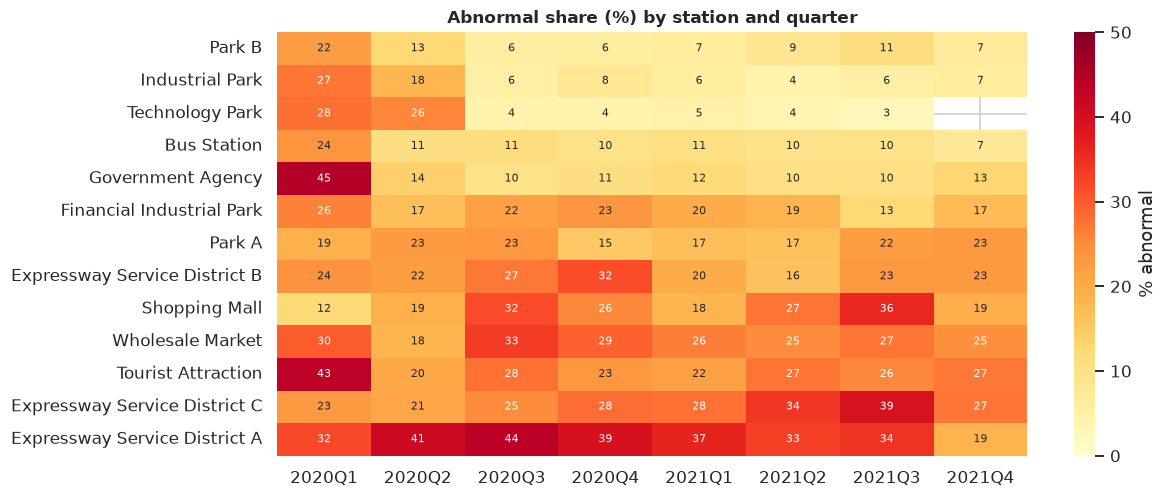

Do posts keep their abnormal share? Spearman correlation between Apr-Dec 2020 and 2021: 0.81 (92 posts)


In [22]:
by_station_q = d.groupby(["location", quarter])[TARGET].agg(["mean", "size"])
heat = (by_station_q["mean"].where(by_station_q["size"] >= 200) * 100).unstack()   # hide cells with < 200 sessions
heat = heat.loc[heat.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=50, cbar_kws={"label": "% abnormal"}, ax=ax,
            annot_kws={"fontsize": 7})
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Abnormal share (%) by station and quarter")
savefig(fig, "07_3_station_by_quarter")

rate_2020 = df[(df["start_time"] >= BURN_IN_END) & (df["start_time"] < "2021-01-01")].groupby("post_id")[TARGET].mean()
rate_2021 = df[df["start_time"] >= "2021-01-01"].groupby("post_id")[TARGET].mean()
print(f"Do posts keep their abnormal share? Spearman correlation between Apr-Dec 2020 and 2021: "
      f"{rate_2020.corr(rate_2021, method='spearman'):.2f} ({rate_2020.index.intersection(rate_2021.index).size} posts)")

Stations differ a lot, and their ranking is fairly stable: Park B, Industrial Park, Technology Park and Bus Station stay low,
while the Expressway Service Districts, Wholesale Market, Shopping Mall and Tourist Attraction stay high. The levels still
move, though. Government Agency goes from 45% in Q1-2020 to 10–14%, and Shopping Mall rises to 36% in Q3-2021, so a fixed
"station effect" would not be enough and recent history is needed to follow these changes.

At the post level, the abnormal shares are persistent (Spearman 0.81 between 2020 and 2021). We think this is why the post's
own history is so useful (Section 9.4).

### 7.4 Do the predictors change? Post life cycle

Here we followed the quarterly median of a few predictors. If the median stays stable, the predictor behaves the same way over
time.

In [23]:
drift_cols = ["post_previous_sessions_30D", "post_previous_abnormal_rate_30D", "post_previous_abnormal_rate_7D",
              "user_previous_abnormal_rate_180D", "user_previous_sessions_180D", "temperature"]
drift = d.groupby(quarter)[drift_cols].median()
drift["new users %"] = d.groupby(quarter)["is_new_user"].mean() * 100
display(drift.round(3))

life = df.groupby("post_id").agg(first_session=("start_time", "min"), last_session=("start_time", "max"),
                                 sessions=("row_id", "size"), location=("location", "first"))
print("Posts that start after 15-Jan-2020:")
display(life[life["first_session"] > "2020-01-15"])
print("Posts with no session in the test period (from 2021-10-01):")
display(life[life["last_session"] < VAL_END])

,post_previous_sessions_30D,post_previous_abnormal_rate_30D,post_previous_abnormal_rate_7D,user_previous_abnormal_rate_180D,user_previous_sessions_180D,temperature,new users %
start_time,,,,,,,
2020Q1,48.0,0.211,0.200,0.200,3.0,9.3,25.807
2020Q2,173.0,0.169,0.152,0.189,16.0,23.4,12.108
2020Q3,319.0,0.123,0.121,0.167,28.0,27.9,10.557
2020Q4,305.0,0.123,0.114,0.167,31.0,14.6,11.222
2021Q1,239.0,0.115,0.119,0.167,20.0,9.6,12.434
2021Q2,266.0,0.127,0.125,0.167,14.0,22.6,14.148
2021Q3,330.0,0.151,0.143,0.181,14.0,28.6,12.634
2021Q4,367.0,0.149,0.141,0.177,15.0,13.1,12.928


Posts that start after 15-Jan-2020:


,first_session,last_session,sessions,location
post_id,,,,
85,2020-01-25 16:32:30,2021-12-31 22:23:49,4661,Wholesale Market


Posts with no session in the test period (from 2021-10-01):


,first_session,last_session,sessions,location
post_id,,,,
17,2020-01-01 15:27:51,2021-09-28 20:08:03,7328,Technology Park
18,2020-01-01 12:14:43,2021-09-28 20:30:53,7426,Technology Park
19,2020-01-01 12:52:10,2021-09-28 19:16:27,6935,Technology Park
20,2020-01-01 11:59:54,2021-09-28 20:51:02,7178,Technology Park


Q1-2020 is again different. For example, the median 30-day post count is much lower than later, because the rolling windows
are still filling up, but after the first months the history rates are fairly stable. Since traffic grows, the counts
(number of earlier sessions) keep increasing while the rates stay in the same range. We expect the rates to generalise better
to future periods than the counts. Temperature follows the seasons, which is normal and not a data problem.

Looking at the posts, only post 85 starts late (25-Jan-2020), and posts 17–20 (Technology Park) stop on 28-Sep-2021, so they
are missing from the test period. No post in validation or test is new, which means our split cannot test what happens with a
new post.

### 7.5 Consequences for modelling

These results changed how we set up the evaluation. Because the history columns are incomplete and the failure mix is
different in Q1-2020 (Sections 7.1, 7.2 and 7.4), we treat the first months as a burn-in and do not use sessions before
2020-04-01 for modelling (14,017 sessions, 3.2% of the file). Because volume, abnormal share and failure mix change over
time, we use a chronological split instead of a random one: training from Apr-2020 to Jun-2021, validation in 2021-Q3 and
test in 2021-Q4 (Section 11).

The abnormal share also differs between periods (13.7%–22.9%), so results should always be compared with the abnormal share
of the same period, and the decision thresholds may need adjusting. Finally, since counts grow with traffic and rates are
stable, we prefer the rates as the main history signal and keep an eye on the counts.

In [24]:
log_decision("7", "Burn-in", "Do not use sessions before 2020-04-01 for modelling.",
             "History columns incomplete at file start (new users 31% vs ~13%); different failure mix in Q1-2020.")
log_decision("7", "Time split", "Chronological split, no random split.",
             "Volume, abnormal share (13.7%-26.3%) and failure mix change over time.")

---
## 8. Leakage and availability at the start

### 8.1 How much do the "after the session" columns know about the outcome?

To measure this, we computed the univariate ROC-AUC of each variable on the training period. It tells us how well that one
variable alone separates normal from abnormal sessions (0.5 means not at all, 1.0 means perfectly). A variable that measures
the *result* of the session should separate the classes very well, because it already contains the outcome; for these columns a
high AUC marks a leaker.

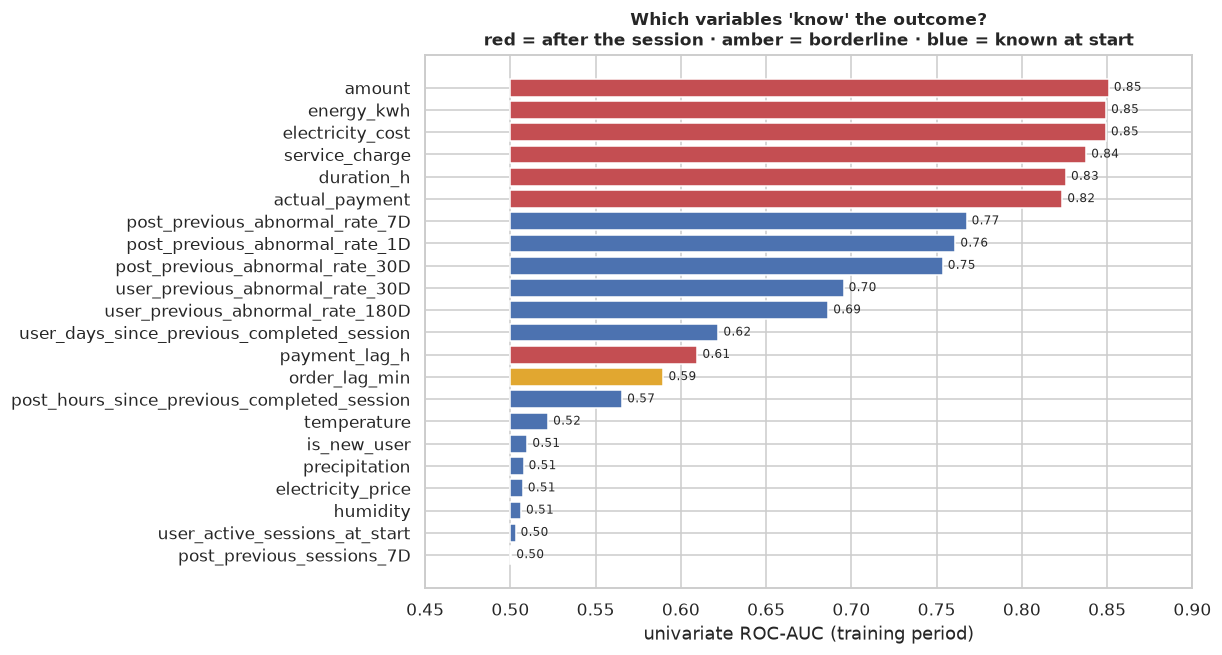

In [25]:
candidates = {
    "energy_kwh": "after", "electricity_cost": "after", "service_charge": "after", "amount": "after",
    "actual_payment": "after", "duration_h": "after", "payment_lag_h": "after",
    "order_lag_min": "borderline",
    "post_previous_abnormal_rate_7D": "at start", "post_previous_abnormal_rate_30D": "at start",
    "post_previous_abnormal_rate_1D": "at start", "user_previous_abnormal_rate_180D": "at start",
    "user_previous_abnormal_rate_30D": "at start", "post_hours_since_previous_completed_session": "at start",
    "user_days_since_previous_completed_session": "at start", "post_previous_sessions_7D": "at start",
    "is_new_user": "at start", "user_active_sessions_at_start": "at start",
    "temperature": "at start", "humidity": "at start", "precipitation": "at start", "electricity_price": "at start",
}
# NaN filled with the median only for this quick AUC check, not in the real pipeline
leak = pd.DataFrame({
    "known": pd.Series(candidates),
    "AUC": {c: auc(dev[TARGET], dev[c].fillna(dev[c].median())) for c in candidates},
}).sort_values("AUC")

fig, ax = plt.subplots(figsize=(9, 6.3))
colors = leak["known"].map({"after": C_ABN, "borderline": "#E1A730", "at start": C_NORMAL})
ax.barh(leak.index, leak["AUC"] - 0.5, left=0.5, color=colors)
for i, v in enumerate(leak["AUC"]):
    ax.text(v + .003, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0.45, 0.9)
ax.set_xlabel("univariate ROC-AUC (training period)")
ax.set_title("Which variables 'know' the outcome?\nred = after the session · amber = borderline · blue = known at start")
savefig(fig, "08_1_univariate_auc_by_availability")

The after-session variables (energy, money, duration) reach an AUC of 0.82–0.85 on their own, higher than any variable known
at the start (best about 0.77). Abnormal sessions are short and deliver little energy (Section 5.1), so these variables
describe the outcome instead of predicting it. A model trained on them would only learn to recognise a session that has
already failed.

Among the legitimate variables, post history comes first (0.75–0.77), then user history (about 0.69–0.70), then the
time-since variables, while weather, tariff and concurrency stay close to 0.5 (0.50–0.52). This only gives us an
expectation, because a single-variable AUC ignores interactions.

### 8.2 The unclear timestamp: `Order creation time`

Section 4.2 showed that the order time is often stamped after the start, so we looked at the delay in more detail.

In [26]:
bins = [-np.inf, -3, -1, 0, 1, 3, 10, 60, np.inf]
labels = ["< -3 min", "-3 to -1", "-1 to 0", "0 to +1", "+1 to +3", "+3 to +10", "+10 to +60", "> +60"]
lag = abnormal_rate(dev.assign(lag_bin=pd.cut(dev["order_lag_min"], bins=bins, labels=labels)), "lag_bin")
lag["share of sessions"] = lag["sessions"] / lag["sessions"].sum()
display(lag.round(3))
print(f"Order stamped after the start: {(dev['order_lag_min'] > 0).mean():.1%} of training sessions | "
      f"maximum delay: {dev['order_lag_min'].max():,.0f} min | AUC of the delay: {auc(dev[TARGET], dev['order_lag_min']):.2f}")

,sessions,abnormal_rate,share of sessions
lag_bin,,,
-3 to -1,14095,0.177,0.052
-1 to 0,102023,0.241,0.376
0 to +1,79921,0.150,0.295
+1 to +3,70682,0.113,0.261
+3 to +10,3522,0.287,0.013
+10 to +60,899,0.209,0.003
> +60,68,0.088,0.000


Order stamped after the start: 57.2% of training sessions | maximum delay: 972 min | AUC of the delay: 0.59


In 57.2% of the training sessions the order is stamped after the start, by up to 16 hours (and by days elsewhere in the file).
So we cannot be sure that the order time exists when we make the prediction. Its link to the outcome is also weak and
irregular (AUC 0.59). We think the delay reflects how the start procedure went, which is only known once the session has
begun, so we exclude it.

### 8.3 Decision on availability

Putting everything together, this is what we consider known at the start, and under which condition:

| Group | Known at start? | Condition in practice |
|-------|-----------------|-----------------------|
| Calendar, tariff | yes | none, it comes from the start time |
| Location (post, station, district) | yes | the post is known when the car is plugged in |
| Weather | assumed | a daily forecast must exist; if it were a measured daily value it would leak |
| Post history | yes | only sessions that ended before the start are counted (checked in Section 5.2) |
| User history | yes, if the account is identified | requires linking the session to an account (privacy, Section 9.5) |
| Concurrency | yes | the platform knows which sessions of the account are running |
| `Order creation time` | unclear | excluded |
| Energy, money, end time, payment time, `end_cause` | no | excluded (leakers) |

In [27]:
log_decision("8", "Leakers", "Exclude energy, the four money columns, end_time, payment_time and end_cause from the predictors.",
             "Only known after the session; univariate AUC 0.82-0.85, higher than any start-time variable.")
log_decision("8", "Order creation time", "Exclude from the predictors.",
             "Stamped after the start in 57.2% of training sessions; weak, irregular signal (AUC 0.59).")

---
## 9. Exploring the start-time predictors (training period)

For each group of predictors we wanted to see whether it separates normal from abnormal sessions, by how much, and what that
means for the preparation. In the plots, the dashed line is the overall abnormal share of the training period.

### 9.1 Location: district, station and post

,sessions,abnormal %
district,,
Nanhu,47467,16.3
Tongxiang,139891,14.6
Xiuzhou,83852,24.1


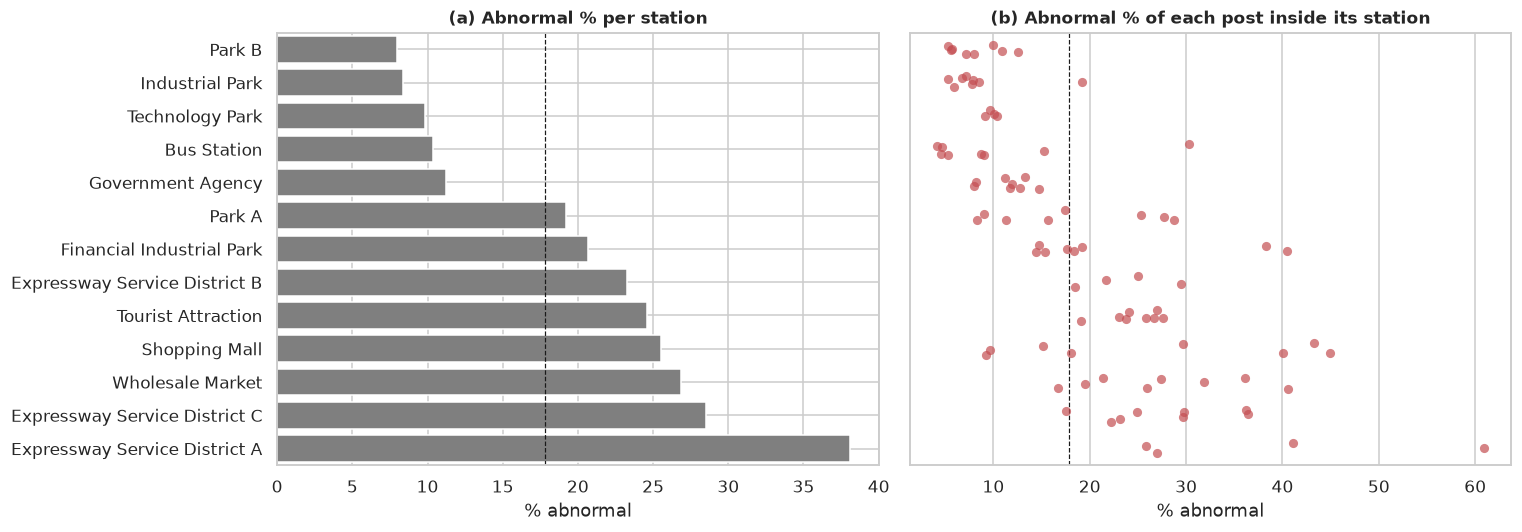

Post abnormal share: min 4.1%, max 60.9% | the 10 worst posts have 24.1% of the abnormal sessions but 10.2% of all sessions


In [28]:
overall = dev[TARGET].mean() * 100
display((abnormal_rate(dev, "district") * [1, 100]).round(1).rename(columns={"abnormal_rate": "abnormal %"}))
by_station = abnormal_rate(dev, "location").sort_values("abnormal_rate")
by_post = abnormal_rate(dev, "post_id").join(dev.groupby("post_id")["location"].first())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(by_station.index, by_station["abnormal_rate"] * 100, color=C_GREY)
axes[0].set_title("(a) Abnormal % per station")
sns.stripplot(x=by_post["abnormal_rate"] * 100, y=by_post["location"], order=by_station.index, ax=axes[1],
              color=C_ABN, size=6, alpha=.7, jitter=.2)
axes[1].set_title("(b) Abnormal % of each post inside its station")
for ax in axes:
    ax.axvline(overall, color="k", ls="--", lw=.8)
    ax.set_xlabel("% abnormal")
    ax.set_ylabel("")
fig.tight_layout()
savefig(fig, "09_1_location_and_posts")

post_rate = by_post["abnormal_rate"]
top10 = by_post.sort_values("abnormal_rate", ascending=False).head(10)
print(f"Post abnormal share: min {post_rate.min():.1%}, max {post_rate.max():.1%} | "
      f"the 10 worst posts have {(top10['abnormal_rate'] * top10['sessions']).sum() / dev[TARGET].sum():.1%} "
      f"of the abnormal sessions but {top10['sessions'].sum() / len(dev):.1%} of all sessions")

District matters a little (14.6% to 24.1%), and stations differ more, from about 8% (Park B) to 38% (Expressway A). What we
did not expect is how much the posts differ inside the same station: the Shopping Mall posts, for example, range from about
9% to 45%. Something specific to each post (for example hardware or maintenance) seems to matter, and failures are
concentrated in a few posts. The post shares go from 4.1% to 60.9%, and the 10 worst posts produce 24.1% of the abnormal
sessions with only 10.2% of all sessions.

So the post is the most informative location level. We still keep `location` and `district` as coarser fall-backs for a post
that has never been seen before.

### 9.2 Hour, day of week and tariff period

hour: abnormal % from 14.7% to 20.5%
day_of_week: abnormal % from 17.0% to 18.9%
tariff_period: abnormal % from 15.6% to 20.2%


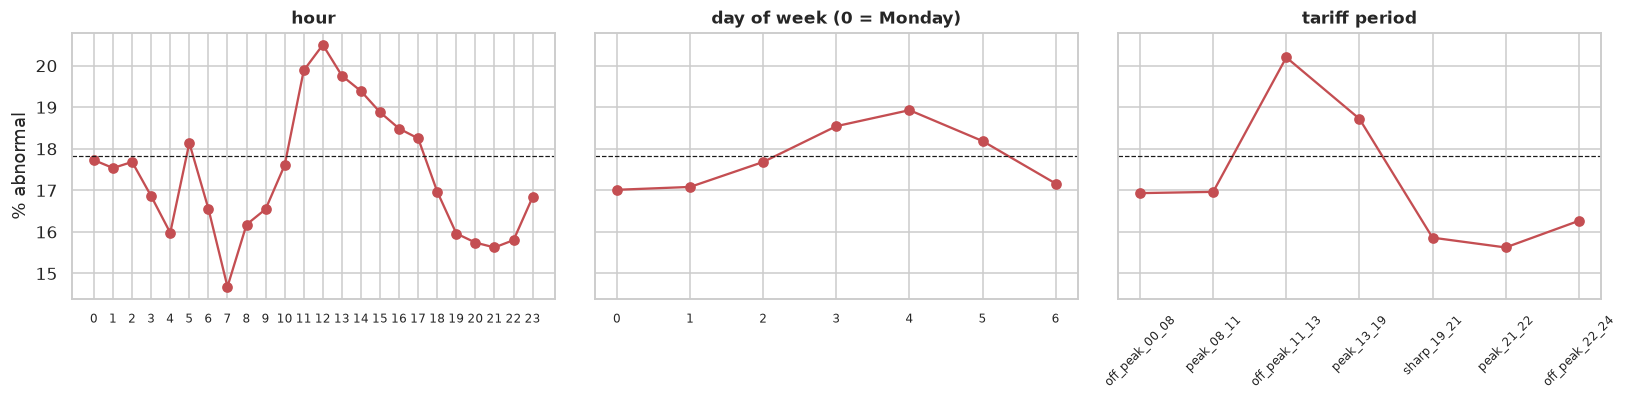

In [29]:
cal = dev.assign(hour=dev["start_time"].dt.hour, day_of_week=dev["start_time"].dt.dayofweek)
tariff_order = ["off_peak_00_08", "peak_08_11", "off_peak_11_13", "peak_13_19", "sharp_19_21", "peak_21_22", "off_peak_22_24"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, col in zip(axes, ["hour", "day_of_week", "tariff_period"]):
    t = abnormal_rate(cal, col)
    if col == "tariff_period":
        t = t.loc[tariff_order]
    ax.plot(range(len(t)), t["abnormal_rate"] * 100, "o-", color=C_ABN)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=45 if col == "tariff_period" else 0, fontsize=8)
    ax.axhline(overall, color="k", ls="--", lw=.8)
    ax.set_title(col.replace("_", " ") + (" (0 = Monday)" if col == "day_of_week" else ""))
    print(f"{col}: abnormal % from {t['abnormal_rate'].min():.1%} to {t['abnormal_rate'].max():.1%}")
axes[0].set_ylabel("% abnormal")
fig.tight_layout()
savefig(fig, "09_2_calendar_and_tariff")

The calendar effects are small. The abnormal share moves by only a few points across the hours, with midday slightly riskier,
and the days of the week are close to each other (17.0% to 18.9%). The tariff curve copies the hour curve, which makes sense
because the tariff period is just a grouping of the hour (Section 4.3).

We still keep the hour, the day of week and the tariff period. Hour and day of week are *circular* (23h is next to 0h), so they
get a special encoding in Section 13. We expect them to add little, and the group ablation in Task 2 will measure it.

### 9.3 Weather

To explore the weather we cut it into bins with domain-based cut points (the *custom discretisation* from the slides). The bins
are only for these plots; the models will receive the continuous values (Section 12.6).

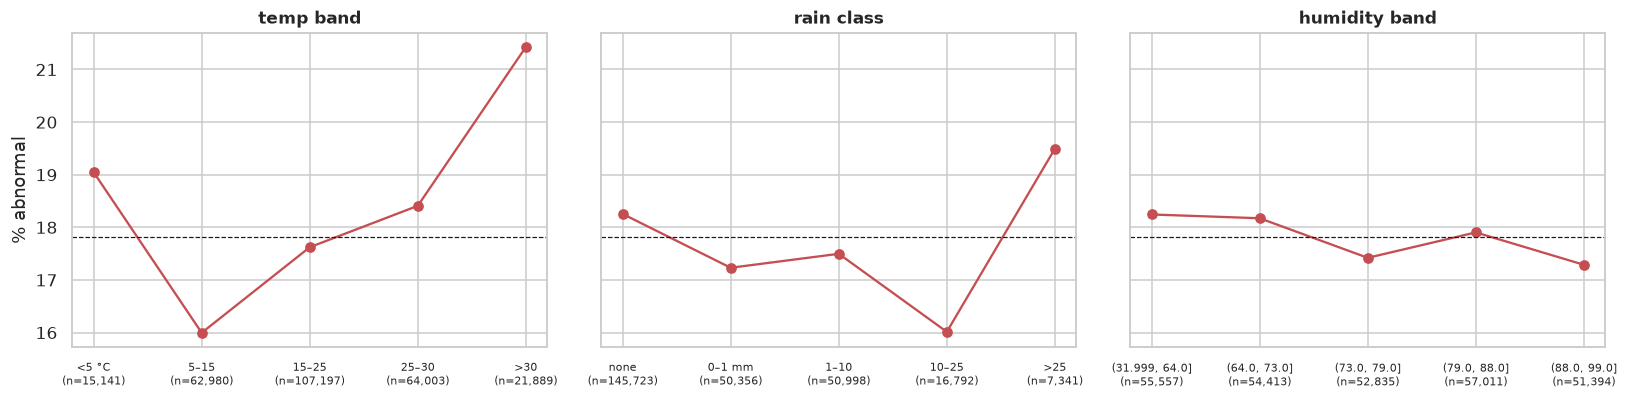

,temperature,humidity,precipitation
temperature,1.00,0.17,0.06
humidity,0.17,1.00,0.70
precipitation,0.06,0.70,1.00


Sessions on rainy days: 46.3%


In [30]:
w = dev.assign(
    temp_band=pd.cut(dev["temperature"], [-np.inf, 5, 15, 25, 30, np.inf], labels=["<5 °C", "5–15", "15–25", "25–30", ">30"]),
    rain_class=pd.cut(dev["precipitation"], [-np.inf, 0, 1, 10, 25, np.inf],
                      labels=["none", "0–1 mm", "1–10", "10–25", ">25"]),
    humidity_band=pd.qcut(dev["humidity"], 5),
)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, col in zip(axes, ["temp_band", "rain_class", "humidity_band"]):
    t = abnormal_rate(w, col)
    ax.plot(range(len(t)), t["abnormal_rate"] * 100, "o-", color=C_ABN)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t["sessions"])], fontsize=7)
    ax.axhline(overall, color="k", ls="--", lw=.8)
    ax.set_title(col.replace("_", " "))
axes[0].set_ylabel("% abnormal")
fig.tight_layout()
savefig(fig, "09_3_weather")
display(dev[["temperature", "humidity", "precipitation"]].corr(method="spearman").round(2))
print(f"Sessions on rainy days: {(dev['precipitation'] > 0).mean():.1%}")

The weather effects are weak and not linear. Temperature is U-shaped (cold and hot days are slightly riskier), rain is
irregular and humidity is almost flat. Humidity and precipitation are related (Spearman 0.70), and precipitation is zero on
about half of the days, with a long tail.

Another thing we realised is that weather has one value per district and day, so there are only about 1,400 different weather
situations, not 271k. This makes it easy to over-fit, and weather is mixed up with the season and with the changes over time
from Section 7. We keep the three variables as one group, without expecting much from them, and add a `rain_flag` (rain
yes/no). Linear models get precipitation on a log scale (Sections 12 and 13).

### 9.4 History columns: the main signal

Each panel splits a history variable into 10 equal-size groups (deciles, only to draw the plot) and shows the abnormal share in
each group. The steeper the curve, the better the variable separates the classes.

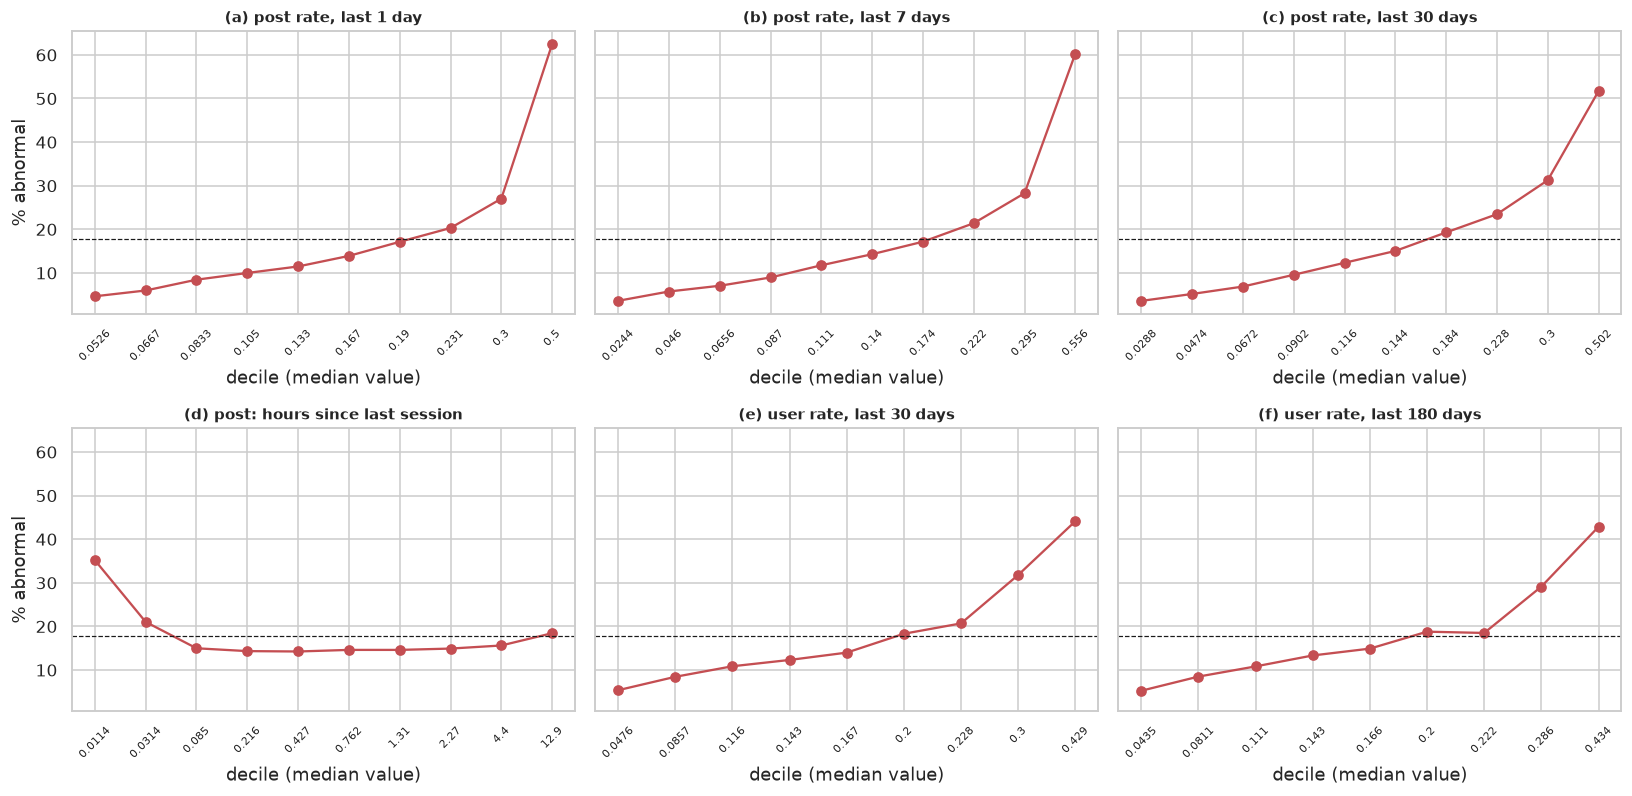

In [31]:
def decile_curve(ax, col, title):
    data = dev.dropna(subset=[col])
    groups = pd.qcut(data[col], 10, duplicates="drop")
    t = data.groupby(groups, observed=True).agg(median=(col, "median"), rate=(TARGET, "mean"))
    ax.plot(range(len(t)), t["rate"] * 100, "o-", color=C_ABN)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{v:.3g}" for v in t["median"]], rotation=45, fontsize=7)
    ax.axhline(overall, color="k", ls="--", lw=.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("decile (median value)")


panels = [("post_previous_abnormal_rate_1D", "(a) post rate, last 1 day"),
          ("post_previous_abnormal_rate_7D", "(b) post rate, last 7 days"),
          ("post_previous_abnormal_rate_30D", "(c) post rate, last 30 days"),
          ("post_hours_since_previous_completed_session", "(d) post: hours since last session"),
          ("user_previous_abnormal_rate_30D", "(e) user rate, last 30 days"),
          ("user_previous_abnormal_rate_180D", "(f) user rate, last 180 days")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), sharey=True)
for ax, (col, title) in zip(axes.ravel(), panels):
    decile_curve(ax, col, title)
for ax in axes[:, 0]:
    ax.set_ylabel("% abnormal")
fig.tight_layout()
savefig(fig, "09_4_history_deciles")

In [32]:
# Univariate ranking of every legitimate numeric column (a simple "filter method" from the slides)
legit_numeric = (["temperature", "humidity", "precipitation", "electricity_price", "user_active_sessions_at_start"]
                 + POST_HIST + USER_HIST)
ranking = pd.DataFrame({
    "group": ["post history" if c in POST_HIST else "user history" if c in USER_HIST else "context" for c in legit_numeric],
    "AUC": [auc(dev[TARGET], dev[c].fillna(dev[c].median())) for c in legit_numeric],
    "missing %": [dev[c].isna().mean() * 100 for c in legit_numeric],
    "skewness": [dev[c].skew() for c in legit_numeric],
}, index=legit_numeric).sort_values("AUC", ascending=False)
display(ranking.round(3))

,group,AUC,missing %,skewness
post_previous_abnormal_rate_7D,post history,0.768,0.000,2.287
post_previous_abnormal_rate_1D,post history,0.761,0.000,2.190
post_previous_abnormal_rate_30D,post history,0.754,0.000,2.061
post_hours_since_previous_completed_abnormal,post history,0.732,0.000,7.800
post_previous_abnormal_7D,post history,0.729,0.000,4.302
post_previous_abnormal_1D,post history,0.727,0.000,5.304
post_previous_abnormal_30D,post history,0.708,0.000,3.292
user_previous_abnormal_rate_30D,user history,0.695,0.000,1.521
user_previous_abnormal_rate_180D,user history,0.686,0.000,1.519
user_previous_abnormal_rate_730D,user history,0.685,0.000,1.539


Post history has strong and steady gradients. From the lowest to the highest decile of the 7-day post rate, the abnormal share
goes from about 4% to about 60%; in simple terms, a post that failed recently tends to fail again. The 1-day rate reacts
fastest and the 30-day rate is smoother, so the three windows describe different time scales. The time since the post's last
session is U-shaped: very quick restarts (seconds to minutes) are risky, which looks like retries after a failure, and very
long gaps are risky too.

User history also has a clear gradient, but a weaker one. Users without history get the rate 0.2 (Section 5.2), which puts them
in the middle. In the ranking, the post-history columns are at the top (AUC about 0.71–0.77), followed by user history (about
0.67–0.70), while the context variables (weather, tariff, concurrency) are close to 0.5. Many count and time-since columns are very skewed (skewness 3–9), which will matter for linear models (Sections 10 and 13).

### 9.5 Users: concentration, cold start and privacy

In [33]:
per_user = dev.groupby("user_id").agg(sessions=(TARGET, "size"), posts_used=("post_id", "nunique"))
top1pct = per_user["sessions"].sort_values(ascending=False).head(len(per_user) // 100).sum() / len(dev)
print(f"Accounts: {len(per_user):,} | median sessions per account: {per_user['sessions'].median():.0f} | "
      f"accounts with one session: {(per_user['sessions'] == 1).mean():.1%} | top 1% of accounts hold {top1pct:.1%} of sessions")
display(per_user.sort_values("sessions", ascending=False).head(5))

cold = pd.DataFrame({
    "sessions": [dev["is_new_user"].eq(1).sum(), dev["is_new_user"].eq(0).sum(),
                 dev["user_no_previous_completed_abnormal"].eq(1).sum(), dev["user_no_previous_completed_abnormal"].eq(0).sum()],
    "abnormal %": [dev.loc[dev["is_new_user"].eq(1), TARGET].mean(), dev.loc[dev["is_new_user"].eq(0), TARGET].mean(),
                   dev.loc[dev["user_no_previous_completed_abnormal"].eq(1), TARGET].mean(),
                   dev.loc[dev["user_no_previous_completed_abnormal"].eq(0), TARGET].mean()],
}, index=["new user (is_new_user = 1)", "returning user", "user without an earlier failure", "user with an earlier failure"])
cold["share of sessions %"] = cold["sessions"] / len(dev) * 100
cold["abnormal %"] *= 100
display(cold.round(1))

active = abnormal_rate(dev.assign(active=dev["user_active_sessions_at_start"].clip(upper=3)), "active")
display(active.rename(index={3: "3 or more"}).round(3))

Accounts: 34,294 | median sessions per account: 2 | accounts with one session: 44.9% | top 1% of accounts hold 34.2% of sessions


,sessions,posts_used
user_id,,
39,9044,92
23,3308,92
7841,905,41
1087,864,43
35,748,22


,sessions,abnormal %,share of sessions %
new user (is_new_user = 1),32561,20.2,12.0
returning user,238649,17.5,88.0
user without an earlier failure,80433,14.4,29.7
user with an earlier failure,190777,19.3,70.3


,sessions,abnormal_rate
active,,
0,258953,0.177
1,6471,0.243
2,1946,0.165
3 or more,3840,0.141


The users are very concentrated. There are 34,294 accounts in the training period, and about 45% of them have a single
session, but the top 1% of accounts hold about a third of all sessions. The largest accounts have thousands of sessions on all
92 posts, so they are probably fleet or operator accounts (we cannot verify this).

New users are 12% of the sessions. Their abnormal share is a bit higher (20.2% against 17.5%), and for them the user history is
empty or equal to 0.2. Users with an earlier failure fail more often (19.3% against 14.4%). Concurrency (other sessions of the
same account already running) has only a small, irregular effect.

This has three consequences for us. `user_id` is a key field with 56k values, so we do not use it as a feature (the slides list
key fields among the features to remove); most test sessions come from accounts never seen in training anyway (Section 11),
and the history columns are a better substitute. User history is also a behaviour profile linked to a persistent account ID,
so for privacy reasons it should only be used if it adds clear value over the post information, which Task 2 will test with
the group ablation. Finally, the history columns still work for new users (through the post history), but not for brand-new
posts.

---
## 10. Outliers

The slides say that outliers *have distinct characteristics from most of the other objects, but they may be valid*. So we first
detect them, then check whether they are valid, and only then choose between keeping, transforming, capping or removing them.

### 10.1 Detection with Tukey's fences (IQR)

We used the boxplot rule from the slides: a value is an outlier when it falls outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR].

,median,99th pct,max,skewness,IQR = 0,% outside fences
post_hours_since_previous_completed_session,0.575833,26.116492,2259.230556,66.082721,False,12.323661
user_active_sessions_at_start,0.0,3.0,14,8.683977,True,4.519376
post_hours_since_previous_completed_abnormal,19.894444,395.643472,2307.641111,7.799646,False,9.158954
user_days_since_previous_completed_session,0.715984,138.311847,533.24213,7.691429,False,15.150956
user_previous_sessions_30D,9.0,1934.0,2605,7.427716,False,6.719148
precipitation,0.0,36.2,152.1,6.83294,False,16.458464
user_previous_sessions_180D,21.0,4825.82,6495,6.29051,False,10.839202
user_previous_sessions_730D,24.0,7233.0,9946,6.232334,False,11.513219
user_previous_abnormal_30D,1.0,260.0,329,6.21433,False,11.060802
user_previous_abnormal_730D,3.0,1123.0,1547,5.995042,False,12.678367


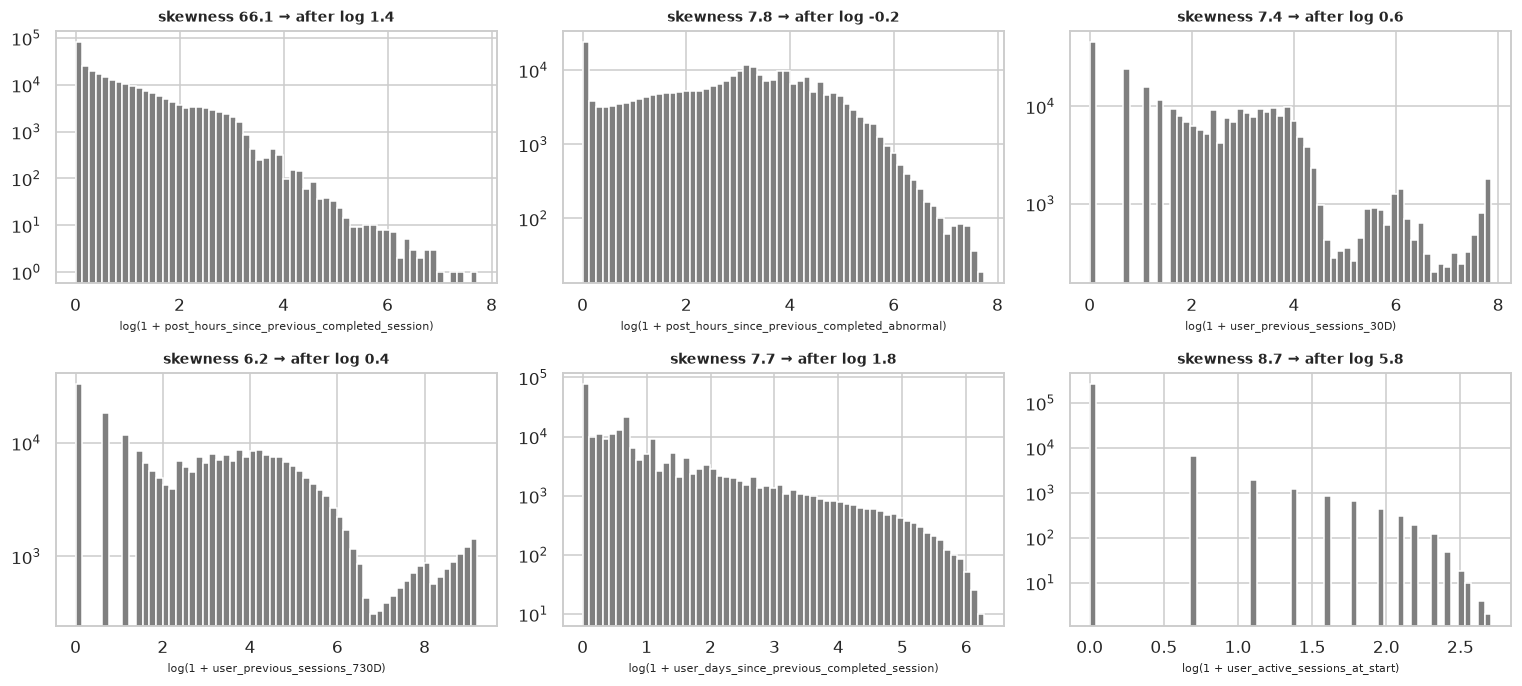

In [34]:
cont_cols = [c for c in legit_numeric if dev[c].nunique() > 2 and c != "electricity_price"]


def tukey(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    outside = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return {"median": s.median(), "99th pct": s.quantile(.99), "max": s.max(), "skewness": s.skew(),
            "IQR = 0": iqr == 0, "% outside fences": outside.mean() * 100}


outliers = pd.DataFrame({c: tukey(dev[c]) for c in cont_cols}).T.sort_values("skewness", ascending=False)
display(outliers.round(2))

heavy = ["post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal",
         "user_previous_sessions_30D", "user_previous_sessions_730D",
         "user_days_since_previous_completed_session", "user_active_sessions_at_start"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
for ax, c in zip(axes.ravel(), heavy):
    values = np.log1p(dev[c].dropna())
    ax.hist(values, bins=60, color=C_GREY)
    ax.set_yscale("log")
    ax.set_xlabel(f"log(1 + {c})", fontsize=7)
    ax.set_title(f"skewness {dev[c].skew():.1f} → after log {values.skew():.1f}", fontsize=9)
fig.tight_layout()
savefig(fig, "10_1_skewed_features_log_scale")

The post and user rates and the weather variables are well behaved. The counts and time-since variables, on the other hand,
have long right tails (skewness 3–9, and much more for the post idle time). For zero-inflated variables like
`user_active_sessions_at_start` the IQR is 0, so the fences flag every non-zero value and the "% outside fences" number means
nothing there. A log transformation (which the slides suggest for severe skewness) brings most of these variables below
skewness 2.

This only tells us that the values are extreme, not whether they are wrong, so we checked that next.

### 10.2 Are the extremes errors or real situations?

We picked the three most extreme situations and looked at them directly.

In [35]:
# (a) a post that was idle for more than 14 days
long_gap = dev[dev["post_hours_since_previous_completed_session"] > 24 * 14]
print(f"(a) Sessions after a post was idle for > 14 days: {len(long_gap)} on {long_gap['post_id'].nunique()} posts | "
      f"abnormal {long_gap[TARGET].mean():.1%} vs {dev[TARGET].mean():.1%} overall")

# (b) accounts with very many sessions
sessions_per_user = dev.groupby("user_id").size()
big_users = sessions_per_user[sessions_per_user > 500].index
big = dev[dev["user_id"].isin(big_users)]
print(f"(b) Accounts with > 500 sessions: {len(big_users)} | {len(big) / len(dev):.1%} of sessions | "
      f"abnormal {big[TARGET].mean():.1%} vs {dev.loc[~dev['user_id'].isin(big_users), TARGET].mean():.1%} for the others | "
      f"median posts used: {big.groupby('user_id')['post_id'].nunique().median():.0f}")

# (c) very heavy rain
storm = df[df["precipitation"] >= 100]
print("(c) Days with at least 100 mm of rain:")
display(storm.groupby(["district", storm["start_time"].dt.date])
        .agg(precipitation=("precipitation", "first"), humidity=("humidity", "first"),
             temperature=("temperature", "first"), sessions=("row_id", "size")))

(a) Sessions after a post was idle for > 14 days: 41 on 26 posts | abnormal 39.0% vs 17.8% overall
(b) Accounts with > 500 sessions: 21 | 9.1% of sessions | abnormal 15.1% vs 18.1% for the others | median posts used: 41
(c) Days with at least 100 mm of rain:


precipitation  humidity  temperature  sessions
district start_time                                                
Nanhu    2020-08-05          152.1        87         28.7       159
         2021-09-10          151.4        91         25.6       144
Xiuzhou  2021-09-10          151.4        91         25.6       349

### 10.3 Multivariate check with Isolation Forest

Univariate fences cannot see unusual combinations of values, so we also tried an Isolation Forest (one of the ML methods for
outliers in the slides). It flags the 1% most isolated sessions in a sample of 60,000 training sessions. Before fitting it, we
log-transformed the skewed columns and standardised everything.

In [36]:
sample = dev.sample(60_000, random_state=SEED)
X_iso = sample[cont_cols].copy()
skewed = [c for c in cont_cols if dev[c].skew() > 1]
X_iso[skewed] = np.log1p(X_iso[skewed])
X_iso = StandardScaler().fit_transform(X_iso.fillna(X_iso.max()))
flagged = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED).fit_predict(X_iso) == -1

display(pd.DataFrame({
    "flagged (1%)": [flagged.sum(), sample.loc[flagged, TARGET].mean(), sample.loc[flagged, "user_id"].isin(big_users).mean()],
    "other sessions": [(~flagged).sum(), sample.loc[~flagged, TARGET].mean(), sample.loc[~flagged, "user_id"].isin(big_users).mean()],
}, index=["sessions", "abnormal share", "share from accounts with > 500 sessions"]).round(3))

,flagged (1%),other sessions
sessions,600.000,59400.000
abnormal share,0.597,0.174
share from accounts with > 500 sessions,0.552,0.084


The extreme cases turned out to be real. When a post comes back after more than 14 days without sessions, the next sessions
are abnormal about twice as often as usual. These are posts coming back into service after an outage or maintenance, which is
a real and informative situation. The 21 accounts with more than 500 sessions each use dozens of different posts; they are
fleet or operator accounts, and their abnormal share is close to (slightly below) the others'. They are not errors, they just
work at a larger scale. The ~150 mm rain values fall on two storm days with high humidity and summer temperatures, which makes
physical sense.

The Isolation Forest points in the same direction. The most isolated sessions come mostly from the heavy accounts and have a
much higher abnormal share, so they are unusual but valid and informative.

For these reasons we never remove outliers: they are real operating situations, and removing them would hide exactly the
risky cases. For tree models we keep the values as they are, because trees split on the order of the values and not on their
size (the slides note that outliers do not affect them). For linear and distance models we also keep them, but apply `log1p`
to the skewed columns and standardise (Section 13), which reduces the influence of the long tails.

In [37]:
log_decision("10", "Outliers", "Keep all observations. Trees: no change. Linear models: log1p on skewed columns + standardisation.",
             "Extremes are valid: idle posts (~2x abnormal), fleet accounts, real storm days; Isolation Forest agrees.")

---
## 11. Data selection: time split and sampling

### 11.1 Chronological split with a purge

Following Section 7.5, we split the data by start time:
* burn-in: `start < 2020-04-01`, not used for modelling;
* train: `2020-04-01 ≤ start < 2021-07-01`;
* validation: `2021-07-01 ≤ start < 2021-10-01`, to compare models and choose thresholds;
* test: `start ≥ 2021-10-01`, used only once at the end.

One more step is needed, a purge. We only learn whether a session was abnormal when it ends, which can be up to 24 h later. A training
session that ends after the training cut-off would not have a label yet in real life, so we remove it from the training set.

In [38]:
df["split"] = df["period"].replace({"validation": "val"})
df.loc[(df["split"] == "train") & (df["end_time"] >= TRAIN_END), "split"] = "purged"
TRAIN, VAL, TEST = (df[df["split"] == s] for s in ("train", "val", "test"))

order = ["burn-in", "train", "purged", "val", "test"]
summary = df.groupby("split").agg(sessions=(TARGET, "size"), first=("start_time", "min"), last=("start_time", "max"),
                                  abnormal_share=(TARGET, "mean"), accounts=("user_id", "nunique"),
                                  posts=("post_id", "nunique")).loc[order]
summary["abnormal_share"] = summary["abnormal_share"].round(3)
display(summary)

train_users = set(TRAIN["user_id"])
display(pd.DataFrame({
    "% sessions from accounts not seen in train": [(~VAL["user_id"].isin(train_users)).mean() * 100,
                                                   (~TEST["user_id"].isin(train_users)).mean() * 100],
    "% sessions with is_new_user = 1": [VAL["is_new_user"].mean() * 100, TEST["is_new_user"].mean() * 100],
    "posts not seen in train": [len(set(VAL["post_id"]) - set(TRAIN["post_id"])), len(set(TEST["post_id"]) - set(TRAIN["post_id"]))],
}, index=["validation", "test"]).round(1))

,sessions,first,last,abnormal_share,accounts,posts
split,,,,,,
burn-in,14017,2019-12-31 21:27:03,2020-03-31 23:59:05,0.250,3629,92
train,271182,2020-04-01 00:06:39,2021-06-30 23:56:09,0.178,34293,92
purged,28,2021-06-30 12:52:02,2021-06-30 23:51:03,0.071,28,28
val,75769,2021-07-01 00:00:32,2021-09-30 23:59:16,0.211,14423,91
test,80081,2021-10-01 00:01:34,2021-12-31 23:52:14,0.176,15801,88


,% sessions from accounts not seen in train,% sessions with is_new_user = 1,posts not seen in train
validation,39.9,12.6,0
test,61.3,12.9,0


This gives 271,182 training sessions (only 28 purged), 75,769 validation sessions and 80,081 test sessions. The abnormal share
is 17.8% in train, 21.1% in validation and 17.6% in test, so a threshold chosen on validation will meet a different base rate
in the test period. We have to keep this in mind when comparing results.

The split also shows that 39.9% of the validation sessions and 61.3% of the test sessions come from accounts never seen in
training. This is why `user_id` is not used as a feature. Every post in validation and test, on the other hand, was already
seen in training.

For tuning in Task 2, a random K-fold would mix past and future. Instead we will use expanding-window folds inside the
training period: train on everything before a date and validate on the next quarter.

In [39]:
log_decision("11", "Split", "Train 2020-04-01..2021-06-30 (purged), validation 2021-Q3, test 2021-Q4 (used once).",
             "Changes over time (Section 7); 28 training sessions ended after the cut-off and were purged.")

### 11.2 A stratified sample for the slower diagnostics

Correlation, VIF and PCA (Section 12) are slow on 271k rows. According to the slides, *a sample works almost as well as the full
data if it is representative*, so we drew a stratified random sample of 100,000 training sessions that keeps the abnormal
share, and checked that it looks like the training set. We use it only for these diagnostics, never to fit a model.

In [40]:
SAMPLE_IDX = TRAIN.groupby(TARGET).sample(frac=100_000 / len(TRAIN), random_state=SEED).index
SAMPLE = df.loc[SAMPLE_IDX]
mean_gap = ((SAMPLE[cont_cols].mean() - TRAIN[cont_cols].mean()) / TRAIN[cont_cols].std()).abs()
print(f"Sample: {len(SAMPLE):,} rows | abnormal share sample {SAMPLE[TARGET].mean():.4f} vs train {TRAIN[TARGET].mean():.4f} | "
      f"largest difference in means: {mean_gap.max():.3f} standard deviations ({mean_gap.idxmax()})")

Sample: 100,000 rows | abnormal share sample 0.1782 vs train 0.1782 | largest difference in means: 0.006 standard deviations (post_hours_since_previous_completed_abnormal)


The sample keeps the abnormal share exactly, and every mean differs by less than a hundredth of a standard deviation, so we
consider it representative.

---
## 12. Feature engineering and reduction

Nothing in this section learns from the data. The steps are fixed rules, or deletions based on evidence we already have, so
they are safe to apply to every period. Everything that *learns* is in Section 13.

### 12.1 New variables

We created only three new variables:

| New variable | Definition | Why |
|--------------|------------|-----|
| `hour`, `dow` | hour of day (0–23) and day of week (0–6) of the start | the only calendar information known at the start. Both are circular, so linear models get a sine/cosine encoding (slide: *cyclical encoding*, Section 13) |
| `rain_flag` | `precipitation > 0` | precipitation is zero on about half of the days; the flag makes "rain / no rain" explicit |

We decided not to create month, year or a time index. A trend cannot be extrapolated into a future period, and the history
columns already follow the changes over time.

In [41]:
df["hour"] = df["start_time"].dt.hour.astype("int8")
df["dow"] = df["start_time"].dt.dayofweek.astype("int8")
df["rain_flag"] = (df["precipitation"] > 0).astype("int8")
TRAIN, VAL, TEST = (df[df["split"] == s] for s in ("train", "val", "test"))   # refresh with the new columns
SAMPLE = df.loc[SAMPLE_IDX]

### 12.2 Evidence for removing columns

The slides list several kinds of features to remove (key fields, columns without variability, redundant columns). Before
dropping anything, we checked each case in the data.

In [42]:
# (1) is_new_user and user_no_previous_completed_session look like the same indicator
differ = (TRAIN["is_new_user"] != TRAIN["user_no_previous_completed_session"]).mean()
print(f"(1) is_new_user vs user_no_previous_completed_session: they differ in {differ:.2%} of training rows")

# (2) post no-history indicators: do they vary?
for c in ["post_no_previous_completed_session", "post_no_previous_completed_abnormal"]:
    print(f"(2) {c}: ones in train {int(TRAIN[c].sum())}, validation {int(VAL[c].sum())}, test {int(TEST[c].sum())}")

# (3) abnormal counts = rate * (sessions + 5) - 1, so they add nothing once we have the sessions and the rate
error = max((df[w.format("abnormal_rate")] * (df[w.format("sessions")] + 5) - 1 - df[w.format("abnormal")]).abs().max()
            for w in windows)
print(f"(3) largest error when recomputing the abnormal counts from sessions and rate: {error:.1e}")

# (4) electricity_price is fixed by tariff_period (Section 4.3)
print("(4) different prices per tariff period:", df.groupby("tariff_period")["electricity_price"].nunique().max())

# (5) is a weekend flag useful?
weekend = TRAIN["dow"] >= 5
print(f"(5) abnormal share weekend {TRAIN.loc[weekend, TARGET].mean():.1%} vs weekdays {TRAIN.loc[~weekend, TARGET].mean():.1%}")

(1) is_new_user vs user_no_previous_completed_session: they differ in 0.10% of training rows
(2) post_no_previous_completed_session: ones in train 0, validation 0, test 0
(2) post_no_previous_completed_abnormal: ones in train 0, validation 0, test 0
(3) largest error when recomputing the abnormal counts from sessions and rate: 1.4e-12
(4) different prices per tariff period: 1
(5) abnormal share weekend 17.7% vs weekdays 17.9%


Based on these checks we drop, or do not create, the following columns:
1. `user_no_previous_completed_session`: it is almost the same indicator as `is_new_user` (they differ in about 0.1% of the
   rows), so we keep only `is_new_user`.
2. The two post no-history indicators: they are always 0 in train, validation and test, because all their ones are in the
   burn-in, and a column with no variability cannot be learned.
3. The six abnormal-count columns: they can be computed exactly from the session counts and the rates, so dropping them
   loses no information.
4. `electricity_price`: it is fixed by `tariff_period`.
5. A weekend flag: we did not create it, because it would separate the classes no better than the day of week it comes from.
6. `user_id`: it is a key field (Sections 9.5 and 11), so it is not a feature.

`post_id` (92 posts, none rare) stays a candidate, and Task 2 will decide whether it adds anything beyond the post history.

### 12.3 Correlation between the numeric features

The slides warn that *high correlation ≠ zero unique information*. Tree models handle correlated features well, but linear and
distance-based models can suffer from them, so we wanted to see how correlated our features are. We use the Spearman
correlation (robust to outliers) on the stratified sample. Before that, we apply `log1p` to unbounded columns with a training
skewness above 1, when the log at least halves the skewness. We fixed this rule *before* looking at the result, and it uses
only training data.

,train skewness,after log1p,log1p?
precipitation,6.83,1.65,True
post_previous_sessions_1D,1.37,-0.94,False
post_previous_sessions_7D,0.39,-1.30,False
post_previous_sessions_30D,0.13,-1.36,False
post_hours_since_previous_completed_session,66.08,1.42,True
post_hours_since_previous_completed_abnormal,7.80,-0.18,True
user_previous_sessions_30D,7.43,0.56,True
user_previous_sessions_180D,6.29,0.32,True
user_previous_sessions_730D,6.23,0.37,True
user_days_since_previous_completed_session,7.69,1.76,True


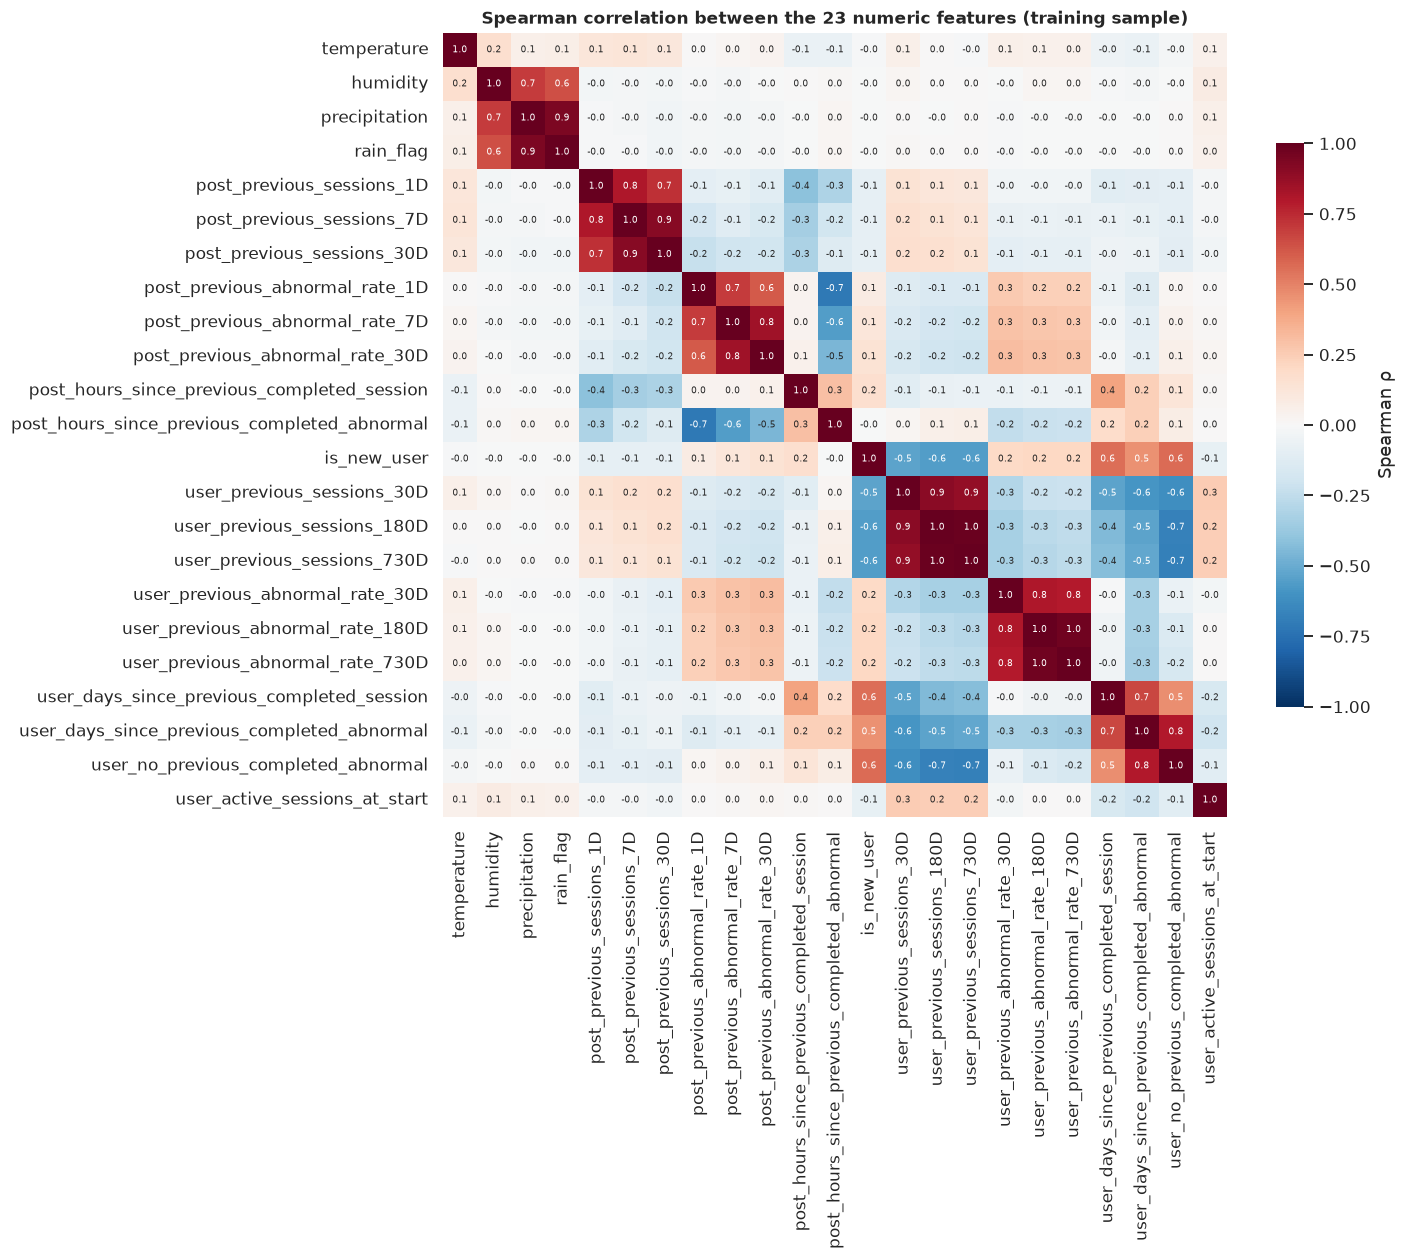

,level_0,level_1,rho
337,user_previous_sessions_180D,user_previous_sessions_730D,0.988
409,user_previous_abnormal_rate_180D,user_previous_abnormal_rate_730D,0.969
49,precipitation,rain_flag,0.939
121,post_previous_sessions_7D,post_previous_sessions_30D,0.909
313,user_previous_sessions_30D,user_previous_sessions_180D,0.905
314,user_previous_sessions_30D,user_previous_sessions_730D,0.876


In [43]:
GROUPS = {
    "calendar": ["hour", "dow"],
    "tariff": ["tariff_period"],
    "location": ["post_id", "location", "district"],
    "weather": ["temperature", "humidity", "precipitation", "rain_flag"],
    "post_history": ["post_previous_sessions_1D", "post_previous_sessions_7D", "post_previous_sessions_30D",
                     "post_previous_abnormal_rate_1D", "post_previous_abnormal_rate_7D", "post_previous_abnormal_rate_30D",
                     "post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal"],
    "user_history": ["is_new_user", "user_previous_sessions_30D", "user_previous_sessions_180D", "user_previous_sessions_730D",
                     "user_previous_abnormal_rate_30D", "user_previous_abnormal_rate_180D", "user_previous_abnormal_rate_730D",
                     "user_days_since_previous_completed_session", "user_days_since_previous_completed_abnormal",
                     "user_no_previous_completed_abnormal"],
    "concurrency": ["user_active_sessions_at_start"],
}
MODEL_FEATURES = [c for cols in GROUPS.values() for c in cols]
CATEGORICAL = ["post_id", "location", "district", "tariff_period"]
BINARY = ["rain_flag", "is_new_user", "user_no_previous_completed_abnormal"]
NUMERIC = [c for c in MODEL_FEATURES if c not in CATEGORICAL + ["hour", "dow"]]
assert len(MODEL_FEATURES) == 29 and len(NUMERIC) == 23

# log1p rule (training data only)
unbounded = [c for c in NUMERIC if c not in BINARY and "rate" not in c and c not in ("temperature", "humidity")]
skew = pd.DataFrame({"train skewness": TRAIN[unbounded].skew(), "after log1p": np.log1p(TRAIN[unbounded]).skew()})
skew["log1p?"] = (skew["train skewness"] > 1) & (skew["after log1p"].abs() <= skew["train skewness"].abs() / 2)
SKEW_LOG = skew.index[skew["log1p?"]].tolist()
display(skew.round(2))

X_diag = SAMPLE[NUMERIC].copy()
X_diag[SKEW_LOG] = np.log1p(X_diag[SKEW_LOG])
X_diag = X_diag.fillna(X_diag.max())            # "never happened" -> far end of the range (as in Section 13)
rho = X_diag.corr(method="spearman")

fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(rho, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, annot=True, fmt=".1f",
            annot_kws={"fontsize": 6}, cbar_kws={"label": "Spearman ρ", "shrink": .7}, ax=ax)
ax.set_title("Spearman correlation between the 23 numeric features (training sample)")
savefig(fig, "12_3_spearman_correlation")

pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack().rename("rho").reset_index()
display(pairs[pairs["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False).round(3))

The correlations form blocks that follow the feature groups: the user session counts (30/180/730 days), the user rates, the
post rates, the post session counts, and humidity, precipitation and rain flag. Only a few pairs reach |ρ| ≥ 0.85, and they
are always different windows of the same quantity, for example user sessions over 180 and 730 days. The three post-rate
windows are much less correlated with each other, which fits our idea that they carry different time scales.

Correlations between groups are low, so the groups are fairly separate sources of information. This is useful for the group
ablation in Task 2.

### 12.4 Variance Inflation Factor (VIF)

Pairwise correlations can miss combinations of several variables (a tip from the slides), so we also computed the VIF. It
regresses each feature on all the others, and a VIF above 10 means the feature is almost a linear combination of the others.

In [44]:
Xs = pd.DataFrame(StandardScaler().fit_transform(X_diag), columns=X_diag.columns)


def vif(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)


vif_all = vif(Xs)
display(vif_all.round(1).to_frame("VIF").T)

,user_previous_sessions_180D,user_previous_sessions_730D,user_previous_abnormal_rate_180D,user_previous_abnormal_rate_730D,user_previous_sessions_30D,user_days_since_previous_completed_abnormal,post_previous_sessions_7D,user_days_since_previous_completed_session,user_no_previous_completed_abnormal,post_previous_sessions_30D,post_previous_abnormal_rate_7D,user_previous_abnormal_rate_30D,is_new_user,post_previous_abnormal_rate_1D,post_previous_abnormal_rate_30D,post_previous_sessions_1D,rain_flag,precipitation,post_hours_since_previous_completed_abnormal,humidity,post_hours_since_previous_completed_session,user_active_sessions_at_start,temperature
VIF,65.4,50.9,28.3,26.4,10.8,7.5,7.5,6.4,5.8,5.7,5.4,4.8,4.7,3.6,3.3,3.0,2.1,2.0,2.0,1.9,1.5,1.3,1.1


Only a handful of features have a VIF above 10, and they are all user-history windows (the 180- and 730-day counts and rates).
The file covers only two years and most accounts are short-lived, so the 180-day and 730-day windows contain almost the same
sessions. Post history, weather and calendar have low VIFs.

### 12.5 What do we do with the redundancy?

The slides (*How to handle highly correlated pairs*) suggest different answers for different models. Tree models handle
correlated features without losing performance, so they keep all 29 features. Regularised linear models (L1/L2) also keep all
features, because the penalty takes care of the redundancy. For plain linear or distance models (for example k-NN) we built a
reduced set: we go through the features from the best to the worst univariate AUC and keep a feature only if its |ρ| with
every feature already kept is below 0.90. We fixed this threshold in advance.

In [45]:
auc_sample = pd.Series({c: auc(SAMPLE[TARGET], X_diag[c]) for c in NUMERIC}).sort_values(ascending=False)
kept, dropped = [], []
for c in auc_sample.index:
    clash = [k for k in kept if abs(rho.loc[c, k]) >= 0.90]
    if clash:
        dropped.append((c, round(auc_sample[c], 3), f"|ρ| = {abs(rho.loc[c, clash[0]]):.2f} with {clash[0]}"))
    else:
        kept.append(c)
LINEAR_REDUCED_NUMERIC = kept
display(pd.DataFrame(dropped, columns=["dropped from the reduced set", "AUC", "reason"]))
print(f"Reduced numeric set: {len(kept)} of {len(NUMERIC)} | maximum VIF {vif_all.max():.1f} -> {vif(Xs[kept]).max():.1f}")

,dropped from the reduced set,AUC,reason
0,user_previous_abnormal_rate_730D,0.687,|ρ| = 0.97 with user_previous_abnormal_rate_180D
1,user_previous_sessions_180D,0.554,|ρ| = 0.99 with user_previous_sessions_730D
2,precipitation,0.508,|ρ| = 0.94 with rain_flag
3,post_previous_sessions_7D,0.505,|ρ| = 0.91 with post_previous_sessions_30D


Reduced numeric set: 19 of 23 | maximum VIF 65.4 -> 8.6


The rule drops four features: one long user window of the rate and one of the counts, `precipitation` (in favour of
`rain_flag`) and one post-count window. In each pair both features have almost the same AUC, so it hardly matters which one
we keep, and the maximum VIF falls below 10. The downside is that dropping `precipitation` loses the amount of rain, but its
effect was weak anyway (Section 9.3).

### 12.6 PCA and discretisation: considered, not adopted

We also tried PCA, which replaces the features with a smaller set of components that keep most of the variance. Following the
slides, we aimed for about 90% of the variance.

Components needed for 90% of the variance: 11 of 23 | first component: 22.8%


Univariate AUC of the first five components: {'PC1': 0.51, 'PC2': 0.8, 'PC3': 0.53, 'PC4': 0.5, 'PC5': 0.59}


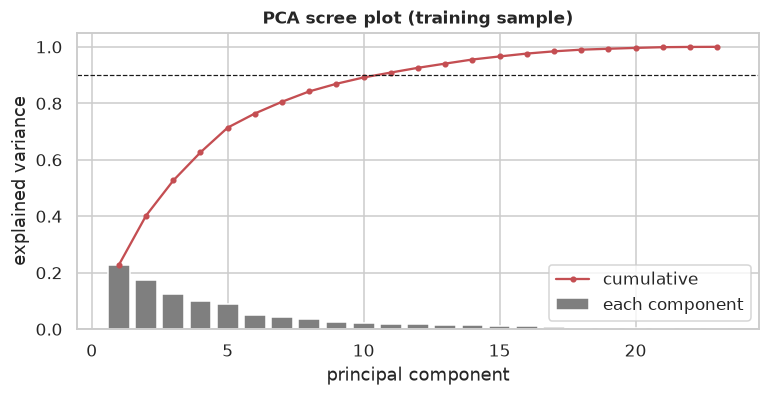

In [46]:
pca = PCA(random_state=SEED).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
components = pca.transform(Xs)
print(f"Components needed for 90% of the variance: {n90} of {Xs.shape[1]} | first component: {pca.explained_variance_ratio_[0]:.1%}")
print("Univariate AUC of the first five components:",
      {f"PC{i + 1}": round(auc(SAMPLE[TARGET], components[:, i]), 2) for i in range(5)})

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color=C_GREY, label="each component")
ax.plot(range(1, len(cum) + 1), cum, "o-", color=C_ABN, ms=3, label="cumulative")
ax.axhline(.9, color="k", ls="--", lw=.8)
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance")
ax.legend()
ax.set_title("PCA scree plot (training sample)")
savefig(fig, "12_6_pca")

About half of the components are needed to reach 90% of the variance, so PCA compresses little. The first component (the one
with the most variance) is mostly about how active the user is and barely separates the classes (AUC ≈ 0.51), while the second
component, about failure rates, separates them well. This was a useful lesson for us: the direction with the most variance is
not necessarily the most useful one for prediction. We decided not to use PCA. The compression is small, the components would
mix post and user information (which would make the group ablation and the privacy discussion impossible), and tree models do
not need it.

Discretisation (equal-width, equal-frequency, domain-based) was only used to explore the data, in the deciles of Section 9.4
and the weather bands of Section 9.3. We do not apply it to the model inputs. Trees discretise on the fly, as the slides
mention, and for linear models binning would throw away the fine ordering that carries the signal (the decile curves are
smooth). The log transformation is a better choice for them.

As for feature selection, the univariate AUC ranking of Section 9.4 is our *filter method*. We do not select features
automatically from it, because filters ignore interactions. In Task 2, the feature-group ablation will decide which groups to
keep.

### 12.7 Final list: every original column accounted for

To make sure we did not forget anything, we list what happened to every original column.

In [47]:
abnormal_count_cols = [w.format("abnormal") for w in windows]
DROP_REASON = {
    "row_id": "technical id (link to the original file)",
    "user_id": "key field: 56k values, most test accounts unseen in train (Section 11)",
    "order_time": "unclear availability (Section 8.2)",
    "start_time": "converted into hour/dow; defines the split",
    "end_time": "after the session (Section 8); used only for the purge and checks",
    "payment_time": "after the session (Section 8)",
    "energy_kwh": "after the session (Section 8)", "electricity_cost": "after the session (Section 8)",
    "service_charge": "after the session (Section 8)", "amount": "after the session (Section 8)", "actual_payment": "after the session (Section 8)",
    "end_cause": "outcome: only used to build the target (Section 5)",
    "electricity_price": "fixed by tariff_period (Section 4.3)",
    "post_no_previous_completed_session": "always 0 in train/val/test (Section 12.2)",
    "post_no_previous_completed_abnormal": "always 0 in train/val/test (Section 12.2)",
    "user_no_previous_completed_session": "same as is_new_user (Section 12.2)",
    **{c: "exact function of sessions and rate (Section 12.2)" for c in abnormal_count_cols},
}
original = [RENAME.get(c, c) for c in raw.columns] + ["row_id"]
disposition = pd.DataFrame(
    [(c, "keep", next(g for g, cols in GROUPS.items() if c in cols), "") if c in MODEL_FEATURES
     else (c, "drop", "", DROP_REASON[c]) for c in original]
    + [(c, "keep (new)", next(g for g, cols in GROUPS.items() if c in cols), "Section 12.1") for c in ["hour", "dow", "rain_flag"]],
    columns=["column", "decision", "group", "reason"])
assert set(MODEL_FEATURES) <= set(disposition["column"])
display(disposition["decision"].value_counts().to_frame("columns"))
display(disposition[disposition["decision"] == "drop"])
print("Features per group:", {g: len(c) for g, c in GROUPS.items()}, "| total:", len(MODEL_FEATURES))

,columns
decision,
keep,26
drop,22
keep (new),3


,column,decision,group,reason
0,user_id,drop,,"key field: 56k values, most test accounts unse..."
4,order_time,drop,,unclear availability (Section 8.2)
5,energy_kwh,drop,,after the session (Section 8)
6,electricity_cost,drop,,after the session (Section 8)
7,service_charge,drop,,after the session (Section 8)
8,amount,drop,,after the session (Section 8)
9,actual_payment,drop,,after the session (Section 8)
10,start_time,drop,,converted into hour/dow; defines the split
11,end_time,drop,,after the session (Section 8); used only for t...
12,payment_time,drop,,after the session (Section 8)


Features per group: {'calendar': 2, 'tariff': 1, 'location': 3, 'weather': 4, 'post_history': 8, 'user_history': 10, 'concurrency': 1} | total: 29


In the end we keep 29 features in 7 groups: calendar (2), tariff (1), location (3), weather (4), post history (8), user history
(10) and concurrency (1). These groups are the units of the feature-group ablation that the project asks for in Task 2.

In [48]:
log_decision("12", "New variables", "Add hour, dow (circular) and rain_flag; no month/year/time index.",
             "Calendar is the only start-time information in the timestamp; rain is zero-inflated.")
log_decision("12", "Removed columns", "Drop electricity_price, 6 abnormal counts, 2 post no-history flags, "
             "user_no_previous_completed_session; user_id not a feature.",
             "Exact functions / no variability / ~identical indicator / key field (Section 12.2).")
log_decision("12", "Redundancy", "Trees and regularised linear models: all 29 features. Plain linear/distance models: "
             "reduced set (|ρ| < 0.90).", "VIF > 10 only for long user windows; max VIF falls below 10 in the reduced set.")
log_decision("12", "PCA / discretisation", "Not adopted.",
             "PCA needs about half the components for 90% variance; top component has AUC ~0.51. Bins lose the ordering.")

---
## 13. Learned operations (fitted on the training period only)

The brief asks that *any preparation operation that learns information from the data* be documented separately. We fit these
operations on `TRAIN` only and then apply them unchanged to validation and test, following the slide *Prevent data leakage*
(always split first and then scale).

The right preparation depends on the model, so we prepare two *views* of the data. The tree view keeps the raw values, the
`NaN` and the categories as codes, and learns nothing else. The linear / distance view applies `log1p` to the skewed columns,
then fills the structural `NaN` with the training maximum and standardises (z-score). Hour and day of week are encoded as sine
and cosine, and `post_id` and `tariff_period` are one-hot encoded with `handle_unknown="ignore"` (the slides note that
*OneHotEncoder respects the train/validation/test workflow*). We leave `location` and `district` out of this view, because
they are exact combinations of the `post_id` columns (nested hierarchy, Section 4.3).

Everything is inside a scikit-learn `Pipeline`, so it can be re-fitted inside each training fold of the later tasks.

In [49]:
class FillWithTrainMax(BaseEstimator, TransformerMixin):
    """Replace a structural NaN ('the event never happened') with the column maximum learned in fit()."""

    def fit(self, X, y=None):
        self.fill_ = np.nanmax(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        rows, cols = np.where(np.isnan(X))
        X[rows, cols] = self.fill_[cols]
        return X


def cyclical(X):
    """Sine/cosine encoding: hour (period 24) and day of week (period 7). Nothing is learned."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([np.sin(2 * np.pi * X[:, 0] / 24), np.cos(2 * np.pi * X[:, 0] / 24),
                            np.sin(2 * np.pi * X[:, 1] / 7), np.cos(2 * np.pi * X[:, 1] / 7)])


other_numeric = [c for c in NUMERIC if c not in SKEW_LOG + BINARY]
linear_view = ColumnTransformer([
    ("log_fill_scale", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("fill", FillWithTrainMax()),
                                 ("scale", StandardScaler())]), SKEW_LOG),
    ("fill_scale", Pipeline([("fill", FillWithTrainMax()), ("scale", StandardScaler())]), other_numeric),
    ("binary", "passthrough", BINARY),
    ("cyclical", FunctionTransformer(cyclical), ["hour", "dow"]),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["post_id", "tariff_period"]),
])

linear_view.fit(TRAIN)                                  # fitted on the training period only
X_train, X_val, X_test = (linear_view.transform(part) for part in (TRAIN, VAL, TEST))
print(f"Linear view: {X_train.shape[1]} columns | NaN left: train {np.isnan(X_train).sum()}, "
      f"validation {np.isnan(X_val).sum()}, test {np.isnan(X_test).sum()}")
print(f"Smallest post in train: {TRAIN['post_id'].value_counts().min()} sessions -> no rare categories to group")

Linear view: 126 columns | NaN left: train 0, validation 0, test 0
Smallest post in train: 244 sessions -> no rare categories to group


In [50]:
# For comparison: what if we had (wrongly) fitted on all periods, including validation and test?
linear_all = clone(linear_view).fit(df[df["split"].isin(["train", "val", "test"])])


def learned(ct, block, step, attribute, column):
    columns = {name: cols for name, _, cols in ct.transformers_}[block]
    return getattr(ct.named_transformers_[block].named_steps[step], attribute)[columns.index(column)]


examples = [
    ("NaN fill (days)", "log_fill_scale", "fill", "fill_", "user_days_since_previous_completed_abnormal", np.expm1),
    ("scaler mean", "fill_scale", "scale", "mean_", "temperature", lambda v: v),
    ("scaler mean", "fill_scale", "scale", "mean_", "post_previous_abnormal_rate_7D", lambda v: v),
    ("scaler mean (after log)", "log_fill_scale", "scale", "mean_", "user_previous_sessions_30D", lambda v: v),
]
display(pd.DataFrame([{"learned value": op, "column": col,
                       "fitted on TRAIN (correct)": back(learned(linear_view, b, s, a, col)),
                       "fitted on all periods (leakage)": back(learned(linear_all, b, s, a, col))}
                      for op, b, s, a, col, back in examples]).round(3))

,learned value,column,fitted on TRAIN (correct),fitted on all periods (leakage)
0,NaN fill (days),user_days_since_previous_completed_abnormal,543.420,702.308
1,scaler mean,temperature,19.552,20.027
2,scaler mean,post_previous_abnormal_rate_7D,0.177,0.181
3,scaler mean (after log),user_previous_sessions_30D,2.278,2.213


The linear view has no `NaN` in any period, and no category needs grouping, since every post has hundreds of training
sessions. To see why fitting only on `TRAIN` matters, we also fitted the same pipeline on all periods, and the learned values
change. For example, the fill value for "days since the user's last failure" would move from 543 to 702 days, and the mean
temperature from 19.55 °C to 20.03 °C. The differences are small, but they are information from the validation and test
periods, which the model should not see.

### 13.1 Ledger of learned operations

In [51]:
LEDGER = pd.DataFrame([
    ("One-hot encoding", "post_id, tariff_period (linear view)", "list of categories", "TRAIN", "unknown category -> all zeros"),
    ("Category codes", "post_id, location, district, tariff_period (tree view)", "list of categories", "TRAIN", "unknown -> missing"),
    ("Structural NaN fill", "4 'time since' columns (linear view)", "training maximum", "TRAIN", "flags kept (Section 6)"),
    ("Standardisation (z-score)", "non-binary numeric columns (linear view)", "mean and standard deviation", "TRAIN", "only for scale-sensitive models"),
    ("Log transform rule", f"{len(SKEW_LOG)} skewed columns", "which columns: training skewness", "TRAIN", "the log itself learns nothing"),
    ("Reduced feature set", f"{len(LINEAR_REDUCED_NUMERIC)} numeric columns", "Spearman ρ and univariate AUC", "TRAIN sample", "plain linear / distance models only"),
    ("Class-imbalance treatment", "training rows", "class weights or resampling", "each TRAIN fold (Task 2)", "never on validation/test"),
    ("Feature-group selection", "7 groups", "group ablation", "TRAIN folds (Task 2)", "not done in Task 1"),
    ("Outlier thresholds / capping", "—", "—", "not used", "log transform instead (Section 10)"),
    ("PCA", "—", "—", "not used", "Section 12.6"),
    ("Rare-category grouping", "—", "—", "not needed", "smallest post has hundreds of training sessions"),
], columns=["learned operation", "applies to", "what is learned", "fitted on", "note"])
display(LEDGER)
log_decision("13", "Learned operations", "Fit encoders, NaN fill and scaler on TRAIN only, inside a Pipeline.",
             "Fitting on all periods changes the learned values (table above).")

,learned operation,applies to,what is learned,fitted on,note
0,One-hot encoding,"post_id, tariff_period (linear view)",list of categories,TRAIN,unknown category -> all zeros
1,Category codes,"post_id, location, district, tariff_period (tr...",list of categories,TRAIN,unknown -> missing
2,Structural NaN fill,4 'time since' columns (linear view),training maximum,TRAIN,flags kept (Section 6)
3,Standardisation (z-score),non-binary numeric columns (linear view),mean and standard deviation,TRAIN,only for scale-sensitive models
4,Log transform rule,8 skewed columns,which columns: training skewness,TRAIN,the log itself learns nothing
5,Reduced feature set,19 numeric columns,Spearman ρ and univariate AUC,TRAIN sample,plain linear / distance models only
6,Class-imbalance treatment,training rows,class weights or resampling,each TRAIN fold (Task 2),never on validation/test
7,Feature-group selection,7 groups,group ablation,TRAIN folds (Task 2),not done in Task 1
8,Outlier thresholds / capping,—,—,not used,log transform instead (Section 10)
9,PCA,—,—,not used,Section 12.6


### 13.2 Class imbalance

There is about 1 abnormal session for every 4.4 normal ones (17.8% in train, 21.1% in validation, 17.6% in test). The slides
warn that with unbalanced classes *the classifier can show a high accuracy with little or no usefulness*.

We decided not to resample the prepared data. If Task 2 uses undersampling, oversampling, SMOTE or class weights, it will do
so only inside the training folds, so validation and test keep their real class distribution and the results measured on them
are realistic. SMOTE in particular needs care here: interpolating between sessions would create impossible combinations (half
a flag, a count between two windows, a mix of two posts) and ignores the time order. For the same reason we will not rely on
accuracy, but use precision, recall, PR-AUC (compared with the base rate) and a confusion matrix, and choose the decision
threshold on validation.

In [52]:
log_decision("13", "Class imbalance", "No resampling of the prepared data; any resampling/weights only inside training folds (Task 2).",
             "Imbalance ~1:4.4 and it changes between periods (17.8% / 21.1% / 17.6%).")

---
## 14. Saved files and integrity checks

The prepared file keeps the raw (untransformed) features, the target, the timestamps needed for the split and the purge, and
the split label. We do not save transformed data, because the transformations must be re-fitted inside each model pipeline
(Section 13). At the end we run a few checks to make sure nothing leaked into the saved file.

In [53]:
BORDERLINE = ["order_lag_min"]          # kept only for a possible sensitivity test in Task 2
POST_HOC = ["energy_kwh", "electricity_cost", "service_charge", "amount", "actual_payment",
            "duration_h", "payment_lag_h", "end_time", "payment_time", "end_cause", "order_time"]
prepared = df[["row_id", "start_time", "end_time", "split"] + MODEL_FEATURES + BORDERLINE + [TARGET]]
prepared.to_csv(OUT_DIR / "task1_prepared.csv.gz", index=False, compression="gzip")
pd.DataFrame(DECISIONS).to_csv(OUT_DIR / "decision_log.csv", index=False)
LEDGER.to_csv(OUT_DIR / "learned_operations_ledger.csv", index=False)
(OUT_DIR / "feature_groups.json").write_text(json.dumps(
    {"groups": GROUPS, "categorical": CATEGORICAL, "binary": BINARY, "log1p": SKEW_LOG,
     "linear_reduced_numeric": LINEAR_REDUCED_NUMERIC, "borderline": BORDERLINE}, indent=2))

checks = {
    "no after-session or outcome column among the features": not set(MODEL_FEATURES) & set(POST_HOC),
    "user_id is not a feature": "user_id" not in MODEL_FEATURES,
    "train < validation < test in time":
        TRAIN["start_time"].max() < VAL["start_time"].min() <= VAL["start_time"].max() < TEST["start_time"].min(),
    "every training label is known before the cut-off (purge)": bool((TRAIN["end_time"] < TRAIN_END).all()),
    "no burn-in session in train": bool((TRAIN["start_time"] >= BURN_IN_END).all()),
    "the scaler saw only training rows": linear_view.named_transformers_["fill_scale"].named_steps["scale"].n_samples_seen_ == len(TRAIN),
    "target has no missing values": bool(prepared[TARGET].notna().all()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "an integrity check failed"
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir() if p.is_file()))
print("Rows per split:", prepared["split"].value_counts().to_dict())

,passed
no after-session or outcome column among the features,True
user_id is not a feature,True
train < validation < test in time,True
every training label is known before the cut-off (purge),True
no burn-in session in train,True
the scaler saw only training rows,True
target has no missing values,True


Saved: ['decision_log.csv', 'feature_groups.json', 'final_comparison.csv', 'final_model.json', 'learned_operations_ledger.csv', 'task1_prepared.csv.gz', 'task2_decision_log.csv', 'task2_protocol.json', 'task3_decision_log.csv', 'task3_fold_metrics.csv', 'task3_results.json', 'task4_decision_log.csv', 'task4_fold_metrics.csv', 'task4_frozen.json', 'task4_results.json', 'task4_search.csv', 'task5_decision_log.csv', 'task5_results.json']
Rows per split: {'train': 271182, 'test': 80081, 'val': 75769, 'burn-in': 14017, 'purged': 28}


---
## 15. Synthesis

#### 1. Most important characteristics and problems
The first problem was that the file has no target column. We built `is_Abnormal` from `end_cause` (the 13 fault causes are
abnormal), and the dataset's own history columns agree with this definition in about 100% of the rows (Section 5.2). With it,
18.58% of the sessions are abnormal, about 1 for every 4.4 normal ones.

The biggest risk we found is leakage. Seven columns (energy, money, end and payment times) and `end_cause` describe the result
of the session, and `Order creation time` is stamped after the start in 56% of all sessions (Section 4.2) and in 57.2% of the training sessions (Section 8.2). The records
themselves are in good shape: no duplicates or impossible records, only structural missing values, and hidden tabs that were
fixed by stripping (Sections 2, 4 and 6).

The data also change over time. Monthly volume goes from 1.4k to 28k sessions, the abnormal share from 13.7% to 26%,
connection faults almost disappear after mid-2020, four posts stop in September 2021, and the history columns are incomplete
in Q1-2020 (Section 7). The main signal is in the posts: failures are concentrated in some of them, and a post that failed
recently tends to fail again. Post history is the strongest signal, user history comes second, and calendar, weather and
tariff add little (Sections 8.1 and 9). Finally, a few fleet accounts have a large share of the sessions, and 61% of the test
sessions come from accounts that never appear in training (Sections 9.5 and 11).

#### 2. Evidence behind the decisions
Every decision in the log below points to the check that supports it. The target is supported by our recount of the history
columns (Section 5.2), and the excluded columns by their univariate AUC of 0.82–0.85, higher than any start-time variable
(Section 8.1). We kept the missing values as "never happened" because they match the no-history flags in 100% of the rows
(Section 6), and the outliers because the extreme cases are real situations (Section 10). The time split follows from the
monthly analysis (Sections 7 and 11), the removed columns from exact functions, no variability or duplicate indicators
(Section 12.2), and fitting on the training period only from the change in the learned values when they are fitted on all
periods (Section 13).

#### 3. Variables kept for modelling
We keep 29 features in 7 groups: calendar (2), tariff (1), location (3), weather (4), post history (8), user history (10) and
concurrency (1). Plain linear or distance models get a reduced set of 19 numeric features (Section 12.5).

#### 4. Open limitations and assumptions
* We treat weather as a forecast. If it was measured during the day, it contains information from after the start.
* Session durations stop at 24 h, and we could not explain the timing of the order and payment fields.
* Our explanations for the changes over time (COVID-19, early connection problems) are hypotheses.
* No post in the test period is new, so we cannot test how the model handles a new post.
* Fleet accounts dominate the user counts.

#### 5. What this means for Task 2
We will use the chronological split with the purge, tune with expanding-window folds inside the training period, and use the
test period only once. Accuracy is not enough here, so we will report precision, recall, PR-AUC (compared with each period's
base rate), ROC-AUC and the confusion matrix, and check the thresholds and calibration, because the base rate changes between
periods. Class imbalance will be handled with the threshold, class weights or resampling, only inside the training folds, and
we need to be careful with SMOTE.

For the models, tree ensembles seem a good fit for this data (skewed columns, `NaN`, correlated windows) and will use the tree
view, while a regularised logistic regression is a simple baseline for the linear view. The feature-group ablation will compare
context only, context + post history, context + user history and everything, with and without `post_id`. We will report new
users separately and discuss the privacy cost of user history.

In [54]:
display(pd.DataFrame(DECISIONS))

,section,topic,decision,evidence
0,4,Text and dates,"Strip spaces/tabs, parse the four timestamps, ...","TAB on 100% of order/payment times and on 18,3..."
1,5,Target,is_Abnormal = 1 when end_cause is one of the 1...,Our counts reproduce the dataset's own previou...
2,5,Label noise,"Keep the 9,058 zero-energy sessions labelled n...",Plausible user cancellations; filtering on ene...
3,6,Missing values,"No deletion, no mean/median or model imputatio...",NaN equals the no-history flag in 100% of rows...
4,7,Burn-in,Do not use sessions before 2020-04-01 for mode...,History columns incomplete at file start (new ...
5,7,Time split,"Chronological split, no random split.","Volume, abnormal share (13.7%-26.3%) and failu..."
6,8,Leakers,"Exclude energy, the four money columns, end_ti...",Only known after the session; univariate AUC 0...
7,8,Order creation time,Exclude from the predictors.,Stamped after the start in 57.2% of training s...
8,10,Outliers,Keep all observations. Trees: no change. Linea...,"Extremes are valid: idle posts (~2x abnormal),..."
9,11,Split,"Train 2020-04-01..2021-06-30 (purged), validat...",Changes over time (Section 7); 28 training ses...


# Part 2 · Task 2: Define the prediction and evaluation setting

In [55]:
# each part starts from an empty namespace, as when the task notebooks ran on their own
%reset -f

## Task 2: Define the prediction and evaluation setting
## Classification of abnormal electric-vehicle charging sessions

Task 2 asks us to define the prediction problem and the way a solution will be judged, before any model is optimised. So this
notebook fits no model. It only builds the evaluation protocol (variables, metrics, temporal folds, aggregation) and checks it
with two simple baselines. We reuse the results of Task 1 (`Task1.ipynb`) and do not repeat them.

---
## 1. Setup

In [56]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
from scipy.stats import wilcoxon

from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_auc_score)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}   # every other end cause is abnormal (Task 1, Section 5)

# Time boundaries. They come from Task 1 (Sections 7 and 11) and are justified again in Section 7 of this notebook.
BURN_IN_END = pd.Timestamp("2020-04-01")    # sessions before this date are not used for modelling
TEST_START = pd.Timestamp("2021-10-01")     # the final test period starts here and stays untouched
FOLD_BOUNDS = [("2020-10-01", "2021-01-01"),    # validation quarters of the four expanding-window folds
               ("2021-01-01", "2021-04-01"),
               ("2021-04-01", "2021-07-01"),
               ("2021-07-01", "2021-10-01")]
ALERT_BUDGETS = (0.05, 0.10, 0.20)          # share of sessions that may be flagged (operational metrics, Section 6)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 140)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 10)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

---
## 2. Data and what we reuse from Task 1

We reuse four results of Task 1: the definition of the target, the burn-in period, the 29 features in 7 groups
(`prepared/feature_groups.json`) and the chronological layout (train until June 2021, validation 2021-Q3, test 2021-Q4).
We do not analyse anything again. We only load the few columns that the protocol needs, plus the header of the full file, so
that all 47 original columns can be classified in Section 4.

To protect the test period, we remove the burn-in and test rows right after loading and only count them. From here on the test
sessions are not in memory, so no step of this notebook can use them by accident.

In [57]:
RENAME = {   # same short names as in Task 1
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Order creation time": "order_time", "Transaction power/kwh": "energy_kwh", "Electricity cost/Yuan": "electricity_cost",
    "Service charge/Yuan": "service_charge", "Transaction Amount/Yuan": "amount", "Actual Payment/Yuan": "actual_payment",
    "Start Time": "start_time", "End Time": "end_time", "Payment time": "payment_time",
    "Temperature(℃)": "temperature", "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
ALL_COLUMNS = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()          # header only
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())   # written by Task 1

USECOLS = ["UserID", "Start Time", "End Time", "end_cause", "post_previous_abnormal_rate_7D", "user_previous_sessions_180D"]
df = pd.read_csv(DATA_PATH, usecols=USECOLS).rename(columns=RENAME)
df["end_cause"] = df["end_cause"].str.strip()
for col in ("start_time", "end_time"):
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d %H:%M:%S")
df[TARGET] = (~df["end_cause"].isin(NORMAL_CAUSES)).astype("int8")

n_total = len(df)
n_burn_in = int((df["start_time"] < BURN_IN_END).sum())
n_test = int((df["start_time"] >= TEST_START).sum())
df = df[(df["start_time"] >= BURN_IN_END) & (df["start_time"] < TEST_START)].reset_index(drop=True)   # the test rows disappear here

print(f"File: {n_total:,} sessions and {len(ALL_COLUMNS)} columns")
print(f"Burn-in (before {BURN_IN_END.date()}): {n_burn_in:,} sessions, not used")
print(f"Test (from {TEST_START.date()}): {n_test:,} sessions, removed from memory")
print(f"Development data ({df['start_time'].min().date()} to {df['start_time'].max().date()}): {len(df):,} sessions, "
      f"abnormal share {df[TARGET].mean():.2%}")
assert df["start_time"].max() < TEST_START

File: 441,077 sessions and 47 columns
Burn-in (before 2020-04-01): 14,017 sessions, not used
Test (from 2021-10-01): 80,081 sessions, removed from memory
Development data (2020-04-01 to 2021-09-30): 346,979 sessions, abnormal share 18.54%


The file has 441,077 sessions. After removing the burn-in (14,017) and the test period (80,081) we keep 346,979 development
sessions, with an abnormal share of about 18.5%. These are the only rows that the folds in Section 7 can use.

---
## 3. The prediction problem

### 3.1 Formal definition

| Element | Definition |
|---------|------------|
| Unit of observation | One charging session: one row, i.e. one transaction of one account at one charging post, identified by its `Start Time`. |
| Positive class | `is_Abnormal = 1`: the session ends because of a fault or failure (13 of the 15 `end_cause` values: faults of the charging pile, DC output, connection, vehicle communication, BMS, and so on). |
| Negative class | `is_Abnormal = 0`: the session ends as intended, with `Charging ends normally` or `User stops charging`. |
| Target | Derived from `end_cause` (table below). The file has no `is_Abnormal` column. |
| Prediction moment | The start of the session (`Start Time`). The score is computed once, with only information known at that instant. Nothing that happens during or after the session may be used. |
| Purpose | Preventive monitoring and maintenance prioritisation: rank the starting sessions (and, through them, the posts) by risk of failure, so that the operator looks first at the riskiest ones. |
| Meaning of "predicted abnormal" | A risk alert raised when the session starts: *this session, on this post, is at increased risk of ending in a failure.* It is not a diagnosis and does not say which fault will occur. |

### 3.2 How the target is derived from `end_cause`

The table below lists every end cause in the development data, with its number of sessions and the class we give it.

In [58]:
mapping = (df.groupby("end_cause").agg(sessions=("end_cause", "size"))
             .assign(share=lambda t: t["sessions"] / len(df),
                     is_Abnormal=lambda t: [0 if c in NORMAL_CAUSES else 1 for c in t.index])
             .sort_values("sessions", ascending=False))
display(mapping.style.format({"sessions": "{:,.0f}", "share": "{:.2%}"}))
print(f"Positive class: {df[TARGET].sum():,} sessions ({df[TARGET].mean():.2%}) | negative class: {(df[TARGET] == 0).sum():,} sessions "
      f"| imbalance about 1 : {(1 - df[TARGET].mean()) / df[TARGET].mean():.1f}")

,sessions,share,is_Abnormal
end_cause,,,
Charging ends normally,"159,504",45.97%,0
User stops charging,"123,139",35.49%,0
Other faults of the charging pile,"16,168",4.66%,1
DC Output Fault,"12,182",3.51%,1
Vehicle communications failure,"11,044",3.18%,1
BMS failure,"6,214",1.79%,1
Faulty charging connection,"6,016",1.73%,1
Failure of non-system control loop components and assemblies,"5,943",1.71%,1
Vehicle charging faults,"4,588",1.32%,1


Positive class: 64,336 sessions (18.54%) | negative class: 282,643 sessions | imbalance about 1 : 4.4


The positive class is a mix of 13 different failure causes, so the model predicts "any failure" and not the type. Task 1
(Section 7.2) showed that this mix changes over time, which means a model could learn one type of failure well and miss another.

The two normal causes cover 81% of the sessions. We count `User stops charging` as a normal ending because it is the user's
choice and not an equipment failure. We decided this in Task 1 and checked it there (Section 5.2) against the dataset's own
"previous abnormal" columns: our definition reproduces them in about 100% of the rows, and the alternative does not. The choice
matters a lot. If user stops (35.5% of the sessions) were abnormal, the abnormal share would rise from 18.5% to about 54%, and
the whole problem would change.

### 3.3 Purpose and operational meaning of an alert

What follows an alert decides which error hurts more (Section 5). We consider three possible actions, from the lightest to the
heaviest:

| Action after the alert | Who acts | Cost of acting |
|------------------------|----------|----------------|
| Automated monitoring: mark the session and its post on a dashboard, watch the next sessions | operator, automatic | very low |
| Inspection / maintenance prioritisation: remote diagnosis or a technician visit for the riskiest posts | maintenance team | medium, and limited by the number of technicians |
| User intervention: warn the driver or suggest another post before charging | platform, driver | low for the platform, but a false warning annoys the driver |

The main use we design for is the first two actions: a ranked list of risky sessions that an operator with limited capacity can
work through from the top. The third action is possible, but it needs a much higher confidence, so we leave it out of the main
scope.

In [59]:
log_decision("3", "Problem definition",
             "Unit = charging session; positive = abnormal ending (13 fault causes); prediction at Start Time; use = ranked risk alerts "
             "for preventive monitoring and maintenance prioritisation.",
             "Brief, Section 2; our target mapping reproduces the dataset's own history columns in about 100% of the rows (Task 1, Section 5.2).")

---
## 4. Which variables can be used?

The brief asks us to put every supplied variable into one of four categories and to justify each exclusion:

1. eligible predictors: genuinely known when the session starts;
2. used only to build the target;
3. excluded because they are generated during or after the session;
4. excluded for another methodological reason.

We build the table in code, and an assertion checks that each of the 47 original columns appears exactly once. The eligible set
is read from the Task 1 file `prepared/feature_groups.json`, so the two tasks cannot drift apart.

In [60]:
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}      # features built from one column (Task 1, Section 12)

features = [f for group in FEATURE_GROUPS["groups"].values() for f in group]
eligible_raw = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in features}
assert eligible_raw <= set(ALL_COLUMNS), eligible_raw - set(ALL_COLUMNS)

TARGET_ONLY = {"end_cause": ("Reason why the session ended. It is the outcome, so it can only define the label.",
                             "Task 1, Section 5: 15 values; 13 are faults and form the positive class.")}
POST_SESSION = {
    "Transaction power/kwh": "Energy delivered during the session.",
    "Electricity cost/Yuan": "Cost of the energy delivered during the session.",
    "Service charge/Yuan": "Fee computed on the finished transaction.",
    "Transaction Amount/Yuan": "Sum of electricity cost and service charge, known only at the end.",
    "Actual Payment/Yuan": "Amount paid after the session.",
    "End Time": "Moment the session ended. It is only used to know when a label becomes available (the purge in Section 7), never as a predictor.",
    "Payment time": "Recorded after the session (before the end in 20% of the rows, so it is not even a clean timestamp).",
}
POST_SESSION_EVIDENCE = "Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
OTHER = {
    "UserID": ("Key field: 56,115 different accounts, most with one or two sessions, and a large share of the validation sessions comes from "
               "accounts not seen in training. A model would memorise accounts, and it would identify people. The user's history is the "
               "legitimate substitute.", "Task 1, Sections 9.5 and 11; the share of unseen accounts per fold is in Section 7.2."),
    "Order creation time": ("Its availability at the prediction moment is not guaranteed: the order is stamped after the start in 57.2% of "
                            "the training sessions, by up to hours. Its lag to the start also reflects how the start went.", "Task 1, Section 8.2."),
    "electricity_price": ("Deterministic function of `tariff_period` (3 price levels for 7 periods), so it adds nothing.", "Task 1, Sections 4.3 and 12.2."),
    "post_previous_abnormal_1D": "Exact function of the session count and the smoothed rate: abnormal = rate × (sessions + 5) − 1.",
    "post_previous_abnormal_7D": "Exact function of the session count and the smoothed rate.",
    "post_previous_abnormal_30D": "Exact function of the session count and the smoothed rate.",
    "user_previous_abnormal_30D": "Exact function of the session count and the smoothed rate.",
    "user_previous_abnormal_180D": "Exact function of the session count and the smoothed rate.",
    "user_previous_abnormal_730D": "Exact function of the session count and the smoothed rate.",
    "post_no_previous_completed_session": "Constant after the burn-in: it is 1 only for the first session of each post, in January 2020.",
    "post_no_previous_completed_abnormal": "Constant after the burn-in (same reason).",
    "user_no_previous_completed_session": "Almost the same indicator as `is_new_user` (φ = 0.995, 0.1% of the rows differ).",
}
OTHER_EVIDENCE_DEFAULT = "Task 1, Section 12.2."

rows = []
for col in ALL_COLUMNS:
    if col in eligible_raw:
        group = next(g for g, cols in FEATURE_GROUPS["groups"].items()
                     if any(DERIVED.get(f, INVERSE_RENAME.get(f, f)) == col for f in cols))
        derived = [f for f, src in DERIVED.items() if src == col]
        reason = f"Known at the start ({group})" + (f"; enters as {', '.join(derived)}" if derived else "")
        rows.append((col, "1 eligible predictor", reason, "Task 1, Section 8.3"))
    elif col in TARGET_ONLY:
        rows.append((col, "2 target construction only", *TARGET_ONLY[col]))
    elif col in POST_SESSION:
        rows.append((col, "3 generated during/after the session", POST_SESSION[col], POST_SESSION_EVIDENCE))
    elif col in OTHER:
        reason, evidence = OTHER[col] if isinstance(OTHER[col], tuple) else (OTHER[col], OTHER_EVIDENCE_DEFAULT)
        rows.append((col, "4 excluded for another reason", reason, evidence))
    else:
        raise KeyError(f"column not classified: {col}")
classification = pd.DataFrame(rows, columns=["column", "category", "reason", "evidence"])
assert classification["column"].is_unique and len(classification) == len(ALL_COLUMNS) == 47

display(classification.groupby("category").size().rename("columns").to_frame())
display(classification[classification["category"] != "1 eligible predictor"].style.hide(axis="index")
        .set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,columns
category,
1 eligible predictor,27
2 target construction only,1
3 generated during/after the session,7
4 excluded for another reason,12


column,category,reason,evidence
UserID,4 excluded for another reason,"Key field: 56,115 different accounts, most with one or two sessions, and a large share of the validation sessions comes from accounts not seen in training. A model would memorise accounts, and it would identify people. The user's history is the legitimate substitute.","Task 1, Sections 9.5 and 11; the share of unseen accounts per fold is in Section 7.2."
Order creation time,4 excluded for another reason,"Its availability at the prediction moment is not guaranteed: the order is stamped after the start in 57.2% of the training sessions, by up to hours. Its lag to the start also reflects how the start went.","Task 1, Section 8.2."
Transaction power/kwh,3 generated during/after the session,Energy delivered during the session.,"Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
Electricity cost/Yuan,3 generated during/after the session,Cost of the energy delivered during the session.,"Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
Service charge/Yuan,3 generated during/after the session,Fee computed on the finished transaction.,"Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
Transaction Amount/Yuan,3 generated during/after the session,"Sum of electricity cost and service charge, known only at the end.","Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
Actual Payment/Yuan,3 generated during/after the session,Amount paid after the session.,"Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
End Time,3 generated during/after the session,"Moment the session ended. It is only used to know when a label becomes available (the purge in Section 7), never as a predictor.","Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
Payment time,3 generated during/after the session,"Recorded after the session (before the end in 20% of the rows, so it is not even a clean timestamp).","Task 1, Section 8.1: a single one of these columns reaches a univariate ROC-AUC of 0.82–0.85, above every start-time variable (best 0.77)."
end_cause,2 target construction only,"Reason why the session ended. It is the outcome, so it can only define the label.","Task 1, Section 5: 15 values; 13 are faults and form the positive class."


27 of the 47 columns are eligible. They produce the 29 features in 7 groups of Task 1, because `Start Time` gives `hour` and
`dow`, and `Precipitation` also gives `rain_flag`. The eligible columns are listed by group below.

7 columns describe the session itself (energy, money, end and payment times) and 1 (`end_cause`) is the outcome. We exclude them
because they only exist after the session, so a model using them could not run when the session starts.

The other 12 columns are excluded for different reasons: one identifier (`UserID`), one column whose timing is uncertain
(`Order creation time`), and ten columns that are redundant. The redundant ones carry no information that another column does not
already have, so removing them loses nothing.

In [61]:
groups = pd.DataFrame([(g, len(cols), ", ".join(cols)) for g, cols in FEATURE_GROUPS["groups"].items()],
                      columns=["group", "features", "list"])
display(groups.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("Total:", groups["features"].sum(), "features")
assert groups["features"].sum() == 29

group,features,list
calendar,2,"hour, dow"
tariff,1,tariff_period
location,3,"post_id, location, district"
weather,4,"temperature, humidity, precipitation, rain_flag"
post_history,8,"post_previous_sessions_1D, post_previous_sessions_7D, post_previous_sessions_30D, post_previous_abnormal_rate_1D, post_previous_abnormal_rate_7D, post_previous_abnormal_rate_30D, post_hours_since_previous_completed_session, post_hours_since_previous_completed_abnormal"
user_history,10,"is_new_user, user_previous_sessions_30D, user_previous_sessions_180D, user_previous_sessions_730D, user_previous_abnormal_rate_30D, user_previous_abnormal_rate_180D, user_previous_abnormal_rate_730D, user_days_since_previous_completed_session, user_days_since_previous_completed_abnormal, user_no_previous_completed_abnormal"
concurrency,1,user_active_sessions_at_start


Total: 29 features


The eligible set is only valid under some assumptions. The data cannot prove them, so we state them here.

* Weather is treated as a forecast available at the start, as the brief says. In the data it is one daily value per district
  (Task 1, Section 4.3). If it were an observed daily total, it would contain information from after the start.
* The history attributes are taken as supplied. They use only sessions that had finished before the start (Task 1, Section 5.2,
  recomputed them from the timestamps). In production the history keeps updating, so in the validation and test periods the
  history of a session already contains the outcomes of earlier sessions of the same period that had finished. This is realistic,
  and we state it on purpose.
* User history needs the platform to identify the account at the start. If it cannot (a guest user), the user group is not
  available. This is the cold-start case, and it also raises a privacy question, because the user history is a behaviour profile.
* `post_id` is an identifier, but the post is known at the start and it is the most informative location level (Task 1,
  Section 9.1), so it stays eligible. Whether it adds value is a question for the ablation of Task 3.

In [62]:
log_decision("4", "Predictor set",
             "27 original columns are eligible (29 features in 7 groups). Excluded: 1 target-only column, 7 generated during or after the "
             "session, 12 for other reasons (identifier, uncertain timing, redundancy).",
             "Every one of the 47 columns appears once in the classification table; reasons and evidence per column in Section 4.")

---
## 5. The cost of the two errors

A false positive (FP) flags a normal session as risky. A false negative (FN) lets an abnormal session pass unnoticed. Their
consequences depend on what follows the alert (Section 3.3).

| | False positive (false alert) | False negative (missed failure) |
|---|------------------------------|----------------------------------|
| Automated monitoring | negligible: one more line on a dashboard | the failure is not marked, and the next sessions on that post are not watched |
| Inspection / maintenance | a wasted inspection. Technicians are limited, so every false alert takes time from a real problem | the faulty post stays in service. Failures cluster: Task 1 (Section 9.4) showed that the abnormal share goes from about 4% to about 60% between the lowest and highest recent-failure decile of a post, so one missed failure is followed by more |
| User intervention | an unnecessary warning or detour for a driver, which makes drivers stop trusting alerts | a driver spends time on a charge that fails (and may pay a service fee) |

Which error matters more? For one single event, we think a false negative costs more than a false positive in the main use
(monitoring and maintenance), because the action after an alert is cheap compared with a failure that continues unseen. But the
number of false alerts is limited by capacity: a long list of alerts becomes useless, a point known as alert fatigue, so neither
error can be ignored. The application needs a good ranking (the real failures near the top) and a fixed number of alerts
that the operator can handle.

We do not know the exact cost ratio, so we write it as `c = cost(FN) / cost(FP)`. If the predicted probabilities are well
calibrated, the best cut-off is `t* = 1 / (1 + c)`: the higher c is, the lower the cut-off and the more sessions are flagged.

In [63]:
p = df[TARGET].mean()
cost_table = pd.DataFrame({"c = cost(FN) / cost(FP)": [1, 2, 3, 5, 10]})
cost_table["best probability cut-off t*"] = 1 / (1 + cost_table["c = cost(FN) / cost(FP)"])
cost_table["t* below the abnormal share?"] = np.where(cost_table["best probability cut-off t*"] < p, "yes", "no")
display(cost_table.style.hide(axis="index").format({"best probability cut-off t*": "{:.3f}"}))
c_break_even = (1 - p) / p
print(f"Abnormal share = {p:.3f}. A model with no skill (constant probability) should flag every session as soon as c > (1 - p) / p = {c_break_even:.1f}.")

c = cost(FN) / cost(FP),best probability cut-off t*,t* below the abnormal share?
1,0.500,no
2,0.333,no
3,0.250,no
5,0.167,yes
10,0.091,yes


Abnormal share = 0.185. A model with no skill (constant probability) should flag every session as soon as c > (1 - p) / p = 4.4.


With equal costs (c = 1), only sessions with a risk of 50% or more are flagged. With c = 2 the cut-off falls to 0.33, and with
c = 5 it is already below the abnormal share (0.185). When failures are much more expensive than false alerts, almost anything is
worth flagging and the alert list stops being selective. Beyond c ≈ 4.4, even a model without skill would flag every session.

Since c is unknown, fixing a single probability cut-off now would be arbitrary. We choose two things instead: metrics that judge
the ranking and the quality of the probabilities (Section 6), and a procedure to choose the cut-off later (Section 7.4), based on
the cost ratio and on the alert capacity.

The abnormal share also changes between periods (15.8%–21.1% across the folds of Section 7), so the same probability cut-off
flags a different number of sessions in each period. For that reason we compute the operational metrics for a fixed alert budget,
that is, a fixed share of flagged sessions.

In [64]:
log_decision("5", "Error consequences",
             "A missed failure costs more per event than a false alert, but false alerts are capped by inspection capacity: evaluate the "
             "ranking and the result at a fixed alert budget. The cut-off is chosen later from the cost ratio and the capacity.",
             "Failures cluster by post (Task 1, Section 9.4); best cut-off t* = 1/(1 + c) falls below the abnormal share for c > 4.4.")

---
## 6. Evaluation metrics

We choose the metrics now, before any model is optimised. The reasoning follows the slides: *the performance of a model depends on
the class distribution and on the cost of misclassifications*, and accuracy is not suitable for imbalanced classes or for classes
with different costs.

| Metric | Role | What it measures | Why it fits this problem | Limitation here |
|--------|------|------------------|--------------------------|-----------------|
| PR-AUC (average precision) | **primary** | Area under the precision–recall curve: how precise the alerts are as we ask them to catch more failures | The positive class is the minority (about 18.5%) and both error types matter. It ignores true negatives, which are not what the operator cares about (slides: PR curve for rare positives and different costs) | Its no-skill value equals the abnormal share, and that share changes between periods. So it is always shown next to the baseline and as a lift (PR-AUC divided by the abnormal share), and models are compared fold by fold |
| ROC-AUC | complementary | Chance that a random abnormal session gets a higher score than a random normal one | Does not depend on the abnormal share, so it is comparable across periods and with the univariate AUCs of Task 1 | Can look optimistic with imbalanced classes, and says nothing about the top of the ranking (slides) |
| Brier score and log-loss | complementary | Quality of the predicted probabilities (calibration and sharpness) | The cut-off `t* = 1/(1+c)` of Section 5 is only valid if probabilities are calibrated. The extended Task 1 notebook (Section 14) also showed that class weights distort probabilities | Only for models that output probabilities. Both depend on the abnormal share |
| Precision and recall at an alert budget q | operational | Of the `q` share of sessions flagged (top of the ranking): how many are real failures (precision), and what share of all failures is caught (recall) | The alert budget is the practical limit (capacity) and it is the same for every model and every period | The budgets (5%, 10%, 20%) are assumptions, because the real capacity is unknown |
| Correct alerts, false alerts and missed abnormal sessions per 1,000 sessions | operational | TP, FP and FN at the alert budget, scaled to 1,000 sessions (as the brief suggests) | Converts the errors into workload: false alerts per 1,000 sessions is wasted inspections | Depends on the budget and on the abnormal share of the period |

A model should not be judged by its average only, so we also need measures of stability. We will look at the metric in every fold,
its standard deviation across folds, the worst fold, the trend over time and the number of folds in which a model beats the
baseline (details in Section 8).

Some common metrics are left out of the model comparison. Accuracy suffers from the "accuracy paradox": always answering "normal"
is right about 81% of the time and catches no failure at all (we show this in Section 9). F1, balanced accuracy, Cohen's kappa
and MCC need a cut-off, which is not chosen yet, and F1 gives equal weight to both errors, which we argued is not our case. They
can be reported once, at the final cut-off, in Task 4.

In [65]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out

In [66]:
log_decision("6", "Metrics",
             "Primary: PR-AUC. Complementary: ROC-AUC, Brier score, log-loss. Operational: precision, recall and correct / false / missed alerts per "
             "1,000 sessions at alert budgets of 5%, 10% and 20%. Stability: per-fold values, std, worst fold, trend, wins against the baseline. "
             "Accuracy, F1, kappa and MCC are not used for model comparison.",
             "Abnormal share ~18.5% with unequal error costs; the share moves between periods, so lift and fixed budgets are needed (Sections 5 and 7).")

---
## 7. Temporal evaluation design

### 7.1 Why not a random split, and which periods we use

The random holdout, repeated holdout and K-fold cross-validation of the slides assume that any session could be swapped with any
other. Here that is false. Task 1 (Section 7) showed that volume, abnormal share, fault mix and the history attributes change over
time, and a model will always be used on future sessions. With a random split the validation set would contain sessions from the
same weeks as the training set, and the estimate would be too optimistic. So we apply the golden rule of the slides, *data used
for evaluation cannot be used during development*, in time: training observations always come before the observations that
evaluate them.

| Period | Dates (`Start Time`) | Use |
|--------|----------------------|-----|
| Burn-in | before 2020-04-01 | not used (history attributes still filling up, different failure mix; Task 1, Section 7) |
| Development | 2020-04-01 to 2021-09-30 | four expanding-window folds for model comparison, hyperparameter selection and cut-off selection |
| Test | from 2021-10-01 | untouched until every modelling decision is final |

### 7.2 The four folds

The next cell builds the folds and checks the temporal rules with assertions, so the notebook stops if one of them is broken.

In [67]:
def temporal_folds(frame, bounds=FOLD_BOUNDS):
    """Expanding-window folds. For each validation quarter [lo, hi):
       train = development sessions that STARTED and ENDED before `lo`. The label of a session is only known when it ends,
               so sessions still running at `lo` are purged from the training set;
       valid = development sessions that started inside [lo, hi)."""
    folds = []
    for k, (lo, hi) in enumerate(bounds, start=1):
        lo, hi = pd.Timestamp(lo), pd.Timestamp(hi)
        started_before = frame["start_time"] < lo
        folds.append({"fold": k, "lo": lo, "hi": hi,
                      "train": frame.index[started_before & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)],
                      "purged": int((started_before & (frame["end_time"] >= lo)).sum())})
    return folds


FOLDS = temporal_folds(df)

# --- integrity checks of the temporal rules ---------------------------------------------------------------------------
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]        # training labels known before validation starts
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0                                  # no session in both parts
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"]                                                                # consecutive, non-overlapping validation quarters
    assert np.isin(a["train"], b["train"]).all()                                             # expanding window: each training set contains the previous one
assert FOLDS[-1]["hi"] == TEST_START and df["start_time"].max() < TEST_START                # nothing from the test period is used
print("All temporal integrity checks passed.")

rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    rows.append({
        "fold": f["fold"],
        "training window": f"{BURN_IN_END.date()} to {(f['lo'] - pd.Timedelta(days=1)).date()}",
        "validation window": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
        "training months": round((f["lo"] - BURN_IN_END).days / 30.4, 1),
        "train sessions": len(tr), "purged": f["purged"],
        "validation sessions": len(va), "validation abnormal": int(va[TARGET].sum()),
        "train abnormal share": tr[TARGET].mean(), "validation abnormal share": va[TARGET].mean(),
        "% validation sessions from accounts unseen in train": (~va["user_id"].isin(set(tr["user_id"]))).mean() * 100,
    })
fold_table = pd.DataFrame(rows).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal": "{:,.0f}",
                                 "train abnormal share": "{:.1%}", "validation abnormal share": "{:.1%}",
                                 "% validation sessions from accounts unseen in train": "{:.1f}"}))

All temporal integrity checks passed.


,training window,validation window,training months,train sessions,purged,validation sessions,validation abnormal,train abnormal share,validation abnormal share,% validation sessions from accounts unseen in train
fold,,,,,,,,,,
1,2020-04-01 to 2020-09-30,2020-10-01 to 2020-12-31,6.000000,"111,470",37,"60,364","10,167",18.9%,16.8%,35.3
2,2020-04-01 to 2020-12-31,2021-01-01 to 2021-03-31,9.000000,"171,832",39,"41,797","6,611",18.2%,15.8%,36.3
3,2020-04-01 to 2021-03-31,2021-04-01 to 2021-06-30,12.000000,"213,641",27,"57,542","10,487",17.7%,18.2%,46.0
4,2020-04-01 to 2021-06-30,2021-07-01 to 2021-09-30,15.000000,"271,182",28,"75,769","16,016",17.8%,21.1%,39.9


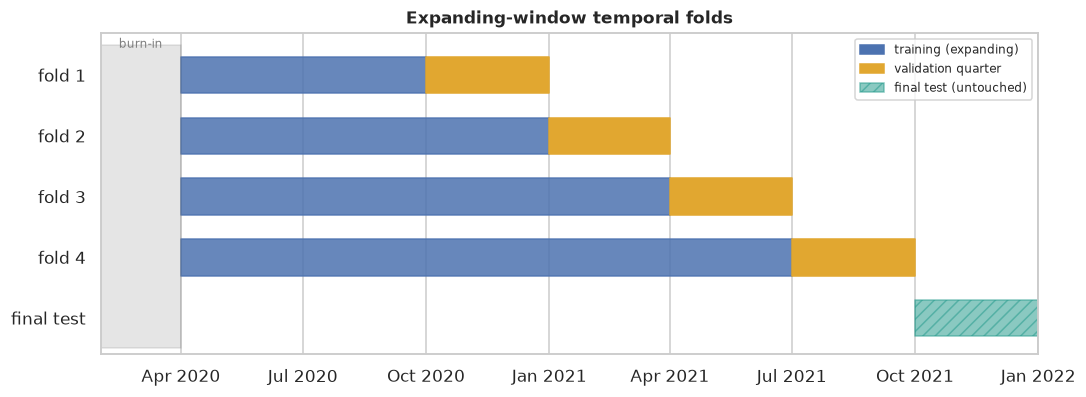

In [68]:
fig, ax = plt.subplots(figsize=(11, 3.8))
d2n = mdates.date2num
start_all, end_all = d2n(BURN_IN_END - pd.Timedelta(days=60)), d2n(pd.Timestamp("2022-01-01"))
n_folds = len(FOLDS)
for i, f in enumerate(FOLDS):
    y0 = n_folds - i                                                   # fold 1 on top ... fold 4 above the test row
    ax.broken_barh([(d2n(BURN_IN_END), d2n(f["lo"]) - d2n(BURN_IN_END))], (y0 - 0.3, 0.6), color=C_NORMAL, alpha=.85)
    ax.broken_barh([(d2n(f["lo"]), d2n(f["hi"]) - d2n(f["lo"]))], (y0 - 0.3, 0.6), color=C_ORANGE)
ax.broken_barh([(d2n(TEST_START), end_all - d2n(TEST_START))], (-0.3, 0.6), color=C_GREEN, hatch="///", alpha=.55)    # test row
ax.broken_barh([(start_all, d2n(BURN_IN_END) - start_all)], (-0.5, n_folds + 1.0), color=C_GREY, alpha=.2)
ax.set_yticks(list(range(n_folds, 0, -1)) + [0])
ax.set_yticklabels([f"fold {f['fold']}" for f in FOLDS] + ["final test"])
ax.set_ylim(-0.6, n_folds + 0.7)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.set_xlim(start_all, end_all)
ax.text(d2n(BURN_IN_END) - 30, n_folds + 0.45, "burn-in", ha="center", fontsize=8, color=C_GREY)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_NORMAL), plt.Rectangle((0, 0), 1, 1, color=C_ORANGE),
                   plt.Rectangle((0, 0), 1, 1, color=C_GREEN, alpha=.55, hatch="///")],
          labels=["training (expanding)", "validation quarter", "final test (untouched)"], loc="upper right", fontsize=8)
ax.set_title("Expanding-window temporal folds")
ax.grid(axis="y", visible=False)
savefig(fig, "07_2_temporal_folds")

We get four quarterly folds. Each one trains on every labelled session before its validation quarter and validates on the next
three months. Task 1 planned three expanding-window folds inside the training period plus a separate validation quarter
(2021-Q3). Here the validation quarter is simply the fourth fold of the same scheme. This gives four estimates instead of three,
puts the most recent quarter (the closest to the test) into model selection, and keeps the test untouched.

The purge removes very little. Only 27–39 training sessions per fold would still be running at the boundary, and we remove them
because their label would not exist yet.

The folds do not have the same size. Validation folds have 41,797 to 75,769 sessions (traffic grows, and February–March 2021 is
quiet), and the training window grows from 111k to 271k sessions, i.e. from 6 to 15 months. Early folds therefore train on less
data and do not include a full winter. We expect their scores to be a little pessimistic, and fold 1 validates in a season that
the model has not seen.

The abnormal share also changes by fold (15.8% to 21.1% in validation). This is the reason for the lift and for the paired
comparisons of Section 8.

Finally, 35%–46% of the validation sessions in each fold come from accounts that are not in the training window. A model that
depended on account identity would have no information about a large part of the sessions, which confirms that excluding `UserID`
(Section 4) was the right choice.

We chose the boundaries and the number of folds for these reasons:

* We use quarters because one quarter is about one season. It is large enough for a stable estimate (every validation fold has
  6,600 or more abnormal sessions) and short enough to see change over time. The boundaries are calendar quarters, fixed before
  looking at any model result.
* We use four folds because an earlier fold would train on fewer than six months of data, which is not a useful model. Monthly
  folds would give 12 noisy estimates of 15–25k sessions each and make the early folds even smaller. Four folds are the
  compromise. They are enough to see whether the performance is stable, but not enough for a precise estimate of its variability
  (Section 8).
* The window is expanding, and not a rolling window of fixed size, because the model that will be deployed is trained on all the
  past, so the folds copy that.

In [69]:
log_decision("7", "Temporal strategy",
             "Burn-in before 2020-04-01; development 2020-04-01 to 2021-09-30 with four expanding-window folds (validation = consecutive quarters "
             "2020-Q4 to 2021-Q3); test from 2021-10-01 untouched. No random splitting.",
             "Prevalence, volume and fault mix change over time (Task 1, Section 7); fold sizes 41.8k–75.8k validation, 111k–271k training; every fold has ≥ 6,600 abnormal sessions.")
log_decision("7", "Purge", "Training sessions that end after the validation start are removed from that fold's training set.",
             "A label exists only when the session ends (up to 24 h later); 27–39 sessions per fold.")

### 7.3 How preprocessing is fitted inside each training fold

Task 1 listed the operations that learn from data (imputation values, scaling, caps, category vocabularies, encoders, feature
selection, resampling). The rule for every model compared in Tasks 3 and 4 is:

1. For each fold, a new pipeline (preprocessing and model together) is created and fitted on that fold's training rows only.
2. The fitted pipeline is applied unchanged to that fold's validation rows. Nothing is re-fitted on them.
3. Class weights or resampling, if used, touch the training rows only. The validation rows keep their natural class distribution,
   so the metrics describe the future situation (slides: evaluate on the initial distribution).
4. A configuration of hyperparameters is judged by its average over the four folds (Section 8). If an inner search is needed, it
   uses only an earlier part of the fold's training window, never the validation quarter.
5. Categories never seen in the training rows are handled by the encoder and not by looking at the validation rows. The seed is
   fixed (`SEED = 42`).

The table below shows that the values a preprocessing step would learn are different in each fold, and different
again if they are computed on all development data, which contains the future of the early folds.

In [70]:
demo = []
for f in FOLDS:
    tr = df.loc[f["train"]]
    demo.append({"fold": f["fold"], "prior (abnormal share)": tr[TARGET].mean(),
                 "median user_previous_sessions_180D": tr["user_previous_sessions_180D"].median(),
                 "99.9th percentile user_previous_sessions_180D": tr["user_previous_sessions_180D"].quantile(0.999)})
demo.append({"fold": "all development data", "prior (abnormal share)": df[TARGET].mean(),
             "median user_previous_sessions_180D": df["user_previous_sessions_180D"].median(),
             "99.9th percentile user_previous_sessions_180D": df["user_previous_sessions_180D"].quantile(0.999)})
display(pd.DataFrame(demo).set_index("fold").style.format({"prior (abnormal share)": "{:.4f}", "median user_previous_sessions_180D": "{:.1f}",
                                                              "99.9th percentile user_previous_sessions_180D": "{:,.0f}"}))

,prior (abnormal share),median user_previous_sessions_180D,99.9th percentile user_previous_sessions_180D
fold,,,
1,0.1888,22.0,"6,461"
2,0.1817,24.0,"6,422"
3,0.1771,24.0,"6,398"
4,0.1782,21.0,"6,376"
all development data,0.1854,20.0,"6,330"


The values change from fold to fold (class prior 17.7%–18.9%, 99.9th percentile of the 180-day user count 6,376–6,461), and the
"all data" values (18.5% and 6,330) match none of them. For these particular statistics the differences are small, because the
distributions are fairly stable after the burn-in. But the rule is not about the size of this effect. Fitting once on all
development data would let the early folds see later sessions, and the effect would be much larger for steps that use the target
(resampling, target encoding, feature selection). Fitting inside each fold avoids the problem for every step, at the price of one
fit per fold.

### 7.4 How the decision threshold will be selected

Models will produce a score or probability for the validation rows of each fold (out-of-fold predictions). We choose the
operating point on the four out-of-fold prediction sets together, never on the test:

* by the alert budget `q` that the operators can handle, or by the cut-off `t* = 1/(1 + c)` of Section 5 once the probabilities
  are shown to be calibrated;
* the chosen rule must give similar precision and recall in each fold, not only in the pooled data;
* the chosen value is then frozen. Because the abnormal share drifts, the share of sessions flagged by a probability cut-off must
  be monitored, whereas an alert budget keeps the workload constant by construction.

### 7.5 How the final test is protected

* The test rows were removed from memory in Section 2 and only counted, so nothing in this notebook can use them.
* Model, hyperparameters and cut-off are chosen only with the four folds. Then the final model is refitted on all development
  sessions (purging those that end after 2021-10-01) and scored once on the test with the metrics of Section 6, next to the
  baselines of Section 9.
* No change is made after seeing the test result. If something has to be changed anyway, it is reported as a post-hoc decision.
* For transparency: Task 1 described the test quarter descriptively (volume, abnormal share, share of unseen accounts) because the
  brief asks to study changes over time. No model has been fitted or scored on it, and no decision in this notebook uses those
  figures.
* The four folds are used for selection, so their scores are slightly optimistic. This is exactly why a separate test exists.

---
## 8. Aggregation across temporal folds

A model should not be judged only by its average if its performance is unstable over time. So we had to decide how the four fold
results are put together.

To rank the models we use the unweighted mean of the fold metrics. The aim is to generalise to a future period, so each period
counts once. A mean weighted by size would let the largest and latest fold dominate.

Fold sizes still matter, so we also report the mean weighted by the number of validation sessions. It reflects the operational
volume. If it disagrees with the unweighted mean, fold 4 (the largest) is driving the result.

We also report a pooled value, computed on all out-of-fold predictions together, and we use the pooled predictions to choose the
cut-off. The pooled value is needed for the threshold and for calibration plots, but it is dominated by the large folds and mixes
different abnormal shares, so it does not rank models.

For stability we report the standard deviation across folds, the worst fold and the trend (slope per fold). With four folds the
standard deviation is a rough guide only. A worst fold far below the mean, or a falling trend, is a warning.

To compare two models we look at each fold separately. The abnormal share differs by fold, so raw PR-AUC values cannot be compared
across folds, but the difference between two models on the same fold can, because the share cancels. We therefore report, for
each fold, the paired difference `model − competitor`, the number of folds won, and the mean difference relative to the
fold-to-fold standard deviation. The Wilcoxon test of the slides cannot help with so few folds, as the next cell shows.

In [71]:
K = len(FOLD_BOUNDS)
best_case_p = wilcoxon(np.arange(1, K + 1), method="exact").pvalue      # all K paired differences positive: the most favourable case
print(f"With K = {K} folds, the smallest possible exact two-sided Wilcoxon p-value is {best_case_p:.3f} (> 0.05), "
      f"even if the model wins in every fold. With K = 6 it would be {wilcoxon(np.arange(1, 7), method='exact').pvalue:.3f}.")


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired_comparison(model, competitor):
    """Fold-by-fold comparison of two models on the same metric (Series indexed by fold)."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    return pd.Series({"mean difference": diff.mean(), "std of differences": diff.std(ddof=1),
                      "folds won": f"{int((diff > 0).sum())} of {len(diff)}", "smallest difference": diff.min()})

With K = 4 folds, the smallest possible exact two-sided Wilcoxon p-value is 0.125 (> 0.05), even if the model wins in every fold. With K = 6 it would be 0.031.


From this we take a reading rule. We prefer a model when it has the higher unweighted mean PR-AUC, wins in (nearly) all folds and
its worst fold is not clearly worse. If two models are within about one fold-standard-deviation of each other, we choose the
simpler and more stable one (slides: a more complex model is not necessarily better). Because four folds cannot give a p-value, we
do not claim "statistically significant" for fold-based comparisons. The final confirmation on the test can use McNemar's test on
the confusion matrices (slides).

One caveat about the trend: an improving trend is partly expected, because later folds train on more months. A falling trend would
be a warning of drift.

In [72]:
log_decision("8", "Aggregation",
             "Rank models by the unweighted mean of per-fold PR-AUC; also report the session-weighted mean and the pooled value; stability = std, worst fold and trend; "
             "compare models fold by fold (paired differences, folds won). No p-values from four folds.",
             f"Periods are the unit of generalisation; abnormal share differs by fold (15.8%–21.1%); the smallest exact Wilcoxon p with 4 folds is {best_case_p:.3f}.")

---
## 9. Baselines

A model score means nothing without a reference. We define two baselines before any model is trained, and evaluate them with the
same folds and metrics. This also shows the protocol working end to end.

B0 is the no-skill baseline. It uses random scores for the ranking metrics, a constant probability equal to the training prior for
Brier score and log-loss, and "always normal" for accuracy. It is the floor. Its expected values are a PR-AUC equal to the abnormal
share (lift 1), a ROC-AUC of 0.5, and the Brier score and log-loss of a constant prior.

B1 is the recent failure rate of the post. Its score is `post_previous_abnormal_rate_7D`, the smoothed share of abnormal sessions
among the post's previous completed sessions in the last 7 days. The column is supplied, known at the start, and the baseline fits
nothing. It is the simple rule to beat. Task 1 (Section 9.4) found it the strongest single signal (univariate AUC about 0.77: "a
post that failed recently tends to fail again"), so a learned model must beat it by enough to justify its complexity.

We took the 7-day window from the Task 1 ranking and not from the results of these folds. That ranking used the Task 1 training
period (April 2020 to June 2021), which contains the validation quarters of folds 1 to 3, so the choice was not completely blind to
them. We think the effect is small, because B1 fits nothing and the choice was only between three supplied windows, but we list it
as a limitation in Section 10.

In [73]:
rng = np.random.default_rng(SEED)
records, pooled = [], {"B0 no skill": ([], [], []), "B1 post failure rate (7 days)": ([], [], [])}
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                   # learned inside the training fold
    score_b0 = rng.random(len(y))
    score_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for name, score, prob in [("B0 no skill", score_b0, np.full(len(y), prior)),
                              ("B1 post failure rate (7 days)", score_b1, score_b1)]:
        records.append({"baseline": name, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng)})
        pooled[name][0].append(y); pooled[name][1].append(score); pooled[name][2].append(prob)
results = pd.DataFrame(records)
key = ["abnormal share", "PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]
display(results.set_index(["baseline", "fold"])[key].style.format("{:.3f}"))

,,abnormal share,PR-AUC,lift,ROC-AUC,Brier,log-loss
baseline,fold,,,,,,
B0 no skill,1,0.168,0.172,1.019,0.507,0.140,0.455
B1 post failure rate (7 days),1,0.168,0.499,2.963,0.764,0.113,0.374
B0 no skill,2,0.158,0.162,1.021,0.509,0.134,0.439
B1 post failure rate (7 days),2,0.158,0.456,2.884,0.749,0.111,0.369
B0 no skill,3,0.182,0.181,0.995,0.499,0.149,0.475
B1 post failure rate (7 days),3,0.182,0.547,2.999,0.789,0.115,0.377
B0 no skill,4,0.211,0.210,0.995,0.499,0.168,0.519
B1 post failure rate (7 days),4,0.211,0.540,2.556,0.788,0.132,0.418


B0 behaves as the theory says. Its PR-AUC is close to the abnormal share of each fold (0.172 against 0.168, 0.162 against
0.158, 0.181 against 0.182, 0.210 against 0.211), so its lift is about 1.0, and its ROC-AUC is about 0.5. This means that "no
skill" is not one number: it moves from 0.16 to 0.21 across folds, together with the abnormal share. A PR-AUC of 0.21 is the floor
in fold 4 but would already be a gain in fold 2. This is why we never compare raw PR-AUC values across folds without the abnormal
share, and why we use the lift and paired comparisons.

B1 already beats it clearly. A rule that fits nothing reaches a PR-AUC of 0.456–0.547 (lift 2.6–3.0) and a ROC-AUC of 0.75–0.79.

The raw PR-AUC can also hide a relative loss. Fold 4 has almost the same PR-AUC as fold 3 (0.540 against 0.547), but its lift is
clearly lower (2.6 against 3.0), because the no-skill level rose to 21%. The abnormal share must always be read together with the
score.

Used as a probability, the smoothed rate has a lower Brier score (0.111–0.132) and log-loss (0.369–0.418) than the constant prior
(0.134–0.168 and 0.439–0.519), so it also carries information as a probability. We have not checked its calibration.

In [74]:
# Accuracy paradox: "always normal"
paradox = pd.DataFrame([{"fold": f["fold"],
                         "accuracy of 'always normal'": 1 - df.loc[f["valid"], TARGET].mean(),
                         "recall of the abnormal class": 0.0} for f in FOLDS]).set_index("fold")
display(paradox.style.format({"accuracy of 'always normal'": "{:.1%}", "recall of the abnormal class": "{:.0%}"}))

,accuracy of 'always normal',recall of the abnormal class
fold,,
1,83.2%,0%
2,84.2%,0%
3,81.8%,0%
4,78.9%,0%


A model that never raises an alert is "right" in 79%–84% of the sessions and catches no failure. This is why we do not use
accuracy.

In [75]:
weights = results[results["baseline"] == "B0 no skill"].set_index("fold")["validation sessions"]
agg_rows = {}
for name in pooled:
    sub = results[results["baseline"] == name].set_index("fold")
    y_all, s_all = np.concatenate(pooled[name][0]), np.concatenate(pooled[name][1])
    for metric in ("PR-AUC", "lift", "ROC-AUC"):
        s = summarise_folds(sub[metric], weights)
        s["pooled"] = {"PR-AUC": average_precision_score(y_all, s_all), "lift": average_precision_score(y_all, s_all) / y_all.mean(),
                       "ROC-AUC": roc_auc_score(y_all, s_all)}[metric]
        agg_rows[(name, metric)] = s
aggregated = pd.DataFrame(agg_rows).T
display(aggregated.style.format("{:.3f}"))

pair = paired_comparison(results[results["baseline"].str.startswith("B1")].set_index("fold")["PR-AUC"],
                         results[results["baseline"].str.startswith("B0")].set_index("fold")["PR-AUC"])
print("B1 minus B0, PR-AUC, fold by fold:")
display(pair.to_frame("B1 − B0").T)

B1 minus B0, PR-AUC, fold by fold:


,mean difference,std of differences,folds won,smallest difference
B1 − B0,0.329368,0.02882,4 of 4,0.294703


The three summaries agree for B1: unweighted mean PR-AUC 0.511, weighted 0.516, pooled 0.524. The weighted and pooled values are
slightly higher because the larger folds (3 and 4) have the higher scores. The pooled value also mixes different abnormal shares,
which is why we do not use it to rank models.

On stability, the standard deviation across folds is 0.042 (about 8% of the mean), the worst fold is fold 2 (0.456, the quiet
January–March 2021) and the best is fold 3 (0.547). With four folds these are rough figures.

The trend depends on which metric we look at. PR-AUC rises by 0.021 per fold while the lift falls by 0.11 per fold. B1 fits
nothing, so this is not a learning effect. The data changed (the abnormal share rose from 15.8% to 21.1%), and a higher share
makes PR-AUC higher by itself. For a trained model, an improving PR-AUC would also reflect longer training windows, so PR-AUC and
lift should be read together.

In the paired comparison, B1 beats B0 in 4 of 4 folds, by 0.33 on average (smallest 0.29), more than ten times the standard
deviation of the differences (0.029). This is a trivial comparison, but it shows how we will read the paired summary for real
models: the difference is computed fold by fold, so the changing abnormal share cancels.

In [76]:
# Operational view: what would the alerts look like at each alert budget?
op_rows = []
for q in ALERT_BUDGETS:
    for name in pooled:
        sub = results[results["baseline"] == name]
        row = {"alert budget": f"{q:.0%}", "baseline": name}
        for m in ("precision", "recall", "correct alerts per 1,000", "false alerts per 1,000", "missed per 1,000"):
            col = f"{m} @{q:.0%}"
            row[m] = sub[col].mean()
        row["precision (min–max over folds)"] = f"{sub[f'precision @{q:.0%}'].min():.2f}–{sub[f'precision @{q:.0%}'].max():.2f}"
        op_rows.append(row)
operational = pd.DataFrame(op_rows).set_index(["alert budget", "baseline"])
display(operational.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "correct alerts per 1,000": "{:.1f}",
                                  "false alerts per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}))

With a 5% budget, 74% of the B1 alerts are real failures (68%–79% across folds) and 21% of all failures are caught. Per 1,000
sessions, this is 37 correct alerts, 13 false alerts and 143 failures missed. With 10%, precision falls to 59% and recall rises to
33% (59 correct, 41 false, 121 missed). With 20%, precision is 45% and recall 50% (90 correct, 110 false, 90 missed), so there are
more false alerts than correct ones.

For the same budgets, B0 has a precision equal to the abnormal share (about 18%) and a recall equal to the budget (5%, 10%, 20%).
This is the "chance" reference of the operational table.

For Tasks 3 and 4, this means that B1 already gives a useful top of the list (about four times the chance precision at 5%), but it
misses most failures (79% at 5%, 50% at 20%). A model is worth its complexity only if it catches more failures at the same budget,
i.e. improves recall and keeps precision, and does not make the Brier score or log-loss worse than B1.

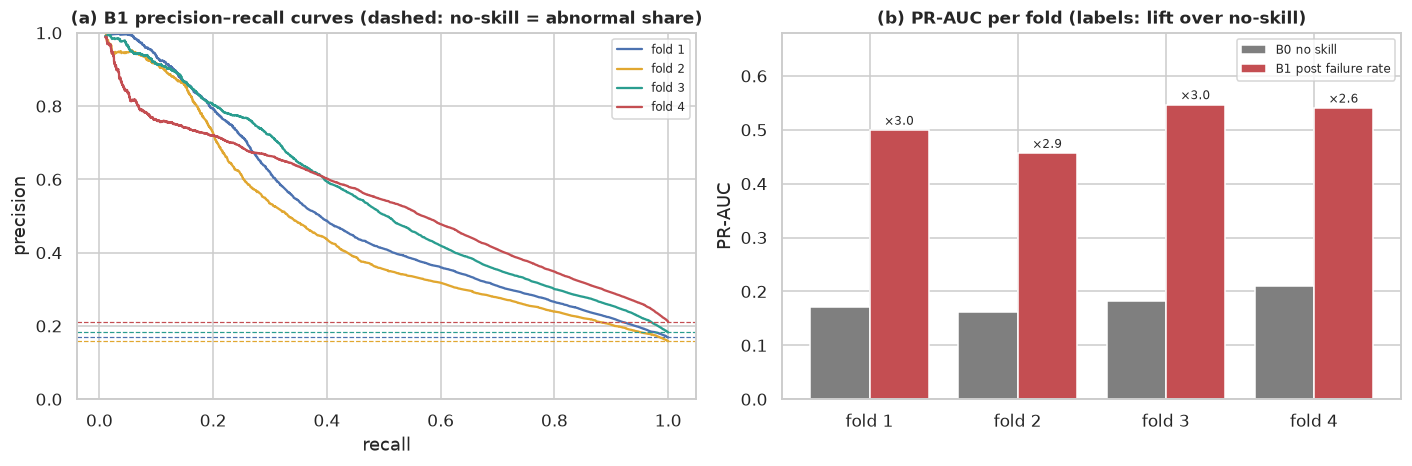

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
palette = [C_NORMAL, C_ORANGE, C_GREEN, C_ABN]
for f, color in zip(FOLDS, palette):
    va = df.loc[f["valid"]]
    precision, recall, _ = precision_recall_curve(va[TARGET], va["post_previous_abnormal_rate_7D"])
    keep = recall > 0.01                                        # hide the first few sessions (a handful of ties at the very top)
    axes[0].plot(recall[keep], precision[keep], color=color, label=f"fold {f['fold']}")
    axes[0].axhline(va[TARGET].mean(), color=color, ls="--", lw=.8)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_ylim(0, 1)
axes[0].set_title("(a) B1 precision–recall curves (dashed: no-skill = abnormal share)")
axes[0].legend(fontsize=8)
pr = results.pivot(index="fold", columns="baseline", values="PR-AUC")
lift = results[results["baseline"].str.startswith("B1")].set_index("fold")["lift"]
x = np.arange(len(pr))
axes[1].bar(x - .2, pr["B0 no skill"], width=.4, color=C_GREY, label="B0 no skill")
axes[1].bar(x + .2, pr["B1 post failure rate (7 days)"], width=.4, color=C_ABN, label="B1 post failure rate")
for xi, (value, l) in enumerate(zip(pr["B1 post failure rate (7 days)"], lift)):
    axes[1].text(xi + .2, value + .01, f"×{l:.1f}", ha="center", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"fold {k}" for k in pr.index])
axes[1].set_ylabel("PR-AUC"); axes[1].set_ylim(0, 0.68); axes[1].set_title("(b) PR-AUC per fold (labels: lift over no-skill)")
axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "09_baselines")

In panel (a), all four curves are far above their dashed no-skill lines (15.8%–21.1%). In folds 1–3 the rule is very precise at
low recall (precision stays above 0.8 up to a recall of about 0.2), and precision decreases steadily as more failures are
demanded, meeting the no-skill line only when almost everything is flagged. Fold 4 behaves differently: its top of the ranking is
less precise (precision is already below 0.8 at a recall of about 0.07, and about 0.72 at a recall of 0.2), but its curve is the
highest beyond a recall of about 0.4. The top of the list matters most for a small alert budget, so looking at the curves fold by
fold is more informative than a single pooled number. Fold 2 is the weakest curve over most of the range.

Panel (b) shows that B1 is about three times better than chance in every fold (lift 2.6–3.0), and that fold 4 has the lowest lift
although its raw PR-AUC is among the highest.

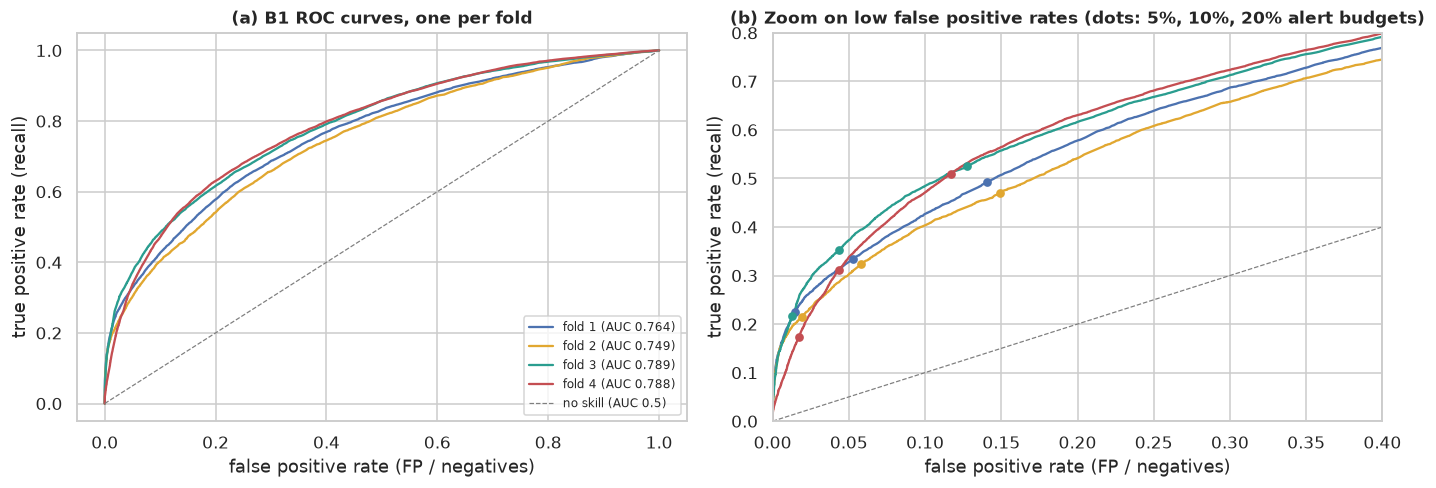

alert budget,false positive rate,true positive rate (recall),precision
5%,0.016,0.207,0.738
10%,0.049,0.330,0.594
20%,0.134,0.499,0.451


In [78]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for f, color in zip(FOLDS, palette):
    va = df.loc[f["valid"]]
    fpr, tpr, _ = roc_curve(va[TARGET], va["post_previous_abnormal_rate_7D"])
    r = results[(results["baseline"] == "B1 post failure rate (7 days)") & (results["fold"] == f["fold"])].iloc[0]
    auc = r["ROC-AUC"]
    axes[0].plot(fpr, tpr, color=color, label=f"fold {f['fold']} (AUC {auc:.3f})")
    axes[1].plot(fpr, tpr, color=color)
    for q in ALERT_BUDGETS:                                      # operating point of each alert budget on the ROC curve
        fpr_q = r[f"false alerts per 1,000 @{q:.0%}"] / (1000 * (1 - r["abnormal share"]))
        axes[1].scatter(fpr_q, r[f"recall @{q:.0%}"], color=color, s=22, zorder=3)
for ax in axes:
    ax.plot([0, 1], [0, 1], color=C_GREY, ls="--", lw=.8, label="no skill (AUC 0.5)" if ax is axes[0] else None)
    ax.set_xlabel("false positive rate (FP / negatives)"); ax.set_ylabel("true positive rate (recall)")
axes[0].set_title("(a) B1 ROC curves, one per fold"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_xlim(0, 0.4); axes[1].set_ylim(0, 0.8)
axes[1].set_title("(b) Zoom on low false positive rates (dots: 5%, 10%, 20% alert budgets)")
fig.tight_layout()
savefig(fig, "09_baselines_roc")

roc_ops = []
for q in ALERT_BUDGETS:
    sub = results[results["baseline"] == "B1 post failure rate (7 days)"]
    fpr_q = sub[f"false alerts per 1,000 @{q:.0%}"] / (1000 * (1 - sub["abnormal share"]))
    roc_ops.append({"alert budget": f"{q:.0%}", "false positive rate": fpr_q.mean(), "true positive rate (recall)": sub[f"recall @{q:.0%}"].mean(),
                    "precision": sub[f"precision @{q:.0%}"].mean()})
display(pd.DataFrame(roc_ops).style.hide(axis="index").format({"false positive rate": "{:.3f}", "true positive rate (recall)": "{:.3f}", "precision": "{:.3f}"}))


The ROC curves complete the view of the baseline, because the ROC curve and the AUC do not depend on the abnormal share. In panel (a), the four curves of B1
are far above the diagonal (AUC 0.749 to 0.789) and are close to one another. Fold 2 is the lowest curve and folds 3 and 4 the highest, which is the same order as
the PR-AUC. Fold 4 starts lower: at the 5% alert budget it reaches a true positive rate of about 0.17, against 0.21–0.22 in the other folds, and it overtakes folds 1 and 2 only
at a false positive rate of about 0.05. This agrees with the less precise top of its precision–recall curve.

Panel (b) and the table show why the ROC curve alone would be too optimistic for this problem, as the slides warn. The false positive rate stays small because there are
many more normal sessions than abnormal ones: at the 20% budget it is only 13.4%, which looks like a good point of the curve, but the precision is 45%, so there are more false
alerts than correct ones (110 against 90 per 1,000 sessions). At the 5% budget the false positive rate is 1.6% and the precision is 74%. The ROC curve therefore tells us
that the ranking separates the two classes, and the precision–recall view and the alert budgets tell us what that separation costs in alerts. We keep ROC-AUC as a
complementary metric, as decided in Section 6.

In [79]:
log_decision("9", "Baselines",
             "B0 no skill (random scores, constant training prior, 'always normal') and B1 simple rule: score = post_previous_abnormal_rate_7D (no fitting).",
             "B0 gives PR-AUC = abnormal share and ROC-AUC = 0.5, so the share changes the target a model must beat; B1 is the strongest single start-time signal in Task 1 (Section 9.4).")

---
## 10. The evaluation protocol

This is the protocol that we fix before hyperparameter optimisation and final model selection. The details and the evidence are in
the sections indicated.

| Element | Decision | Section |
|---------|----------|---------|
| Problem | Predict, at the start of a charging session, whether it will end abnormally (13 fault causes against normal or user-stopped endings). Use: ranked risk alerts for monitoring and maintenance prioritisation | 3 |
| Admissible predictors | 29 features in 7 groups (calendar, tariff, location, weather, post history, user history, concurrency), built from 27 original columns | 4 |
| Excluded variables and reasons | `end_cause`: target only. Energy, cost, service charge, amount, payment, `End Time`, `Payment time`: generated during or after the session. `UserID`: identifier. `Order creation time`: uncertain timing. 10 redundant columns (`electricity_price`, 6 abnormal counts, 2 post no-history flags, `user_no_previous_completed_session`) | 4 |
| Primary metric | PR-AUC (average precision), always read with the abnormal share of the fold and as lift | 6 |
| Complementary metrics | ROC-AUC, Brier score, log-loss | 6 |
| Operational measures | Precision, recall and correct / false / missed alerts per 1,000 sessions at alert budgets of 5%, 10% and 20% | 6 |
| Baselines | B0 no skill (PR-AUC = abnormal share, ROC-AUC = 0.5) and B1 recent failure rate of the post | 9 |
| Temporal strategy | Burn-in before 2020-04-01. Four expanding-window folds with consecutive validation quarters 2020-Q4 to 2021-Q3, purge of sessions whose label is unknown at the boundary. Test from 2021-10-01 untouched | 7 |
| Preprocessing | Everything that learns from data is fitted inside each training fold and applied unchanged to its validation rows; fixed seed | 7.3 |
| Aggregation and comparison | Rank by the unweighted mean PR-AUC; also report the weighted mean and the pooled value; stability = std, worst fold and trend; compare fold by fold (paired differences, folds won); no p-values from four folds | 8 |
| Threshold | Chosen on the pooled out-of-fold predictions of the four folds, by capacity (alert budget) or by cost ratio after checking calibration; stable across folds; frozen before the test | 7.4 |
| Final test | One evaluation of the refitted final model, with the same metrics and the baselines; no changes afterwards | 7.5 |

In [80]:
protocol = {
    "problem": {
        "unit_of_observation": "one charging session (identified by Start Time)",
        "positive_class": "is_Abnormal = 1: end_cause is one of the 13 fault / failure causes",
        "negative_class": "is_Abnormal = 0: 'Charging ends normally' or 'User stops charging'",
        "normal_causes": sorted(NORMAL_CAUSES),
        "prediction_moment": "Start Time of the session",
        "purpose": "ranked risk alerts for preventive monitoring and maintenance prioritisation",
        "target_evidence": "our mapping reproduces the dataset's own previous-abnormal columns in about 100% of the rows (Task 1, Section 5.2)",
    },
    "predictors": {"n_features": len(features), "groups": FEATURE_GROUPS["groups"], "categorical": FEATURE_GROUPS["categorical"]},
    "excluded": classification[classification["category"] != "1 eligible predictor"][["column", "category", "reason"]].to_dict("records"),
    "metrics": {"primary": "PR-AUC (average precision)", "complementary": ["ROC-AUC", "Brier score", "log-loss"],
                "operational": {"alert_budgets": list(ALERT_BUDGETS),
                                "measures": ["precision", "recall", "correct alerts per 1,000", "false alerts per 1,000", "missed per 1,000"]},
                "stability": ["per-fold value", "std across folds", "worst fold", "trend per fold", "folds won against the baseline"],
                "not_used": ["accuracy", "F1", "balanced accuracy", "kappa", "MCC"]},
    "temporal": {"burn_in_end": str(BURN_IN_END.date()), "test_start": str(TEST_START.date()), "seed": SEED,
                 "folds": [{"fold": f["fold"], "train_from": str(BURN_IN_END.date()), "train_before": str(f["lo"].date()),
                            "validate_from": str(f["lo"].date()), "validate_before": str(f["hi"].date()),
                            "train_sessions": len(f["train"]), "purged": f["purged"], "validation_sessions": len(f["valid"])} for f in FOLDS]},
    "aggregation": {"ranking": "unweighted mean of per-fold PR-AUC", "also_reported": ["mean weighted by validation sessions", "pooled"],
                    "stability": ["std across folds", "worst fold", "trend per fold"],
                    "comparison": "paired per-fold differences and folds won; no p-values with four folds"},
    "baselines": {"B0": "random scores / constant training prior / always normal", "B1": "post_previous_abnormal_rate_7D (no fitting)"},
    "threshold_rule": "pooled out-of-fold predictions of the four folds; alert budget or cost-ratio cut-off after calibration check; stable across folds; frozen before test",
    "test_protection": "test rows not loaded in Task 2; final model refitted on all development data with purge; one evaluation; no changes afterwards",
}
(OUT_DIR / "task2_protocol.json").write_text(json.dumps(protocol, indent=2, ensure_ascii=False, default=str))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task2_decision_log.csv", index=False)
print("Saved:", OUT_DIR / "task2_protocol.json", "and", OUT_DIR / "task2_decision_log.csv", "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task2_protocol.json and prepared/task2_decision_log.csv | figures in prepared/figures_task2


section,topic,decision,evidence
3,Problem definition,Unit = charging session; positive = abnormal ending (13 fault causes); prediction at Start Time; use = ranked risk alerts for preventive monitoring and maintenance prioritisation.,"Brief, Section 2; our target mapping reproduces the dataset's own history columns in about 100% of the rows (Task 1, Section 5.2)."
4,Predictor set,"27 original columns are eligible (29 features in 7 groups). Excluded: 1 target-only column, 7 generated during or after the session, 12 for other reasons (identifier, uncertain timing, redundancy).",Every one of the 47 columns appears once in the classification table; reasons and evidence per column in Section 4.
5,Error consequences,"A missed failure costs more per event than a false alert, but false alerts are capped by inspection capacity: evaluate the ranking and the result at a fixed alert budget. The cut-off is chosen later from the cost ratio and the capacity.","Failures cluster by post (Task 1, Section 9.4); best cut-off t* = 1/(1 + c) falls below the abnormal share for c > 4.4."
6,Metrics,"Primary: PR-AUC. Complementary: ROC-AUC, Brier score, log-loss. Operational: precision, recall and correct / false / missed alerts per 1,000 sessions at alert budgets of 5%, 10% and 20%. Stability: per-fold values, std, worst fold, trend, wins against the baseline. Accuracy, F1, kappa and MCC are not used for model comparison.","Abnormal share ~18.5% with unequal error costs; the share moves between periods, so lift and fixed budgets are needed (Sections 5 and 7)."
7,Temporal strategy,Burn-in before 2020-04-01; development 2020-04-01 to 2021-09-30 with four expanding-window folds (validation = consecutive quarters 2020-Q4 to 2021-Q3); test from 2021-10-01 untouched. No random splitting.,"Prevalence, volume and fault mix change over time (Task 1, Section 7); fold sizes 41.8k–75.8k validation, 111k–271k training; every fold has ≥ 6,600 abnormal sessions."
7,Purge,Training sessions that end after the validation start are removed from that fold's training set.,A label exists only when the session ends (up to 24 h later); 27–39 sessions per fold.
8,Aggregation,"Rank models by the unweighted mean of per-fold PR-AUC; also report the session-weighted mean and the pooled value; stability = std, worst fold and trend; compare models fold by fold (paired differences, folds won). No p-values from four folds.",Periods are the unit of generalisation; abnormal share differs by fold (15.8%–21.1%); the smallest exact Wilcoxon p with 4 folds is 0.125.
9,Baselines,"B0 no skill (random scores, constant training prior, 'always normal') and B1 simple rule: score = post_previous_abnormal_rate_7D (no fitting).","B0 gives PR-AUC = abnormal share and ROC-AUC = 0.5, so the share changes the target a model must beat; B1 is the strongest single start-time signal in Task 1 (Section 9.4)."


### Limitations and assumptions that remain open

* The target treats `User stops charging` as a normal ending. The dataset's own history columns support this choice (Task 1,
  Section 5.2), but it is still our reading of `end_cause`. With a different mapping, the abnormal share, the baselines and every
  metric would change.
* Weather is assumed to be a forecast available at the start, as the brief says. If it is an observed daily value, it contains
  post-start information.
* Costs and capacity are unknown. The cost ratio `c` and the alert budgets (5%, 10%, 20%) are assumptions used to design the
  protocol. The final threshold needs real values or a clearly stated assumption.
* Four folds give a rough picture of stability and no valid p-value. Early folds train on less data and without a full winter.
* The folds are used for selection, so their scores are slightly optimistic. The test is the unbiased estimate.
* The 7-day window of baseline B1 was taken from the Task 1 ranking, whose training period overlaps the validation quarters of
  folds 1 to 3 (Section 9). B1 fits nothing, so we expect the effect to be small.
* No post cold-start is tested: every post of the folds and of the test period was seen in training (Task 1, Section 11).
  Cold-start of users can be examined inside the folds (about 12% of the development sessions are from new users).
* The fault mix changes over time and the target merges 13 causes. A good average could hide a failure type that the model never
  detects.

Tasks 3 and 4 use `temporal_folds`, the metric functions and `prepared/task2_protocol.json` unchanged. They fit every
candidate inside each training fold, compare it with B0 and B1 fold by fold, and run the feature-group ablation on the same folds.

# Part 3 · Task 3: Individual and ensemble prediction models

In [81]:
# each part starts from an empty namespace, as when the task notebooks ran on their own
%reset -f

## TP1 · Task 3: Individual and ensemble prediction models
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 3 asks three things: which kinds of information contribute to the prediction (an ablation by feature group), how individual
classifiers of different modelling principles perform, and whether ensembles improve on them. Everything runs under the evaluation
protocol that we fixed in Task 2 (`prepared/task2_protocol.json`): the same four expanding-window folds, the same metrics and the
same baselines. The rows of the final test period are dropped right after the file is read, and no decision threshold is chosen here.

### How to read this notebook

| # | Section | Requirement of the Task 3 brief |
|---|---------|---------------------------------|
| 1 | Setup | — |
| 2 | Data, folds and baselines from Task 2 | the protocol that every result below follows |
| 3 | Feature-group ablation | four nested feature sets; tariff against time of day, post history, user history, consistency over time, operational and ethical concerns |
| 4 | Individual models | classifiers of at least three modelling principles, justified by data types, imbalance, assumptions, interpretability and cost |
| 5 | Ensemble models | at least three ensemble principles, with temporally out-of-fold stacking |
| 6 | Comparison and conclusions | all models against the baselines, fold by fold |
| 7 | Saved files and decision log | — |

Preprocessing values and model parameters are fitted on the training rows of each fold and applied unchanged to its validation
quarter. Feature-set and hyperparameter choices use the unweighted mean PR-AUC over the four development folds, read together
with the paired differences, as planned in Task 2 (Section 8). These are model-selection results; the separate test period is
reserved for the final evaluation (Section 6.4).

---
## 1. Setup

In [82]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, KBinsDiscretizer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler)
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task3"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

# Everything below that defines the evaluation comes from the Task 2 files, so the two tasks cannot drift apart.
PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
GROUPS = FEATURE_GROUPS["groups"]

# Practical tolerance for small PR-AUC differences, read together with the paired fold results.
# The descriptive bootstrap in Section 3.3 gives context; this is not a significance threshold.
TOLERANCE = 0.005

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 7)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

---
## 2. Data, folds and baselines from Task 2

We load only the columns of the 29 eligible features and the three columns that define the target and the fold boundaries
(`Start Time`, `End Time`, `end_cause`). Right after reading the file we drop the burn-in and the test rows and only count
them, before the target or any feature is built. No label of a test session is ever computed, and the test sessions are not in memory for the
rest of the notebook.

In [83]:
RENAME = {   # same short names as in Task 1 and Task 2
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}     # features built from one column (Task 1, Section 12)

features_all = [f for group in GROUPS.values() for f in group]
needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in features_all} | {"Start Time", "End Time", "end_cause"}
df = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
df["start_time"] = pd.to_datetime(df["start_time"], format="%Y-%m-%d %H:%M:%S")
n_total = len(df)
n_burn_in = int((df["start_time"] < BURN_IN_END).sum())
n_test = int((df["start_time"] >= TEST_START).sum())
df = df[(df["start_time"] >= BURN_IN_END) & (df["start_time"] < TEST_START)].reset_index(drop=True)   # the test rows go here, before any label or feature exists

for col in ("location", "district", "tariff_period", "end_cause"):
    df[col] = df[col].str.strip()
df["end_time"] = pd.to_datetime(df["end_time"], format="%Y-%m-%d %H:%M:%S")
df["hour"] = df["start_time"].dt.hour.astype("int8")
df["dow"] = df["start_time"].dt.dayofweek.astype("int8")
df["rain_flag"] = (df["precipitation"] > 0).astype("int8")
df[TARGET] = (~df["end_cause"].isin(NORMAL_CAUSES)).astype("int8")

print(f"File: {n_total:,} sessions | burn-in removed: {n_burn_in:,} | test removed: {n_test:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), "
      f"abnormal share {df[TARGET].mean():.2%}")
print(f"Features available: {len(features_all)} in {len(GROUPS)} groups")
assert df["start_time"].max() < TEST_START and len(features_all) == 29

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%
Features available: 29 in 7 groups


### 2.1 The four temporal folds

The folds are rebuilt from the boundaries stored in the Task 2 protocol, with the same purge rule and the same assertions. Fold *k* trains on
every labelled development session that started and ended before its validation quarter, and validates on that quarter.

In [84]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"] and np.isin(a["train"], b["train"]).all()
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]      # same folds as Task 2
assert FOLDS[-1]["hi"] == TEST_START
print("The four folds match the Task 2 protocol and pass the temporal integrity checks.")

fold_table = pd.DataFrame([{"fold": f["fold"], "validation quarter": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
                            "train sessions": len(f["train"]), "validation sessions": len(f["valid"]),
                            "validation abnormal share": df.loc[f["valid"], TARGET].mean()} for f in FOLDS]).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal share": "{:.1%}"}))

The four folds match the Task 2 protocol and pass the temporal integrity checks.


,validation quarter,train sessions,validation sessions,validation abnormal share
fold,,,,
1,2020-10-01 to 2020-12-31,"111,470","60,364",16.8%
2,2021-01-01 to 2021-03-31,"171,832","41,797",15.8%
3,2021-04-01 to 2021-06-30,"213,641","57,542",18.2%
4,2021-07-01 to 2021-09-30,"271,182","75,769",21.1%


### 2.2 Metrics, aggregation and the cross-validation runner

The functions below are the ones of Task 2 (Sections 6 and 8), so the numbers of both notebooks are comparable. `cv_run` is the runner that every
experiment uses: for each fold it builds a fresh pipeline, fits it on that fold's training rows only, predicts the validation quarter and
stores the metrics. The predictions are kept because Sections 3 and 5 need them.

In [85]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired(model, competitor):
    """Fold-by-fold difference `model - competitor` of one metric (Series indexed by fold) and its summary."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    summary = {"mean difference": diff.mean(), "std of differences": diff.std(ddof=1), "folds won": f"{int((diff > 0).sum())} of {len(diff)}",
               "smallest difference": diff.min(), "largest difference": diff.max()}
    return diff, pd.Series(summary)


METRICS, PREDS = [], {}       # per-fold metrics and validation predictions of every experiment, keyed by experiment label


def cv_run(label, make_model, features):
    """Run one experiment under the Task 2 protocol: a fresh pipeline per fold, fitted on that fold's training rows only."""
    rows = []
    for f in FOLDS:
        tr, va = df.loc[f["train"]], df.loc[f["valid"]]
        started = time.time()
        model = make_model(features).fit(tr[features], tr[TARGET])
        if isinstance(model.named_steps["clf"], HistGradientBoostingClassifier):
            fitted = model.named_steps["clf"]
            assert not fitted.do_early_stopping_ and fitted.n_iter_ == fitted.max_iter
        p = model.predict_proba(va[features])[:, 1]
        seconds = time.time() - started
        PREDS[(label, f["fold"])] = p
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds,
                     **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    result = pd.DataFrame(rows)
    METRICS.append(result)
    return result


def metric_table(labels, metric="PR-AUC"):
    """Fold-by-fold table of one metric for several experiments, with the mean over folds."""
    all_metrics = pd.concat(METRICS)
    t = all_metrics[all_metrics["model"].isin(labels)].pivot(index="model", columns="fold", values=metric).loc[labels]
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
    return t

### 2.3 Baselines of Task 2

The reference results of Task 2 are computed again, with the same definitions: B0 (no skill: random scores for the ranking metrics and the constant
training prior for the probability metrics) and B1 (the 7-day failure rate of the post, which fits nothing). They are the floor and the simple rule
that every model below has to beat.

In [86]:
rng = np.random.default_rng(SEED)
rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                            # learned inside the training fold
    s_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for label, score, prob in [("B0 no skill", rng.random(len(y)), np.full(len(y), prior)), ("B1 post failure rate (7 days)", s_b1, s_b1)]:
        PREDS[(label, f["fold"])] = score
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng=rng)})
METRICS.append(pd.DataFrame(rows))
BASELINES = ["B0 no skill", "B1 post failure rate (7 days)"]
b = metric_table(BASELINES)
display(b.style.format("{:.3f}"))
print(f"B1 mean PR-AUC = {b.loc[BASELINES[1], 'mean']:.3f} (Task 2 reported 0.511)")
assert abs(b.loc[BASELINES[1], "mean"] - 0.511) < 0.001

,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
B0 no skill,0.172,0.162,0.181,0.210,0.181
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511


B1 mean PR-AUC = 0.511 (Task 2 reported 0.511)


---
## 3. Feature-group ablation

### 3.1 Design

The brief asks for four nested feature sets, each one adding a kind of information to the previous one:

| Set | Adds | Groups of Task 1 | Features |
|-----|------|------------------|----------|
| S1 | contextual and weather variables | calendar (`hour`, `dow`), location (`post_id`, `location`, `district`), weather (4 variables) | 9 |
| S2 | tariff | `tariff_period` | 10 |
| S3 | charging-post history | 8 variables of the post history | 18 |
| S4 | user history | 10 user-history variables and `user_active_sessions_at_start` (the concurrency variable describes the account, so it goes with the user) | 29 |

We put the location in the contextual set because the post is known when the session starts. The variables of every set are those of the
Task 2 protocol, so nothing in this section uses information that is unavailable at the start of the session.

We add no new feature. The brief allows extra features if they are known at the start, but the start-time columns were already chosen in Task 1
(Sections 9 and 12), and Section 3.2 shows that one group, the post history, carries most of the signal. A new history feature would also need
its own check that every session it counts had ended before the start, which is the leak that Task 2 (Section 4) was built to exclude.

The ablation needs one model that is the same for every set, so that differences come from the information and not from
tuning. We use gradient boosting (`HistGradientBoostingClassifier`) with fixed hyperparameters (depth 6, learning rate 0.1, 200 iterations, at
least 100 sessions per leaf) that we do not tune. It handles categories, missing values and non-linear interactions directly, so one preprocessing
serves all sets, and it is strong enough for a group that holds information to show it. The conclusions are therefore for this model family. The
individual models of Section 4 are fitted afterwards on the set that this section selects.

Each step is judged by the paired difference in PR-AUC between the set with and without the group, fold by fold, as decided in
Task 2 (Section 8). We treat a gain as practically relevant when its mean is larger than our tolerance of 0.005 and it has the same sign in at
least three of the four folds. This is a selection rule, not a claim of statistical significance (Section 3.3). A group stays in the modelling set only if removing it costs more than
that tolerance.

In [87]:
def tree_view(features):
    """Preprocessing of tree-based models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


HGB_REFERENCE = dict(max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100, early_stopping=False, random_state=SEED)


def make_reference_model(features):
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    return Pipeline([("prep", tree_view(features)),
                     ("clf", HistGradientBoostingClassifier(categorical_features=cat or None, **HGB_REFERENCE))])


S1 = GROUPS["calendar"] + GROUPS["location"] + GROUPS["weather"]
S2 = S1 + GROUPS["tariff"]
S3 = S2 + GROUPS["post_history"]
S4 = S3 + GROUPS["user_history"] + GROUPS["concurrency"]
STEPS = {"S1 context + weather": S1, "S2 + tariff": S2, "S3 + post history": S3, "S4 + user history": S4}
assert [len(s) for s in STEPS.values()] == [9, 10, 18, 29]

t0 = time.time()
for label, feats in STEPS.items():
    cv_run(label, make_reference_model, feats)
print(f"four ablation sets x four folds fitted in {time.time() - t0:.0f} s")

all_metrics = pd.concat(METRICS)
summary = all_metrics[all_metrics["model"].isin(list(STEPS))].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
summary.insert(0, "features", [len(f) for f in STEPS.values()])
print("Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):")
display(summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print("PR-AUC in every fold:")
display(metric_table(list(STEPS)).style.format("{:.3f}"))

four ablation sets x four folds fitted in 57 s
Mean over the four folds (the baselines B0 and B1 have a PR-AUC of 0.181 and 0.511):


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S1 context + weather,9,0.290,1.60,0.660,0.144,0.456
S2 + tariff,10,0.290,1.60,0.659,0.144,0.456
S3 + post history,18,0.584,3.26,0.805,0.108,0.358
S4 + user history,29,0.615,3.44,0.833,0.104,0.342


PR-AUC in every fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
S1 context + weather,0.204,0.277,0.299,0.379,0.290
S2 + tariff,0.201,0.280,0.299,0.381,0.290
S3 + post history,0.560,0.532,0.614,0.630,0.584
S4 + user history,0.604,0.568,0.639,0.648,0.615


### 3.2 What each group adds

The table below gives the paired differences between consecutive sets, in PR-AUC and in ROC-AUC. The first step answers whether the tariff gives
information beyond the time of day (S1 already contains `hour` and `dow`), the second how much the post history contributes, and the third
whether the user history gives an additional benefit.

In [88]:
labels = list(STEPS)
questions = {"S2 + tariff": ("tariff beyond time of day", "S1 context + weather"),
             "S3 + post history": ("post history", "S2 + tariff"),
             "S4 + user history": ("user history", "S3 + post history")}
pr, roc = metric_table(labels, "PR-AUC"), metric_table(labels, "ROC-AUC")
rows, diffs = [], {}
for new, (question, base) in questions.items():
    d, s = paired(pr.loc[new, [c for c in pr.columns if c != "mean"]], pr.loc[base, [c for c in pr.columns if c != "mean"]])
    d_roc = (roc.loc[new, "mean"] - roc.loc[base, "mean"])
    diffs[question] = d
    rows.append({"added group": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"], "ROC-AUC difference (mean)": d_roc})
steps_table = pd.DataFrame(rows).set_index("added group")
display(steps_table.style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}", "ROC-AUC difference (mean)": "{:+.4f}"}))
print("Paired PR-AUC differences by fold:")
display(pd.DataFrame(diffs).T.style.format("{:+.4f}"))

,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold,ROC-AUC difference (mean)
added group,,,,,
tariff beyond time of day,+0.0006,3 of 4,-0.0033,+0.0038,-0.0013
post history,+0.2938,4 of 4,+0.2493,+0.3595,+0.1463
user history,+0.0306,4 of 4,+0.0177,+0.0441,+0.0273


Paired PR-AUC differences by fold:


,fold 1,fold 2,fold 3,fold 4
tariff beyond time of day,-0.0033,+0.0038,+0.0001,+0.0018
post history,+0.3595,+0.2515,+0.3151,+0.2493
user history,+0.0441,+0.0364,+0.0242,+0.0177


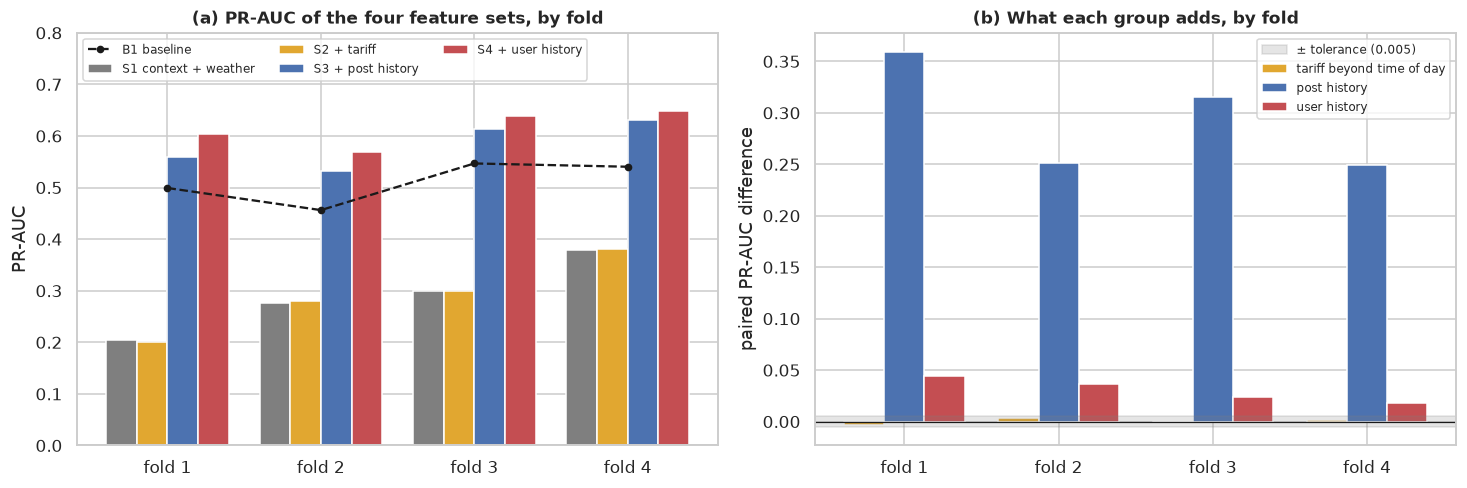

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
colors = [C_GREY, C_ORANGE, C_NORMAL, C_ABN]
width = 0.2
x = np.arange(len(FOLDS))
for i, (label, color) in enumerate(zip(labels, colors)):
    axes[0].bar(x + (i - 1.5) * width, pr.loc[label, [c for c in pr.columns if c != "mean"]], width=width, color=color, label=label)
axes[0].plot(x, metric_table([BASELINES[1]]).iloc[0, :-1], color="k", ls="--", marker="o", ms=4, label="B1 baseline")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 0.8); axes[0].set_title("(a) PR-AUC of the four feature sets, by fold"); axes[0].legend(fontsize=8, loc="upper left", ncol=3)
for i, (question, color) in enumerate(zip(diffs, [C_ORANGE, C_NORMAL, C_ABN])):
    axes[1].bar(x + (i - 1) * 0.26, diffs[question].to_numpy(), width=0.26, color=color, label=question)
axes[1].axhspan(-TOLERANCE, TOLERANCE, color=C_GREY, alpha=0.2, label=f"± tolerance ({TOLERANCE})")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"fold {f['fold']}" for f in FOLDS]); axes[1].set_ylabel("paired PR-AUC difference")
axes[1].set_title("(b) What each group adds, by fold"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "03_2_ablation")

The contextual and weather variables alone are weak. S1 reaches a mean PR-AUC of 0.290 (lift 1.6, ROC-AUC 0.660).
Its fold values range from 0.204 to 0.379, and it stays below B1 in every quarter. In fold 4,
for example, S1 scores 0.379 against 0.540 for B1.

The tariff adds no practically relevant gain beyond the time of day. Adding `tariff_period` changes the mean PR-AUC by
+0.0006, with fold differences from -0.0033 to +0.0038, inside our tolerance. This is consistent with Task 1
(Section 4.3): the tariff period is a deterministic function of the start hour, which S1 already contains.

The post history is by far the largest contribution. It lifts the mean PR-AUC from 0.290 to 0.584
(+0.294) and the mean ROC-AUC from 0.659 to 0.805. Its gains by fold are
+0.360, +0.251, +0.315, +0.249. S3 beats B1 in every quarter, so it does more than repeat the 7-day failure rate.

The user history adds a smaller benefit: +0.031 in mean PR-AUC (0.584 to 0.615), positive in all four folds.
The gains are +0.044, +0.036, +0.024, +0.018, so the extra benefit is smaller in later quarters. The experiment does not isolate
why: the training window, the sessions and the failure pattern all change. One possible explanation is that the post history
leaves less information for the user history to add.

The ordering is consistent across quarters: S1 and S2 are close, S3 is far above them and S4 is above S3. The direction of the
history gains is consistent, while their size changes over time.

### 3.3 A practical tolerance for small differences

We use 0.005 as a practical tolerance when choosing between close results. To put its scale in context, we use the bootstrap
of the evaluation slides (MINDD-04): 100 resamples of the sessions in each validation quarter, scored with the fixed predictions of S4.

In [90]:
rng_boot = np.random.default_rng(SEED)
boot = []
for f in FOLDS:
    y = df.loc[f["valid"], TARGET].to_numpy()
    p = PREDS[("S4 + user history", f["fold"])]
    scores = [average_precision_score(y[i], p[i]) for i in (rng_boot.integers(0, len(y), len(y)) for _ in range(100))]
    boot.append({"fold": f["fold"], "validation sessions": len(y), "PR-AUC": average_precision_score(y, p), "bootstrap standard error": np.std(scores, ddof=1)})
boot = pd.DataFrame(boot).set_index("fold")
display(boot.style.format({"validation sessions": "{:,.0f}", "PR-AUC": "{:.3f}", "bootstrap standard error": "{:.4f}"}))

,validation sessions,PR-AUC,bootstrap standard error
fold,,,
1,"60,364",0.604,0.0043
2,"41,797",0.568,0.0058
3,"57,542",0.639,0.0044
4,"75,769",0.648,0.0040


The session-bootstrap standard error ranges from 0.0040 to 0.0058 across folds, of the same order as
our tolerance. This calculation describes variation in one model's score with its predictions held fixed. It does not estimate
the uncertainty of paired differences or account for dependence between sessions from the same posts, accounts and periods.

We therefore keep 0.005 as a practical selection rule and do not interpret it as a significance boundary or proof that two
models are equivalent. The paired fold differences remain the main evidence: the post-history and user-history gains are
consistently positive, whereas the tariff changes are small.

### 3.4 Do `post_id` and the tariff earn their place?

The ablation above keeps `post_id` in every set and `tariff_period` from S2 onward. Two questions remain, one left open in Task 2 (Section 4: *whether `post_id` adds
value is a question for the ablation*) and one raised by Section 3.2: the tariff is a deterministic function of the hour (Task 1, Section 4.3), and
`post_id` is an identifier that a model can memorise and whose value is unseen in training for a new post. We test both by removing them from S4, and we also
measure what the user history is worth once those two are gone, which is the cost of the privacy-preserving alternative.

In [91]:
SELECTED = [c for c in S4 if c not in ("post_id", "tariff_period")]
NO_USER = [c for c in SELECTED if c not in GROUPS["user_history"] + GROUPS["concurrency"]]
CHECKS = {"S4 without post_id": [c for c in S4 if c != "post_id"],
          "S4 without post_id and tariff (selected)": SELECTED,
          "selected without user history": NO_USER}
assert [len(f) for f in CHECKS.values()] == [28, 27, 16]

t0 = time.time()
for label, feats in CHECKS.items():
    cv_run(label, make_reference_model, feats)
print(f"three reduction checks x four folds fitted in {time.time() - t0:.0f} s")

all_labels = ["S4 + user history"] + list(CHECKS)
all_metrics = pd.concat(METRICS)
check_summary = all_metrics[all_metrics["model"].isin(all_labels)].groupby("model", sort=False)[["PR-AUC", "lift", "ROC-AUC", "Brier", "log-loss"]].mean()
check_summary.insert(0, "features", [29, 28, 27, 16])
display(check_summary.style.format({"PR-AUC": "{:.3f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
pr_c = metric_table(all_labels)
fold_cols = [c for c in pr_c.columns if c != "mean"]
rows, check_diffs = [], {}
for question, new, base in [("removing post_id from S4", "S4 without post_id", "S4 + user history"),
                            ("removing the tariff as well", "S4 without post_id and tariff (selected)", "S4 without post_id"),
                            ("removing the user history from the selected set", "selected without user history", "S4 without post_id and tariff (selected)")]:
    d, s = paired(pr_c.loc[new, fold_cols], pr_c.loc[base, fold_cols])
    check_diffs[question] = d
    rows.append({"change": question, "PR-AUC difference (mean)": s["mean difference"], "folds with a gain": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("change").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))
display(pd.DataFrame(check_diffs).T.style.format("{:+.4f}"))

three reduction checks x four folds fitted in 39 s


,features,PR-AUC,lift,ROC-AUC,Brier,log-loss
model,,,,,,
S4 + user history,29,0.615,3.44,0.833,0.104,0.342
S4 without post_id,28,0.625,3.50,0.835,0.102,0.338
S4 without post_id and tariff (selected),27,0.626,3.50,0.836,0.102,0.337
selected without user history,16,0.599,3.34,0.811,0.106,0.352


,PR-AUC difference (mean),folds with a gain,smallest fold,largest fold
change,,,,
removing post_id from S4,+0.0107,4 of 4,+0.0056,+0.0134
removing the tariff as well,+0.0003,3 of 4,-0.0004,+0.0016
removing the user history from the selected set,-0.0270,0 of 4,-0.0366,-0.0166


,fold 1,fold 2,fold 3,fold 4
removing post_id from S4,+0.0134,+0.0056,+0.0116,+0.0123
removing the tariff as well,+0.0000,+0.0016,-0.0004,+0.0000
removing the user history from the selected set,-0.0327,-0.0366,-0.0221,-0.0166


Removing `post_id` changes the mean PR-AUC from 0.615 to 0.625
(+0.0107), with gains in 4 of 4 folds (+0.0056 to +0.0134). This supports dropping the identifier.
Memorisation of devices whose behaviour changes is one possible explanation, but this comparison does not establish the cause.
We keep `location` and `district`; a new post can be represented by those fields, although genuine new-post performance is not tested here.

Removing the tariff as well changes the mean PR-AUC by +0.0003, inside the tolerance. Since it is also a deterministic
function of the hour, we drop it. This closes the question left open in Task 2 (Section 4).

The 27 selected features give a mean PR-AUC of 0.626, lift 3.50, ROC-AUC 0.836,
Brier score 0.102 and log-loss 0.337.

Without the 11 user variables, the mean PR-AUC is 0.599. The mean loss is 0.027, with a loss in every fold
(-0.037 to -0.017), so the user history stays under our rule. The user-free alternative still improves on B1
(0.599 against 0.511) and remains an option if account histories cannot be used.

### 3.5 Does the user history help everyone? Cold start

A new account (`is_new_user = 1`) has no previous personal outcomes. It can still be scored using the other predictors,
the new-user flag and the default or missing history values. We check the observed benefit of the added user group separately
for new and returning users. The table pools the validation predictions of S3 and S4 over the four folds.

In [92]:
def segment_scores(label):
    y = np.concatenate([df.loc[f["valid"], TARGET].to_numpy() for f in FOLDS])
    p = np.concatenate([PREDS[(label, f["fold"])] for f in FOLDS])
    new = np.concatenate([df.loc[f["valid"], "is_new_user"].to_numpy() for f in FOLDS])
    return y, p, new


rows = []
for label in ["S3 + post history", "S4 + user history"]:
    y, p, new = segment_scores(label)
    for flag, name in [(1, "new users"), (0, "returning users")]:
        m = new == flag
        rows.append({"feature set": label, "segment": name, "sessions": int(m.sum()), "abnormal share": y[m].mean(),
                     "PR-AUC": average_precision_score(y[m], p[m]), "ROC-AUC": roc_auc_score(y[m], p[m])})
cold = pd.DataFrame(rows).set_index(["feature set", "segment"])
display(cold.style.format({"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}"}))

New accounts represent 29,685 of the 235,472 validation sessions
(12.6%). Their abnormal share is higher (22.4% against 17.8%), but S4 has a lower
PR-AUC (0.519 against 0.640) and ROC-AUC (0.727 against 0.847).

For new users, S3 and S4 give PR-AUC 0.513 and 0.519, and ROC-AUC 0.730 and 0.727.
For returning users, S4 gains +0.032 in PR-AUC and +0.028 in ROC-AUC. In this pooled comparison,
the added user group benefits returning accounts more. New accounts have a small PR-AUC gain but a slight ROC-AUC loss, so
the evidence for them is mixed. Pooling combines
quarters with different prevalence and models, so this is descriptive segment evidence, not a separate temporal validation.

### 3.6 Operational and ethical concerns of each group

The brief asks which groups raise operational or ethical concerns. The table combines the conditions needed to run each group at the start of a session, the concerns, and the evidence of this notebook.

| Group | What is needed to run it | Operational or ethical concern | Evidence in this notebook | Our position |
|-------|--------------------------|--------------------------------|---------------------------|--------------|
| Calendar | Nothing: it comes from the start time | None | Part of S1, which is weak on its own (PR-AUC 0.290) | Keep |
| Station and district (`location`, `district`) | The post is known when the car is plugged in | No personal data. If alerts steer maintenance, attention concentrates on the stations with the highest risk (from about 8% to 38% abnormal in Task 1, Section 9.1), so the alerts per station should be monitored | Part of every set | Keep |
| `post_id` | The post identifier | It identifies one device and lets the model memorise it, and a new post has an identifier unseen in training | Removing it changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds (Section 3.4) | Drop |
| Weather | A daily forecast per district at the start (an assumption of the brief) | None for people. If it were an observed daily total, it would contain information from after the start | Included in S1; its individual contribution is not isolated | Keep, with the assumption stated |
| Tariff | Nothing: it comes from the start time | None | Adds nothing beyond the hour (Section 3.2) | Drop, because it is redundant |
| Post history | A live record of the completed sessions of each post with their outcomes. A label exists only when a session ends, up to 24 hours later, so the record is always slightly behind. Posts without history (new ones) cannot use it | No personal data. There is a feedback effect: if alerts lead to maintenance, the failures fall and the history changes, so the model also reflects the maintenance policy | Largest contribution: +0.294 PR-AUC, in all four folds | Keep |
| User history and concurrency | The account must be identified when the session starts, and the platform must keep the outcomes of each account | It is a behaviour profile tied to a persistent identifier, which raises data-minimisation and purpose-limitation concerns. A driver who met a faulty post gets a higher risk, so the user can be blamed for a failure of the infrastructure. New users have no personal outcome history; we observe little added benefit for them (Section 3.5) | +0.031 PR-AUC, positive in 4 of 4 folds (+0.044 in fold 1, +0.018 in fold 4); pooled benefit mainly for returning users | Keep it in the comparison, because the rule requires it, but use it only for an internal ranking and never for a decision about a driver. The user-free set is the fallback (PR-AUC 0.599) |

In [93]:
log_decision("3", "Ablation design", "Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.",
             "Reference model handles categories, NaN and interactions; the tolerance is practical; the descriptive session bootstrap does not establish significance (Section 3.3).")
log_decision("3", "Selected feature set",
             "27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).",
             "Removing post_id changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds; tariff removal is inside the tolerance. Post history adds +0.294 and user history +0.031 on average (Sections 3.2 and 3.4).")
log_decision("3", "No new features", "No feature is added to the 29 start-time features of the Task 2 protocol.",
             "The start-time columns were chosen in Task 1 (Sections 9 and 12); the post history alone carries most of the signal (Section 3.2); "
             "a new history feature would need its own leakage check.")

---
## 4. Individual models

### 4.1 Which classifiers, and why

The brief lists five modelling principles (linear, probabilistic, instance-based, decision trees and kernel-based) and asks for at least three,
chosen and justified, instead of many without analysis. We choose three: a linear classifier, a probabilistic classifier and a decision tree. The
choice depends on what the data look like. The 27 selected features mix two categories (station and district), two circular calendar variables, weather,
skewed counts and times (Task 1, Section 9.4), bounded rates and four variables with structural missing values. About 18.5% of the sessions are
abnormal, which is a moderate imbalance. In Task 1 we decided not to resample, so the classifiers use the natural class prior and we judge them with
ranking metrics (PR-AUC, ROC-AUC) and with probability metrics (Brier score, log-loss).

| Principle | Classifier | Why it fits this problem | Assumption and risk here | Interpretability | Cost on 270k training sessions |
|-----------|------------|--------------------------|--------------------------|------------------|--------------------------------|
| Linear | Logistic regression (L2) | The failure rate of a post rises smoothly with its recent failure rate (decile curves of Task 1, Section 9.4), which a linear relationship in log-odds can represent (the slides describe logistic regression as linear in the supplied features). It outputs probabilities, which the Brier score and the cut-off `t* = 1/(1 + c)` of Task 2 need | The log-odds must be linear in the inputs, so the skewed variables need a log transform, and the U-shape of the time since the previous session is not linear. Correlated windows make single coefficients unstable (the long user windows have a VIF above 10 in Task 1, Section 12.4), and the L2 penalty controls that. The slides ask for scaled inputs, especially with a penalty, so the inputs are z-scores | High: one coefficient per input | Low: seconds |
| Probabilistic | Naive Bayes (categorical, Laplace estimate) | Few parameters, a posterior probability from Bayes' theorem and a different inductive bias from the other two. It handles the mixed types once the numbers are discretised, which is the equal-frequency binning of the course | It assumes the inputs are independent given the class (the naive assumption of the slides). They are not: the 1-, 7- and 30-day windows overlap and fleet accounts repeat. We retain the selected inputs and expect correlated history windows to make probabilities overconfident | Medium: one likelihood table per input | Low: seconds |
| Decision tree | CART tree | Thresholds on rates and gaps and their interactions (for example "recent post failure rate high and short gap since the previous session") match the shapes seen in Task 1. Its inductive bias is the one of the slides: successive thresholds cut the data into regions with similar labels. Missing values cause no trouble, and no scaling is needed | A single deep tree is unstable ("small changes in the training data can produce a different tree", MINDD-05) and overfits. Tree size controls its flexibility, so depth and leaf size are chosen on the folds | High: rules can be read | Low: seconds |

We leave out two principles. *k-nearest neighbours* (instance-based) is a lazy learner that keeps every training session and needs a distance on
inputs of the same scale, which is hard with skewed counts, rates and categories together. Each of the 42–76k validation sessions of a fold would
have to be compared with up to 270k training sessions. Subsampling the training data to make it fast would
throw away the history that gives the signal. A *kernel SVM* (kernel-based) takes a time between quadratic and cubic in the number of training sessions,
which is not feasible at this size without subsampling, and it returns a distance from the hyperplane (a score) and not a probability (MINDD-04). We therefore cover three of the five principles.

### 4.2 Preprocessing of each classifier

Every step that learns from data is fitted inside the training part of each fold, through a pipeline (Task 2, Section 7.3).

* Logistic regression uses the linear view of Task 1 (Section 13): the training maximum for the structural missing values (the indicator variables stay
  in the model), `log1p` for a fixed list of non-negative elapsed times, long-window user counts and precipitation, z-scores, one-hot codes for station and district, and sine and cosine of hour and day of week. The
  data-preparation slides recommend this cyclical encoding for circular variables: it keeps 23:00 next to 00:00, which a linear model cannot see from
  the raw hour. Task 1 decided not to cap outliers, and Section 4.4 checks that decision again.
* Naive Bayes retains all selected inputs. Numerical variables are discretised into up to 10 equal-frequency bins learned on
  the training rows, while binary variables, hour, day of week, station and district are categories. We use Laplace smoothing
  with α = 1 and reserve one code for unseen station/district values. We do not import Task 1's reduced list: its target-based
  ranking used dates that overlap the early validation folds. The bin edges and category vocabularies are fitted anew in
  every outer fold and every inner stacking fit.
* The decision tree uses the tree view of Section 3: ordinal codes for station and district, missing values kept.

The predictive-models slides advise against imposing an arbitrary numerical order on unordered categories, and the codes of the tree view do impose
one. We keep them, as decided in Task 1, because after `post_id` is dropped only 13 stations and 3 districts remain, and a tree can isolate any
single code with two threshold splits, so the order does not block any partition that the tree needs. At worst it costs a few extra splits. Gradient
boosting (Sections 3 and 5) reads the same codes as categories, which the slides allow when "the implementation supports them directly", so for it
no order is imposed at all. One-hot columns would be the alternative for the tree and the forest.

In [94]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles learned on the training rows. NaN are preserved.
    Used only by the capped variant of the linear view that Section 4.4 compares with the Task 1 preparation."""

    def __init__(self, lower=0.001, upper=0.999):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lower, axis=0), np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class MaxImputer(BaseEstimator, TransformerMixin):
    """Replace NaN by the column maximum of the training rows ("the event never happened" is the far end of the observed range)."""

    def fit(self, X, y=None):
        self.fill_ = np.nanmax(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        rows, cols = np.where(np.isnan(X))
        X[rows, cols] = self.fill_[cols]
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


CIRCULAR = {"hour": 24, "dow": 7}
# Fixed by variable meaning: non-negative elapsed times, long-window user counts and rainfall.
# Do not import a skewness-based choice learned on the longer Task 1 training period.
LOG_FEATURES = {"precipitation", "post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal",
                "user_previous_sessions_30D", "user_previous_sessions_180D", "user_previous_sessions_730D",
                "user_days_since_previous_completed_session", "user_days_since_previous_completed_abnormal"}


def circular_encode(X):
    """(sin, cos) of 2π·x/period for hour and day of week (stateless)."""
    X = np.asarray(X, dtype=float)
    periods = np.array([CIRCULAR[c] for c in CIRCULAR], dtype=float)
    angle = 2 * np.pi * X / periods
    return np.column_stack([f(angle[:, j]) for j in range(X.shape[1]) for f in (np.sin, np.cos)])


def circular_names(transformer, input_features):
    return np.array([f"{n}_{s}" for n in input_features for s in ("sin", "cos")], dtype=object)


def split_features(features):
    categorical = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    circular = [c for c in features if c in CIRCULAR]
    numeric = [c for c in features if c not in categorical and c not in circular]
    return categorical, numeric, circular


def linear_view(features, cap=False):
    """Preprocessing of logistic regression (Task 1, Section 13): max-fill, log1p, z-score, one-hot, sine/cosine.
    cap=True adds the 0.1% / 99.9% training-quantile caps of the first version of this notebook (compared in Section 4.4)."""
    categorical, numeric, circular = split_features(features)
    log_cols = [c for c in numeric if c in LOG_FEATURES]
    count_cols = [c for c in numeric if c == "user_active_sessions_at_start"]
    binary_cols = [c for c in numeric if c in FEATURE_GROUPS["binary"]]
    scale_cols = [c for c in numeric if c not in log_cols + count_cols + binary_cols]
    clip = [("cap", Winsorizer())] if cap else []
    steps = [("log", Pipeline(clip + [("fill", MaxImputer()),
                                      ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), log_cols),
             ("count", Pipeline(clip + [("scale", StandardScaler())]), count_cols),
             ("scale", StandardScaler(), scale_cols), ("binary", "passthrough", binary_cols),
             ("circular", FunctionTransformer(circular_encode, feature_names_out=circular_names), circular),
             ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False, dtype=float), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


def naive_bayes_view(features):
    """Preprocessing of Naive Bayes: all eligible numeric inputs in up to 10 equal-frequency bins, everything else as integer categories.
    The bin edges use every training row (subsample=None), so they do not depend on a random sample."""
    categorical, numeric, circular = split_features(features)
    # Known categories use codes 1..K; zero is reserved for unseen categories, without padding every input to 1,000.
    continuous = [c for c in numeric if c not in FEATURE_GROUPS["binary"]]
    binary = [c for c in numeric if c in FEATURE_GROUPS["binary"]]
    steps = [("bins", Pipeline([("fill", MaxImputer()), ("bin", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile", subsample=None))]), continuous),
             ("pass", "passthrough", binary + circular),
             ("cat", Pipeline([("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float)),
                               ("reserve_unknown", FunctionTransformer(lambda X: X + 1, feature_names_out="one-to-one"))]), categorical)]
    return ColumnTransformer([s for s in steps if s[2]], verbose_feature_names_out=False)


def make_logistic(C, cap=False):
    return lambda features: Pipeline([("prep", linear_view(features, cap=cap)), ("clf", LogisticRegression(C=C, max_iter=500))])


def make_naive_bayes(features):
    return Pipeline([("prep", naive_bayes_view(features)), ("clf", CategoricalNB(alpha=1.0))])


def make_tree(depth):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, random_state=SEED))])


print(f"All three classifiers are fitted on the {len(SELECTED)} selected features (Naive Bayes retains every selected input).")

All three classifiers are fitted on the 27 selected features (Naive Bayes retains every selected input).


### 4.3 Hyperparameters and the selection rule

We tune only the setting that controls the complexity of each classifier, on a short grid, with the folds of Task 2. The grids are ordered from the
simplest to the most complex configuration. The rule is the one of Task 2 made operational: we take the configuration with the highest unweighted mean
PR-AUC, and if a simpler one is within the tolerance of 0.005 of it (the noise level of Section 3.3), we keep the simpler one. Naive Bayes has no
complexity setting that we vary (the Laplace estimate of 1 and 10 bins are the course defaults).

| Classifier | Grid (simple to complex) | Fixed |
|------------|--------------------------|-------|
| Logistic regression | `C` = 0.01, 1 (a smaller `C` is a stronger penalty) | L2 penalty, 500 iterations |
| Naive Bayes | none | Laplace estimate 1, 10 equal-frequency bins |
| Decision tree | maximum depth 4, 6, 8, 12 | at least 100 sessions per leaf |

In [95]:
def select_simplest(labels):
    """Highest mean PR-AUC; if a simpler configuration (earlier in `labels`) is within TOLERANCE of it, keep the simplest such one."""
    means = metric_table(labels)["mean"]
    best = means.max()
    return next(label for label in labels if means[label] >= best - TOLERANCE)


def config_table(labels, chosen):
    """Per-fold PR-AUC and the mean of the other metrics for a grid of configurations, with the chosen one marked."""
    t = metric_table(labels)
    all_metrics = pd.concat(METRICS)
    other = all_metrics[all_metrics["model"].isin(labels)].groupby("model")[["ROC-AUC", "Brier", "log-loss"]].mean().loc[labels]
    t = t.join(other)
    t["chosen"] = ["yes" if label == chosen else "" for label in labels]
    return t


t0 = time.time()
GRIDS = {"Logistic regression": [(f"LR C={c}", make_logistic(c)) for c in (0.01, 1.0)],
         "Naive Bayes": [("NB", make_naive_bayes)],
         "Decision tree": [(f"DT depth={d}", make_tree(d)) for d in (4, 6, 8, 12)]}
CHOSEN, FACTORY = {}, {}
for name, grid in GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"individual models fitted in {time.time() - t0:.0f} s")

Logistic regression: chosen configuration = LR C=0.01


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
LR C=0.01,0.590,0.534,0.615,0.630,0.593,0.825,0.106,0.350,yes
LR C=1.0,0.590,0.534,0.615,0.630,0.592,0.824,0.106,0.350,


Naive Bayes: chosen configuration = NB


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
NB,0.539,0.472,0.531,0.559,0.525,0.814,0.172,0.839,yes


Decision tree: chosen configuration = DT depth=8


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
DT depth=4,0.534,0.481,0.570,0.576,0.540,0.791,0.108,0.360,
DT depth=6,0.574,0.524,0.608,0.621,0.582,0.819,0.105,0.349,
DT depth=8,0.586,0.544,0.624,0.635,0.597,0.824,0.105,0.347,yes
DT depth=12,0.586,0.545,0.625,0.639,0.599,0.821,0.106,0.354,


individual models fitted in 58 s


For logistic regression the penalty has no visible effect: `C = 0.01` and `C = 1` give the same PR-AUC in every fold (0.593 on average), so we keep the stronger penalty as the simpler model. With more than 100,000 training
sessions and fewer than 50 inputs, the data dominate the penalty. Its ROC-AUC is 0.825 and its Brier score 0.106.

Naive Bayes ranks the sessions with a mean PR-AUC of 0.525 and ROC-AUC of 0.814.
Its Brier score is 0.172 and log-loss 0.839, compared with 0.148 and 0.472 for the constant prior.
The probability losses are worse despite useful ranking information, consistent with the risk from correlated inputs under
its independence assumption. It beats B1 in 3 of 4 folds, with a mean PR-AUC gain of +0.015.
Its probabilities should not be used with the cost-based cut-off without checking calibration.

For the decision tree, depth 4 and 6 underfit (0.540 and 0.582) and are worse in all four folds. Depth 8 (0.597) and depth 12 (0.599) are tied (a difference of 0.002), and the log-loss of depth 12 is worse (0.354 against 0.347),
which is consistent with possible overfitting in the probabilities. By our rule we keep depth 8.

The tree (0.597) and the logistic regression (0.593) differ by 0.0049, which is inside the tolerance, although one is non-linear and one is linear. Both are 0.08 to 0.09 above B1
and have the same ROC-AUC (0.824 and 0.825). This suggests that most of the signal in the features is a smooth increase of the risk with the recent failure rates, which both can follow, and that the features, more than the algorithm,
set the level of the result.

### 4.4 Caps or the Task 1 preparation?

In Task 1 we decided not to cap outliers: the extreme values are real sessions, and the log transform already pulls in the long tails (Task 1,
Section 10). As a sensitivity check, we compare that preparation with capping the logged variables and the number of active sessions at
  the 0.1% and 99.9% quantiles of the training rows before the logistic regression. Capping is not in the course slides, so we only keep it if it helps. We fit the
chosen logistic regression once with the caps and once without them, on the same folds, and keep the caps only if they raise the mean PR-AUC by more
than the tolerance of 0.005.

In [96]:
chosen_C = float(CHOSEN["Logistic regression"].removeprefix("LR C="))
FACTORY["LR capped"] = make_logistic(chosen_C, cap=True)
cv_run("LR capped", FACTORY["LR capped"], SELECTED)

cap_labels = [CHOSEN["Logistic regression"], "LR capped"]
cap_table = config_table(cap_labels, CHOSEN["Logistic regression"]).drop(columns="chosen")
cap_table.index = ["Task 1 preparation (no caps)", "with 0.1% / 99.9% caps"]
display(cap_table.style.format("{:.4f}"))
fold_cols = [c for c in metric_table(cap_labels).columns if c != "mean"]
cap_diff, cap_summary = paired(metric_table(cap_labels).loc["LR capped", fold_cols], metric_table(cap_labels).loc[CHOSEN["Logistic regression"], fold_cols])
display(cap_summary.to_frame("caps minus Task 1 preparation").T)

LINEAR_CAP = bool(cap_diff.mean() > TOLERANCE)
LINEAR_VIEW_COMPARISON = {"task1": float(metric_table(cap_labels).loc[CHOSEN["Logistic regression"], "mean"]),
                          "capped": float(metric_table(cap_labels).loc["LR capped", "mean"])}
if LINEAR_CAP:
    CHOSEN["Logistic regression"] = "LR capped"      # the stacking below then uses the capped view as well
print("Linear view kept:", "with caps" if LINEAR_CAP else "Task 1 preparation, no caps",
      f"(mean difference {cap_diff.mean():+.4f}, tolerance {TOLERANCE})")

,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss
Task 1 preparation (no caps),0.5900,0.5345,0.6153,0.6302,0.5925,0.8245,0.1061,0.3498
with 0.1% / 99.9% caps,0.5900,0.5344,0.6152,0.6302,0.5924,0.8246,0.1061,0.3498


,mean difference,std of differences,folds won,smallest difference,largest difference
caps minus Task 1 preparation,-0.000064,0.00006,1 of 4,-0.000126,0.000009


Linear view kept: Task 1 preparation, no caps (mean difference -0.0001, tolerance 0.005)


The caps make no difference beyond the noise. The mean PR-AUC moves by -0.0001 (0.5925 without caps and 0.5924 with them), no fold moves by more than
0.0002, and the ROC-AUC, the Brier score and the log-loss are the same to three decimals. With 111,000 to 271,000 training sessions per fold, the
0.1% at each end are only about 110 to 270 sessions, and after the log transform they no longer pull on the coefficients. We keep the Task 1
preparation, so every model below, including the logistic regression inside the stacking, uses the linear view without caps.

In [97]:
log_decision("4", "Individual models",
             "Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.",
             "Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles.")
log_decision("4", "Hyperparameters of the individual models",
             "Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.",
             "The practical tolerance is 0.005, read with paired fold differences; it is not a significance threshold (Section 3.3). Grids are in Section 4.3.")
log_decision("4", "Outlier caps",
             "Caps kept for the linear view." if LINEAR_CAP else "No caps: the linear view keeps the Task 1 preparation (log transform, no capping).",
             f"Caps minus Task 1 preparation: mean PR-AUC {cap_diff.mean():+.4f}, {cap_summary['folds won']} folds won, tolerance {TOLERANCE} (Section 4.4).")
log_decision("4", "Category codes for trees",
             "The decision tree and the random forest keep the Task 1 ordinal codes for station and district; gradient boosting reads them as categories.",
             "Only 13 stations and 3 districts remain after post_id is dropped, and two threshold splits isolate any single code, so the arbitrary order "
             "blocks no partition (MINDD-05 advises against imposing an order on unordered categories); gradient boosting has native categorical support.")

---
## 5. Ensemble models

### 5.1 Which ensembles, and why each one could help

The brief asks for at least three ensemble approaches that represent different principles. We choose one for each of three ideas: reducing the
variance of a model (bagging), reducing its bias (boosting) and combining models of different kinds (stacking). Each ensemble is compared with its
own constituents, because that is the improvement the brief asks us to explain. The predictive-models slides do not cover ensembles, so we explain
each one with ideas that they do cover: the bootstrap, the instability of a single tree, tree size, and the inductive bias of each model. Gradient
boosting appears in the slides only as a way to rank features (MINDD-03), and stacking only in the brief.

| Ensemble | Principle | Constituents | Why it could improve on them | What can go wrong |
|----------|-----------|--------------|------------------------------|-------------------|
| Random forest | Bagging with random feature subsets | 200 decision trees, each fitted on a bootstrap sample and each split chosen among a random subset of features | Each tree is fitted on a bootstrap sample, the resampling of MINDD-04 that the slides call "common in ensemble learning, such as Bagging". A single tree is unstable (Section 4.1), so averaging many trees that are fitted on different samples and look at different features cancels much of their individual noise: the variance falls while the bias of a deep tree stays low | Less interpretable than one tree. Correlated trees (strong features dominate) limit the gain |
| Gradient boosting | Boosting | Many shallow trees added one after another, each one fitted to the errors of the sum of the previous ones | A shallow tree is too small to follow the data (tree size controls flexibility, MINDD-05), so it has a high bias. Adding trees that are fitted to the remaining errors lowers that bias step by step and reaches interactions that no single shallow tree has | It can overfit. We fix the number of iterations and do not use the internal early stopping, because that splits the training rows at random and lets later sessions decide when to stop for earlier ones |
| Stacking | Combination of different model kinds with a meta-model | Logistic regression, Naive Bayes and the decision tree of Section 4, combined by a logistic regression on their predictions | The three constituents have different inductive biases: one is linear in the features, one multiplies pieces of evidence that it assumes independent, one splits on thresholds. They make different errors, and a meta-model can learn how much to trust each | The predictions that train the meta-model must not come from models that saw those sessions or later ones. A random inner cross-validation would break that rule, so we build them in time order (Section 5.3) |

Soft or hard voting is not used: it gives every model the same weight, which is a poor choice when one constituent (Naive Bayes) is much weaker than the others,
and stacking learns the weights instead.

### 5.2 Random forest and gradient boosting

As in Section 4.3, we tune only the settings that control complexity, with the same selection rule.

| Ensemble | Grid (simple to complex) | Fixed |
|----------|--------------------------|-------|
| Random forest | at least 200 or 50 sessions per leaf | 200 trees, √(features) per split, 100% bootstrap samples |
| Gradient boosting | (depth 3, learning rate 0.1, 200 iterations), (depth 6, 0.1, 200), (depth 6, 0.05, 300) | at least 100 sessions per leaf, no early stopping |

Both use the tree view of Section 3 (ordinal codes for station and district, missing values kept). Gradient boosting treats the two codes as categories (Section 4.2).

In [98]:
def make_forest(leaf):
    return lambda features: Pipeline([("prep", tree_view(features)),
                                      ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, max_features="sqrt",
                                                                     n_jobs=-1, random_state=SEED))])


def make_boosting(depth, rate, iterations):
    def factory(features):
        cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
        return Pipeline([("prep", tree_view(features)),
                         ("clf", HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate, max_iter=iterations, min_samples_leaf=100,
                                                                categorical_features=cat or None, early_stopping=False, random_state=SEED))])
    return factory


t0 = time.time()
ENSEMBLE_GRIDS = {"Random forest": [(f"RF leaf={leaf}", make_forest(leaf)) for leaf in (200, 50)],
                  "Gradient boosting": [(f"HGB depth={d}, lr={lr}, {it} it", make_boosting(d, lr, it)) for d, lr, it in ((3, 0.1, 200), (6, 0.1, 200), (6, 0.05, 300))]}
for name, grid in ENSEMBLE_GRIDS.items():
    for label, factory in grid:
        cv_run(label, factory, SELECTED)
        FACTORY[label] = factory
    labels_grid = [label for label, _ in grid]
    CHOSEN[name] = select_simplest(labels_grid)
    print(f"{name}: chosen configuration = {CHOSEN[name]}")
    display(config_table(labels_grid, CHOSEN[name]).style.format({"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}",
                                                                   "mean": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}"}))
print(f"random forest and gradient boosting fitted in {time.time() - t0:.0f} s")

Random forest: chosen configuration = RF leaf=50


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
RF leaf=200,0.611,0.559,0.640,0.656,0.616,0.834,0.103,0.341,
RF leaf=50,0.615,0.567,0.646,0.662,0.622,0.835,0.102,0.339,yes


Gradient boosting: chosen configuration = HGB depth=6, lr=0.1, 200 it


,fold 1,fold 2,fold 3,fold 4,mean,ROC-AUC,Brier,log-loss,chosen
model,,,,,,,,,
"HGB depth=3, lr=0.1, 200 it",0.616,0.569,0.645,0.654,0.621,0.835,0.103,0.339,
"HGB depth=6, lr=0.1, 200 it",0.618,0.575,0.650,0.660,0.626,0.836,0.102,0.337,yes
"HGB depth=6, lr=0.05, 300 it",0.620,0.576,0.651,0.661,0.627,0.836,0.102,0.337,


random forest and gradient boosting fitted in 133 s


The random forest keeps 50 sessions per leaf: its mean PR-AUC is 0.622, against 0.616 with 200.
The mean gain (+0.0060) exceeds the tolerance, and the difference is positive in every fold.

For gradient boosting, the mean PR-AUC values are HGB depth=3, lr=0.1, 200 it: 0.621, HGB depth=6, lr=0.1, 200 it: 0.626, HGB depth=6, lr=0.05, 300 it: 0.627.
The selection rule keeps `HGB depth=6, lr=0.1, 200 it` as the simplest setting within 0.005 of the best score. Its mean difference from the
selected forest is +0.0034, inside the practical tolerance.

### 5.3 Stacking with predictions built in time order

The brief warns that the predictions used to train the meta-model must be generated without leakage, and that a standard random inner cross-validation
is not appropriate when future sessions can influence the predictions for earlier ones. We build the meta-training predictions in time order, inside the
training window of each outer fold:

1. The training window is cut into calendar quarters, starting at the end of the burn-in (2020-Q2, 2020-Q3, and so on).
2. For every quarter after the first, the three base models are fitted on the labelled sessions that started and ended before that quarter, and they predict
   that quarter. Every prediction therefore comes from models that have not seen that quarter or anything after it.
3. The meta-model is a logistic regression on the logits of the three predictions. A logit is `log(p / (1 - p))`:
   it expresses a probability as log-odds. The meta-model is trained on these inputs from all the inner quarters.
4. The base models are then refitted on the whole training window and predict the validation quarter of the outer fold. The meta-model combines them.

The first quarter has no prediction, because there is nothing before it to train on, so it is used only as training data. Sessions whose label is not
known yet at the start of the validation quarter are removed from the meta-training rows, exactly as in the purge of Task 2. The cost of this design is
that the base models inside the inner quarters see less data (3 to 12 months) than the refitted ones, so the meta-model learns from slightly weaker
predictions than the ones it will combine.

In [99]:
INNER_BOUNDS = [BURN_IN_END + pd.DateOffset(months=3 * i) for i in range(6)]      # quarter boundaries up to the start of fold 4
assert INNER_BOUNDS[-1] == FOLDS[-1]["lo"]
BASES = {"LR": FACTORY[CHOSEN["Logistic regression"]], "NB": FACTORY[CHOSEN["Naive Bayes"]], "DT": FACTORY[CHOSEN["Decision tree"]]}
STACK_LABEL = "Stacking (LR + NB + DT)"


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def stacking_fold(fold):
    """Meta-model trained on out-of-fold predictions built in time order, then applied to the validation quarter of the fold."""
    lo = fold["lo"]
    meta_x, meta_y, quarters = [], [], []
    for a, b in zip(INNER_BOUNDS[1:], INNER_BOUNDS[2:]):
        if b > lo:
            break
        inner_train = df[(df["start_time"] < a) & (df["end_time"] < a)]                  # labelled before the quarter starts
        block = df[(df["start_time"] >= a) & (df["start_time"] < b) & (df["end_time"] < lo)]   # label known when the fold's training is fixed
        assert inner_train["end_time"].max() < a <= block["start_time"].min() and block["end_time"].max() < lo     # leakage checks
        columns = [factory(SELECTED).fit(inner_train[SELECTED], inner_train[TARGET]).predict_proba(block[SELECTED])[:, 1] for factory in BASES.values()]
        meta_x.append(np.column_stack(columns))
        meta_y.append(block[TARGET].to_numpy())
        quarters.append((a, b))
    meta = LogisticRegression(C=1.0, max_iter=500).fit(logit(np.vstack(meta_x)), np.concatenate(meta_y))
    tr, va = df.loc[fold["train"]], df.loc[fold["valid"]]
    base_pred = np.column_stack([factory(SELECTED).fit(tr[SELECTED], tr[TARGET]).predict_proba(va[SELECTED])[:, 1] for factory in BASES.values()])
    return meta.predict_proba(logit(base_pred))[:, 1], meta, quarters, len(np.concatenate(meta_y))


t0 = time.time()
rows, coefficients, STACK_QUARTERS = [], [], {}
for f in FOLDS:
    started = time.time()
    p, meta, quarters, n_meta = stacking_fold(f)
    seconds = time.time() - started
    PREDS[(STACK_LABEL, f["fold"])] = p
    va = df.loc[f["valid"]]
    rows.append({"model": STACK_LABEL, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds, **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    coefficients.append({"fold": f["fold"], "inner quarters": len(quarters), "meta-training sessions": n_meta,
                         **{f"weight {k}": c for k, c in zip(BASES, meta.coef_[0])}, "intercept": meta.intercept_[0]})
    STACK_QUARTERS[f["fold"]] = quarters
METRICS.append(pd.DataFrame(rows))
print(f"stacking fitted in {time.time() - t0:.0f} s; all leakage checks of the inner quarters passed")
display(pd.DataFrame(coefficients).set_index("fold").style.format({"meta-training sessions": "{:,.0f}", "weight LR": "{:.2f}", "weight NB": "{:.2f}", "weight DT": "{:.2f}", "intercept": "{:.2f}"}))

stacking fitted in 54 s; all leakage checks of the inner quarters passed


,inner quarters,meta-training sessions,weight LR,weight NB,weight DT,intercept
fold,,,,,,
1,1,"67,788",0.66,0.02,0.31,-0.01
2,2,"128,150",0.61,0.01,0.39,0.04
3,3,"169,959",0.58,0.01,0.43,0.04
4,4,"227,500",0.56,-0.00,0.47,0.06


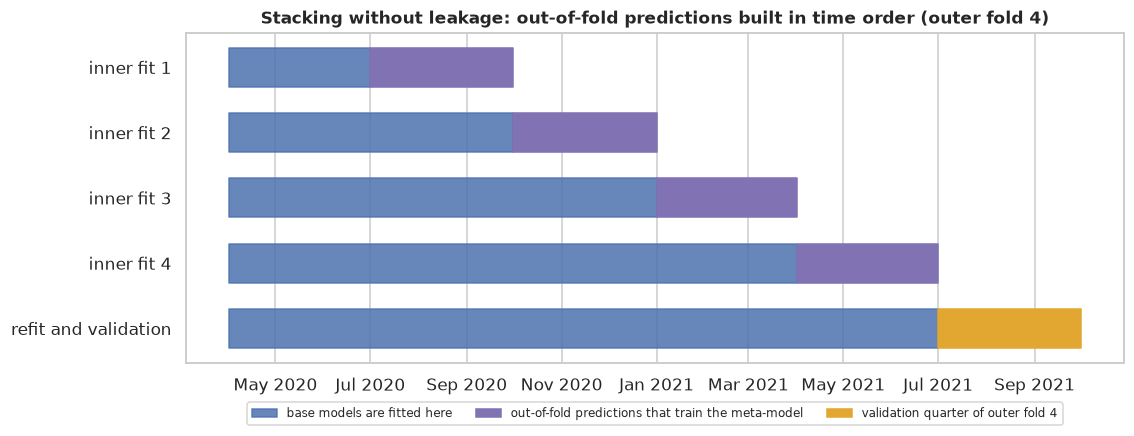

In [100]:
fig, ax = plt.subplots(figsize=(11, 3.9))
d2n = mdates.date2num
quarters = STACK_QUARTERS[4]
for i, (a, b) in enumerate(quarters):
    y0 = len(quarters) + 1 - i
    ax.broken_barh([(d2n(BURN_IN_END), d2n(a) - d2n(BURN_IN_END))], (y0 - 0.3, 0.6), color=C_NORMAL, alpha=0.85)
    ax.broken_barh([(d2n(a), d2n(b) - d2n(a))], (y0 - 0.3, 0.6), color=C_PURPLE)
f4 = FOLDS[3]
ax.broken_barh([(d2n(BURN_IN_END), d2n(f4["lo"]) - d2n(BURN_IN_END))], (0.7, 0.6), color=C_NORMAL, alpha=0.85)
ax.broken_barh([(d2n(f4["lo"]), d2n(f4["hi"]) - d2n(f4["lo"]))], (0.7, 0.6), color=C_ORANGE)
ax.set_yticks(list(range(len(quarters) + 1, 1, -1)) + [1])
ax.set_yticklabels([f"inner fit {i + 1}" for i in range(len(quarters))] + ["refit and validation"])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_NORMAL, alpha=0.85), plt.Rectangle((0, 0), 1, 1, color=C_PURPLE), plt.Rectangle((0, 0), 1, 1, color=C_ORANGE)],
          labels=["base models are fitted here", "out-of-fold predictions that train the meta-model", "validation quarter of outer fold 4"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
ax.set_title("Stacking without leakage: out-of-fold predictions built in time order (outer fold 4)")
savefig(fig, "05_3_stacking_design")

The Naive Bayes coefficient ranges from -0.001 to 0.023 across folds, compared with
0.56 to 0.66 for logistic regression and 0.31 to 0.47 for the tree. These are
regression coefficients on the logit inputs, not percentages or weights constrained to sum to one. Because the base predictions
are correlated, the coefficients should not be interpreted as independent measures of each model's importance.

The meta-training sets contain between 67,788 and 227,500 sessions. The chronological construction
keeps each base model's fitting rows earlier than the rows it predicts. Feature-set and configuration choices still use the
four development folds, so the reported stacking score has the model-selection optimism described in Section 6.4.

### 5.4 Does each ensemble improve on the individual models?

The table gives paired PR-AUC differences, fold by fold. For stacking, the references are its three base models. For the
forest and boosting, the standalone decision tree is a reference single-tree classifier; it is not one of their fitted trees,
and their tree settings differ. These comparisons measure predictive gains, rather than isolating variance or bias reduction.

In [101]:
FINAL = {"Logistic regression": CHOSEN["Logistic regression"], "Naive Bayes": CHOSEN["Naive Bayes"], "Decision tree": CHOSEN["Decision tree"],
         "Random forest": CHOSEN["Random forest"], "Gradient boosting": CHOSEN["Gradient boosting"], "Stacking": STACK_LABEL}
table = metric_table(list(FINAL.values()))
fold_cols = [c for c in table.columns if c != "mean"]
pairs = [("Random forest", "Decision tree"), ("Gradient boosting", "Decision tree"), ("Gradient boosting", "Random forest"),
         ("Stacking", "Logistic regression"), ("Stacking", "Naive Bayes"), ("Stacking", "Decision tree")]
rows, ensemble_diffs = [], {}
for ensemble, constituent in pairs:
    d, s = paired(table.loc[FINAL[ensemble], fold_cols], table.loc[FINAL[constituent], fold_cols])
    ensemble_diffs[f"{ensemble} − {constituent}"] = d
    rows.append({"comparison": f"{ensemble} − {constituent}", "PR-AUC difference (mean)": s["mean difference"], "folds won": s["folds won"],
                 "smallest fold": s["smallest difference"], "largest fold": s["largest difference"]})
display(pd.DataFrame(rows).set_index("comparison").style.format({"PR-AUC difference (mean)": "{:+.4f}", "smallest fold": "{:+.4f}", "largest fold": "{:+.4f}"}))

,PR-AUC difference (mean),folds won,smallest fold,largest fold
comparison,,,,
Random forest − Decision tree,+0.0250,4 of 4,+0.0221,+0.0289
Gradient boosting − Decision tree,+0.0284,4 of 4,+0.0252,+0.0315
Gradient boosting − Random forest,+0.0034,3 of 4,-0.0015,+0.0089
Stacking − Logistic regression,+0.0180,4 of 4,+0.0122,+0.0211
Stacking − Naive Bayes,+0.0854,4 of 4,+0.0636,+0.1043
Stacking − Decision tree,+0.0131,4 of 4,+0.0116,+0.0158


The forest and boosting improve on the standalone decision tree in every fold, with mean PR-AUC gains of
+0.025 and +0.028. These results support using ensembles here, although
the differences do not separately prove how much comes from averaging, sequential fitting or the different tree settings.

Stacking improves on logistic regression by +0.018, on the tree by +0.013,
and on Naive Bayes by +0.085, averaged over the folds. Its mean PR-AUC is 0.610, below both tree ensembles.
Gradient boosting differs from the forest by +0.0034 on average, within our practical tolerance.

In [102]:
log_decision("5", "Ensembles",
             "Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.",
             "One ensemble per principle (variance reduction, bias reduction, model combination); stacking is compared with its base models and the tree ensembles with the standalone tree reference (Section 5.4).")
log_decision("5", "Temporal stacking",
             "Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.",
             "Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.")
log_decision("5", "Boosting without early stopping",
             "Fixed number of iterations; no internal early stopping.",
             "early_stopping=False in both factories; the runner checks that every boosting fit uses its specified number of iterations.")

---
## 6. Comparison and conclusions

### 6.1 All models under the Task 2 protocol

The table puts the two baselines and the six models side by side with the aggregation rules of Task 2 (Section 8): the unweighted mean PR-AUC ranks the
models, and the weighted mean, the standard deviation across folds, the worst fold and the trend describe how stable the result is. The columns `gain over B1` and `folds won vs B1`
compare each model with the baseline B1 fold by fold; the final column reports runtime.

In [103]:
NAMES = {BASELINES[0]: "B0 no skill", BASELINES[1]: "B1 post failure rate (7 days)",
         **{label: f"{name} ({label})" if name != "Stacking" else label for name, label in FINAL.items()}}
ALL_MODELS = BASELINES + list(FINAL.values())
weights = fold_table["validation sessions"]
all_metrics = pd.concat(METRICS)
pr_all = metric_table(ALL_MODELS)
fold_cols = [c for c in pr_all.columns if c != "mean"]

rows = []
for label in ALL_MODELS:
    s = summarise_folds(pr_all.loc[label, fold_cols].to_numpy(), weights.to_numpy())
    other = all_metrics[all_metrics["model"] == label][["lift", "ROC-AUC", "Brier", "log-loss", "seconds"]].mean()
    d, ps = paired(pr_all.loc[label, fold_cols], pr_all.loc[BASELINES[1], fold_cols])
    rows.append({"model": NAMES[label], "PR-AUC mean": s["mean (unweighted)"], "weighted": s["mean (weighted by validation sessions)"],
                 "std": s["std across folds"], "worst fold": s["worst fold"], "trend": s["trend per fold"],
                 "lift": other["lift"], "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"],
                 "gain over B1": ps["mean difference"], "folds won vs B1": ps["folds won"], "seconds per fold": other["seconds"]})
comparison = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False)
display(comparison.style.format({"PR-AUC mean": "{:.3f}", "weighted": "{:.3f}", "std": "{:.3f}", "worst fold": "{:.3f}", "trend": "{:+.3f}", "lift": "{:.2f}",
                                 "ROC-AUC": "{:.3f}", "Brier": "{:.3f}", "log-loss": "{:.3f}", "gain over B1": "{:+.3f}", "seconds per fold": "{:.1f}"}, na_rep="—"))
print("PR-AUC by fold:")
display(pr_all.rename(index=NAMES).loc[comparison.index].style.format("{:.3f}"))

,PR-AUC mean,weighted,std,worst fold,trend,lift,ROC-AUC,Brier,log-loss,gain over B1,folds won vs B1,seconds per fold
model,,,,,,,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.626,0.632,0.038,0.575,+0.020,3.50,0.836,0.102,0.337,+0.115,4 of 4,3.0
Random forest (RF leaf=50),0.622,0.629,0.042,0.567,+0.022,3.48,0.835,0.102,0.339,+0.112,4 of 4,12.1
Stacking (LR + NB + DT),0.610,0.617,0.041,0.556,+0.022,3.41,0.831,0.104,0.343,+0.100,4 of 4,13.5
Decision tree (DT depth=8),0.597,0.604,0.041,0.544,+0.023,3.34,0.824,0.105,0.347,+0.087,4 of 4,2.5
Logistic regression (LR C=0.01),0.593,0.599,0.042,0.534,+0.020,3.31,0.825,0.106,0.350,+0.082,4 of 4,2.3
Naive Bayes (NB),0.525,0.531,0.037,0.472,+0.012,2.93,0.814,0.172,0.839,+0.015,3 of 4,0.7
B1 post failure rate (7 days),0.511,0.516,0.042,0.456,+0.021,2.85,0.772,0.118,0.385,+0.000,0 of 4,—
B0 no skill,0.181,0.185,0.021,0.162,+0.014,1.01,0.504,0.148,0.472,-0.329,0 of 4,—


PR-AUC by fold:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.618,0.575,0.650,0.660,0.626
Random forest (RF leaf=50),0.615,0.567,0.646,0.662,0.622
Stacking (LR + NB + DT),0.602,0.556,0.636,0.648,0.610
Decision tree (DT depth=8),0.586,0.544,0.624,0.635,0.597
Logistic regression (LR C=0.01),0.590,0.534,0.615,0.630,0.593
Naive Bayes (NB),0.539,0.472,0.531,0.559,0.525
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511
B0 no skill,0.172,0.162,0.181,0.210,0.181


The ranking by mean PR-AUC is: Gradient boosting 0.626; Random forest 0.622; Stacking 0.610; Decision tree 0.597; Logistic regression 0.593; Naive Bayes 0.525; B1 post failure rate 0.511; B0 no skill 0.181.
The mean difference between gradient boosting and the forest is +0.0034, inside the practical tolerance.
Naive Bayes beats B1 in 3 of 4 folds; the other learned models beat it in every fold.

Gradient boosting improves on B1 by +0.119, +0.119, +0.103, +0.120 across the four quarters,
with a mean gain of +0.115. Its mean lift is 3.50, against 2.85 for B1.
The models show a broadly similar pattern of performance across quarters. Similar fold standard deviations do not establish
equal stability, and the shared trends do not isolate the effects of prevalence, longer training windows and other changes
in the data. The weighted means are also reported, so the ranking can be checked against differences in fold sizes.

For probabilities, gradient boosting has a Brier score of 0.102 and log-loss 0.337; the forest has
0.102 and 0.339. Naive Bayes has worse probability losses than the constant prior (Section 4.3).
The final column reports fitting and prediction time on this machine, which varies between runs. Stacking repeats the base
fits for its inner quarters; its extra cost has not produced a gain over the tree ensembles here.

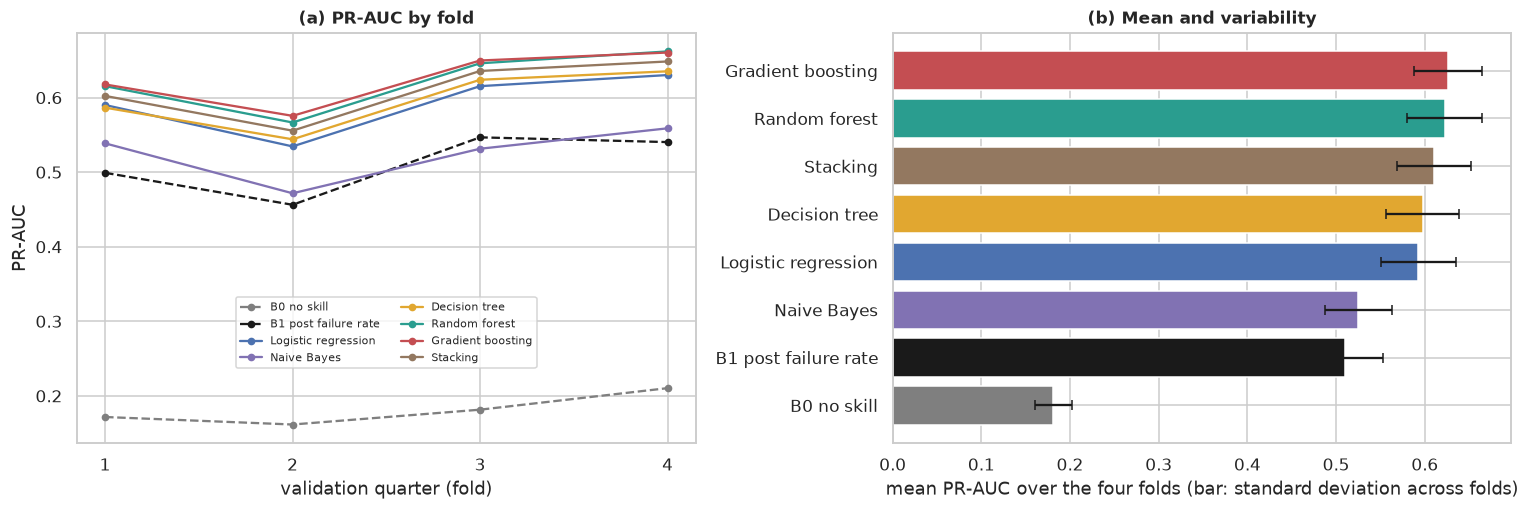

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {BASELINES[0]: C_GREY, BASELINES[1]: "k", FINAL["Logistic regression"]: C_NORMAL, FINAL["Naive Bayes"]: C_PURPLE, FINAL["Decision tree"]: C_ORANGE,
           FINAL["Random forest"]: C_GREEN, FINAL["Gradient boosting"]: C_ABN, FINAL["Stacking"]: "#937860"}
for label in ALL_MODELS:
    axes[0].plot(range(1, 5), pr_all.loc[label, fold_cols], marker="o", ms=4, color=palette[label], ls="--" if label in BASELINES else "-", label=NAMES[label].split(" (")[0])
axes[0].set_xticks(range(1, 5)); axes[0].set_xlabel("validation quarter (fold)"); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) PR-AUC by fold"); axes[0].legend(fontsize=7, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.17))
order = comparison.index[::-1]
inverse = {v: k for k, v in NAMES.items()}
axes[1].barh([n.split(" (")[0] for n in order], comparison.loc[order, "PR-AUC mean"], xerr=comparison.loc[order, "std"], color=[palette[inverse[n]] for n in order], capsize=3)
axes[1].set_xlabel("mean PR-AUC over the four folds (bar: standard deviation across folds)"); axes[1].set_title("(b) Mean and variability")
fig.tight_layout()
savefig(fig, "06_1_model_comparison")

Panel (a) shows how the ranking changes across quarters. Panel (b) reports the mean and standard deviation across those
quarters. Its error bars describe temporal variation; they are not confidence intervals for model differences. The paired
comparisons in Section 5.4 and the baseline-comparison columns are more useful for assessing small gaps between models.

### 6.2 What the alerts would look like

The operational measures of Task 2 show what the ranking means for an operator who can review a fixed share of the sessions. The first table gives the
mean precision and recall over the folds at each alert budget, and the second the counts per 1,000 sessions for the model at the top of the ranking.

In [105]:
rows = []
for label in ALL_MODELS:
    sub = all_metrics[all_metrics["model"] == label]
    row = {"model": NAMES[label]}
    for q in ALERT_BUDGETS:
        row[f"precision @{q:.0%}"] = sub[f"precision @{q:.0%}"].mean()
        row[f"recall @{q:.0%}"] = sub[f"recall @{q:.0%}"].mean()
    rows.append(row)
operational = pd.DataFrame(rows).set_index("model").loc[comparison.index]
display(operational.style.format("{:.3f}"))

best_label = inverse[comparison.index[0]]
sub = all_metrics[all_metrics["model"] == best_label]
counts = pd.DataFrame({f"budget {q:.0%}": {"alerts per 1,000": sub[f"alerts per 1,000 @{q:.0%}"].mean(), "correct alerts per 1,000": sub[f"correct alerts per 1,000 @{q:.0%}"].mean(),
                                          "false alerts per 1,000": sub[f"false alerts per 1,000 @{q:.0%}"].mean(), "missed per 1,000": sub[f"missed per 1,000 @{q:.0%}"].mean()}
                       for q in ALERT_BUDGETS})
b1 = all_metrics[all_metrics["model"] == BASELINES[1]]
counts_b1 = pd.DataFrame({f"budget {q:.0%}": {"correct alerts per 1,000": b1[f"correct alerts per 1,000 @{q:.0%}"].mean(), "false alerts per 1,000": b1[f"false alerts per 1,000 @{q:.0%}"].mean(),
                                             "missed per 1,000": b1[f"missed per 1,000 @{q:.0%}"].mean()} for q in ALERT_BUDGETS})
print(f"Counts per 1,000 sessions, mean over the folds, for {NAMES[best_label]}:")
display(counts.style.format("{:.1f}"))
print("and for the baseline B1:")
display(counts_b1.style.format("{:.1f}"))

,precision @5%,recall @5%,precision @10%,recall @10%,precision @20%,recall @20%
model,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.880,0.246,0.724,0.404,0.528,0.586
Random forest (RF leaf=50),0.875,0.245,0.721,0.402,0.528,0.587
Stacking (LR + NB + DT),0.863,0.242,0.713,0.397,0.520,0.578
Decision tree (DT depth=8),0.862,0.241,0.710,0.395,0.515,0.573
Logistic regression (LR C=0.01),0.840,0.235,0.694,0.387,0.515,0.573
Naive Bayes (NB),0.701,0.196,0.614,0.343,0.491,0.547
B1 post failure rate (7 days),0.738,0.207,0.594,0.330,0.451,0.499
B0 no skill,0.182,0.051,0.182,0.101,0.180,0.200


Counts per 1,000 sessions, mean over the folds, for Gradient boosting (HGB depth=6, lr=0.1, 200 it):


,budget 5%,budget 10%,budget 20%
"alerts per 1,000",50.0,100.0,200.0
"correct alerts per 1,000",44.0,72.4,105.5
"false alerts per 1,000",6.0,27.6,94.5
"missed per 1,000",136.1,107.7,74.5


and for the baseline B1:


,budget 5%,budget 10%,budget 20%
"correct alerts per 1,000",36.9,59.4,90.2
"false alerts per 1,000",13.1,40.6,109.8
"missed per 1,000",143.2,120.7,89.9


At a 5% alert budget, precision is 88.0% and recall 24.6%: 44.0 correct alerts, 6.0 false alerts and 136.1 missed failures per 1,000 sessions.

At a 10% alert budget, precision is 72.4% and recall 40.4%: 72.4 correct alerts, 27.6 false alerts and 107.7 missed failures per 1,000 sessions.

At a 20% alert budget, precision is 52.8% and recall 58.6%: 105.5 correct alerts, 94.5 false alerts and 74.5 missed failures per 1,000 sessions.

For comparison, B1 at 5% gives precision 73.8%, recall 20.7%,
36.9 correct alerts and 13.1 false alerts per 1,000 sessions.
The learned model catches more failures at the same workload. Nevertheless, a 5% budget still leaves most failures unflagged.
The importance of post history suggests a limitation for failures without a recent warning pattern, but we have not measured
that subgroup separately and cannot conclude that such failures are impossible to predict.

### 6.3 Conclusions

* Post history is the largest contribution (+0.294 mean PR-AUC). User history adds +0.031, positive in every fold but smaller
  in later quarters. The pooled segment analysis shows most of this benefit for returning accounts. Tariff adds no practically
  relevant gain beyond the hour; context and weather alone give mean PR-AUC 0.290.
* We keep 27 features, dropping `post_id` and redundant `tariff_period`. The user-free alternative has 16 features and mean
  PR-AUC 0.599, and remains available if account histories cannot be used.
* Logistic regression (0.593) and the single tree (0.597) perform similarly. Naive Bayes has worse
  probability losses than the constant prior. The outlier-cap comparison supports retaining Task 1's preparation without caps.
* Gradient boosting (0.626) and random forest (0.622) outperform stacking (0.610). Their difference is
  +0.0034, inside the tolerance. Gradient boosting has the highest mean and is cheaper to refit on this machine.
* Gradient boosting gains +0.115 over B1 on average, with a gain in every fold. These remain development results: the feature set
  and hyperparameters were chosen using the same folds, and the final test is still reserved.
* At a 5% alert budget, 88.0% of the best model's alerts are correct, but recall is only 24.6%. Start-time information
  supports useful monitoring priorities, with a substantial number of missed failures at small alert budgets.

### 6.4 Limitations

* The feature set and the hyperparameters were chosen with the same four folds that we use to report results, so the scores are slightly optimistic. The unbiased estimate is the evaluation on the test period, which stays untouched until the final task.
* The ablation uses gradient boosting with fixed hyperparameters. The conclusions are for that family, although the redundancy of the tariff does not depend on it.
* With four dependent temporal folds, standard deviations and trends are rough guides; we do not use them to claim statistical significance (Task 2, Section 8).
* The alert budgets are assumptions and we did not choose a decision threshold, so the calibration of the probabilities of the best models still has to be checked before a cost-based cut-off is used.
* Instance-based and kernel-based classifiers were left out by design (Section 4.1).
* Naive Bayes retains all selected inputs to avoid importing Task 1's target-based reduced list into earlier folds. Correlated
  windows remain, so its independence assumption is still weak. The log-transform list is fixed by variable meaning; all learned
  preprocessing values are fitted within the relevant outer or inner training window.
* The tolerance of 0.005 is a practical choice. The session bootstrap does not account for dependence or estimate uncertainty in paired model differences (Section 3.3).
* Without `post_id` the model can score a new post from its station and district, but its history would be empty, and every post of the folds appears in training, so this case is not tested.
* We put the concurrency variable with the user history because it describes the account. That is our choice.

---
## 7. Saved files and decision log

The results are saved so that Task 4 can reuse the selected feature set, the selected hyperparameters and the fold-by-fold metrics without
repeating the experiments.

In [106]:
for (label, fold), p in PREDS.items():
    assert len(p) == fold_table.loc[fold, "validation sessions"], (label, fold)       # one prediction per validation session
assert set(SELECTED) <= set(features_all) and "post_id" not in SELECTED and "tariff_period" not in SELECTED
assert df["start_time"].max() < TEST_START                                              # the test period was never loaded

fold_metrics = pd.concat(METRICS).reset_index(drop=True)
fold_metrics.to_csv(OUT_DIR / "task3_fold_metrics.csv", index=False)
results = {
    "protocol": "prepared/task2_protocol.json (folds, metrics, alert budgets); test rows dropped right after reading",
    "tolerance": TOLERANCE,
    "ablation": {label: {"features": len(feats), "PR-AUC mean": float(pr.loc[label, "mean"]) if label in pr.index else float(pr_c.loc[label, "mean"])}
                 for label, feats in {**STEPS, **CHECKS}.items()},
    "selected_features": SELECTED,
    "features_without_user_history": NO_USER,
    "selected_configurations": {name: label for name, label in FINAL.items()},
    "comparison": comparison.reset_index().to_dict("records"),
    "linear_view": "capped" if LINEAR_CAP else "task1",
    "linear_view_comparison": LINEAR_VIEW_COMPARISON,
}
(OUT_DIR / "task3_results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task3_decision_log.csv", index=False)
print("Saved:", OUT_DIR / "task3_results.json", OUT_DIR / "task3_fold_metrics.csv", OUT_DIR / "task3_decision_log.csv", "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task3_results.json prepared/task3_fold_metrics.csv prepared/task3_decision_log.csv | figures in prepared/figures_task3


section,topic,decision,evidence
3,Ablation design,"Four nested sets S1 to S4 with one fixed, untuned gradient-boosting model; paired fold differences with a tolerance of 0.005.","Reference model handles categories, NaN and interactions; the tolerance is practical; the descriptive session bootstrap does not establish significance (Section 3.3)."
3,Selected feature set,"27 features: S4 without `post_id` and `tariff_period` (calendar, station and district, weather, post history, user history, concurrency).","Removing post_id changed mean PR-AUC by +0.0107, with gains in 4 of 4 folds; tariff removal is inside the tolerance. Post history adds +0.294 and user history +0.031 on average (Sections 3.2 and 3.4)."
3,No new features,No feature is added to the 29 start-time features of the Task 2 protocol.,The start-time columns were chosen in Task 1 (Sections 9 and 12); the post history alone carries most of the signal (Section 3.2); a new history feature would need its own leakage check.
4,Individual models,"Logistic regression (linear), Categorical Naive Bayes (probabilistic) and a CART decision tree. k-NN and kernel SVM are left out.","Mixed, skewed inputs and 270k training rows make k-NN and an RBF SVM too slow without subsampling that discards the history; the other three cover three principles."
4,Hyperparameters of the individual models,Highest mean PR-AUC; a simpler configuration within 0.005 is kept. Logistic regression: C = 0.01 (stronger penalty); tree: depth 8.,"The practical tolerance is 0.005, read with paired fold differences; it is not a significance threshold (Section 3.3). Grids are in Section 4.3."
4,Outlier caps,"No caps: the linear view keeps the Task 1 preparation (log transform, no capping).","Caps minus Task 1 preparation: mean PR-AUC -0.0001, 1 of 4 folds won, tolerance 0.005 (Section 4.4)."
4,Category codes for trees,The decision tree and the random forest keep the Task 1 ordinal codes for station and district; gradient boosting reads them as categories.,"Only 13 stations and 3 districts remain after post_id is dropped, and two threshold splits isolate any single code, so the arbitrary order blocks no partition (MINDD-05 advises against imposing an order on unordered categories); gradient boosting has native categorical support."
5,Ensembles,"Random forest (bagging), gradient boosting (boosting) and stacking of LR + NB + DT with a logistic-regression meta-model; no voting.","One ensemble per principle (variance reduction, bias reduction, model combination); stacking is compared with its base models and the tree ensembles with the standalone tree reference (Section 5.4)."
5,Temporal stacking,Meta-training predictions come from inner expanding quarters of each fold's training window; the first quarter is training-only; sessions with a label unknown at the fold start are removed.,Assertions in the code check that every inner model is fitted on sessions that ended before the predicted quarter; a random inner CV would let later sessions shape earlier predictions.
5,Boosting without early stopping,Fixed number of iterations; no internal early stopping.,early_stopping=False in both factories; the runner checks that every boosting fit uses its specified number of iterations.


# Part 4 · Task 4: Optimising the selected models, choosing the threshold and the final evaluation

In [107]:
# each part starts from an empty namespace, as when the task notebooks ran on their own
%reset -f

## TP1 · Task 4: Optimising the selected models, choosing the threshold and the final evaluation
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 4 closes the modelling work. We tune the hyperparameters of the most promising models of Task 3, compare each tuned model with
its Task 3 configuration, choose a decision threshold for the final model from validation predictions, check its calibration, and
then evaluate the final model once on the test period that every earlier task left untouched. The notebook ends by looking at which
groups of information the final model relies on.

### How to read this notebook

| # | Section | Requirement of the Task 4 brief |
|---|---------|---------------------------------|
| 1 | Setup and inputs | — |
| 2 | Data, folds and the Task 3 reference | the protocol of Task 2, unchanged, and a check that Task 3 is reproduced |
| 3 | Models chosen for optimisation | two or three promising models, justified |
| 4 | Hyperparameter search | explicit search space, procedure, temporal order, PR-AUC objective, selected configuration |
| 5 | Optimised versus initial, and the final model | is the improvement meaningful and stable? |
| 6 | Decision threshold | one criterion on validation predictions; 0.50 against the selected cut-off; operational consequences |
| 7 | Calibration check | is calibration needed for the chosen use? |
| 8 | Freezing the final choices | model, features and cut-off written to file before the test |
| 9 | Final evaluation on the test period | one evaluation, threshold applied unchanged |
| 10 | Interpretation of the final model | which feature groups and variables drive it, with limitations |
| 11 | Conclusions and limitations | — |
| 12 | Saved files and decision log | — |
| 13 | Final comparison and model description | candidate, baseline and final models in one table; final preprocessing, features, hyperparameters and threshold |

The notebook reads what Tasks 2 and 3 saved: the evaluation protocol (`prepared/task2_protocol.json`), the feature groups
(`prepared/feature_groups.json`), the 27 selected features and the Task 3 configurations (`prepared/task3_results.json`), and the
Task 3 fold metrics (`prepared/task3_fold_metrics.csv`). Sections 1 to 8 use only the development period (April 2020 to September
2021): the test rows are dropped right after the file is read. The test period (from 2021-10-01) is read again only in Section 9,
after the final model, its features and its cut-off have been written to `prepared/task4_frozen.json`.

---
## 1. Setup and inputs

In [108]:
import json
import time
import warnings
from datetime import datetime
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task4"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

# The evaluation comes from the Task 2 files and the feature set from Task 3, so the three tasks cannot drift apart.
PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
TASK3 = json.loads((OUT_DIR / "task3_results.json").read_text())
BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
GROUPS = FEATURE_GROUPS["groups"]
TOLERANCE = TASK3["tolerance"]                 # practical tolerance of Task 3 (Section 3.3) for small PR-AUC differences
SELECTED = TASK3["selected_features"]          # the 27 features selected by the Task 3 ablation
TARGET_ALERT_RATE = 0.10                       # threshold criterion of Section 6
assert len(SELECTED) == 27 and "post_id" not in SELECTED and "tariff_period" not in SELECTED

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 12)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


print(f"Task 3 feature set: {len(SELECTED)} features | tolerance {TOLERANCE} | test period from {TEST_START.date()}")

Task 3 feature set: 27 features | tolerance 0.005 | test period from 2021-10-01


---
## 2. Data, folds and the Task 3 reference

We read only the 27 selected features and the three columns that define the target and the fold boundaries (`Start Time`, `End Time`,
`end_cause`). The function below keeps one period right after the start time is parsed, before the target or any feature is built.
Sections 2 to 8 call it for the development period only, so the test rows are counted and dropped at once. Section 9 calls it a second
time for the test period, after the final choices are frozen.

In [109]:
RENAME = {   # same short names as in Tasks 1 to 3
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}     # features built from one column (Task 1, Section 12)


def load_sessions(period):
    """Read the course file and keep one period, right after the start time is parsed and before any label or feature exists.
    "development" = from the end of the burn-in to the test start; "test" = from the test start (Section 9 only)."""
    needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in SELECTED} | {"Start Time", "End Time", "end_cause"}
    frame = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
    frame["start_time"] = pd.to_datetime(frame["start_time"], format="%Y-%m-%d %H:%M:%S")
    counts = {"file": len(frame), "burn-in": int((frame["start_time"] < BURN_IN_END).sum()),
              "test": int((frame["start_time"] >= TEST_START).sum())}
    if period == "development":
        keep = (frame["start_time"] >= BURN_IN_END) & (frame["start_time"] < TEST_START)
    elif period == "test":
        keep = frame["start_time"] >= TEST_START
    else:
        raise ValueError(period)
    frame = frame[keep].reset_index(drop=True)            # the other period goes here, before any label or feature exists

    for col in ("location", "district", "end_cause"):
        frame[col] = frame[col].str.strip()
    frame["end_time"] = pd.to_datetime(frame["end_time"], format="%Y-%m-%d %H:%M:%S")
    frame["hour"] = frame["start_time"].dt.hour.astype("int8")
    frame["dow"] = frame["start_time"].dt.dayofweek.astype("int8")
    frame["rain_flag"] = (frame["precipitation"] > 0).astype("int8")
    frame[TARGET] = (~frame["end_cause"].isin(NORMAL_CAUSES)).astype("int8")
    return frame, counts


df, counts = load_sessions("development")
print(f"File: {counts['file']:,} sessions | burn-in removed: {counts['burn-in']:,} | test removed: {counts['test']:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), "
      f"abnormal share {df[TARGET].mean():.2%}")
assert df["start_time"].max() < TEST_START and len(df) == 346_979

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%


### 2.1 The four temporal folds

The folds are rebuilt from the boundaries stored in the Task 2 protocol, with the same purge rule and the same assertions as in Task 3.
Fold *k* trains on every labelled development session that started and ended before its validation quarter, and validates on that quarter.

In [110]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    assert tr["start_time"].min() >= BURN_IN_END and tr["end_time"].max() < f["lo"]
    assert va["start_time"].min() >= f["lo"] and va["start_time"].max() < f["hi"]
    assert np.intersect1d(f["train"], f["valid"]).size == 0
for a, b in zip(FOLDS[:-1], FOLDS[1:]):
    assert a["hi"] == b["lo"] and np.isin(a["train"], b["train"]).all()
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]      # same folds as Task 2
assert FOLDS[-1]["hi"] == TEST_START
print("The four folds match the Task 2 protocol and pass the temporal integrity checks.")

fold_table = pd.DataFrame([{"fold": f["fold"], "validation quarter": f"{f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()}",
                            "train sessions": len(f["train"]), "validation sessions": len(f["valid"]),
                            "validation abnormal share": df.loc[f["valid"], TARGET].mean()} for f in FOLDS]).set_index("fold")
display(fold_table.style.format({"train sessions": "{:,.0f}", "validation sessions": "{:,.0f}", "validation abnormal share": "{:.1%}"}))

The four folds match the Task 2 protocol and pass the temporal integrity checks.


,validation quarter,train sessions,validation sessions,validation abnormal share
fold,,,,
1,2020-10-01 to 2020-12-31,"111,470","60,364",16.8%
2,2021-01-01 to 2021-03-31,"171,832","41,797",15.8%
3,2021-04-01 to 2021-06-30,"213,641","57,542",18.2%
4,2021-07-01 to 2021-09-30,"271,182","75,769",21.1%


### 2.2 Metrics, the cross-validation runner and the operating point

The metric functions and the runner `cv_run` are those of Task 3, so the numbers of the two notebooks are comparable. `cv_run` builds a
fresh pipeline for each fold, fits it on that fold's training rows only and keeps the predictions of the validation quarter, which the
threshold (Section 6) needs. We add one function, `operating_point`, which turns scores into alerts with a fixed cut-off and returns the
measures that the brief asks for: precision, recall, F1, alert rate, and correct, false and missed alerts per 1,000 sessions. When a
cut-off flags no session, precision and F1 are undefined and shown as "—".

In [111]:
def alert_metrics(y, score, budget, rng):
    """Flag the top `budget` share of sessions by score (ties broken at random). Return the operational measures."""
    n = len(y)
    k = int(round(budget * n))
    order = np.lexsort((rng.random(n), -score))          # sort by -score; ties are shuffled
    flagged = np.zeros(n, dtype=bool)
    flagged[order[:k]] = True
    tp = int((y[flagged] == 1).sum())
    return {"alerts per 1,000": 1000 * k / n,
            "correct alerts per 1,000": 1000 * tp / n,
            "false alerts per 1,000": 1000 * (k - tp) / n,
            "missed per 1,000": 1000 * (int(y.sum()) - tp) / n,
            "precision": tp / k, "recall": tp / y.sum()}


def evaluate_scores(y, score, probability=None, rng=None):
    """All Task 2 metrics for one set of predictions. `probability` (optional) is used for Brier score and log-loss."""
    rng = rng or np.random.default_rng(SEED)
    y = np.asarray(y)
    prevalence = y.mean()
    out = {"abnormal share": prevalence, "PR-AUC": average_precision_score(y, score)}
    out["lift"] = out["PR-AUC"] / prevalence
    out["ROC-AUC"] = roc_auc_score(y, score)
    if probability is not None:
        out["Brier"] = brier_score_loss(y, probability)
        out["log-loss"] = log_loss(y, np.clip(probability, 1e-6, 1 - 1e-6))
    for q in ALERT_BUDGETS:
        for name, value in alert_metrics(y, score, q, rng).items():
            out[f"{name} @{q:.0%}"] = value
    return out


def summarise_folds(values, weights):
    """Aggregate one metric over the temporal folds (values and weights are indexed by fold number)."""
    v = pd.Series(values, dtype=float)
    return pd.Series({"mean (unweighted)": v.mean(),
                      "mean (weighted by validation sessions)": np.average(v, weights=weights),
                      "std across folds": v.std(ddof=1),
                      "worst fold": v.min(), "best fold": v.max(),
                      "trend per fold": np.polyfit(np.arange(1, len(v) + 1), v.to_numpy(), 1)[0]})


def paired(model, competitor):
    """Fold-by-fold difference `model - competitor` of one metric (Series indexed by fold) and its summary."""
    diff = pd.Series(model, dtype=float) - pd.Series(competitor, dtype=float)
    summary = {"mean difference": diff.mean(), "std of differences": diff.std(ddof=1), "folds won": f"{int((diff > 0).sum())} of {len(diff)}",
               "smallest difference": diff.min(), "largest difference": diff.max()}
    return diff, pd.Series(summary)


METRICS, PREDS = [], {}       # per-fold metrics and validation predictions of every experiment, keyed by experiment label


def cv_run(label, make_model, features):
    """Run one experiment under the Task 2 protocol: a fresh pipeline per fold, fitted on that fold's training rows only."""
    rows = []
    for f in FOLDS:
        tr, va = df.loc[f["train"]], df.loc[f["valid"]]
        started = time.time()
        model = make_model(features).fit(tr[features], tr[TARGET])
        if isinstance(model.named_steps["clf"], HistGradientBoostingClassifier):
            fitted = model.named_steps["clf"]
            assert not fitted.do_early_stopping_ and fitted.n_iter_ == fitted.max_iter
        p = model.predict_proba(va[features])[:, 1]
        seconds = time.time() - started
        PREDS[(label, f["fold"])] = p
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(va), "seconds": seconds,
                     **evaluate_scores(va[TARGET].to_numpy(), p, p, rng=np.random.default_rng(SEED))})
    result = pd.DataFrame(rows)
    METRICS.append(result)
    return result


def metric_table(labels, metric="PR-AUC"):
    """Fold-by-fold table of one metric for several experiments, with the mean over folds."""
    all_metrics = pd.concat(METRICS)
    t = all_metrics[all_metrics["model"].isin(labels)].pivot(index="model", columns="fold", values=metric).loc[labels]
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
    return t


def operating_point(y, score, cut_off):
    """Alerts at a fixed cut-off (a session is flagged if score >= cut_off). Precision and F1 are NaN when nothing is flagged."""
    y, flagged = np.asarray(y), np.asarray(score) >= cut_off
    n, k = len(y), int(flagged.sum())
    tp = int((y[flagged] == 1).sum())
    precision = tp / k if k else np.nan
    recall = tp / y.sum()
    f1 = np.nan if not k else (0.0 if tp == 0 else 2 * precision * recall / (precision + recall))
    return {"cut-off": cut_off, "precision": precision, "recall": recall, "F1": f1, "alert rate": k / n,
            "correct per 1,000": 1000 * tp / n, "false per 1,000": 1000 * (k - tp) / n, "missed per 1,000": 1000 * (int(y.sum()) - tp) / n}


OP_FORMAT = {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}",
             "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}

### 2.3 Baselines and the Task 3 configurations

B0 (random scores, with the training prior as probability) and B1 (the 7-day failure rate of the post) are computed again with the Task 3
definitions. We then rerun the three Task 3 configurations that Section 3 selects for optimisation and check that every fold gives the
PR-AUC saved by Task 3. If both notebooks agree to the third decimal, any later difference comes from the hyperparameters and not from
the code or the environment.

In [112]:
rng = np.random.default_rng(SEED)
rows = []
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    y = va[TARGET].to_numpy()
    prior = tr[TARGET].mean()                                            # learned inside the training fold
    s_b1 = va["post_previous_abnormal_rate_7D"].to_numpy()
    for label, score, prob in [("B0 no skill", rng.random(len(y)), np.full(len(y), prior)), ("B1 post failure rate (7 days)", s_b1, s_b1)]:
        PREDS[(label, f["fold"])] = score
        rows.append({"model": label, "fold": f["fold"], "validation sessions": len(y), **evaluate_scores(y, score, prob, rng=rng)})
METRICS.append(pd.DataFrame(rows))
BASELINES = ["B0 no skill", "B1 post failure rate (7 days)"]
b = metric_table(BASELINES)
display(b.style.format("{:.3f}"))
print(f"B0 mean PR-AUC = {b.loc[BASELINES[0], 'mean']:.3f}, B1 mean PR-AUC = {b.loc[BASELINES[1], 'mean']:.3f} (Task 3 reported 0.181 and 0.511)")
assert abs(b.loc[BASELINES[0], "mean"] - 0.181) < 0.001 and abs(b.loc[BASELINES[1], "mean"] - 0.511) < 0.001

,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
B0 no skill,0.172,0.162,0.181,0.210,0.181
B1 post failure rate (7 days),0.499,0.456,0.547,0.540,0.511


B0 mean PR-AUC = 0.181, B1 mean PR-AUC = 0.511 (Task 3 reported 0.181 and 0.511)


In [113]:
def tree_view(features):
    """Preprocessing of tree-based models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


# Each factory returns (label, factory, hyperparameters). The label lists every value, so a configuration is never ambiguous.
def make_boosting(max_depth, learning_rate, max_iter, min_samples_leaf):
    params = {"max_depth": max_depth, "learning_rate": learning_rate, "max_iter": max_iter, "min_samples_leaf": min_samples_leaf}

    def factory(features):
        cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
        return Pipeline([("prep", tree_view(features)),
                         ("clf", HistGradientBoostingClassifier(**params, categorical_features=cat or None, early_stopping=False, random_state=SEED))])
    return f"HGB depth={max_depth}, lr={learning_rate}, {max_iter} it, leaf={min_samples_leaf}", factory, params


def make_forest(min_samples_leaf, max_features):
    params = {"min_samples_leaf": min_samples_leaf, "max_features": max_features}

    def factory(features):
        return Pipeline([("prep", tree_view(features)),
                         ("clf", RandomForestClassifier(n_estimators=200, **params, n_jobs=-1, random_state=SEED))])
    return f"RF leaf={min_samples_leaf}, features={max_features}", factory, params


def make_tree(max_depth, min_samples_leaf, criterion):
    params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "criterion": criterion}

    def factory(features):
        return Pipeline([("prep", tree_view(features)), ("clf", DecisionTreeClassifier(**params, random_state=SEED))])
    return f"DT depth={max_depth}, leaf={min_samples_leaf}, {criterion}", factory, params


MAKERS = {"Gradient boosting": make_boosting, "Random forest": make_forest, "Decision tree": make_tree}


def select_simplest(labels):
    """Highest mean PR-AUC; if a simpler configuration (earlier in `labels`) is within TOLERANCE of it, keep the simplest such one."""
    means = metric_table(labels)["mean"]
    best = means.max()
    return next(label for label in labels if means[label] >= best - TOLERANCE)


def config_table(labels, chosen):
    """Per-fold PR-AUC and the mean of the other metrics for a grid of configurations, with the chosen one marked."""
    t = metric_table(labels)
    all_metrics = pd.concat(METRICS)
    other = all_metrics[all_metrics["model"].isin(labels)].groupby("model")[["ROC-AUC", "Brier", "log-loss"]].mean().loc[labels]
    t = t.join(other)
    t["chosen"] = ["yes" if label == chosen else "" for label in labels]
    return t

In [114]:
# The Task 3 configurations, written with the Task 4 factories (Task 3 fixed 100 sessions per leaf for boosting and the tree,
# and sqrt(27) = 5 features per split for the forest).
INITIAL_PARAMS = {"Gradient boosting": dict(max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100),
                  "Random forest": dict(min_samples_leaf=50, max_features="sqrt"),
                  "Decision tree": dict(max_depth=8, min_samples_leaf=100, criterion="gini")}
TASK3_LABELS = {"Gradient boosting": "HGB depth=6, lr=0.1, 200 it", "Random forest": "RF leaf=50", "Decision tree": "DT depth=8"}
assert all(TASK3["selected_configurations"][name] == label for name, label in TASK3_LABELS.items())

task3_folds = pd.read_csv(OUT_DIR / "task3_fold_metrics.csv")
INITIAL, FACTORY, PARAMS = {}, {}, {}
rows = []
t0 = time.time()
for name, params in INITIAL_PARAMS.items():
    label, factory, params = MAKERS[name](**params)
    INITIAL[name], FACTORY[label], PARAMS[label] = label, factory, params
    mine = cv_run(label, factory, SELECTED).set_index("fold")["PR-AUC"]
    theirs = task3_folds[task3_folds["model"] == TASK3_LABELS[name]].set_index("fold")["PR-AUC"]
    for fold in mine.index:
        rows.append({"model": name, "configuration": label, "fold": fold, "Task 3 PR-AUC": theirs[fold], "Task 4 PR-AUC": mine[fold],
                     "difference": mine[fold] - theirs[fold]})
reproduction = pd.DataFrame(rows)
print(f"three Task 3 configurations x four folds fitted in {time.time() - t0:.0f} s")
display(reproduction.pivot(index="model", columns="fold", values="Task 4 PR-AUC").rename(columns=lambda c: f"fold {c}").style.format("{:.4f}"))
print(f"largest absolute difference from the Task 3 file: {reproduction['difference'].abs().max():.6f}")
assert (reproduction["difference"].abs() < 0.001).all()

three Task 3 configurations x four folds fitted in 74 s


fold,fold 1,fold 2,fold 3,fold 4
model,,,,
Decision tree,0.5865,0.5440,0.6239,0.6352
Gradient boosting,0.6176,0.5755,0.6497,0.6604
Random forest,0.6154,0.5666,0.6460,0.6619


largest absolute difference from the Task 3 file: 0.000000


The four folds are the ones of the Task 2 protocol: 111,470 to 271,182 training sessions and validation quarters with an abnormal share
between 15.8% and 21.1%. The two baselines give the same mean PR-AUC as in Task 3, 0.181 for B0 and 0.511 for B1, fold by fold.

The three Task 3 configurations that we optimise give back the PR-AUC saved by Task 3 in every fold. The largest absolute difference is
0.0001, well below the third decimal and far below the tolerance of 0.005. The code and the environment therefore reproduce Task 3, and any
difference in the searches below comes from the hyperparameters.

---
## 3. Models chosen for optimisation

The brief asks us to optimise two or three of the most promising models. The table below repeats the Task 3 comparison of the six models
(unweighted mean PR-AUC over the four folds, its standard deviation and worst fold, and the fitting time per fold).

In [115]:
CHOICE = {"Gradient boosting": ("boosting", "best mean PR-AUC of Task 3 and cheap to refit"),
          "Random forest": ("bagging with random feature subsets", "0.003 behind boosting, inside the tolerance, from a different ensemble principle"),
          "Decision tree": ("single tree", "best individual model; its complexity controls are the ones MINDD-05 says to choose on validation data")}
rows = []
for record in TASK3["comparison"]:
    name = record["model"].split(" (")[0]
    if name.startswith("B"):
        continue
    rows.append({"model": record["model"], "PR-AUC mean": record["PR-AUC mean"], "std": record["std"], "worst fold": record["worst fold"],
                 "ROC-AUC": record["ROC-AUC"], "Brier": record["Brier"], "seconds per fold": record["seconds per fold"],
                 "chosen for optimisation": "yes" if name in CHOICE else ""})
choice_table = pd.DataFrame(rows).set_index("model")
display(choice_table.style.format({"PR-AUC mean": "{:.3f}", "std": "{:.3f}", "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.3f}",
                                   "seconds per fold": "{:.1f}"}))

SELECTED_MODELS = [{"name": name, "principle": principle, "initial_configuration": INITIAL[name],
                    "reason": f"Task 3 mean PR-AUC {choice_table.loc[f'{name} ({TASK3_LABELS[name]})', 'PR-AUC mean']:.3f}; {reason}"}
                   for name, (principle, reason) in CHOICE.items()]
display(pd.DataFrame(SELECTED_MODELS).set_index("name"))

,PR-AUC mean,std,worst fold,ROC-AUC,Brier,seconds per fold,chosen for optimisation
model,,,,,,,
"Gradient boosting (HGB depth=6, lr=0.1, 200 it)",0.626,0.038,0.575,0.836,0.102,3.0,yes
Random forest (RF leaf=50),0.622,0.042,0.567,0.835,0.102,12.1,yes
Stacking (LR + NB + DT),0.610,0.041,0.556,0.831,0.104,13.5,
Decision tree (DT depth=8),0.597,0.041,0.544,0.824,0.105,2.5,yes
Logistic regression (LR C=0.01),0.593,0.042,0.534,0.825,0.106,2.3,
Naive Bayes (NB),0.525,0.037,0.472,0.814,0.172,0.7,


,principle,initial_configuration,reason
name,,,
Gradient boosting,boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100",Task 3 mean PR-AUC 0.626; best mean PR-AUC of Task 3 and cheap to refit
Random forest,bagging with random feature subsets,"RF leaf=50, features=sqrt","Task 3 mean PR-AUC 0.622; 0.003 behind boosting, inside the tolerance, from a different ensemble principle"
Decision tree,single tree,"DT depth=8, leaf=100, gini",Task 3 mean PR-AUC 0.597; best individual model; its complexity controls are the ones MINDD-05 says to choose on validation data


We optimise gradient boosting, the random forest and the decision tree. They are the two best ensembles and the best individual model of
Task 3, and they represent three different principles: boosting (shallow trees added one after another, each fitted to the errors of the
previous ones), bagging with random feature subsets (many deep trees averaged), and a single tree. Gradient boosting and the forest are only
0.003 apart in mean PR-AUC, inside our tolerance of 0.005, so Task 3 could not separate them and both deserve a search before we name the
final model. The tree is cheap to fit, can be read as rules, and its two complexity controls, the maximum depth and the minimum number of
sessions per leaf, are exactly the settings that the predictive-models slides (MINDD-05) say should be chosen with validation performance.

We leave out the other three models. Stacking (0.610) is 0.015 behind gradient boosting, and tuning it would mean tuning three base models
and a meta-model inside the time-ordered inner loop that Task 3 built, a large cost for a small expected gain. For logistic regression,
Task 3 found that `C = 0.01` and `C = 1` give the same PR-AUC in every fold, so its search space has nothing left to find. Naive Bayes has
only its smoothing to tune, which does not touch the independence assumption that causes its gap.

In [116]:
log_decision("3", "Models chosen for optimisation",
             "Gradient boosting, random forest and decision tree (boosting, bagging with random features, single tree). Stacking, logistic regression and Naive Bayes are not searched.",
             "Task 3 mean PR-AUC 0.626, 0.622 and 0.597; boosting and the forest differ by 0.003 (inside the tolerance); the tree is the best individual model. "
             "Stacking is 0.015 behind boosting; LR gave the same PR-AUC for C = 0.01 and C = 1; NB smoothing does not address its independence assumption.")

---
## 4. Hyperparameter search

### 4.1 Search procedure

We use an exhaustive search over a small, explicit grid for each model. Every configuration goes through `cv_run`: on each of the four
development folds it is fitted on the training window only and scored on the validation quarter that follows, so the search respects time
order and never sees the test period. The objective is the unweighted mean PR-AUC over the four folds, the primary metric of the protocol.
No configuration uses random splits or internal early stopping.

The grids are listed from the simplest to the most complex configuration, and the selection rule is the one that chose every Task 3
configuration: we take the highest mean PR-AUC and keep the simplest configuration within 0.005 of it. The "initial" (Task 3) and the
"optimised" configurations are therefore chosen in the same way. If the chosen value of a hyperparameter lies on the edge of its range,
we widen the range once in that direction and run the new values with the chosen values of the other hyperparameters.

Grid search is not in the slides. We use it because it is the plainest way to state the search space and the procedure, which is what the
brief asks to report, and with at most 40 configurations per model a random search would not cover the space any better. We do not nest the
search inside another cross-validation, because the untouched test period already plays the outer role. Picking the best of many
configurations on the same four folds makes the winning development score slightly optimistic; the single test evaluation of Section 9
is the unbiased check.

| Model | Hyperparameter | Values | Reason for the range |
|-------|----------------|--------|----------------------|
| Gradient boosting | maximum depth | 4, 6, 8 | Task 3 tried 3 and 6; interactions between the post and user histories may need deeper trees |
| | learning rate | 0.05, 0.1 | the two rates of Task 3; a smaller step needs more iterations |
| | iterations | 200, 400 | paired with the rate; a fixed count, no early stopping (Task 3 decision) |
| | minimum sessions per leaf | 50, 100, 200 | Task 3 fixed it at 100; it limits how small a leaf can be on 111k to 271k training sessions |
| Random forest | minimum sessions per leaf | 10, 20, 50, 100 | Task 3 tried 50 and 200 and the smaller value won, so the range moves down |
| | features tried per split | √27 = 5, 9, 13 (a third and a half of the 27) | the number of candidate features controls how different the trees are |
| | number of trees | 200, fixed | more trees only reduce variance; 200 keeps the cost bounded |
| Decision tree | maximum depth | 6, 8, 10, 12, 16 | Task 3 tried 4 to 12 and chose 8 |
| | minimum sessions per leaf | 50, 100, 200, 400 | Task 3 fixed it at 100; the second complexity control of MINDD-05 |
| | split criterion | Gini, entropy | the two impurity measures of the slides |

The simplicity order is: for boosting, fewer iterations, then a shallower tree, then a larger leaf, then a larger learning rate; for the
forest, a larger leaf, then fewer features per split; for the tree, a shallower tree, then a larger leaf, then Gini. Class weights and
resampling stay out, as decided in Task 1 (Section 14): they keep the ranking and distort the probabilities, and the threshold of Section 6
deals with the imbalance at decision time.

In [117]:
GRID_VALUES = {"Gradient boosting": {"max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1], "max_iter": [200, 400], "min_samples_leaf": [50, 100, 200]},
               "Random forest": {"min_samples_leaf": [10, 20, 50, 100], "max_features": ["sqrt", 9, 13]},
               "Decision tree": {"max_depth": [6, 8, 10, 12, 16], "min_samples_leaf": [50, 100, 200, 400], "criterion": ["gini", "entropy"]}}


def n_split_features(value, n=len(SELECTED)):
    """Number of features tried per split ("sqrt" of the 27 features = 5)."""
    return max(1, int(np.sqrt(n))) if value == "sqrt" else value


# Simplicity order used by the tie rule: the simplest configuration sorts first.
ORDER = {"Gradient boosting": ["max_iter", "max_depth", "min_samples_leaf (larger first)", "learning_rate (larger first)"],
         "Random forest": ["min_samples_leaf (larger first)", "max_features"],
         "Decision tree": ["max_depth", "min_samples_leaf (larger first)", "criterion (gini first)"]}
SORT_KEY = {"Gradient boosting": lambda p: (p["max_iter"], p["max_depth"], -p["min_samples_leaf"], -p["learning_rate"]),
            "Random forest": lambda p: (-p["min_samples_leaf"], n_split_features(p["max_features"])),
            "Decision tree": lambda p: (p["max_depth"], -p["min_samples_leaf"], p["criterion"] != "gini")}


def build_grid(name, values):
    """All combinations of the values, as (label, factory, params), sorted from the simplest to the most complex."""
    combos = [dict(zip(values, combo)) for combo in product(*values.values())]
    configs = [MAKERS[name](**params) for params in sorted(combos, key=SORT_KEY[name])]
    for label, factory, params in configs:
        FACTORY[label], PARAMS[label] = factory, params
    return configs


SEARCH = {name: build_grid(name, values) for name, values in GRID_VALUES.items()}
print({name: len(configs) for name, configs in SEARCH.items()})
assert [len(SEARCH[name]) for name in GRID_VALUES] == [36, 12, 40]
assert all(INITIAL[name] in [label for label, _, _ in SEARCH[name]] for name in SEARCH)

log_decision("4", "Search procedure",
             "Exhaustive grid per model (36, 12 and 40 configurations) on the four development folds; objective = unweighted mean PR-AUC; "
             "simplest configuration within 0.005 of the best; a range is widened once if the choice lies on its edge.",
             "Same folds, runner and selection rule as Task 3, so initial and optimised configurations are chosen the same way; "
             "no random split and no early stopping; the test period plays the outer role of a nested search.")

{'Gradient boosting': 36, 'Random forest': 12, 'Decision tree': 40}


In [118]:
# Value added beyond each edge of a range (low edge, high edge). The learning rate is not extended because it is paired with the
# number of iterations, and the split criterion has only the two values of the slides.
EDGE_VALUES = {"Gradient boosting": {"max_depth": (3, 10), "min_samples_leaf": (25, 400), "max_iter": (100, 800)},
               "Random forest": {"min_samples_leaf": (5, 200), "max_features": (3, 20)},
               "Decision tree": {"max_depth": (4, 24), "min_samples_leaf": (25, 800)}}
CHOSEN, EXTENDED, STILL_ON_EDGE, SEARCH_SECONDS = {}, {}, {}, {}


def done_labels():
    return set(pd.concat(METRICS)["model"])


def search_table(name, chosen):
    """Search results of one model: per-fold PR-AUC, mean, std, worst fold, rank, other metrics and cost."""
    labels = [label for label, _, _ in SEARCH[name]]
    t = config_table(labels, chosen)
    folds = [c for c in t.columns if c.startswith("fold")]
    t.insert(len(folds) + 1, "std", t[folds].std(axis=1, ddof=1))
    t.insert(len(folds) + 2, "worst fold", t[folds].min(axis=1))
    t.insert(len(folds) + 3, "rank", t["mean"].rank(ascending=False, method="min").astype(int))
    all_metrics = pd.concat(METRICS)
    t["seconds per fold"] = all_metrics[all_metrics["model"].isin(labels)].groupby("model")["seconds"].mean().loc[labels]
    t["initial"] = ["yes" if label == INITIAL[name] else "" for label in labels]
    return t


def run_search(name):
    """Run every configuration of the grid that has not been run yet and apply the selection rule."""
    started = time.time()
    for label, factory, _ in SEARCH[name]:
        if label not in done_labels():
            cv_run(label, factory, SELECTED)
    SEARCH_SECONDS[name] = time.time() - started
    CHOSEN[name] = select_simplest([label for label, _, _ in SEARCH[name]])
    return CHOSEN[name]


def extend_if_on_edge(name):
    """If a chosen value lies on the edge of its range, add one value beyond it (with the other values fixed at the chosen ones),
    run the new configurations once and select again. Returns the added values, or None if the rule did not fire."""
    chosen = PARAMS[CHOSEN[name]]
    added = {}
    for param, (low, high) in EDGE_VALUES[name].items():
        values = GRID_VALUES[name][param]
        key = n_split_features if param == "max_features" else (lambda v: v)
        ordered = sorted(values, key=key)
        if chosen[param] == ordered[0]:
            added[param] = [low]
        elif chosen[param] == ordered[-1]:
            added[param] = [high]
    if not added:
        EXTENDED[name] = None
        return None
    started = time.time()
    for param, (value,) in added.items():
        label, factory, params = MAKERS[name](**{**chosen, param: value})
        FACTORY[label], PARAMS[label] = factory, params
        if label not in [l for l, _, _ in SEARCH[name]]:
            SEARCH[name].append((label, factory, params))
        if label not in done_labels():
            cv_run(label, factory, SELECTED)
    SEARCH[name].sort(key=lambda config: SORT_KEY[name](config[2]))
    SEARCH_SECONDS[name] += time.time() - started
    CHOSEN[name] = select_simplest([label for label, _, _ in SEARCH[name]])
    EXTENDED[name] = added
    new = PARAMS[CHOSEN[name]]
    STILL_ON_EDGE[name] = [param for param, (value,) in added.items() if new[param] == value]
    return added


SEARCH_FORMAT = {"fold 1": "{:.3f}", "fold 2": "{:.3f}", "fold 3": "{:.3f}", "fold 4": "{:.3f}", "mean": "{:.4f}", "std": "{:.3f}",
                 "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}", "seconds per fold": "{:.1f}"}


def report_search(name):
    """Run the search of one model, apply the edge rule and show the results."""
    run_search(name)
    first_choice = CHOSEN[name]
    added = extend_if_on_edge(name)
    t = search_table(name, CHOSEN[name])
    print(f"{name}: {len(SEARCH[name])} configurations x 4 folds in {SEARCH_SECONDS[name] / 60:.1f} min")
    if added:
        print(f"  first choice {first_choice} was on the edge of {list(added)}; added {added}")
        if STILL_ON_EDGE[name]:
            print(f"  the choice is still on the new edge for {STILL_ON_EDGE[name]} (reported as a limitation)")
    else:
        print("  no chosen value on the edge of its range; the grid was not extended")
    best = t["mean"].idxmax()
    print(f"  best mean: {best} ({t.loc[best, 'mean']:.4f}) | chosen by the rule: {CHOSEN[name]} ({t.loc[CHOSEN[name], 'mean']:.4f}) | "
          f"initial: {INITIAL[name]} ({t.loc[INITIAL[name], 'mean']:.4f}, rank {t.loc[INITIAL[name], 'rank']})")
    shown = t.sort_values("mean", ascending=False).head(10)
    if INITIAL[name] not in shown.index:
        shown = pd.concat([shown, t.loc[[INITIAL[name]]]])
    display(shown.style.format(SEARCH_FORMAT))
    return t

### 4.2 Gradient boosting

In [119]:
search_boosting = report_search("Gradient boosting")
c = search_boosting.loc[CHOSEN["Gradient boosting"]]
log_decision("4", "Gradient boosting configuration", f"{CHOSEN['Gradient boosting']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_boosting)}; "
             f"edge rule: {EXTENDED['Gradient boosting'] or 'did not fire'}.")

Gradient boosting: 39 configurations x 4 folds in 10.8 min
  first choice HGB depth=4, lr=0.1, 200 it, leaf=200 was on the edge of ['max_depth', 'min_samples_leaf', 'max_iter']; added {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}
  the choice is still on the new edge for ['max_iter'] (reported as a limitation)
  best mean: HGB depth=6, lr=0.05, 400 it, leaf=200 (0.6273) | chosen by the rule: HGB depth=4, lr=0.1, 100 it, leaf=200 (0.6235) | initial: HGB depth=6, lr=0.1, 200 it, leaf=100 (0.6258, rank 12)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"HGB depth=6, lr=0.05, 400 it, leaf=200",0.619,0.576,0.650,0.663,0.6273,0.039,0.576,1,0.836,0.1017,0.3365,,6.0,
"HGB depth=6, lr=0.05, 200 it, leaf=200",0.621,0.575,0.650,0.663,0.6272,0.039,0.575,2,0.837,0.1017,0.3363,,2.9,
"HGB depth=6, lr=0.05, 200 it, leaf=100",0.620,0.575,0.650,0.662,0.6271,0.039,0.575,3,0.837,0.1018,0.3365,,3.1,
"HGB depth=8, lr=0.05, 200 it, leaf=200",0.621,0.575,0.650,0.662,0.6270,0.039,0.575,4,0.837,0.1018,0.3365,,3.3,
"HGB depth=8, lr=0.05, 400 it, leaf=200",0.619,0.576,0.650,0.662,0.6269,0.039,0.576,5,0.836,0.1018,0.3368,,6.1,
"HGB depth=8, lr=0.05, 200 it, leaf=100",0.622,0.574,0.650,0.661,0.6268,0.039,0.574,6,0.837,0.1018,0.3366,,3.5,
"HGB depth=6, lr=0.05, 400 it, leaf=100",0.619,0.576,0.651,0.660,0.6265,0.038,0.576,7,0.836,0.1019,0.3370,,5.5,
"HGB depth=6, lr=0.1, 200 it, leaf=200",0.618,0.575,0.650,0.662,0.6263,0.039,0.575,8,0.836,0.1019,0.3371,,3.5,
"HGB depth=8, lr=0.05, 400 it, leaf=100",0.619,0.575,0.651,0.661,0.6262,0.039,0.575,9,0.836,0.1019,0.3370,,6.8,


The search tried 39 configurations in 10.3 minutes: the 36 of the grid and 3 more from the edge rule. The first choice of the rule (depth 4,
rate 0.1, 200 iterations, leaves of at least 200 sessions) sat on the edge of three ranges, so we added a depth of 3, leaves of 400 and 100
iterations. The new choice is depth 4, rate 0.1, 100 iterations and leaves of 200, with a mean PR-AUC of 0.6235. It is still on the edge for
the number of iterations, which we report as a limitation rather than widening a second time.

The surface is flat. The best configuration (depth 6, rate 0.05, 400 iterations, leaves of 200) reaches 0.6273, and the Task 3 configuration
is 12th with 0.6258, only 0.0015 below it. The ten best configurations differ by less than 0.002. A smaller learning rate helps a little,
but by less than the tolerance, so the rule moves to the simplest configuration inside the band and not to the best one.

### 4.3 Random forest

In [120]:
search_forest = report_search("Random forest")
c = search_forest.loc[CHOSEN["Random forest"]]
log_decision("4", "Random forest configuration", f"{CHOSEN['Random forest']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_forest)}; "
             f"edge rule: {EXTENDED['Random forest'] or 'did not fire'}.")

Random forest: 13 configurations x 4 folds in 17.4 min
  first choice RF leaf=100, features=9 was on the edge of ['min_samples_leaf']; added {'min_samples_leaf': [200]}
  best mean: RF leaf=50, features=13 (0.6255) | chosen by the rule: RF leaf=100, features=9 (0.6234) | initial: RF leaf=50, features=sqrt (0.6224, rank 11)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"RF leaf=50, features=13",0.618,0.572,0.648,0.664,0.6255,0.040,0.572,1,0.835,0.1020,0.3378,,29.6,
"RF leaf=20, features=13",0.618,0.572,0.648,0.664,0.6254,0.040,0.572,2,0.833,0.1021,0.3385,,30.7,
"RF leaf=20, features=9",0.618,0.572,0.648,0.664,0.6254,0.041,0.572,3,0.834,0.1021,0.3384,,22.1,
"RF leaf=50, features=9",0.618,0.571,0.648,0.663,0.6252,0.041,0.571,4,0.835,0.1021,0.3379,,20.2,
"RF leaf=20, features=sqrt",0.616,0.570,0.648,0.663,0.6244,0.041,0.570,5,0.834,0.1022,0.3387,,14.0,
"RF leaf=10, features=9",0.615,0.572,0.647,0.663,0.6243,0.040,0.572,6,0.832,0.1024,0.3399,,22.8,
"RF leaf=100, features=13",0.617,0.570,0.647,0.662,0.6242,0.041,0.570,7,0.835,0.1022,0.3380,,27.3,
"RF leaf=10, features=sqrt",0.616,0.569,0.647,0.663,0.6240,0.041,0.569,8,0.833,0.1024,0.3397,,13.1,
"RF leaf=10, features=13",0.615,0.571,0.647,0.663,0.6239,0.041,0.571,9,0.831,0.1024,0.3402,,31.2,


The forest search tried 13 configurations in 17.1 minutes, the slowest of the three searches because each configuration fits 200 deep trees
on each fold. The first choice (leaves of 100 sessions, 9 features per split) was on the largest leaf size, so we added leaves of 200; the
choice did not move. The best configuration (leaves of 50, 13 features per split) reaches 0.6255, the chosen one 0.6234 and the Task 3
configuration 0.6224, 11th of 13. Eleven of the 13 configurations lie within 0.0031 of the best. Trying more features per split helps
slightly, but the gain stays inside the tolerance.

### 4.4 Decision tree

In [121]:
search_tree = report_search("Decision tree")
c = search_tree.loc[CHOSEN["Decision tree"]]
log_decision("4", "Decision tree configuration", f"{CHOSEN['Decision tree']}.",
             f"Mean PR-AUC {c['mean']:.4f}, worst fold {c['worst fold']:.3f}, rank {c['rank']} of {len(search_tree)}; "
             f"edge rule: {EXTENDED['Decision tree'] or 'did not fire'}.")

Decision tree: 41 configurations x 4 folds in 8.6 min
  first choice DT depth=8, leaf=400, entropy was on the edge of ['min_samples_leaf']; added {'min_samples_leaf': [800]}
  best mean: DT depth=16, leaf=400, entropy (0.6035) | chosen by the rule: DT depth=8, leaf=400, entropy (0.5994) | initial: DT depth=8, leaf=100, gini (0.5974, rank 20)


,fold 1,fold 2,fold 3,fold 4,mean,std,worst fold,rank,ROC-AUC,Brier,log-loss,chosen,seconds per fold,initial
model,,,,,,,,,,,,,,
"DT depth=16, leaf=400, entropy",0.596,0.547,0.629,0.642,0.6035,0.042,0.547,1,0.824,0.1048,0.3499,,3.6,
"DT depth=16, leaf=400, gini",0.596,0.548,0.630,0.640,0.6035,0.042,0.548,2,0.824,0.1048,0.3508,,3.8,
"DT depth=12, leaf=400, entropy",0.595,0.547,0.630,0.642,0.6033,0.043,0.547,3,0.825,0.1047,0.3487,,3.4,
"DT depth=12, leaf=400, gini",0.596,0.547,0.630,0.640,0.6033,0.042,0.547,4,0.825,0.1046,0.3474,,3.4,
"DT depth=10, leaf=400, entropy",0.595,0.547,0.629,0.641,0.6029,0.042,0.547,5,0.826,0.1046,0.3471,,3.1,
"DT depth=12, leaf=200, gini",0.592,0.548,0.627,0.642,0.6024,0.042,0.548,6,0.824,0.1048,0.3487,,3.5,
"DT depth=12, leaf=200, entropy",0.593,0.546,0.629,0.641,0.6022,0.043,0.546,7,0.822,0.1050,0.3561,,4.0,
"DT depth=10, leaf=400, gini",0.594,0.546,0.629,0.639,0.6020,0.042,0.546,8,0.826,0.1046,0.3462,,2.9,
"DT depth=10, leaf=200, gini",0.591,0.548,0.627,0.640,0.6017,0.041,0.548,9,0.825,0.1046,0.3465,,2.9,


The tree search tried 41 configurations in 8.5 minutes. The first choice (depth 8, leaves of 400 sessions, entropy) was on the largest leaf
size, so we added leaves of 800; the choice stayed at depth 8, leaves of 400 and entropy, with a mean PR-AUC of 0.5994. The best
configuration is depth 16 with leaves of 400 and entropy (0.6035), and the Task 3 configuration (depth 8, leaves of 100, Gini) is 20th with
0.5974.

Here the two complexity controls of the slides matter. Depth 6 is too shallow: about 0.585 whatever the leaf size. From depth 8 on, the leaf
size decides. With leaves of 400 sessions, depths 10 to 16 all reach 0.603 to 0.604, while with leaves of 50 the tree loses PR-AUC as it grows (0.597
at depth 10, 0.582 at depth 16, with a worst fold of 0.521). This is the overfitting the slides warn about, and the minimum leaf size is the
control that prevents it. Entropy and Gini give almost the same result at the same depth and leaf size.

### 4.5 The three searches together

The figure shows the mean PR-AUC of every configuration, in the simplicity order of the grid. The shaded band is the tolerance below the
best mean of each model: any configuration inside it counts as tied with the best, and the rule keeps the leftmost one.

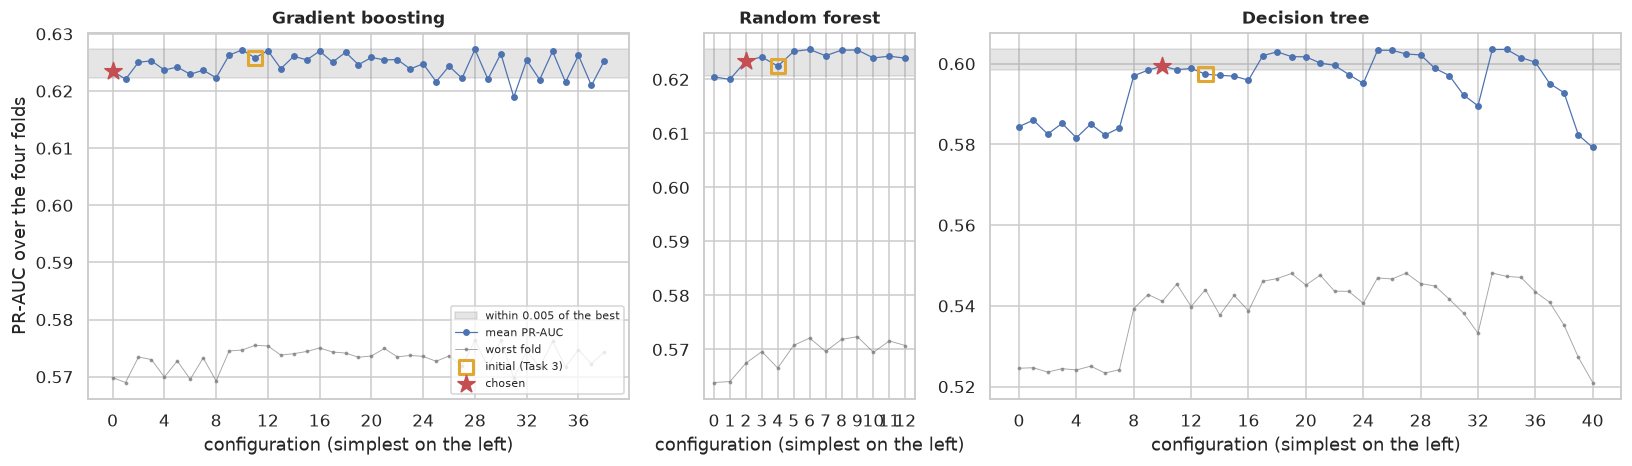

93 configurations searched in 36.7 min; extensions: {'Gradient boosting': {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}, 'Random forest': {'min_samples_leaf': [200]}, 'Decision tree': {'min_samples_leaf': [800]}}


In [122]:
SEARCHES = {"Gradient boosting": search_boosting, "Random forest": search_forest, "Decision tree": search_tree}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [36, 14, 42]})
for ax, (name, t) in zip(axes, SEARCHES.items()):
    x = np.arange(len(t))
    best = t["mean"].max()
    ax.axhspan(best - TOLERANCE, best, color=C_GREY, alpha=0.2, label=f"within {TOLERANCE} of the best")
    ax.plot(x, t["mean"], marker="o", ms=3.5, lw=0.8, color=C_NORMAL, label="mean PR-AUC")
    ax.plot(x, t["worst fold"], marker=".", ms=3, lw=0.6, color=C_GREY, alpha=0.7, label="worst fold")
    i_init, i_chosen = t.index.get_loc(INITIAL[name]), t.index.get_loc(CHOSEN[name])
    ax.scatter([i_init], [t["mean"].iloc[i_init]], s=90, marker="s", facecolor="none", edgecolor=C_ORANGE, lw=2, zorder=5, label="initial (Task 3)")
    ax.scatter([i_chosen], [t["mean"].iloc[i_chosen]], s=140, marker="*", color=C_ABN, zorder=6, label="chosen")
    ax.set_xticks(x[::4] if len(t) > 16 else x)
    ax.set_xlabel("configuration (simplest on the left)")
    ax.set_title(name)
axes[0].set_ylabel("PR-AUC over the four folds")
axes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
savefig(fig, "04_search")

# One row per (model, configuration, fold), for prepared/task4_search.csv.
all_metrics = pd.concat(METRICS)
SEARCH_ROWS = []
for name, configs in SEARCH.items():
    for label, _, params in configs:
        sub = all_metrics[all_metrics["model"] == label].drop_duplicates("fold")
        assert len(sub) == 4
        for _, r in sub.iterrows():
            SEARCH_ROWS.append({"model": name, "configuration": label, **params, "fold": r["fold"], "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"],
                                "Brier": r["Brier"], "log-loss": r["log-loss"], "seconds": r["seconds"], "chosen": label == CHOSEN[name]})
search_rows = pd.DataFrame(SEARCH_ROWS)
assert (search_rows.groupby(["model", "configuration"]).size() == 4).all()
assert (search_rows[search_rows["chosen"]].groupby("model")["configuration"].nunique() == 1).all()
print(f"{search_rows['configuration'].nunique()} configurations searched in "
      f"{sum(SEARCH_SECONDS.values()) / 60:.1f} min; extensions: {EXTENDED}")

The figure summarises the 93 configurations, searched in 35.9 minutes. For gradient boosting and the random forest, 31 of 39 and 11 of 13
configurations fall inside the grey band of 0.005 below the best, so the hyperparameters in our ranges change the mean PR-AUC by less than
the noise we accept. The decision tree is the only model whose grid matters: the shallow trees on the left and the deep trees with small
leaves on the right are clearly lower. The worst fold (thin line) moves with the mean, so no configuration buys a better average at the cost
of a much worse quarter.

---
## 5. Optimised versus initial, and the final model

For each model we compare the configuration chosen by the search with its Task 3 configuration, fold by fold. Following the rule that Task 3
used for the ablation, we call an improvement meaningful when the mean PR-AUC gain is larger than the tolerance of 0.005, and stable when the
optimised configuration wins in at least 3 of the 4 folds. We adopt the optimised configuration only if its gain is both meaningful and stable;
otherwise the Task 3 configuration stays, which is a result in itself. With four dependent folds we compute no p-value (Task 2, Section 8).

The final model is then the kept configuration with the best mean PR-AUC. If another one is within the tolerance, the better worst fold
decides, because the protocol says a model should not be judged on its average alone, and then the lower cost.

In [123]:
VERDICTS, KEPT = [], {}
fold_cols = [f"fold {f['fold']}" for f in FOLDS]
for name in SEARCH:
    initial, optimised = INITIAL[name], CHOSEN[name]
    pr = metric_table([initial, optimised] if optimised != initial else [initial])
    roc = metric_table([initial, optimised] if optimised != initial else [initial], "ROC-AUC")
    brier = metric_table([initial, optimised] if optimised != initial else [initial], "Brier")
    diff, s = paired(pr.loc[optimised, fold_cols], pr.loc[initial, fold_cols])
    won = int((diff > 0).sum())
    meaningful, stable = bool(diff.mean() > TOLERANCE), bool(won >= 3)
    KEPT[name] = optimised if meaningful and stable else initial
    VERDICTS.append({"model": name, "initial": initial, "optimised": optimised, "mean gain": diff.mean(), "folds won": won,
                     "worst-fold gain": pr.loc[optimised, fold_cols].min() - pr.loc[initial, fold_cols].min(),
                     "ROC-AUC gain": roc.loc[optimised, "mean"] - roc.loc[initial, "mean"],
                     "Brier change": brier.loc[optimised, "mean"] - brier.loc[initial, "mean"],
                     "meaningful": meaningful, "stable": stable, "kept": KEPT[name]})
verdicts = pd.DataFrame(VERDICTS).set_index("model")
display(verdicts.style.format({"mean gain": "{:+.4f}", "worst-fold gain": "{:+.4f}", "ROC-AUC gain": "{:+.4f}", "Brier change": "{:+.4f}"}))
print("Per-fold PR-AUC, initial and optimised:")
display(metric_table(list(dict.fromkeys([l for v in VERDICTS for l in (v["initial"], v["optimised"])]))).style.format("{:.4f}"))

,initial,optimised,mean gain,folds won,worst-fold gain,ROC-AUC gain,Brier change,meaningful,stable,kept
model,,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100","HGB depth=4, lr=0.1, 100 it, leaf=200",-0.0023,1,-0.0056,+0.0001,+0.0003,False,False,"HGB depth=6, lr=0.1, 200 it, leaf=100"
Random forest,"RF leaf=50, features=sqrt","RF leaf=100, features=9",+0.0010,4,+0.0009,+0.0004,-0.0002,False,True,"RF leaf=50, features=sqrt"
Decision tree,"DT depth=8, leaf=100, gini","DT depth=8, leaf=400, entropy",+0.0020,3,-0.0029,+0.0015,-0.0000,False,True,"DT depth=8, leaf=100, gini"


Per-fold PR-AUC, initial and optimised:


,fold 1,fold 2,fold 3,fold 4,mean
model,,,,,
"HGB depth=6, lr=0.1, 200 it, leaf=100",0.6176,0.5755,0.6497,0.6604,0.6258
"HGB depth=4, lr=0.1, 100 it, leaf=200",0.6185,0.5698,0.6470,0.6585,0.6235
"RF leaf=50, features=sqrt",0.6154,0.5666,0.6460,0.6619,0.6224
"RF leaf=100, features=9",0.6170,0.5675,0.6468,0.6624,0.6234
"DT depth=8, leaf=100, gini",0.5865,0.5440,0.6239,0.6352,0.5974
"DT depth=8, leaf=400, entropy",0.5923,0.5411,0.6264,0.6378,0.5994


In [124]:
weights = fold_table["validation sessions"].to_numpy()
all_metrics = pd.concat(METRICS)
rows = []
for name, label in KEPT.items():
    pr = metric_table([label]).loc[label, fold_cols]
    s = summarise_folds(pr.to_numpy(), weights)
    other = all_metrics[all_metrics["model"] == label].drop_duplicates("fold")[["ROC-AUC", "Brier", "log-loss", "seconds"]].mean()
    rows.append({"model": name, "configuration": label, "PR-AUC mean": s["mean (unweighted)"], "std": s["std across folds"],
                 "worst fold": s["worst fold"], "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"],
                 "seconds per fold": other["seconds"]})
for label in BASELINES:
    pr = metric_table([label]).loc[label, fold_cols]
    other = all_metrics[all_metrics["model"] == label][["ROC-AUC", "Brier", "log-loss"]].mean()
    rows.append({"model": label, "configuration": "", "PR-AUC mean": pr.mean(), "std": pr.std(ddof=1), "worst fold": pr.min(),
                 "ROC-AUC": other["ROC-AUC"], "Brier": other["Brier"], "log-loss": other["log-loss"], "seconds per fold": np.nan})
kept_table = pd.DataFrame(rows).set_index("model")

# Final model: best mean PR-AUC; within the tolerance, the better worst fold, then the lower cost.
models = kept_table.loc[list(KEPT)]
contenders = models[models["PR-AUC mean"] >= models["PR-AUC mean"].max() - TOLERANCE]
FINAL_MODEL = contenders.sort_values(["worst fold", "seconds per fold"], ascending=[False, True]).index[0]
FINAL_LABEL = KEPT[FINAL_MODEL]
kept_table["final"] = ["yes" if m == FINAL_MODEL else "" for m in kept_table.index]
display(kept_table.sort_values("PR-AUC mean", ascending=False).style.format(
    {"PR-AUC mean": "{:.4f}", "std": "{:.3f}", "worst fold": "{:.3f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}",
     "seconds per fold": "{:.1f}"}, na_rep="—"))
d, s = paired(metric_table([FINAL_LABEL]).loc[FINAL_LABEL, fold_cols], metric_table([BASELINES[1]]).loc[BASELINES[1], fold_cols])
print(f"Final model: {FINAL_MODEL} ({FINAL_LABEL}); contenders within the tolerance: {list(contenders.index)}")
print(f"Gain over B1: {s['mean difference']:+.4f} on average, {s['folds won']} folds won")

log_decision("5", "Optimisation verdict",
             "; ".join(f"{v['model']}: {'optimised configuration adopted' if v['kept'] == v['optimised'] and v['optimised'] != v['initial'] else 'Task 3 configuration kept'}"
                       for v in VERDICTS) + ".",
             "; ".join(f"{v['model']} {v['optimised']} vs {v['initial']}: mean gain {v['mean gain']:+.4f}, {v['folds won']} of 4 folds won"
                       for v in VERDICTS) + f". Adopted only if gain > {TOLERANCE} and at least 3 of 4 folds won.")
log_decision("5", "Final model", f"{FINAL_MODEL}: {FINAL_LABEL}.",
             f"Mean PR-AUC {kept_table.loc[FINAL_MODEL, 'PR-AUC mean']:.4f}, worst fold {kept_table.loc[FINAL_MODEL, 'worst fold']:.3f}; "
             f"contenders within {TOLERANCE}: {', '.join(contenders.index)}; gain over B1 {s['mean difference']:+.4f} ({s['folds won']}).")

,configuration,PR-AUC mean,std,worst fold,ROC-AUC,Brier,log-loss,seconds per fold,final
model,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100",0.6258,0.038,0.575,0.836,0.1020,0.3373,2.9,yes
Random forest,"RF leaf=50, features=sqrt",0.6224,0.042,0.567,0.835,0.1025,0.3391,12.6,
Decision tree,"DT depth=8, leaf=100, gini",0.5974,0.041,0.544,0.824,0.1046,0.3471,2.6,
B1 post failure rate (7 days),,0.5106,0.042,0.456,0.772,0.1176,0.3847,—,
B0 no skill,,0.1812,0.021,0.162,0.504,0.1478,0.4719,—,


Final model: Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100); contenders within the tolerance: ['Gradient boosting', 'Random forest']
Gain over B1: +0.1152 on average, 4 of 4 folds won


None of the three optimised configurations passes our rule, so each model keeps its Task 3 configuration. For gradient boosting, the
configuration chosen by the search is simpler (depth 4, 100 iterations) and slightly worse: −0.0023 on average, winning only 1 of the 4
folds. For the random forest, the chosen configuration wins all 4 folds, so the change is stable, but the mean gain of +0.0010 is far below
the tolerance. For the tree, the gain is +0.0020 with 3 folds won, but the worst fold drops by 0.0029. The ROC-AUC and the Brier score
barely move in any of the three.

The searches therefore confirm Task 3 rather than improve it. The one larger difference in the grids, the depth-16 tree at 0.0061 above the
Task 3 tree, needs twice the depth and is still 0.022 below gradient boosting, so it would not change the final choice.

The final model is gradient boosting with its Task 3 configuration (depth 6, learning rate 0.1, 200 iterations, leaves of at least 100
sessions). Its mean PR-AUC of 0.6258 is 0.0034 above the random forest, inside the tolerance, so the tie is broken by the worst fold: 0.575
for boosting against 0.567 for the forest. Boosting is also about four times faster to fit (3.1 against 12.0 seconds per fold). It beats B1
in all four folds, by +0.1152 on average.

---
## 6. Decision threshold

### 6.1 The criterion

A score becomes an alert only once a cut-off is fixed. The brief asks for one criterion, chosen from validation predictions. We use the
operational alert-rate constraint of the Task 2 protocol: the cut-off flags 10% of the sessions, so an operator inspects about 100 sessions
in every 1,000.

We have no data on the cost of a missed failure against the cost of an unnecessary inspection, nor on how many sessions the operator can
check. A cost-based cut-off would need a cost ratio that we would have to invent (the ratio of 10 to 1 in the evaluation lab belongs to its
churn example, not to charging faults), and the protocol does not use F1 to select anything because it weights precision and recall equally
without an operational reason. An alert budget is the one quantity an operator can set directly. Of the three budgets that the protocol
reports (5%, 10% and 20%), we take the middle one; the other two appear in Section 6.4 only as context for a smaller or larger capacity.

The cut-off is computed on the pooled out-of-fold predictions of the four folds: every development validation session receives a score from
the final configuration fitted on the training window of its own fold, so no score comes from a model that saw that session or anything
after it.

In [125]:
log_decision("6", "Threshold criterion",
             "Alert-rate constraint: the cut-off flags 10% of the pooled out-of-fold development predictions of the final model.",
             "Cost ratio and inspection capacity are unknown; the protocol excludes F1 from selection; 10% is the middle of the protocol's 5%, 10% and 20% budgets; "
             "each pooled score comes from a model that did not see that session.")

### 6.2 The cut-off and its stability across folds

In [126]:
OOF_Y = np.concatenate([df.loc[f["valid"], TARGET].to_numpy() for f in FOLDS])
OOF_P = np.concatenate([PREDS[(FINAL_LABEL, f["fold"])] for f in FOLDS])
OOF_FOLD = np.concatenate([np.full(len(f["valid"]), f["fold"]) for f in FOLDS])
assert len(OOF_P) == 235_472 == fold_table["validation sessions"].sum()          # one score per validation session

k = int(round(TARGET_ALERT_RATE * len(OOF_P)))
CUT_OFF = float(np.sort(OOF_P)[::-1][k - 1])                                      # k-th largest score; flag if score >= CUT_OFF
pooled_rate = (OOF_P >= CUT_OFF).mean()
print(f"Selected cut-off: {CUT_OFF:.4f} (flags {pooled_rate:.2%} of the {len(OOF_P):,} pooled out-of-fold predictions)")

PER_FOLD_CUT_OFFS = {int(f["fold"]): float(np.quantile(OOF_P[OOF_FOLD == f["fold"]], 1 - TARGET_ALERT_RATE)) for f in FOLDS}
rows = []
for f in FOLDS:
    m = OOF_FOLD == f["fold"]
    rows.append({"fold": f["fold"], "abnormal share": OOF_Y[m].mean(), "fold's own 10% cut-off": PER_FOLD_CUT_OFFS[f["fold"]],
                 **{k_: v for k_, v in operating_point(OOF_Y[m], OOF_P[m], CUT_OFF).items() if k_ != "cut-off"}})
per_fold_op = pd.DataFrame(rows).set_index("fold")
print(f"Pooled cut-off applied to each fold (the fold's own 90th percentile is shown for comparison):")
display(per_fold_op.style.format({**OP_FORMAT, "abnormal share": "{:.1%}", "fold's own 10% cut-off": "{:.4f}"}, na_rep="—"))

Selected cut-off: 0.4899 (flags 10.00% of the 235,472 pooled out-of-fold predictions)
Pooled cut-off applied to each fold (the fold's own 90th percentile is shown for comparison):


,abnormal share,fold's own 10% cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
fold,,,,,,,,,
1,16.8%,0.4286,0.751,0.375,0.500,8.4%,63.2,21.0,105.2
2,15.8%,0.3892,0.713,0.347,0.467,7.7%,54.9,22.1,103.3
3,18.2%,0.5052,0.739,0.423,0.538,10.4%,77.2,27.2,105.1
4,21.1%,0.5668,0.745,0.430,0.545,12.2%,90.8,31.1,120.6


The cut-off that flags 10% of the 235,472 pooled out-of-fold predictions is 0.4899. Applied to each fold, it flags between 7.7% and 12.2% of
the sessions, and the alert rate follows the abnormal share of the quarter (15.8% in fold 2, 21.1% in fold 4). Each fold's own 10% cut-off
would range from 0.389 to 0.567. Precision, on the other hand, stays between 0.713 and 0.751 in every fold. A fixed cut-off keeps the
quality of an alert stable and lets the number of alerts rise and fall with the failure level, so an operator should expect more alerts in a
bad quarter rather than a constant 10%.

### 6.3 The default cut-off of 0.50 against the selected cut-off

The table compares the two cut-offs on the pooled predictions and in each fold. The figure follows the threshold exercise of the evaluation
lab: precision, recall and F1 of the pooled predictions for every cut-off between 0.01 and 0.99, with both cut-offs marked, and the share of
sessions that each cut-off flags.

In [127]:
OPERATING_POINTS = []
for scope, mask in [("pooled", np.ones(len(OOF_P), bool))] + [(f"fold {f['fold']}", OOF_FOLD == f["fold"]) for f in FOLDS]:
    for name, cut in [("default 0.50", 0.5), ("selected", CUT_OFF)]:
        OPERATING_POINTS.append({"name": name, "scope": scope, **operating_point(OOF_Y[mask], OOF_P[mask], cut)})
op_dev = pd.DataFrame(OPERATING_POINTS).set_index(["scope", "name"])
display(op_dev.style.format(OP_FORMAT, na_rep="—"))

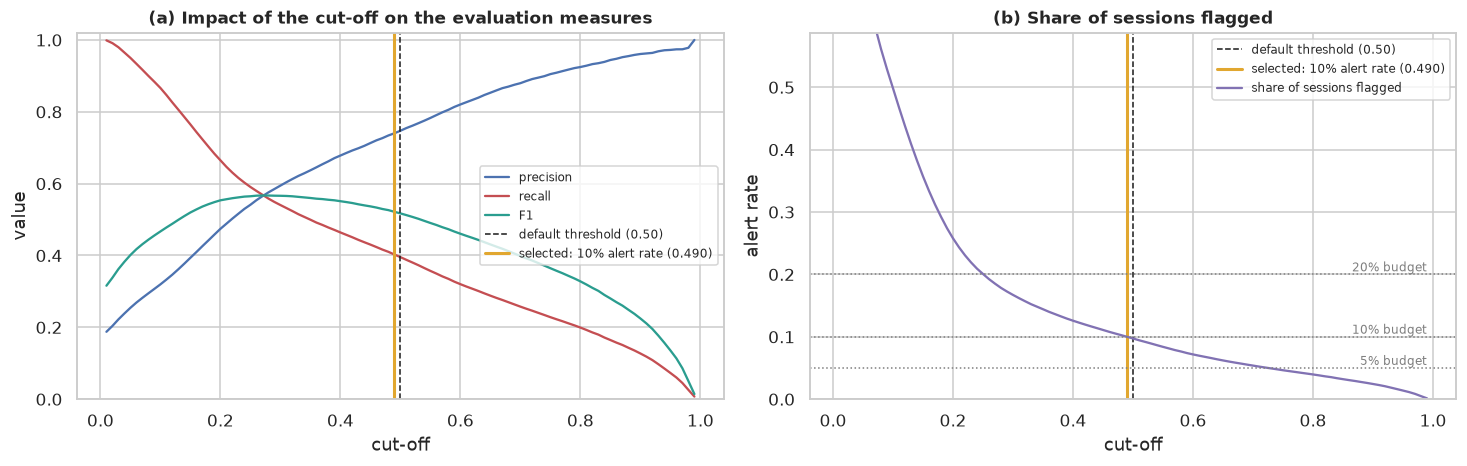

In [128]:
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
curve = pd.DataFrame([operating_point(OOF_Y, OOF_P, t) for t in grid])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].plot(grid, curve["precision"], color=C_NORMAL, label="precision")
axes[0].plot(grid, curve["recall"], color=C_ABN, label="recall")
axes[0].plot(grid, curve["F1"], color=C_GREEN, label="F1")
for ax in axes:
    ax.axvline(0.5, color="k", ls="--", lw=1, label="default threshold (0.50)")
    ax.axvline(CUT_OFF, color=C_ORANGE, lw=2, label=f"selected: 10% alert rate ({CUT_OFF:.3f})")
    ax.set_xlabel("cut-off")
axes[0].set_ylabel("value"); axes[0].set_ylim(0, 1.02)
axes[0].set_title("(a) Impact of the cut-off on the evaluation measures"); axes[0].legend(fontsize=8, loc="center right")
axes[1].plot(grid, curve["alert rate"], color=C_PURPLE, label="share of sessions flagged")
for q in ALERT_BUDGETS:
    axes[1].axhline(q, color=C_GREY, ls=":", lw=1)
    axes[1].text(0.99, q, f"{q:.0%} budget", ha="right", va="bottom", fontsize=8, color=C_GREY)
axes[1].set_ylabel("alert rate"); axes[1].set_ylim(0, max(0.5, curve["alert rate"].max() * 0.6))
axes[1].set_title("(b) Share of sessions flagged"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "06_threshold")

The two cut-offs give almost the same operating point, because the 10% budget happens to fall just below 0.50. On the pooled predictions,
0.50 flags 9.7% of the sessions with a precision of 0.747 and a recall of 0.395; the selected 0.490 flags 10.0% with 0.740 and 0.403. Per
1,000 sessions the selected cut-off adds 1.3 correct alerts and 1.4 false ones, and misses 109.8 abnormal sessions instead of 111.1. Every
fold shows the same small shift.

The closeness is not a property of 0.50 in general. It holds because the scores of this model are close to probabilities (Section 7) and
about 10% of the sessions have a predicted risk above one half. The figure shows that F1 would peak at a much lower cut-off, around 0.3,
where the model flags well over 10% of the sessions; the protocol does not use F1 to choose, so we keep the budget. The difference from 0.50
is that our cut-off comes from a stated capacity and would stay meaningful for another model whose scores are not calibrated.

### 6.4 Operational consequences

To translate the cut-off into work for an operator, the table below gives the pooled measures at the three budgets of the protocol. The 10%
row is the selected operating point; the 5% and 20% rows show what a smaller or a larger inspection capacity would give with the same model.

In [129]:
rows = []
for q in ALERT_BUDGETS:
    cut = float(np.sort(OOF_P)[::-1][int(round(q * len(OOF_P))) - 1])
    rows.append({"budget": f"{q:.0%}" + (" (selected)" if q == TARGET_ALERT_RATE else ""), **operating_point(OOF_Y, OOF_P, cut)})
budgets_table = pd.DataFrame(rows).set_index("budget")
display(budgets_table.style.format(OP_FORMAT, na_rep="—"))
print(f"Abnormal sessions per 1,000 in the development quarters: {1000 * OOF_Y.mean():.1f}")
print(f"Cost ratio implied by the selected cut-off if the scores were calibrated probabilities: c = (1 - t) / t = {(1 - CUT_OFF) / CUT_OFF:.2f}")

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
budget,,,,,,,,
5%,0.725,0.894,0.243,0.382,5.0%,44.7,5.3,139.1
10% (selected),0.490,0.740,0.403,0.522,10.0%,74.0,26.0,109.8
20%,0.251,0.542,0.590,0.565,20.0%,108.4,91.6,75.4


Abnormal sessions per 1,000 in the development quarters: 183.8
Cost ratio implied by the selected cut-off if the scores were calibrated probabilities: c = (1 - t) / t = 1.04


At the 10% budget an operator inspects 100 sessions in every 1,000: 74.0 of them are real failures and 26.0 are false alerts, and 109.8 of
the 183.8 abnormal sessions per 1,000 are still missed. The two other budgets show the trade-off. Going from 5% to 10% adds 29.3 correct
alerts for 20.7 more false ones, so the extra inspections still find more failures than they waste. Going from 10% to 20% adds 34.4 correct
alerts for 65.6 more false ones, about two wasted inspections for each extra failure found. Of the three budgets, 10% is the last one where
the extra alerts are more often right than wrong.

If the scores are read as calibrated probabilities, the cut-off of 0.490 corresponds to a cost ratio of 1.04, as if a missed failure cost
about the same as an unnecessary inspection. Task 2 argued that a missed failure costs more. If the operator agrees and has the capacity,
the 20% row shows what a larger budget would give; with the capacity unknown, we keep 10%.

---
## 7. Calibration check

A model is calibrated when, among the sessions that receive a score of about 0.3, about 30% are abnormal. The evaluation slides (MINDD-04)
note that trees and forests give class proportions that are sometimes scores rather than probabilities, so we check the final model
before reading its outputs as probabilities. We use the pooled out-of-fold predictions: a reliability curve over ten score bands with equal
numbers of sessions (mean predicted score against the observed abnormal share in each band), the Brier score, and, per fold, the mean
predicted score against the observed share. Calibration is not in the slides beyond this remark; we check it because the brief asks whether
it is needed for the chosen use.

,mean predicted,observed abnormal share,gap
score band (10% of sessions each),,,
1,0.013,0.015,0.002
2,0.025,0.025,0.000
3,0.039,0.044,0.005
4,0.058,0.066,0.008
5,0.084,0.093,0.010
6,0.116,0.126,0.010
7,0.153,0.161,0.008
8,0.208,0.223,0.015
9,0.347,0.344,-0.003


,mean predicted,observed abnormal share,Brier
fold,,,
1,0.158,0.168,0.097
2,0.158,0.158,0.097
3,0.179,0.182,0.100
4,0.204,0.211,0.114


Pooled Brier score 0.1032 (constant prior 0.1500); largest gap between predicted and observed in a band: 0.015


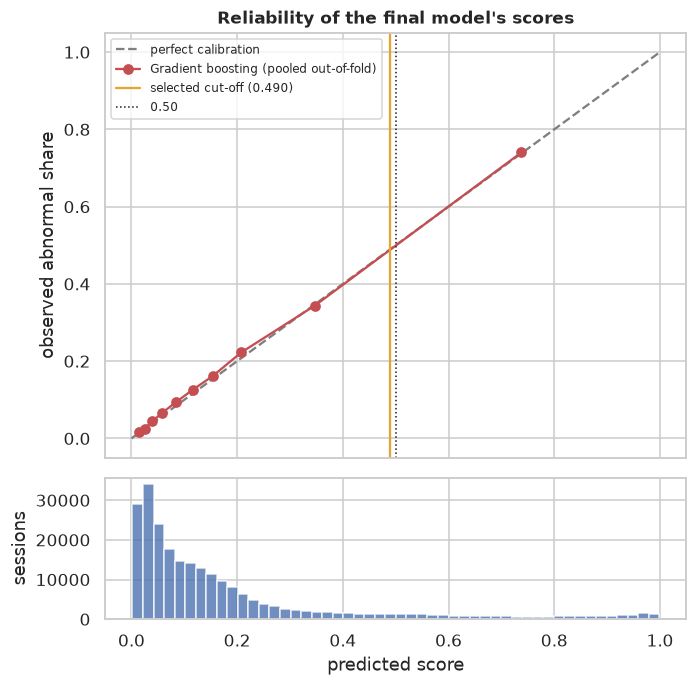

In [130]:
prob_true, prob_pred = calibration_curve(OOF_Y, OOF_P, n_bins=10, strategy="quantile")
brier_pooled = brier_score_loss(OOF_Y, OOF_P)
brier_prior = brier_score_loss(OOF_Y, np.full(len(OOF_Y), OOF_Y.mean()))
bands = pd.DataFrame({"mean predicted": prob_pred, "observed abnormal share": prob_true, "gap": prob_true - prob_pred})
bands.index = pd.RangeIndex(1, len(bands) + 1, name="score band (10% of sessions each)")
display(bands.style.format("{:.3f}"))
per_fold_cal = pd.DataFrame([{"fold": f["fold"], "mean predicted": OOF_P[OOF_FOLD == f["fold"]].mean(), "observed abnormal share": OOF_Y[OOF_FOLD == f["fold"]].mean(),
                              "Brier": brier_score_loss(OOF_Y[OOF_FOLD == f["fold"]], OOF_P[OOF_FOLD == f["fold"]])} for f in FOLDS]).set_index("fold")
display(per_fold_cal.style.format("{:.3f}"))
largest_gap = bands["gap"].abs().max()
print(f"Pooled Brier score {brier_pooled:.4f} (constant prior {brier_prior:.4f}); largest gap between predicted and observed in a band: {largest_gap:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(6.5, 6.4), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
axes[0].plot([0, 1], [0, 1], color=C_GREY, ls="--", label="perfect calibration")
axes[0].plot(prob_pred, prob_true, marker="o", color=C_ABN, label=f"{FINAL_MODEL} (pooled out-of-fold)")
axes[0].axvline(CUT_OFF, color=C_ORANGE, lw=1.5, label=f"selected cut-off ({CUT_OFF:.3f})")
axes[0].axvline(0.5, color="k", ls=":", lw=1, label="0.50")
axes[0].set_ylabel("observed abnormal share"); axes[0].set_title("Reliability of the final model's scores"); axes[0].legend(fontsize=8)
axes[1].hist(OOF_P, bins=50, color=C_NORMAL, alpha=0.8)
axes[1].set_xlabel("predicted score"); axes[1].set_ylabel("sessions")
fig.tight_layout()
savefig(fig, "07_calibration")
CALIBRATION = {"Brier": float(brier_pooled), "Brier constant prior": float(brier_prior), "largest band gap": float(largest_gap),
               "bands": [{"mean predicted": float(a), "observed": float(b)} for a, b in zip(prob_pred, prob_true)],
               "per fold": per_fold_cal.reset_index().to_dict("records")}

The scores are close to calibrated. The pooled Brier score is 0.1032, against 0.1500 for a constant prediction of the training prior. In the
ten bands of equal size, the mean predicted score and the observed abnormal share differ by at most 0.015 (band 8: 0.208 predicted, 0.223
observed). The model slightly under-predicts in the middle bands (gaps of 0.005 to 0.015) and is accurate at both ends, including the top
band where the alerts are (0.738 against 0.740). Per fold, the mean score follows the abnormal share closely, with the largest gap in fold 1
(0.158 against 0.168).

We do not add a calibration step. The criterion uses the scores only to rank the sessions and fix an alert budget, and a calibration that
keeps the order of the scores would flag exactly the same sessions. Calibration would matter if the scores were shown to the operator as
risks or used with a cost-based cut-off; for those uses the gaps above, under 2 percentage points, are small enough to read the scores as
approximate probabilities.

In [131]:
CALIBRATION["decision"] = ("No calibrator is fitted: the 10% criterion uses the scores only as a ranking, which calibration would not change; "
                           f"the reliability check (Brier {brier_pooled:.4f}, largest band gap {largest_gap:.3f}) decides how far the scores can be read as probabilities.")
log_decision("7", "Calibration", "No calibrator; scores used as a ranking for the 10% alert budget.",
             f"Pooled out-of-fold Brier score {brier_pooled:.4f} against {brier_prior:.4f} for the constant prior; largest gap between mean predicted and observed "
             f"share over ten equal-frequency bands {largest_gap:.3f}; a monotone calibrator would not change which sessions are flagged.")

---
## 8. Freezing the final choices

Everything that the test evaluation needs is now fixed: the model and its configuration, the 27 features, the cut-off and the criterion
that produced it, and the calibration decision. We write them to `prepared/task4_frozen.json`, together with the development estimates
that the test result will be compared with. Section 9 reads the model, the features and the cut-off from this file, not from the variables
in memory, and nothing in this notebook changes them after the test period has been scored.

In [132]:
dev_point = op_dev.loc[("pooled", "selected")]
final_metrics = all_metrics[all_metrics["model"] == FINAL_LABEL].drop_duplicates("fold")
FROZEN_CHOICES = {
    "frozen_at": datetime.now().isoformat(timespec="seconds"),
    "model": FINAL_MODEL,
    "configuration": FINAL_LABEL,
    "hyperparameters": PARAMS[FINAL_LABEL],
    "features": SELECTED,
    "criterion": "alert rate 10% of pooled out-of-fold predictions",
    "alert_rate_target": TARGET_ALERT_RATE,
    "cut_off": CUT_OFF,
    "calibration": "none",
    "development_estimates": {"PR-AUC mean": float(final_metrics["PR-AUC"].mean()), "ROC-AUC": float(final_metrics["ROC-AUC"].mean()),
                              "Brier": float(final_metrics["Brier"].mean()), "log-loss": float(final_metrics["log-loss"].mean()),
                              "precision": float(dev_point["precision"]), "recall": float(dev_point["recall"]),
                              "F1": float(dev_point["F1"]), "alert rate": float(dev_point["alert rate"])},
}
(OUT_DIR / "task4_frozen.json").write_text(json.dumps(FROZEN_CHOICES, indent=2, default=float))
log_decision("8", "Frozen choices", f"{FINAL_MODEL} ({FINAL_LABEL}), 27 Task 3 features, cut-off {CUT_OFF:.4f}, no calibrator; written to prepared/task4_frozen.json.",
             f"Frozen at {FROZEN_CHOICES['frozen_at']}, before the test period is read; development estimates: mean PR-AUC "
             f"{FROZEN_CHOICES['development_estimates']['PR-AUC mean']:.4f}, precision {dev_point['precision']:.3f} and recall {dev_point['recall']:.3f} at the cut-off.")
N_DECISIONS_AT_FREEZE = len(DECISIONS)
print(json.dumps(FROZEN_CHOICES, indent=1, default=float))
assert df["start_time"].max() < TEST_START          # nothing so far has seen a test session

{
 "frozen_at": "2026-10-30T14:03:17",
 "model": "Gradient boosting",
 "configuration": "HGB depth=6, lr=0.1, 200 it, leaf=100",
 "hyperparameters": {
  "max_depth": 6,
  "learning_rate": 0.1,
  "max_iter": 200,
  "min_samples_leaf": 100
 },
 "features": [
  "hour",
  "dow",
  "location",
  "district",
  "temperature",
  "humidity",
  "precipitation",
  "rain_flag",
  "post_previous_sessions_1D",
  "post_previous_sessions_7D",
  "post_previous_sessions_30D",
  "post_previous_abnormal_rate_1D",
  "post_previous_abnormal_rate_7D",
  "post_previous_abnormal_rate_30D",
  "post_hours_since_previous_completed_session",
  "post_hours_since_previous_completed_abnormal",
  "is_new_user",
  "user_previous_sessions_30D",
  "user_previous_sessions_180D",
  "user_previous_sessions_730D",
  "user_previous_abnormal_rate_30D",
  "user_previous_abnormal_rate_180D",
  "user_previous_abnormal_rate_730D",
  "user_days_since_previous_completed_session",
  "user_days_since_previous_completed_abnormal",
  "u

---
## 9. Final evaluation on the test period

This section is the only one that reads the test period. It loads the frozen file, refits the frozen configuration on all development
sessions whose label was known before the test start (a session that started in September 2021 but ended on or after 1 October is purged,
as in the folds), reads the test sessions, and scores them once. B0 and B1 are scored on the same sessions. The cut-off is applied
unchanged. A guard makes a second scoring in the same kernel fail.

In [133]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
FROZEN = json.loads((OUT_DIR / "task4_frozen.json").read_text())
print(f"Frozen choices loaded (frozen at {FROZEN['frozen_at']}): {FROZEN['model']}, {FROZEN['configuration']}, cut-off {FROZEN['cut_off']:.4f}")

final_label, final_factory, _ = MAKERS[FROZEN["model"]](**FROZEN["hyperparameters"])
assert final_label == FROZEN["configuration"]
dev_train = df[df["end_time"] < TEST_START]                                           # purge: label known before the test start
assert dev_train["start_time"].min() >= BURN_IN_END and dev_train["end_time"].max() < TEST_START
print(f"Final training data: {len(dev_train):,} development sessions ({len(df) - len(dev_train):,} purged because they ended on or after {TEST_START.date()})")
started = time.time()
final_model = final_factory(FROZEN["features"]).fit(dev_train[FROZEN["features"]], dev_train[TARGET])
if isinstance(final_model.named_steps["clf"], HistGradientBoostingClassifier):
    assert not final_model.named_steps["clf"].do_early_stopping_
print(f"Final model refitted in {time.time() - started:.0f} s")

Frozen choices loaded (frozen at 2026-10-30T14:03:17): Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, cut-off 0.4899
Final training data: 346,931 development sessions (48 purged because they ended on or after 2021-10-01)


Final model refitted in 5 s


In [134]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
test, test_counts = load_sessions("test")
assert len(test) == 80_081 and test["start_time"].min() >= TEST_START
print(f"Test period: {len(test):,} sessions ({test['start_time'].min().date()} to {test['start_time'].max().date()}), abnormal share {test[TARGET].mean():.2%}")

y_test = test[TARGET].to_numpy()
p_test = final_model.predict_proba(test[FROZEN["features"]])[:, 1]
TEST_SCORED = True

rng_test = np.random.default_rng(SEED)
prior = dev_train[TARGET].mean()
TEST_SCORES = {FROZEN["model"]: (p_test, p_test), "B0 no skill": (rng_test.random(len(y_test)), np.full(len(y_test), prior)),
               "B1 post failure rate (7 days)": (test["post_previous_abnormal_rate_7D"].to_numpy(),) * 2}
rng_boot = np.random.default_rng(SEED)
resamples = [rng_boot.integers(0, len(y_test), len(y_test)) for _ in range(100)]
rows = []
for name, (score, prob) in TEST_SCORES.items():
    m = evaluate_scores(y_test, score, prob, rng=np.random.default_rng(SEED))
    se = np.std([average_precision_score(y_test[i], score[i]) for i in resamples], ddof=1)
    rows.append({"model": name, "PR-AUC": m["PR-AUC"], "PR-AUC bootstrap SE": se, "lift": m["lift"], "ROC-AUC": m["ROC-AUC"],
                 "Brier": m["Brier"], "log-loss": m["log-loss"]})
test_table = pd.DataFrame(rows).set_index("model")

dev = {FROZEN["model"]: FROZEN["development_estimates"]}
for label in BASELINES:
    sub = all_metrics[all_metrics["model"] == label]
    dev[label] = {"PR-AUC mean": sub["PR-AUC"].mean(), "ROC-AUC": sub["ROC-AUC"].mean(), "Brier": sub["Brier"].mean(), "log-loss": sub["log-loss"].mean()}
test_table.insert(1, "development PR-AUC (mean of folds)", [dev[m]["PR-AUC mean"] for m in test_table.index])
test_table["development ROC-AUC"] = [dev[m]["ROC-AUC"] for m in test_table.index]
display(test_table.style.format({"PR-AUC": "{:.4f}", "PR-AUC bootstrap SE": "{:.4f}", "development PR-AUC (mean of folds)": "{:.4f}", "lift": "{:.2f}",
                                 "ROC-AUC": "{:.3f}", "development ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}"}))

test_points = []
for name, cut in [("default 0.50", 0.5), ("selected", FROZEN["cut_off"])]:
    test_points.append({"name": name, "scope": "test", **operating_point(y_test, p_test, cut)})
OPERATING_POINTS.extend(test_points)
op_compare = pd.DataFrame(test_points + [{**r, "scope": "development (pooled)"} for r in OPERATING_POINTS
                                         if r["scope"] == "pooled"]).set_index(["scope", "name"])
display(op_compare.style.format(OP_FORMAT, na_rep="—"))
observed_rate = float((p_test >= FROZEN["cut_off"]).mean())
print(f"Observed test alert rate at the frozen cut-off: {observed_rate:.2%} (target {FROZEN['alert_rate_target']:.0%})")
TEST_RESULT = {"sessions": int(len(test)), "abnormal share": float(y_test.mean()), "observed alert rate": observed_rate,
               "models": test_table.reset_index().drop(columns=["development PR-AUC (mean of folds)", "development ROC-AUC"]).to_dict("records")}

Test period: 80,081 sessions (2021-10-01 to 2021-12-31), abnormal share 17.59%


,PR-AUC,development PR-AUC (mean of folds),PR-AUC bootstrap SE,lift,ROC-AUC,Brier,log-loss,development ROC-AUC
model,,,,,,,,
Gradient boosting,0.5324,0.6258,0.0047,3.03,0.794,0.1131,0.3697,0.836
B0 no skill,0.1782,0.1812,0.0019,1.01,0.505,0.1451,0.4655,0.504
B1 post failure rate (7 days),0.3809,0.5106,0.0044,2.17,0.723,0.1293,0.4166,0.772


Observed test alert rate at the frozen cut-off: 7.43% (target 10%)


In [135]:
final_dev = metric_table([FINAL_LABEL]).loc[FINAL_LABEL, fold_cols]
b1_dev = metric_table([BASELINES[1]]).loc[BASELINES[1], fold_cols]
trend = summarise_folds(final_dev.to_numpy(), weights)["trend per fold"]
y4, p4 = OOF_Y[OOF_FOLD == 4], OOF_P[OOF_FOLD == 4]
rng_boot4 = np.random.default_rng(SEED)
se4 = np.std([average_precision_score(y4[i], p4[i]) for i in (rng_boot4.integers(0, len(y4), len(y4)) for _ in range(100))], ddof=1)
gap = pd.DataFrame({"abnormal share": list(fold_table["validation abnormal share"]) + [y_test.mean()],
                    "final model PR-AUC": list(final_dev) + [test_table.loc[FROZEN["model"], "PR-AUC"]],
                    "B1 PR-AUC": list(b1_dev) + [test_table.loc[BASELINES[1], "PR-AUC"]]},
                   index=[f"fold {f['fold']} ({f['lo'].date()})" for f in FOLDS] + [f"test ({TEST_START.date()})"])
gap["gain over B1"] = gap["final model PR-AUC"] - gap["B1 PR-AUC"]
gap["lift"] = gap["final model PR-AUC"] / gap["abnormal share"]
display(gap.style.format({"abnormal share": "{:.1%}", "final model PR-AUC": "{:.4f}", "B1 PR-AUC": "{:.4f}", "gain over B1": "{:+.4f}", "lift": "{:.2f}"}))
print(f"Development trend of the final model: {trend:+.4f} PR-AUC per fold | fold 4: {final_dev.iloc[-1]:.4f} (bootstrap SE {se4:.4f}) | "
      f"test: {test_table.loc[FROZEN['model'], 'PR-AUC']:.4f} (bootstrap SE {test_table.loc[FROZEN['model'], 'PR-AUC bootstrap SE']:.4f})")

t_final, t_b1 = test_table.loc[FROZEN["model"]], test_table.loc[BASELINES[1]]
log_decision("9", "Test result", "Reported as observed; no model, feature or cut-off is changed after this point.",
             f"Test PR-AUC {t_final['PR-AUC']:.4f} (bootstrap SE {t_final['PR-AUC bootstrap SE']:.4f}) against {t_b1['PR-AUC']:.4f} for B1 "
             f"(gain {t_final['PR-AUC'] - t_b1['PR-AUC']:+.4f}) and {test_table.loc[BASELINES[0], 'PR-AUC']:.4f} for B0; development mean {FROZEN['development_estimates']['PR-AUC mean']:.4f}; "
             f"observed alert rate {observed_rate:.2%} at the frozen cut-off {FROZEN['cut_off']:.4f}.")
assert len(DECISIONS) == N_DECISIONS_AT_FREEZE + 1

,abnormal share,final model PR-AUC,B1 PR-AUC,gain over B1,lift
fold 1 (2020-10-01),16.8%,0.6176,0.4991,+0.1185,3.67
fold 2 (2021-01-01),15.8%,0.5755,0.4562,+0.1193,3.64
fold 3 (2021-04-01),18.2%,0.6497,0.5466,+0.1031,3.56
fold 4 (2021-07-01),21.1%,0.6604,0.5403,+0.1201,3.12
test (2021-10-01),17.6%,0.5324,0.3809,+0.1516,3.03


Development trend of the final model: +0.0203 PR-AUC per fold | fold 4: 0.6604 (bootstrap SE 0.0036) | test: 0.5324 (bootstrap SE 0.0047)


The final model was refitted on 346,931 development sessions; 48 sessions that started before 1 October but ended on or after it were
purged, as in the folds. The test period has 80,081 sessions with an abnormal share of 17.59%.

The final model reaches a test PR-AUC of 0.5324 (bootstrap standard error 0.0047), against 0.3809 for B1 and 0.1782 for B0. It still ranks
the sessions three times better than no skill (lift 3.03) and beats B1 by 0.1516, more than its average margin of 0.1152 on the development
folds. In absolute terms, however, the test score is 0.093 below the development mean of 0.6258 and 0.128 below fold 4, the most recent
quarter (0.6604). That gap is about 27 times the bootstrap standard error, so it is a real change in the last quarter of 2021 and not
sampling noise. It also breaks the upward trend of the development folds (+0.020 per fold). B1 falls by even more, from 0.540 in fold 4 to
0.381. This suggests that what weakened is the signal of recent post failures itself: in this quarter a recent failure at a post predicts
the next failure less well than before. ROC-AUC (0.794 against 0.836) and the Brier score (0.1131 against 0.1020) tell the same story.

At the frozen cut-off of 0.490 the model flags 7.43% of the test sessions instead of 10%. Its alerts are less precise than on development
(0.677 against 0.740) and catch fewer failures (recall 0.286 against 0.403): per 1,000 sessions, 50.3 correct alerts, 24.0 false alerts and
125.6 missed abnormal sessions. A smaller alert rate at a fixed cut-off was expected from Section 6.2, where the rate followed the abnormal
share, but 7.4% is lower than the development folds with a similar share (fold 3: 18.2% abnormal, 10.4% flagged), because fewer test
sessions receive a score above the cut-off. The default 0.50 gives almost the same result again (7.1% flagged, precision 0.686, recall
0.278). We report these numbers as observed and change nothing after them.

---
## 10. Interpretation of the final model

We measure how much the final model relies on each group of information with permutation importance on held-out data. For each fold, the
frozen configuration is fitted on the training window and scored on its validation quarter; then the columns of one feature group are
shuffled together across the sessions of that quarter and the drop in PR-AUC is recorded (5 shuffles per group, with a fixed seed). A large
drop means that the fitted model depends on that group to rank the sessions. We do the same for each single variable (3 shuffles) to name the
leading ones. Permutation importance is not in the slides; we use it because it works for any of the three candidate models and measures,
on sessions that the model did not see, how much it uses a group. It complements the Task 3 ablation, which retrained the model without the
group. The groups are those of the ablation restricted to the 27 features: calendar, location (station and district), weather, post
history, user history and concurrency. This section reads no test session, and it comes after the test evaluation so that nothing it shows
could influence a frozen choice.

In [136]:
INTERP_GROUPS = {"calendar": GROUPS["calendar"], "location": [c for c in GROUPS["location"] if c in SELECTED], "weather": GROUPS["weather"],
                 "post history": GROUPS["post_history"], "user history": GROUPS["user_history"], "concurrency": GROUPS["concurrency"]}
assert sorted(c for cols in INTERP_GROUPS.values() for c in cols) == sorted(SELECTED)


def permutation_drop(model, X, y, columns, repeats, rng):
    """PR-AUC drops when the rows of `columns` are shuffled jointly (one permutation per repeat, applied to every column of the group).
    Shuffling a correlated group at once avoids the windows standing in for each other."""
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        Xp = X.copy()
        perm = rng.permutation(len(X))
        for c in columns:
            Xp[c] = X[c].to_numpy()[perm]
        drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return drops


rng_perm = np.random.default_rng(SEED)
group_rows, var_rows = [], []
t0 = time.time()
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    model = final_factory(FROZEN["features"]).fit(tr[FROZEN["features"]], tr[TARGET])
    X, y = va[FROZEN["features"]], va[TARGET].to_numpy()
    for group, cols in INTERP_GROUPS.items():
        for drop in permutation_drop(model, X, y, cols, 5, rng_perm):
            group_rows.append({"fold": f["fold"], "group": group, "drop": drop})
    for col in FROZEN["features"]:
        for drop in permutation_drop(model, X, y, [col], 3, rng_perm):
            var_rows.append({"fold": f["fold"], "variable": col, "drop": drop})
print(f"permutation importance on the four validation quarters computed in {time.time() - t0:.0f} s")

group_imp = pd.DataFrame(group_rows)
by_fold = group_imp.groupby(["group", "fold"])["drop"].mean().unstack()
by_fold.columns = [f"fold {c}" for c in by_fold.columns]
group_table = pd.DataFrame({"PR-AUC drop": group_imp.groupby("group")["drop"].mean(), "std": group_imp.groupby("group")["drop"].std(ddof=1),
                            "features": {g: len(c) for g, c in INTERP_GROUPS.items()}}).join(by_fold).sort_values("PR-AUC drop", ascending=False)
var_imp = pd.DataFrame(var_rows)
var_table = pd.DataFrame({"PR-AUC drop": var_imp.groupby("variable")["drop"].mean(), "std": var_imp.groupby("variable")["drop"].std(ddof=1),
                          "group": {c: g for g, cols in INTERP_GROUPS.items() for c in cols}}).sort_values("PR-AUC drop", ascending=False)
display(group_table.style.format({c: "{:.4f}" for c in group_table.columns if c != "features"}))
display(var_table.head(10).style.format({"PR-AUC drop": "{:.4f}", "std": "{:.4f}"}))

permutation importance on the four validation quarters computed in 125 s


,PR-AUC drop,std,features,fold 1,fold 2,fold 3,fold 4
post history,0.3657,0.0249,8,0.3617,0.3278,0.3880,0.3851
user history,0.0974,0.0204,10,0.1084,0.1202,0.0941,0.0669
location,0.0121,0.0014,2,0.0138,0.0111,0.0113,0.0121
calendar,0.0016,0.0008,2,0.0018,0.0027,0.0010,0.0009
concurrency,0.0011,0.0004,1,0.0017,0.0008,0.0009,0.0008
weather,0.0007,0.0010,4,-0.0003,0.0022,0.0006,0.0001


,PR-AUC drop,std,group
post_previous_abnormal_rate_1D,0.1959,0.0384,post history
post_hours_since_previous_completed_abnormal,0.0383,0.0116,post history
post_previous_abnormal_rate_7D,0.0258,0.0096,post history
user_days_since_previous_completed_abnormal,0.0243,0.0072,user history
post_previous_abnormal_rate_30D,0.0119,0.0028,post history
location,0.0118,0.0010,location
user_previous_abnormal_rate_730D,0.0093,0.0030,user history
user_previous_abnormal_rate_30D,0.0067,0.0019,user history
post_previous_sessions_1D,0.0047,0.0029,post history
post_hours_since_previous_completed_session,0.0046,0.0016,post history


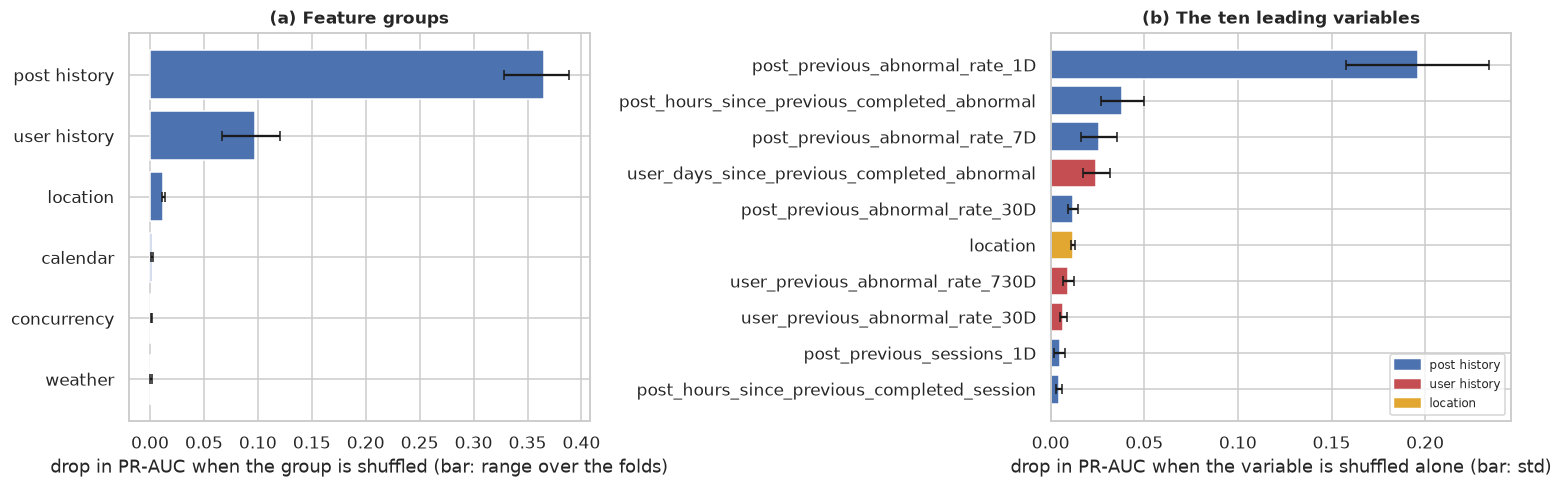

,permutation drop (final model),Task 3 ablation gain
post history,0.3657,0.2938
user history,0.0974,0.0270
location,0.0121,—
calendar,0.0016,—
concurrency,0.0011,—
weather,0.0007,—


Task 3 ablation gains: post history = S3 - S2; user history (with concurrency) = selected set - selected set without user history.


In [137]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
g = group_table.iloc[::-1]
fold_part = g[[c for c in g.columns if c.startswith("fold")]]
axes[0].barh(g.index, g["PR-AUC drop"], color=C_NORMAL, xerr=[g["PR-AUC drop"] - fold_part.min(axis=1), fold_part.max(axis=1) - g["PR-AUC drop"]], capsize=3)
axes[0].set_xlabel("drop in PR-AUC when the group is shuffled (bar: range over the folds)")
axes[0].set_title("(a) Feature groups")
v = var_table.head(10).iloc[::-1]
palette = dict(zip(INTERP_GROUPS, [C_GREY, C_ORANGE, C_GREEN, C_NORMAL, C_ABN, C_PURPLE]))
axes[1].barh(v.index, v["PR-AUC drop"], xerr=v["std"], color=[palette[x] for x in v["group"]], capsize=3)
axes[1].set_xlabel("drop in PR-AUC when the variable is shuffled alone (bar: std)")
axes[1].set_title("(b) The ten leading variables")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[x]) for x in dict.fromkeys(v["group"][::-1])], labels=list(dict.fromkeys(v["group"][::-1])),
               fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "10_importance")

ablation = TASK3["ablation"]
ablation_gain = {"post history": ablation["S3 + post history"]["PR-AUC mean"] - ablation["S2 + tariff"]["PR-AUC mean"],
                 "user history": ablation["S4 without post_id and tariff (selected)"]["PR-AUC mean"] - ablation["selected without user history"]["PR-AUC mean"]}
compare = pd.DataFrame({"permutation drop (final model)": group_table["PR-AUC drop"],
                        "Task 3 ablation gain": pd.Series(ablation_gain)}).loc[group_table.index]
display(compare.style.format("{:.4f}", na_rep="—"))
print("Task 3 ablation gains: post history = S3 - S2; user history (with concurrency) = selected set - selected set without user history.")
IMPORTANCE = {"groups": [{"name": g, "PR-AUC drop": float(r["PR-AUC drop"]), "std": float(r["std"]),
                          "per fold": {c: float(r[c]) for c in by_fold.columns}} for g, r in group_table.iterrows()],
              "variables": [{"name": v_, "PR-AUC drop": float(r["PR-AUC drop"]), "std": float(r["std"])} for v_, r in var_table.iterrows()]}
log_decision("10", "Interpretation method",
             "Group and single-variable permutation importance (drop in PR-AUC) on the four validation quarters, with fold-specific fits of the frozen configuration.",
             "Model-agnostic and measured on unseen sessions; groups are shuffled jointly because the history windows are correlated; descriptive only, no frozen choice changes.")
assert len(DECISIONS) == N_DECISIONS_AT_FREEZE + 2            # the extra entry describes the method; it changes no model, feature or cut-off

The model depends mostly on the post history. Shuffling its eight variables together lowers the PR-AUC by 0.366 on average, between 0.328
and 0.388 depending on the fold. User history comes second with 0.097, and its importance shrinks over time (0.108 in fold 1, 0.067 in fold
4). Location costs 0.012, and the calendar, concurrency and weather groups less than 0.002 each, so the model barely uses them. The leading
single variable is the abnormal rate of the post over the last day (0.196), well ahead of the time since the post's last abnormal session
(0.038) and the 7-day rate used by B1 (0.026). The most recent window carries the most information once the model has it.

The ranking of the groups agrees with the Task 3 ablation, but the sizes differ. Removing the post history and retraining cost 0.294 in Task
3, and removing user history cost 0.027, against permutation drops of 0.366 and 0.097 here. The two methods answer different questions.
Permutation measures how much this fitted model uses a group; the ablation measures what is lost when the model is retrained without it, and
a retrained model can partly replace user history with post history. User history is therefore used a lot by the model but adds only a
little that the other groups cannot recover.

Permutation importance has three limits in our setting. Correlated variables share their importance: when one window is shuffled alone, the
other windows still carry part of its information, so single-variable drops understate a variable's role. Shuffling whole groups avoids this
for the group ranking. It measures how the model uses a variable, not whether that variable causes failures. And it is computed on the four
validation quarters, not on the test period, so it describes the model as developed, before the change observed in Section 9.

---
## 11. Conclusions and limitations

### 11.1 Conclusions

The search over 93 configurations confirmed the Task 3 configurations instead of improving them. For gradient boosting and the random
forest, almost every configuration lies within our tolerance of 0.005 of the best, and for the decision tree the only real lever is the
minimum leaf size. The final model is gradient boosting with its Task 3 configuration, chosen over the random forest on the worst fold.

We chose the cut-off from a 10% alert budget on the pooled out-of-fold predictions. It is 0.490, almost the default 0.50, because the scores
are close to calibrated, so no calibration step is needed for an alert budget. On development, this cut-off gives 74 correct alerts, 26
false alerts and 110 missed failures per 1,000 sessions, and of the three budgets of the protocol it is the last one where extra alerts are
more often right than wrong.

On the test period the model scores a PR-AUC of 0.532, against 0.381 for B1 and 0.178 for B0. It keeps a clear and even larger advantage
over the simple rule, but both lose much of their development level, and with the frozen cut-off the model flags 7.4% of the sessions with a
precision of 0.677. The model relies mostly on recent post failures and then on the user's history, and the weakening of the post-failure
signal in the last quarter of 2021, visible in B1 as well, is the most likely reason for the drop.

### 11.2 Limitations

The search, the tie rule and the final choice all used the same four folds, so the development estimate of 0.626 is slightly optimistic; the
test result is the unbiased check, and it is one quarter of 80,081 sessions from a single period, so it measures this quarter and not a
long-run average. The drop from development to test shows that the relation between recent post failures and the next failure can change, so
the development estimates may not hold in later periods; we did not investigate the cause on the test data, because the test is only scored,
never explored. The gradient-boosting search still chose the smallest number of iterations after one widening, so the boosting range was not
fully explored on that side, although every configuration near it lies within the tolerance. The 10% budget is a choice, not a measured
inspection capacity, and at 0.490 it implies treating a missed failure as costing about the same as a false alert, which is lower than the
cost argued in Task 2. The calibration check covers the development quarters only. Permutation importance shares importance among correlated
variables, measures use rather than cause, and describes the model on the validation quarters, not the test period.

---
## 12. Saved files and decision log

The results are saved so that the report and any later work can use them without repeating the search: the search results, the per-fold
metrics of the initial and chosen configurations and of the baselines, the frozen choices (already written in Section 8), the summary of the
operating points, the calibration check, the test result and the importance, and the decision log.

In [138]:
for (label, fold), p in PREDS.items():
    assert len(p) == fold_table.loc[fold, "validation sessions"], (label, fold)       # one prediction per validation session
assert SELECTED == TASK3["selected_features"] == FROZEN["features"]
assert FROZEN["configuration"] == FINAL_LABEL and FROZEN["cut_off"] == CUT_OFF and FROZEN["model"] == FINAL_MODEL
assert TEST_SCORED and sum(r["scope"] == "test" for r in OPERATING_POINTS) == 2                # the test period was scored once
assert df["start_time"].max() < TEST_START                                                       # the development frame never held a test row

search_rows.to_csv(OUT_DIR / "task4_search.csv", index=False)
fold_labels = BASELINES + list(dict.fromkeys(list(INITIAL.values()) + list(CHOSEN.values())))
fold_metrics = pd.concat(METRICS)
fold_metrics = fold_metrics[fold_metrics["model"].isin(fold_labels)].drop_duplicates(["model", "fold"]).reset_index(drop=True)
assert all(fold_metrics.loc[fold_metrics["fold"] == f["fold"], "validation sessions"].eq(len(f["valid"])).all() for f in FOLDS)
fold_metrics.to_csv(OUT_DIR / "task4_fold_metrics.csv", index=False)

results = {
    "protocol": "prepared/task2_protocol.json (folds, metrics, alert budgets); test rows dropped right after reading until Section 9, "
                "read again only after prepared/task4_frozen.json was written, and scored once",
    "tolerance": TOLERANCE,
    "selected_models": SELECTED_MODELS,
    "search_spaces": {name: {"grid": GRID_VALUES[name], "order": ORDER[name], "extended": EXTENDED[name]} for name in GRID_VALUES},
    "chosen_configurations": CHOSEN,
    "verdicts": [{k: v for k, v in r.items()} for r in VERDICTS],
    "final_model": FINAL_LABEL,
    "operating_points": [{"name": r["name"], "cut_off": r["cut-off"], "scope": r["scope"], "precision": r["precision"], "recall": r["recall"],
                          "F1": r["F1"], "alert rate": r["alert rate"], "correct per 1,000": r["correct per 1,000"],
                          "false per 1,000": r["false per 1,000"], "missed per 1,000": r["missed per 1,000"]} for r in OPERATING_POINTS],
    "per_fold_cut_offs": PER_FOLD_CUT_OFFS,
    "calibration": CALIBRATION,
    "test": TEST_RESULT,
    "importance": IMPORTANCE,
}
clean = json.loads(json.dumps(results, default=float).replace("NaN", "null"))
(OUT_DIR / "task4_results.json").write_text(json.dumps(clean, indent=2, ensure_ascii=False))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task4_decision_log.csv", index=False)
print("Saved:", *(OUT_DIR / n for n in ["task4_frozen.json", "task4_search.csv", "task4_fold_metrics.csv", "task4_results.json", "task4_decision_log.csv"]),
      "| figures in", FIG_DIR)
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: prepared/task4_frozen.json prepared/task4_search.csv prepared/task4_fold_metrics.csv prepared/task4_results.json prepared/task4_decision_log.csv | figures in prepared/figures_task4


section,topic,decision,evidence
3,Models chosen for optimisation,"Gradient boosting, random forest and decision tree (boosting, bagging with random features, single tree). Stacking, logistic regression and Naive Bayes are not searched.","Task 3 mean PR-AUC 0.626, 0.622 and 0.597; boosting and the forest differ by 0.003 (inside the tolerance); the tree is the best individual model. Stacking is 0.015 behind boosting; LR gave the same PR-AUC for C = 0.01 and C = 1; NB smoothing does not address its independence assumption."
4,Search procedure,"Exhaustive grid per model (36, 12 and 40 configurations) on the four development folds; objective = unweighted mean PR-AUC; simplest configuration within 0.005 of the best; a range is widened once if the choice lies on its edge.","Same folds, runner and selection rule as Task 3, so initial and optimised configurations are chosen the same way; no random split and no early stopping; the test period plays the outer role of a nested search."
4,Gradient boosting configuration,"HGB depth=4, lr=0.1, 100 it, leaf=200.","Mean PR-AUC 0.6235, worst fold 0.570, rank 29 of 39; edge rule: {'max_depth': [3], 'min_samples_leaf': [400], 'max_iter': [100]}."
4,Random forest configuration,"RF leaf=100, features=9.","Mean PR-AUC 0.6234, worst fold 0.567, rank 10 of 13; edge rule: {'min_samples_leaf': [200]}."
4,Decision tree configuration,"DT depth=8, leaf=400, entropy.","Mean PR-AUC 0.5994, worst fold 0.541, rank 15 of 41; edge rule: {'min_samples_leaf': [800]}."
5,Optimisation verdict,Gradient boosting: Task 3 configuration kept; Random forest: Task 3 configuration kept; Decision tree: Task 3 configuration kept.,"Gradient boosting HGB depth=4, lr=0.1, 100 it, leaf=200 vs HGB depth=6, lr=0.1, 200 it, leaf=100: mean gain -0.0023, 1 of 4 folds won; Random forest RF leaf=100, features=9 vs RF leaf=50, features=sqrt: mean gain +0.0010, 4 of 4 folds won; Decision tree DT depth=8, leaf=400, entropy vs DT depth=8, leaf=100, gini: mean gain +0.0020, 3 of 4 folds won. Adopted only if gain > 0.005 and at least 3 of 4 folds won."
5,Final model,"Gradient boosting: HGB depth=6, lr=0.1, 200 it, leaf=100.","Mean PR-AUC 0.6258, worst fold 0.575; contenders within 0.005: Gradient boosting, Random forest; gain over B1 +0.1152 (4 of 4)."
6,Threshold criterion,Alert-rate constraint: the cut-off flags 10% of the pooled out-of-fold development predictions of the final model.,"Cost ratio and inspection capacity are unknown; the protocol excludes F1 from selection; 10% is the middle of the protocol's 5%, 10% and 20% budgets; each pooled score comes from a model that did not see that session."
7,Calibration,No calibrator; scores used as a ranking for the 10% alert budget.,Pooled out-of-fold Brier score 0.1032 against 0.1500 for the constant prior; largest gap between mean predicted and observed share over ten equal-frequency bands 0.015; a monotone calibrator would not change which sessions are flagged.
8,Frozen choices,"Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100), 27 Task 3 features, cut-off 0.4899, no calibrator; written to prepared/task4_frozen.json.","Frozen at 2026-10-30T14:03:17, before the test period is read; development estimates: mean PR-AUC 0.6258, precision 0.740 and recall 0.403 at the cut-off."


---
## 13. Final comparison and model description

The final submission asks for one table that compares the candidate, baseline and final models, and for one description of the final
preprocessing, feature set, hyperparameters and threshold. This section gathers both from the files that Tasks 3 and 4 have already saved,
so every number in it can be traced to an earlier section. It fits no model and reads no test row: the only test numbers are the ones
Section 9 produced for the final model and the two baselines, and no other candidate is scored on the test period.

In [139]:
# Everything is read back from the saved files, so this section can be checked on its own and cannot change an earlier result.
T3 = json.loads((OUT_DIR / "task3_results.json").read_text())
T4 = json.loads((OUT_DIR / "task4_results.json").read_text())
FROZEN_FILE = json.loads((OUT_DIR / "task4_frozen.json").read_text())
t4_folds = pd.read_csv(OUT_DIR / "task4_fold_metrics.csv")
B0_LABEL, B1_LABEL = "B0 no skill", "B1 post failure rate (7 days)"
t3_rows = {r["model"] if r["model"].startswith("B") else r["model"].split(" (")[0]: r for r in T3["comparison"]}   # by model name, not label
test_pr = {m["model"]: m["PR-AUC"] for m in T4["test"]["models"]}                 # the single test evaluation of Section 9
b1_folds = t4_folds[t4_folds["model"] == B1_LABEL].set_index("fold")["PR-AUC"]
assert abs(b1_folds.mean() - t3_rows[B1_LABEL]["PR-AUC mean"]) < 1e-9             # Tasks 3 and 4 share the same baseline


def task3_row(block, name, configuration):
    r = t3_rows[name]
    return {"block": block, "model": name, "configuration": configuration, "dev PR-AUC mean": r["PR-AUC mean"], "worst fold": r["worst fold"],
            "gain over B1": r["gain over B1"], "folds won vs B1": r["folds won vs B1"], "test PR-AUC": test_pr.get(name, np.nan), "is final": False}


def task4_row(block, name, label):
    folds = t4_folds[t4_folds["model"] == label].set_index("fold")["PR-AUC"]
    assert len(folds) == 4, label
    return {"block": block, "model": name, "configuration": label, "dev PR-AUC mean": folds.mean(), "worst fold": folds.min(),
            "gain over B1": folds.mean() - b1_folds.mean(), "folds won vs B1": f"{int((folds > b1_folds).sum())} of 4",
            "test PR-AUC": test_pr[name] if block == "final" else np.nan, "is final": block == "final"}


CANDIDATES = ["Logistic regression", "Naive Bayes", "Decision tree", "Random forest", "Gradient boosting", "Stacking"]
rows = [task3_row("baseline", B0_LABEL, "random score"), task3_row("baseline", B1_LABEL, "share of abnormal sessions at the post, last 7 days")]
rows += [task3_row("candidate", name, T3["selected_configurations"][name]) for name in CANDIDATES]
rows += [task4_row("optimised", v["model"], v["optimised"]) for v in T4["verdicts"]]
rows += [task4_row("final", FROZEN_FILE["model"], FROZEN_FILE["configuration"])]
final_comparison = pd.DataFrame(rows)
for name in CANDIDATES:                                                            # candidates were never scored on the test period
    final_comparison.loc[final_comparison["model"].eq(name) & final_comparison["block"].eq("candidate"), "test PR-AUC"] = np.nan

final_row = final_comparison[final_comparison["is final"]].iloc[0]
assert len(final_comparison) == 12
assert final_comparison["block"].value_counts().to_dict() == {"candidate": 6, "optimised": 3, "baseline": 2, "final": 1}
assert final_comparison["test PR-AUC"].notna().sum() == 3
assert set(final_comparison.loc[final_comparison["test PR-AUC"].notna(), "model"]) == {FROZEN_FILE["model"], B0_LABEL, B1_LABEL}
assert final_row["dev PR-AUC mean"] == FROZEN_FILE["development_estimates"]["PR-AUC mean"]
assert abs(final_row["dev PR-AUC mean"] - t3_rows["Gradient boosting"]["PR-AUC mean"]) < 1e-5     # the Task 3 and Task 4 runs differ by about 2e-6
assert final_row["worst fold"] == t3_rows["Gradient boosting"]["worst fold"]
assert final_row["test PR-AUC"] == T4["test"]["models"][0]["PR-AUC"] and T4["test"]["models"][0]["model"] == FROZEN_FILE["model"]
assert globals().get("TEST_SCORED", True)                                          # in the full run, the test was scored in Section 9

final_comparison.to_csv(OUT_DIR / "final_comparison.csv", index=False)
print(f"B1 mean development PR-AUC {b1_folds.mean():.3f}; test PR-AUC only for {FROZEN_FILE['model']}, B0 and B1")
display(final_comparison.drop(columns="is final").set_index(["block", "model"]).style
        .format({"dev PR-AUC mean": "{:.3f}", "worst fold": "{:.3f}", "gain over B1": "{:+.3f}", "test PR-AUC": "{:.3f}"}, na_rep="—")
        .apply(lambda r: ["font-weight: bold" if r.name[0] == "final" else ""] * len(r), axis=1))

B1 mean development PR-AUC 0.511; test PR-AUC only for Gradient boosting, B0 and B1


In [140]:
import sklearn

feature_groups = {group: [f for f in features if f in FROZEN_FILE["features"]] for group, features in GROUPS.items()}
feature_groups = {group: features for group, features in feature_groups.items() if features}    # tariff and post_id were dropped in Task 3
categorical = [f for f in FROZEN_FILE["features"] if f in FEATURE_GROUPS["categorical"]]
dev = FROZEN_FILE["development_estimates"]
final_model = {
    "data": {"development": f"sessions starting from {BURN_IN_END.date()} (end of the burn-in) and before {TEST_START.date()}",
             "folds": "four expanding-window folds with a purge gap (Task 2 protocol), used for every choice",
             "final training": f"all development sessions that ended before {TEST_START.date()}, so every label was known before the test",
             "test": f"sessions starting from {TEST_START.date()}, scored once with the frozen choices"},
    "target": {"positive": PROTOCOL["problem"]["positive_class"], "negative": PROTOCOL["problem"]["negative_class"],
               "prediction moment": PROTOCOL["problem"]["prediction_moment"]},
    "preprocessing": {"categories": f"{', '.join(categorical)}: ordinal codes learned on the training window; an unseen category is treated as missing",
                      "numeric features": "used as they are: no scaling and no log transform, since the trees only use the order of the values",
                      "missing values": "kept as missing; the model sends them to the better side of each split, so nothing is imputed",
                      "class imbalance": "no resampling and no class weights",
                      "fitted on": "every learned step is fitted on the training window only (learned-operations ledger, Task 1)"},
    "feature_groups": feature_groups,
    "hyperparameters": FROZEN_FILE["hyperparameters"],
    "fixed_settings": {"early_stopping": False, "random_state": SEED, "categorical_features": categorical,
                       "other settings": f"scikit-learn {sklearn.__version__} defaults"},
    "threshold": {"criterion": FROZEN_FILE["criterion"], "cut_off": FROZEN_FILE["cut_off"], "alert rate": dev["alert rate"],
                  "precision": dev["precision"], "recall": dev["recall"]},
    "calibration": {"decision": FROZEN_FILE["calibration"], "reason": T4["calibration"]["decision"]},
    "decided_in": {"data": "report Sections 3.1 and 4.5", "target": "report Section 1.1", "preprocessing": "report Section 3.3",
                   "feature_groups": "report Section 5.1", "hyperparameters": "report Sections 6.1 and 6.2",
                   "threshold": "report Section 6.3", "calibration": "report Section 6.4"},
}

assert sorted(sum(feature_groups.values(), [])) == sorted(FROZEN_FILE["features"]) and len(FROZEN_FILE["features"]) == 27
assert final_model["hyperparameters"] == FROZEN_FILE["hyperparameters"]
assert final_model["threshold"]["cut_off"] == FROZEN_FILE["cut_off"] and final_model["calibration"]["decision"] == FROZEN_FILE["calibration"]
(OUT_DIR / "final_model.json").write_text(json.dumps(final_model, indent=2, ensure_ascii=False, default=float))

summary = {"model": f"{FROZEN_FILE['model']} ({FROZEN_FILE['configuration']})",
           "features": "; ".join(f"{group} ({len(features)})" for group, features in feature_groups.items()) + f" = {len(FROZEN_FILE['features'])}",
           "hyperparameters": ", ".join(f"{k} = {v}" for k, v in FROZEN_FILE["hyperparameters"].items()) + ", no early stopping, seed 42",
           "preprocessing": f"ordinal codes for {' and '.join(categorical)} (fitted on the training window); numeric features and missing values unchanged",
           "threshold": f"{FROZEN_FILE['criterion']}: cut-off {FROZEN_FILE['cut_off']:.3f} "
                        f"(development precision {dev['precision']:.3f}, recall {dev['recall']:.3f}, alert rate {dev['alert rate']:.1%})",
           "calibration": final_model["calibration"]["decision"]}
display(pd.DataFrame.from_dict(summary, orient="index", columns=["final choice"]))

,final choice
model,"Gradient boosting (HGB depth=6, lr=0.1, 200 it, leaf=100)"
features,calendar (2); location (2); weather (4); post_history (8); user_history (10); concurrency (1) = 27
hyperparameters,"max_depth = 6, learning_rate = 0.1, max_iter = 200, min_samples_leaf = 100, no early stopping, seed 42"
preprocessing,ordinal codes for location and district (fitted on the training window); numeric features and missing values unchanged
threshold,"alert rate 10% of pooled out-of-fold predictions: cut-off 0.490 (development precision 0.740, recall 0.403, alert rate 10.0%)"
calibration,none


Gradient boosting leads the six Task 3 candidates with a mean PR-AUC of 0.626 and
beats B1 in all four folds, but the random forest is only 0.003 behind, inside our tolerance of 0.005, which is why Section 5 chose
between them on the worst fold (0.575 against 0.567). The three configurations found by the searches of Section 4 stay within 0.003 of
their Task 3 versions and none passed the rule of Section 5, so they are listed but not kept. The final row is the Task 3 configuration
refitted in this notebook, and its development numbers equal the Task 3 row. Only three rows have a test score, the ones Section 9
scored: 0.532 for the final model, against 0.381 for B1 and 0.178 for B0.

The description restates the choices frozen in Section 8 in a readable form, and the assertions check that its features,
hyperparameters, cut-off and calibration decision are the ones in `prepared/task4_frozen.json`. Chapter 7 of the report is built from
these two files.

# Part 5 · Task 5: Final model selection and evaluation

In [141]:
# each part starts from an empty namespace, as when the task notebooks ran on their own
%reset -f

## TP1 · Task 5: Final model selection and evaluation
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 5 closes the project. We justify the choice of the final model with development results only, refit it on all development data
with every decision fixed, compare it with the baseline on the final test period, and then study where and why it works or fails: over
time, across districts, stations and charging posts, and in its false positives and false negatives. We interpret the model, explain what
the selected threshold means in practice, and judge whether the model would be useful to the operator.

Task 4 already scored the test period once, on 2026-10-27, because its brief asks for it.
This notebook starts from the same frozen file (`prepared/task4_frozen.json`), refits the same model and reproduces the Task 4 test
numbers in Section 4 as a check. No model, feature, hyperparameter or cut-off is changed. Everything that uses the test labels after that
point (subgroups, error analysis, importance on the test period) is descriptive and cannot change a decision.

### How to read this notebook

| # | Section | Requirement of the Task 5 brief |
|---|---------|---------------------------------|
| 1 | Setup and inputs | — |
| 2 | Selecting the final model and the baseline | selection with training and validation results only: performance, temporal stability, computational cost, interpretability, operational implications; an appropriate baseline |
| 3 | Refit on all development data and fix the decisions | refit on all development data; preprocessing, features, hyperparameters and threshold fixed before the test |
| 4 | Scoring the test period | one evaluation on the final test period |
| 5 | Final model against the baseline | PR-AUC; precision, recall, F1; balanced accuracy, MCC; alert rate; correct, false and missed alerts per 1,000 sessions |
| 6 | Performance across time | relevant time periods |
| 7 | Performance across operational groups | districts, charging posts (and stations, users) |
| 8 | Error analysis | patterns in false positives and false negatives |
| 9 | Interpretation of the final model | a suitable method and the limits of the interpretation |
| 10 | Practical consequences of the threshold | consequences of the selected threshold; is the model useful in the operational setting? |
| 11 | Conclusions, limitations and recommendations | main findings, limitations, future improvements |
| 12 | Saved files and decision log | — |

The notebook reads what Tasks 2 to 4 saved in `prepared/`: the evaluation protocol, the feature groups, the Task 3 results, the Task 4
results, the frozen choices and the final model description. Sections 1 and 2 use only development results. The test rows of the course
file are dropped when the file is read and come back only in Section 4, after the frozen file has been checked.

---
## 1. Setup and inputs

In [142]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binomtest, spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task5"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
TASK3 = json.loads((OUT_DIR / "task3_results.json").read_text())
TASK4 = json.loads((OUT_DIR / "task4_results.json").read_text())
TASK4_TEST = TASK4.pop("test")          # kept aside: used only in Section 4 to check the reproduction, never for a choice
FINAL_JSON = json.loads((OUT_DIR / "final_model.json").read_text())
FROZEN_FILE = OUT_DIR / "task4_frozen.json"
FROZEN_HASH = hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()
FROZEN = json.loads(FROZEN_FILE.read_text())

BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
TOLERANCE = TASK3["tolerance"]                     # practical tolerance of Task 3 for small PR-AUC differences
FEATURES = FROZEN["features"]
CUT_OFF = FROZEN["cut_off"]
assert FEATURES == TASK3["selected_features"] and len(FEATURES) == 27
assert FINAL_JSON["threshold"]["cut_off"] == CUT_OFF and FINAL_JSON["hyperparameters"] == FROZEN["hyperparameters"]

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 12)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


print(f"Frozen file: {FROZEN['model']}, {FROZEN['configuration']}, cut-off {CUT_OFF:.4f}, frozen at {FROZEN['frozen_at']}")
print(f"SHA-256 of the frozen file: {FROZEN_HASH}")
print(f"Features: {len(FEATURES)} | tolerance {TOLERANCE} | test period from {TEST_START.date()}")

Frozen file: Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, cut-off 0.4899, frozen at 2026-10-30T14:03:17
SHA-256 of the frozen file: 9f111a92abfd5d8a112bea86d4addbc2b76ed9cf2d19fa23a8f7d9dac4c5b9f6
Features: 27 | tolerance 0.005 | test period from 2021-10-01


---
## 2. Selecting the final model and the baseline

The brief asks us to select the final model *using only the results obtained from the training and validation data*, and to weigh
predictive performance, temporal stability, computational cost, interpretability and operational implications. Everything in this section
comes from files that hold development results: the Task 3 comparison of six models, the Task 4 verdicts on the optimised configurations,
and the Task 4 operating point and calibration check. The test results saved by Task 4 were set aside when the file was read.

### 2.1 The candidates and the five criteria

The table repeats the Task 3 comparison on the four temporal folds (unweighted mean of the fold metrics) and adds, for each model, how
readable it is. The last column marks the models whose mean PR-AUC lies within the practical tolerance of 0.005 of the best one.

In [143]:
INTERPRETABILITY = {
    "Logistic regression": ("high", "one coefficient per variable, but it needs the linear view (scaling, one-hot, logs)"),
    "Naive Bayes": ("high", "one likelihood per variable, under an independence assumption that does not hold here"),
    "Decision tree": ("high", "depth-8 tree that can be read as rules"),
    "Random forest": ("low", "200 deep trees; only importance methods can describe it"),
    "Gradient boosting": ("low", "200 shallow trees; only importance methods can describe it"),
    "Stacking": ("lowest", "three base models and a meta-model, with a time-ordered inner loop"),
}
rows = []
for record in TASK3["comparison"]:
    name = record["model"].split(" (")[0]
    if name.startswith("B"):
        continue
    rows.append({"model": name, "configuration": record["model"].split(" (")[1].rstrip(")") if " (" in record["model"] else "",
                 "PR-AUC mean": record["PR-AUC mean"], "std": record["std"], "worst fold": record["worst fold"], "trend": record["trend"],
                 "folds won vs B1": record["folds won vs B1"], "ROC-AUC": record["ROC-AUC"], "Brier": record["Brier"],
                 "seconds per fold": record["seconds per fold"], "readability": INTERPRETABILITY[name][0]})
candidates = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False)
candidates["within tolerance of the best"] = np.where(candidates["PR-AUC mean"] >= candidates["PR-AUC mean"].max() - TOLERANCE, "yes", "")
display(candidates.style.format({"PR-AUC mean": "{:.4f}", "std": "{:.4f}", "worst fold": "{:.4f}", "trend": "{:+.4f}", "ROC-AUC": "{:.3f}",
                                 "Brier": "{:.4f}", "seconds per fold": "{:.1f}"}))
print("How each model can be read:")
for name, (level, note) in INTERPRETABILITY.items():
    print(f"  {name}: {note}")

,configuration,PR-AUC mean,std,worst fold,trend,folds won vs B1,ROC-AUC,Brier,seconds per fold,readability,within tolerance of the best
model,,,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it",0.6258,0.0382,0.5755,+0.0203,4 of 4,0.836,0.1020,3.0,low,yes
Random forest,RF leaf=50,0.6224,0.0420,0.5666,+0.0219,4 of 4,0.835,0.1025,12.1,low,yes
Stacking,LR + NB + DT,0.6105,0.0415,0.5556,+0.0219,4 of 4,0.831,0.1038,13.5,lowest,
Decision tree,DT depth=8,0.5974,0.0412,0.5440,+0.0226,4 of 4,0.824,0.1046,2.5,high,
Logistic regression,LR C=0.01,0.5925,0.0421,0.5345,+0.0201,4 of 4,0.825,0.1061,2.3,high,
Naive Bayes,NB,0.5251,0.0375,0.4716,+0.0120,3 of 4,0.814,0.1719,0.7,high,


How each model can be read:
  Logistic regression: one coefficient per variable, but it needs the linear view (scaling, one-hot, logs)
  Naive Bayes: one likelihood per variable, under an independence assumption that does not hold here
  Decision tree: depth-8 tree that can be read as rules
  Random forest: 200 deep trees; only importance methods can describe it
  Gradient boosting: 200 shallow trees; only importance methods can describe it
  Stacking: three base models and a meta-model, with a time-ordered inner loop


The six models span a mean PR-AUC from 0.525 (Naive Bayes) to 0.626 (gradient boosting). Only the random forest (0.622) is within the tolerance of 0.005 of the best: the gap is 0.0034, which Task 3 could
not separate from the fold-to-fold noise. Stacking is 0.015 behind, the decision tree 0.028 and logistic regression 0.033. Every model except Naive Bayes beats B1 in all four folds, and the standard
deviation across folds is similar for all of them (0.037 to 0.042), so stability does not rank the models by itself. The computational cost does: a fold takes 3.2 s for gradient boosting, 12.6 s for the forest and 14.1 s for stacking.
The Brier score of the six models goes from 0.102 to 0.172, and the two tree ensembles at the top have the lowest values (0.1020 and 0.1025).

### 2.2 The selection rule applied step by step

The rule is the one of Tasks 2 to 4, with the two extra criteria of this brief at the end. Step 1 keeps the models whose mean PR-AUC is within
0.005 of the best, because Task 3 showed that a smaller difference cannot be separated from the fold-to-fold noise. Step 2 compares those
models on temporal stability (worst fold and standard deviation across folds). Step 3 compares their computational cost, step 4 their
readability and step 5 how usable their scores are as probabilities.

In [144]:
step1 = candidates[candidates["within tolerance of the best"] == "yes"]
step2 = step1.sort_values(["worst fold", "std"], ascending=[False, True])
rule = pd.DataFrame({
    "step 1: mean PR-AUC": step1["PR-AUC mean"],
    "step 2: worst fold": step1["worst fold"],
    "step 2: std across folds": step1["std"],
    "step 3: seconds per fold": step1["seconds per fold"],
    "step 4: readability": step1["readability"],
    "step 5: Brier": step1["Brier"],
})
display(rule.style.format({"step 1: mean PR-AUC": "{:.4f}", "step 2: worst fold": "{:.4f}", "step 2: std across folds": "{:.4f}",
                           "step 3: seconds per fold": "{:.1f}", "step 5: Brier": "{:.4f}"}))
SELECTED_NAME = step2.index[0]
print(f"Models within the tolerance: {list(step1.index)}")
print(f"Best worst fold and lowest std among them: {SELECTED_NAME}")
assert SELECTED_NAME == FROZEN["model"]
gap = candidates["PR-AUC mean"].max() - step1["PR-AUC mean"]
print(f"Mean PR-AUC gap inside the tolerance: {gap.to_dict()}")

,step 1: mean PR-AUC,step 2: worst fold,step 2: std across folds,step 3: seconds per fold,step 4: readability,step 5: Brier
model,,,,,,
Gradient boosting,0.6258,0.5755,0.0382,3.0,low,0.1020
Random forest,0.6224,0.5666,0.0420,12.1,low,0.1025


Models within the tolerance: ['Gradient boosting', 'Random forest']
Best worst fold and lowest std among them: Gradient boosting
Mean PR-AUC gap inside the tolerance: {'Gradient boosting': 0.0, 'Random forest': 0.0033588767900050165}


Step 1 leaves two models, gradient boosting and the random forest. In step 2, gradient boosting has the better worst fold (0.5755 against 0.5666) and the lower standard deviation (0.038 against 0.042). In step 3 it is about four times
cheaper to fit (3.2 s against 12.6 s per fold; the final refit of Section 3.2 takes 5 s), which matters for an operator who must refit the model every time the failure pattern changes. Steps 4 and 5 do not separate the two: both are ensembles of trees that
can be described only with importance methods (Section 9), and their Brier scores differ by 0.0005. The readable models are all well outside the tolerance: the best of them, the decision tree, loses 0.028 of PR-AUC, which is
more than five times the tolerance, so readability alone cannot justify it as the final model. The choice therefore rests on temporal stability and cost, with the Task 4 evidence of Section 2.3 and the calibration check of Section 2.5 supporting it.

### 2.3 Was the initial configuration improved? (Task 4)

The final model could still have been a tuned version of the winner. Task 4 searched the hyperparameters of gradient boosting, the random
forest and the decision tree, and kept a tuned configuration only if its gain was meaningful (above 0.005) and stable (better in at least three
of the four folds). The saved verdicts follow.

In [145]:
verdicts = pd.DataFrame(TASK4["verdicts"]).set_index("model")
display(verdicts[["initial", "optimised", "mean gain", "folds won", "worst-fold gain", "meaningful", "stable", "kept"]]
        .style.format({"mean gain": "{:+.4f}", "worst-fold gain": "{:+.4f}"}))
assert TASK4["final_model"] == FROZEN["configuration"] and not verdicts["meaningful"].any()

,initial,optimised,mean gain,folds won,worst-fold gain,meaningful,stable,kept
model,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100","HGB depth=4, lr=0.1, 100 it, leaf=200",-0.0023,1,-0.0056,False,False,"HGB depth=6, lr=0.1, 200 it, leaf=100"
Random forest,"RF leaf=50, features=sqrt","RF leaf=100, features=9",+0.0010,4,+0.0009,False,True,"RF leaf=50, features=sqrt"
Decision tree,"DT depth=8, leaf=100, gini","DT depth=8, leaf=400, entropy",+0.0020,3,-0.0029,False,True,"DT depth=8, leaf=100, gini"


No tuned configuration passes the rule. The gains over the Task 3 configurations are −0.0023 for gradient boosting, +0.0010 for the forest and +0.0020 for the tree, all well below the 0.005 that makes a gain meaningful. The tuned boosting configuration is also
worse in three of the four folds and by 0.0056 in its worst fold, so it is neither meaningful nor stable. The final model is the initial gradient-boosting configuration, selected before any test result existed.

### 2.4 The baseline

A baseline must be available at the same moment as the model, fit nothing, and give a score that can be read with the same metrics. B1,
the share of abnormal sessions at the post in the last 7 days (`post_previous_abnormal_rate_7D`), fulfils the three conditions and is the strongest single
start-time signal of Task 1. B0, a random score, is the floor that shows what no skill gives. The comparison of Section 5 uses B1 as the baseline
and B0 as the reference for chance. The table repeats their development results.

In [146]:
base_rows = [r for r in TASK3["comparison"] if r["model"].startswith("B")]
base_table = pd.DataFrame(base_rows).set_index("model")[["PR-AUC mean", "worst fold", "lift", "ROC-AUC", "Brier"]]
display(base_table.style.format({"PR-AUC mean": "{:.4f}", "worst fold": "{:.4f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}"}))

,PR-AUC mean,worst fold,lift,ROC-AUC,Brier
model,,,,,
B1 post failure rate (7 days),0.5106,0.4562,2.85,0.772,0.1176
B0 no skill,0.1812,0.1615,1.01,0.504,0.1478


B1 reaches a mean PR-AUC of 0.511 (lift 2.85, ROC-AUC 0.772) against 0.181 for B0, whose PR-AUC equals the abnormal share and whose ROC-AUC is 0.504, as the Task 2 theory predicts. B1 is a demanding baseline because it already captures the strongest
single start-time signal, and it is the one an operator could apply today with no model. The final model has to beat it with margin; on development it does so in all four folds, with a mean gain of 0.115. We use B1 as the baseline in Section 5 and keep B0 only as the reference for chance.

### 2.5 The threshold chosen in Task 4

The threshold was chosen in Task 4 from the pooled out-of-fold development predictions with one criterion, an alert rate of 10%, and then frozen.
The table gives its development operating point and the calibration check that decided that no calibrator was needed.

In [147]:
dev_point = next(p for p in TASK4["operating_points"] if p["name"] == "selected" and p["scope"] == "pooled")
default_point = next(p for p in TASK4["operating_points"] if p["name"] == "default 0.50" and p["scope"] == "pooled")
OPF = {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}",
       "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
display(pd.DataFrame([{"name": p["name"], "cut-off": p["cut_off"], **{k: p[k] for k in OPF if k != "cut-off"}} for p in (default_point, dev_point)]).set_index("name").style.format(OPF))
cal = TASK4["calibration"]
print(f"Calibration check (development): Brier {cal['Brier']:.4f} against {cal['Brier constant prior']:.4f} for the constant prior; "
      f"largest gap between predicted and observed share in ten bands {cal['largest band gap']:.3f}. Decision: no calibrator.")

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
name,,,,,,,,
default 0.50,0.500,0.747,0.395,0.517,9.7%,72.7,24.6,111.1
selected,0.490,0.740,0.403,0.522,10.0%,74.0,26.0,109.8


Calibration check (development): Brier 0.1032 against 0.1500 for the constant prior; largest gap between predicted and observed share in ten bands 0.015. Decision: no calibrator.


The frozen cut-off of 0.490 flags 10.0% of the pooled development sessions with a precision of 0.740 and a recall of 0.403 (74.0 correct alerts, 26.0 false alerts and 109.8 missed abnormal sessions per 1,000 sessions). The default 0.50 gives almost the same operating point
(9.7% flagged, precision 0.747, recall 0.395), because the scores are close to calibrated: the Brier score is 0.1032 against 0.1500 for a constant prediction, and no band of the reliability curve is off by more than 0.015. The 10% alert rate is an assumption
about the inspection capacity, as Task 2 explained, and Section 10 shows what other capacities and cost ratios would imply.

In [148]:
log_decision("2", "Final model", f"{FROZEN['model']}, {FROZEN['configuration']}, 27 features; baseline B1 (7-day failure rate of the post), B0 as the chance reference.",
             "Mean PR-AUC 0.626, within the tolerance of 0.005 of the random forest (0.622), with the better worst fold and standard deviation, "
             "the lower cost per fold and no tuned configuration that passed the rule of Task 4. Selection used development results only.")
log_decision("2", "Threshold", f"Cut-off {CUT_OFF:.4f} from the 10% alert rate on the pooled out-of-fold predictions (Task 4), no calibrator.",
             f"Development operating point: precision {dev_point['precision']:.3f}, recall {dev_point['recall']:.3f}; calibration gap at most {cal['largest band gap']:.3f}.")

---
## 3. Refit on all development data and fix the decisions

### 3.1 The development data

The loader below is the one of Task 4, with one more column (`Charging Post ID`, kept only to group results by post and never used as a
predictor). It keeps one period right after the start time is parsed and before any label or feature is built, so the test rows are counted
and dropped at once. The development period runs from the end of the burn-in (2020-04-01) to the test start (2021-10-01).

In [149]:
RENAME = {   # same short names as in Tasks 1 to 4
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}      # features built from one column (Task 1, Section 12)


def load_sessions(period):
    """Read the course file and keep one period, right after the start time is parsed and before any label or feature exists.
    "development" = from the end of the burn-in to the test start; "test" = from the test start (Section 4 only)."""
    needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in FEATURES} | {"Start Time", "End Time", "end_cause", "Charging Post ID"}
    frame = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
    frame["start_time"] = pd.to_datetime(frame["start_time"], format="%Y-%m-%d %H:%M:%S")
    counts = {"file": len(frame), "burn-in": int((frame["start_time"] < BURN_IN_END).sum()),
              "test": int((frame["start_time"] >= TEST_START).sum())}
    if period == "development":
        keep = (frame["start_time"] >= BURN_IN_END) & (frame["start_time"] < TEST_START)
    elif period == "test":
        keep = frame["start_time"] >= TEST_START
    else:
        raise ValueError(period)
    frame = frame[keep].reset_index(drop=True)            # the other period goes here, before any label or feature exists
    for col in ("location", "district", "end_cause"):
        frame[col] = frame[col].str.strip()
    frame["end_time"] = pd.to_datetime(frame["end_time"], format="%Y-%m-%d %H:%M:%S")
    frame["hour"] = frame["start_time"].dt.hour.astype("int8")
    frame["dow"] = frame["start_time"].dt.dayofweek.astype("int8")
    frame["rain_flag"] = (frame["precipitation"] > 0).astype("int8")
    frame[TARGET] = (~frame["end_cause"].isin(NORMAL_CAUSES)).astype("int8")
    return frame, counts


df, counts = load_sessions("development")
print(f"File: {counts['file']:,} sessions | burn-in removed: {counts['burn-in']:,} | test removed: {counts['test']:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), abnormal share {df[TARGET].mean():.2%}")
assert df["start_time"].max() < TEST_START and len(df) == 346_979

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%


### 3.2 The final model and its preprocessing

The final model is the frozen configuration written with the Task 4 factory: ordinal codes for the two categorical variables (an unseen
category is treated as missing), every other variable untouched and missing values kept for the trees to route, no resampling and no class
weights. The model is fitted on all development sessions whose label was known before the test start, so the 48 sessions that started in
September 2021 and ended on or after 1 October are purged, as in the folds. The decisions that the test cannot change are listed from the
model description saved by Task 4.

In [150]:
def tree_view(features):
    """Preprocessing of the tree models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


def make_boosting(features, params):
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    return Pipeline([("prep", tree_view(features)),
                     ("clf", HistGradientBoostingClassifier(**params, categorical_features=cat or None, early_stopping=False, random_state=SEED))])


assert FROZEN["model"] == "Gradient boosting"
dev_train = df[df["end_time"] < TEST_START]                                    # purge: the label is known before the test start
assert dev_train["start_time"].min() >= BURN_IN_END and dev_train["end_time"].max() < TEST_START
started = time.time()
final_model = make_boosting(FEATURES, FROZEN["hyperparameters"]).fit(dev_train[FEATURES], dev_train[TARGET])
clf = final_model.named_steps["clf"]
assert not clf.do_early_stopping_ and clf.n_iter_ == clf.max_iter
print(f"Final training data: {len(dev_train):,} sessions ({len(df) - len(dev_train)} purged because they ended on or after {TEST_START.date()})")
print(f"Final model refitted in {time.time() - started:.0f} s: {clf.n_iter_} iterations, {len(FEATURES)} features")

decisions_table = pd.DataFrame([
    ("Target", FINAL_JSON["target"]["positive"]),
    ("Prediction moment", FINAL_JSON["target"]["prediction moment"]),
    ("Features", f"{len(FEATURES)} start-time features in 6 groups (calendar, location, weather, post history, user history, concurrency)"),
    ("Categories", FINAL_JSON["preprocessing"]["categories"]),
    ("Numeric features and missing values", FINAL_JSON["preprocessing"]["numeric features"] + "; " + FINAL_JSON["preprocessing"]["missing values"]),
    ("Class imbalance", FINAL_JSON["preprocessing"]["class imbalance"]),
    ("Hyperparameters", ", ".join(f"{k}={v}" for k, v in FROZEN["hyperparameters"].items()) + ", early stopping off, random_state 42"),
    ("Threshold", f"score >= {CUT_OFF:.4f} ({FROZEN['criterion']})"),
    ("Calibration", FINAL_JSON["calibration"]["decision"]),
], columns=["decision", "value"]).set_index("decision")
display(decisions_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Final training data: 346,931 sessions (48 purged because they ended on or after 2021-10-01)
Final model refitted in 5 s: 200 iterations, 27 features


,value
decision,
Target,is_Abnormal = 1: end_cause is one of the 13 fault / failure causes
Prediction moment,Start Time of the session
Features,"27 start-time features in 6 groups (calendar, location, weather, post history, user history, concurrency)"
Categories,"location, district: ordinal codes learned on the training window; an unseen category is treated as missing"
Numeric features and missing values,"used as they are: no scaling and no log transform, since the trees only use the order of the values; kept as missing; the model sends them to the better side of each split, so nothing is imputed"
Class imbalance,no resampling and no class weights
Hyperparameters,"max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100, early stopping off, random_state 42"
Threshold,score >= 0.4899 (alert rate 10% of pooled out-of-fold predictions)
Calibration,none


Nothing in the table can change after this point. The model is gradient boosting with 200 depth-6 trees, fitted on 346,931 development sessions (48 sessions that ended on or after 1 October were purged because their label was not known before the test). It uses the 27 start-time features
as they come, without scaling, imputation or resampling, and it raises an alert when its score is at least 0.4899. The SHA-256 of the frozen file printed in Section 1 is checked again in Sections 3, 4 and 12, so any edit to the frozen choices would stop the notebook.

### 3.3 Development predictions of the frozen configuration

Two later sections need development results of the final model in the same form as the test results: the comparison of Section 5.3 (balanced accuracy
and MCC were not saved by Task 4) and the stability table of Section 6. We therefore repeat the four folds of the Task 2 protocol with the frozen
configuration, which gives one out-of-fold score for each of the 235,472 validation sessions. The folds use the boundaries and the purge rule of
Task 2. The check at the end compares the result with what Task 4 saved: the mean PR-AUC, and the 10% cut-off, which must come back unchanged.

In [151]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]       # same folds as Task 2
    assert df.loc[f["train"], "end_time"].max() < f["lo"] <= df.loc[f["valid"], "start_time"].min()
assert FOLDS[-1]["hi"] == TEST_START

OOF = []
t0 = time.time()
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    model_k = make_boosting(FEATURES, FROZEN["hyperparameters"]).fit(tr[FEATURES], tr[TARGET])
    OOF.append(pd.DataFrame({"fold": f["fold"], "y": va[TARGET].to_numpy(), "score": model_k.predict_proba(va[FEATURES])[:, 1],
                             "b1": va["post_previous_abnormal_rate_7D"].to_numpy(), "start_time": va["start_time"].to_numpy()}, index=va.index))
OOF = pd.concat(OOF)
print(f"four folds refitted in {time.time() - t0:.0f} s; {len(OOF):,} out-of-fold predictions")

fold_pr = OOF.groupby("fold").apply(lambda g: average_precision_score(g["y"], g["score"]), include_groups=False)
k = int(round(FROZEN["alert_rate_target"] * len(OOF)))
cut_check = float(np.sort(OOF["score"].to_numpy())[::-1][k - 1])
print(f"mean PR-AUC of the four folds: {fold_pr.mean():.4f} (frozen file: {FROZEN['development_estimates']['PR-AUC mean']:.4f})")
print(f"10% cut-off recomputed from these predictions: {cut_check:.6f} (frozen file: {CUT_OFF:.6f})")
assert len(OOF) == 235_472 and abs(fold_pr.mean() - FROZEN["development_estimates"]["PR-AUC mean"]) < 1e-3 and abs(cut_check - CUT_OFF) < 1e-4

four folds refitted in 12 s; 235,472 out-of-fold predictions
mean PR-AUC of the four folds: 0.6258 (frozen file: 0.6258)
10% cut-off recomputed from these predictions: 0.489886 (frozen file: 0.489886)


The four-fold refit gives a mean PR-AUC of 0.6258, the value in the frozen file, and the 10% cut-off recomputed from its 235,472 out-of-fold predictions is 0.489886, again the frozen value. The code and the environment therefore reproduce Task 4 exactly, which means that any difference
on the test period comes from the data and not from the implementation.

### 3.4 The cut-off of the baseline

The baseline needs an operating point to be compared in alerts. We give B1 the same criterion as the final model, applied to development data
only: the cut-off on its score that flags 10% of the pooled validation sessions. It is a property of the baseline, fixed here before the test is
read, and it uses the same 235,472 sessions as the final model. Section 5 also compares the two at the same number of alerts, which does
not depend on any cut-off.

In [152]:
assert OOF["b1"].notna().all()
B1_CUT = float(np.sort(OOF["b1"].to_numpy())[::-1][k - 1])
b1_dev_rate = float((OOF["b1"] >= B1_CUT).mean())
print(f"B1 cut-off from the 10% criterion on development: {B1_CUT:.4f} (flags {b1_dev_rate:.2%} of the pooled validation sessions, because its score has ties)")
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()           # nothing has changed the frozen file
log_decision("3", "Refit and baseline cut-off", f"Final model refitted on {len(dev_train):,} development sessions; B1 cut-off {B1_CUT:.4f} from the same 10% criterion on development data.",
             f"{len(df) - len(dev_train)} sessions purged (ended on or after the test start); the four-fold refit reproduces the frozen mean PR-AUC "
             f"({fold_pr.mean():.4f}) and the frozen cut-off ({cut_check:.4f}).")

B1 cut-off from the 10% criterion on development: 0.3931 (flags 10.00% of the pooled validation sessions, because its score has ties)


---
## 4. Scoring the test period

This is the only place where the test sessions enter the notebook. The loader drops the development rows, the frozen model scores the test sessions, and
the baselines are scored on the same sessions. Task 4 scored this period once, on 2026-10-27, with the same file; we repeat the scoring because the
analyses of Sections 5 to 10 need the scores in memory, and we check that the numbers agree with what Task 4 saved. A guard makes a second scoring in the same kernel fail.

In [153]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
test, test_counts = load_sessions("test")
assert len(test) == 80_081 and test["start_time"].min() >= TEST_START
y_test = test[TARGET].to_numpy()
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
b1_test = test["post_previous_abnormal_rate_7D"].to_numpy()
b0_test = np.random.default_rng(SEED).random(len(test))
TEST_SCORED = True
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()

pr_final, pr_b1, pr_b0 = (average_precision_score(y_test, s) for s in (p_test, b1_test, b0_test))
saved = next(r for r in TASK4_TEST["models"] if r["model"] == FROZEN["model"])
alert_rate_test = float((p_test >= CUT_OFF).mean())
print(f"Test period: {len(test):,} sessions ({test['start_time'].min().date()} to {test['start_time'].max().date()}), abnormal share {y_test.mean():.2%}")
print(f"PR-AUC: final {pr_final:.4f} (Task 4 saved {saved['PR-AUC']:.4f}) | B1 {pr_b1:.4f} | B0 {pr_b0:.4f}")
print(f"Alert rate at the frozen cut-off: {alert_rate_test:.4f} (Task 4 saved {TASK4_TEST['observed alert rate']:.4f})")
assert abs(pr_final - saved["PR-AUC"]) < 1e-3 and abs(alert_rate_test - TASK4_TEST["observed alert rate"]) < 1e-3

Test period: 80,081 sessions (2021-10-01 to 2021-12-31), abnormal share 17.59%
PR-AUC: final 0.5324 (Task 4 saved 0.5324) | B1 0.3809 | B0 0.1782
Alert rate at the frozen cut-off: 0.0743 (Task 4 saved 0.0743)


The test period has 80,081 sessions, from 2021-10-01 to 2021-12-31, with an abnormal share of 17.59% (the development share is 18.54%). The refitted model gives a PR-AUC of 0.5324, the value that Task 4 saved, and B1 and B0 give 0.3809 and 0.1782 (B0 is at the
abnormal share, as expected). At the frozen cut-off 7.43% of the test sessions receive an alert, against the 10% of the development predictions. The numbers are the Task 4 numbers: the test was scored first there, and we change nothing after seeing them.

In [154]:
log_decision("4", "Test scoring", "The frozen model scores the test period; nothing is changed after this point and every later analysis is descriptive.",
             f"Test PR-AUC {pr_final:.4f}, equal to the Task 4 value {saved['PR-AUC']:.4f}; alert rate {alert_rate_test:.2%} at the frozen cut-off; frozen file unchanged "
             f"(SHA-256 {FROZEN_HASH[:12]}...).")

---
## 5. Final model against the baseline

### 5.1 The measures of the brief at the frozen operating points

The table gives every measure that the brief asks for: PR-AUC (it does not depend on a cut-off), precision, recall and F1 of the abnormal class, balanced
accuracy and the Matthews correlation coefficient (MCC), the alert rate, and the correct alerts, false alerts and missed abnormal sessions per 1,000
sessions. Balanced accuracy is the mean of recall and specificity, and MCC correlates the predicted and the true class using the four cells of the
confusion matrix (MINDD-04); both correct the accuracy paradox of Task 2 and need a cut-off, which is why they were kept for this final comparison.

Four rows are compared. The final model uses its frozen cut-off. B1 uses the cut-off that the same 10% criterion gave on development data, fixed before the test was scored (Section 3.4).
Because the two cut-offs flag different numbers of test sessions, we also give B1 and B0 the same number of alerts as the final model, taking the
sessions with the highest scores (ties broken at random): this removes the cut-off from the comparison and is a descriptive reference, not a second baseline choice.

In [155]:
def confusion_metrics(y, flagged):
    """Measures of the brief for one set of alerts (flagged is a boolean array)."""
    y, flagged = np.asarray(y).astype(bool), np.asarray(flagged).astype(bool)
    tp, fp = int((flagged & y).sum()), int((flagged & ~y).sum())
    fn, tn = int((~flagged & y).sum()), int((~flagged & ~y).sum())
    n = len(y)
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    f1 = np.nan if not tp + fp else (0.0 if tp == 0 else 2 * precision * recall / (precision + recall))
    denominator = (float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)) ** 0.5
    return {"precision": precision, "recall": recall, "F1": f1, "balanced accuracy": (recall + specificity) / 2,
            "MCC": (tp * tn - fp * fn) / denominator if denominator else 0.0, "alert rate": (tp + fp) / n,
            "correct per 1,000": 1000 * tp / n, "false per 1,000": 1000 * fp / n, "missed per 1,000": 1000 * fn / n,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def top_k_flags(score, k, seed=SEED):
    """Flag the k sessions with the highest score (ties broken at random)."""
    score = np.asarray(score)
    order = np.lexsort((np.random.default_rng(seed).random(len(score)), -score))
    flagged = np.zeros(len(score), dtype=bool)
    flagged[order[:k]] = True
    return flagged


flag_final = p_test >= CUT_OFF
flag_b1 = b1_test >= B1_CUT
k_final = int(flag_final.sum())
flag_b1_matched = top_k_flags(b1_test, k_final)
flag_b0_matched = top_k_flags(b0_test, k_final)

COLUMNS = ["PR-AUC", "precision", "recall", "F1", "balanced accuracy", "MCC", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]
FMT = {"PR-AUC": "{:.4f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "balanced accuracy": "{:.3f}", "MCC": "{:.3f}", "alert rate": "{:.1%}",
       "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
test_rows = {
    f"Final model (frozen cut-off {CUT_OFF:.3f})": (pr_final, flag_final),
    f"B1 (development cut-off {B1_CUT:.3f})": (pr_b1, flag_b1),
    "B1 at the same number of alerts": (pr_b1, flag_b1_matched),
    "B0 at the same number of alerts": (pr_b0, flag_b0_matched),
}
comparison = pd.DataFrame([{"row": name, "PR-AUC": pr, **confusion_metrics(y_test, flagged)} for name, (pr, flagged) in test_rows.items()]).set_index("row")
display(comparison[COLUMNS].style.format(FMT, na_rep="—"))
print(f"Test sessions: {len(y_test):,} | abnormal share {y_test.mean():.2%} | abnormal sessions per 1,000: {1000 * y_test.mean():.1f}")
for name, row in comparison.iterrows():
    print(f"  {name}: TP {int(row['TP']):,} FP {int(row['FP']):,} FN {int(row['FN']):,} TN {int(row['TN']):,}")

,PR-AUC,precision,recall,F1,balanced accuracy,MCC,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
row,,,,,,,,,,
Final model (frozen cut-off 0.490),0.5324,0.677,0.286,0.402,0.628,0.373,7.4%,50.3,24.0,125.6
B1 (development cut-off 0.393),0.3809,0.504,0.225,0.311,0.589,0.251,7.8%,39.5,38.9,136.4
B1 at the same number of alerts,0.3809,0.509,0.215,0.302,0.585,0.248,7.4%,37.8,36.4,138.1
B0 at the same number of alerts,0.1782,0.180,0.076,0.107,0.501,0.003,7.4%,13.4,60.9,162.5


Test sessions: 80,081 | abnormal share 17.59% | abnormal sessions per 1,000: 175.9
  Final model (frozen cut-off 0.490): TP 4,026 FP 1,921 FN 10,062 TN 64,072
  B1 (development cut-off 0.393): TP 3,164 FP 3,119 FN 10,924 TN 62,874
  B1 at the same number of alerts: TP 3,029 FP 2,918 FN 11,059 TN 63,075
  B0 at the same number of alerts: TP 1,071 FP 4,876 FN 13,017 TN 61,117


At the frozen cut-off the model flags 7.4% of the test sessions. Of the 5,947 alerts, 4,026 are correct (precision 0.677) and 1,921 are false, so there are 50.3 correct alerts and 24.0 false alerts per 1,000 sessions. The model catches 28.6% of the abnormal sessions (recall 0.286) and
misses 125.6 per 1,000, which is 10,062 of the 14,088 abnormal sessions (71.4%). The F1-score is 0.402. Balanced accuracy is 0.628: specificity is high (0.971, only 1,921 of 65,993 normal sessions are flagged), recall is low, and the mean of the two sits in the middle. MCC is 0.373. A model with no skill gives a balanced accuracy of 0.501
and an MCC of 0.003 (row B0), so the final model is clearly better than chance, but an MCC of 0.37 is moderate.

B1 with the cut-off that the same 10% criterion gave on development flags 7.8% of the sessions and reaches a precision of 0.504, a recall of 0.225, an F1 of 0.311, a balanced accuracy of 0.589 and an MCC of 0.251, with 39.5 correct, 38.9 false and 136.4 missed alerts per 1,000 sessions. The final model has more
correct alerts, fewer false alerts and fewer missed sessions on every count. With exactly the same number of alerts (row 3), B1 finds 3,029 abnormal sessions against 4,026 for the final model, so 997 fewer, and it raises 36.4 false alerts per 1,000 sessions against 24.0. At the same number of alerts, a correct alert replaces both a false alert and a missed session,
so the three counts move together. The PR-AUC of the final model is 0.5324 against 0.3809, a gain of 0.152.

### 5.2 How reliable is the difference?

Two checks follow. First, a paired bootstrap of the PR-AUC gain of the final model over B1: the 80,081 test sessions are resampled with replacement 200
times, both models are scored on each resample, and we keep the 2.5th and 97.5th percentiles of the difference. Second, the exact McNemar test of the evaluation
slides on the alerts of the two operating points: among the sessions on which exactly one of the two decisions (alert or no alert) is correct, it asks
whether one model wins more often than chance would give. The sessions are not independent (they share posts and days), so both results are a guide to
the size of the difference, not a strict test.

In [156]:
rng_boot = np.random.default_rng(SEED)
gains = []
for _ in range(200):
    i = rng_boot.integers(0, len(y_test), len(y_test))
    gains.append(average_precision_score(y_test[i], p_test[i]) - average_precision_score(y_test[i], b1_test[i]))
gain_ci = (float(np.percentile(gains, 2.5)), float(np.percentile(gains, 97.5)))
print(f"PR-AUC gain of the final model over B1: {pr_final - pr_b1:+.4f}, 95% bootstrap interval [{gain_ci[0]:+.4f}, {gain_ci[1]:+.4f}]")

correct_final, correct_b1 = flag_final == y_test.astype(bool), flag_b1 == y_test.astype(bool)
only_final, only_b1 = int((correct_final & ~correct_b1).sum()), int((~correct_final & correct_b1).sum())
mcnemar_p = float(binomtest(min(only_final, only_b1), only_final + only_b1, 0.5).pvalue)
print(f"McNemar (final model against B1 at the development cut-off): only the final model is right on {only_final:,} sessions, only B1 on {only_b1:,}; exact p = {mcnemar_p:.3g}")
print(f"Alert-level view: the final model has {int(comparison.iloc[0]['TP']):,} correct alerts out of {int(comparison.iloc[0]['TP'] + comparison.iloc[0]['FP']):,}; "
      f"B1 at the same number of alerts has {int(comparison.iloc[2]['TP']):,}.")

PR-AUC gain of the final model over B1: +0.1516, 95% bootstrap interval [+0.1449, +0.1580]
McNemar (final model against B1 at the development cut-off): only the final model is right on 4,283 sessions, only B1 on 2,223; exact p = 3.41e-146
Alert-level view: the final model has 4,026 correct alerts out of 5,947; B1 at the same number of alerts has 3,029.


The gain of 0.1516 in PR-AUC has a 95% bootstrap interval of +0.145 to +0.158, far from zero, and it is larger than the gain in each of the four development folds (+0.103 to +0.120). In the exact McNemar test, the final model is the only one right on 4,283 sessions and B1 the only one right on 2,223, which gives
a p-value of 3×10⁻¹⁴⁶. Both results say that the model is clearly better than the baseline on this quarter. Neither can be read as a precise p-value, because the sessions of a post and of a day are not independent, but the size of the gain leaves no doubt about its direction.

### 5.3 Development against test

The table puts the development operating point (pooled out-of-fold predictions, Section 3.3) next to the test result, for the final model and for B1, with the same
cut-offs. It shows how much of the change comes from the data of the last quarter and how much from the model.

,abnormal share,PR-AUC,precision,recall,F1,balanced accuracy,MCC,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
row,,,,,,,,,,,
"Final model, development (pooled)",18.4%,0.6352,0.740,0.403,0.522,0.685,0.479,10.0%,74.0,26.0,109.8
"Final model, test",17.6%,0.5324,0.677,0.286,0.402,0.628,0.373,7.4%,50.3,24.0,125.6
"B1, development (pooled)",18.4%,0.5241,0.623,0.339,0.439,0.646,0.378,10.0%,62.3,37.7,121.5
"B1, test",17.6%,0.3809,0.504,0.225,0.311,0.589,0.251,7.8%,39.5,38.9,136.4


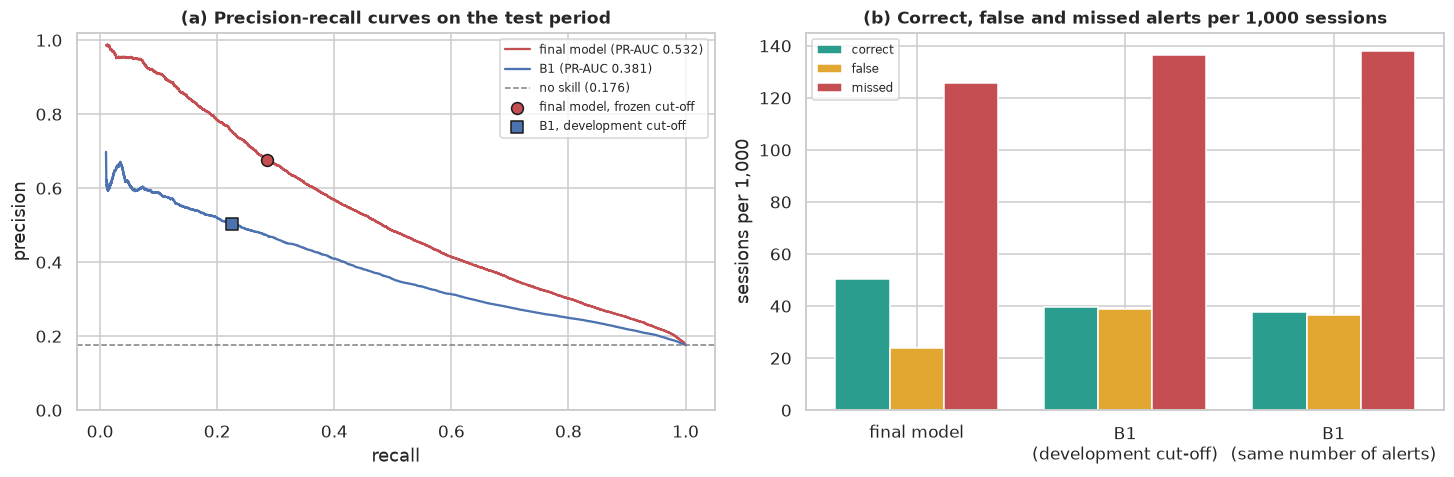

In [157]:
y_dev, s_dev, b_dev = OOF["y"].to_numpy(), OOF["score"].to_numpy(), OOF["b1"].to_numpy()
dev_rows = {
    "Final model, development (pooled)": (average_precision_score(y_dev, s_dev), s_dev >= CUT_OFF, y_dev),
    "Final model, test": (pr_final, flag_final, y_test),
    "B1, development (pooled)": (average_precision_score(y_dev, b_dev), b_dev >= B1_CUT, y_dev),
    "B1, test": (pr_b1, flag_b1, y_test),
}
dev_vs_test = pd.DataFrame([{"row": name, "abnormal share": y.mean(), "PR-AUC": pr, **confusion_metrics(y, flagged)} for name, (pr, flagged, y) in dev_rows.items()]).set_index("row")
display(dev_vs_test[["abnormal share"] + COLUMNS].style.format({**FMT, "abnormal share": "{:.1%}"}, na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
for name, score, color in [("final model", p_test, C_ABN), ("B1", b1_test, C_NORMAL)]:
    precision_c, recall_c, _ = precision_recall_curve(y_test, score)
    keep = recall_c > 0.01
    axes[0].plot(recall_c[keep], precision_c[keep], color=color, label=f"{name} (PR-AUC {average_precision_score(y_test, score):.3f})")
axes[0].axhline(y_test.mean(), color=C_GREY, ls="--", lw=1, label=f"no skill ({y_test.mean():.3f})")
for label, flagged, color, marker in [("final model, frozen cut-off", flag_final, C_ABN, "o"), ("B1, development cut-off", flag_b1, C_NORMAL, "s")]:
    m = confusion_metrics(y_test, flagged)
    axes[0].scatter(m["recall"], m["precision"], color=color, marker=marker, s=60, zorder=3, edgecolor="k", label=label)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_ylim(0, 1.02)
axes[0].set_title("(a) Precision-recall curves on the test period"); axes[0].legend(fontsize=8)
bar_rows = comparison.iloc[:3]
x = np.arange(3)
width = 0.26
for j, (col, color) in enumerate([("correct per 1,000", C_GREEN), ("false per 1,000", C_ORANGE), ("missed per 1,000", C_ABN)]):
    axes[1].bar(x + (j - 1) * width, bar_rows[col], width=width, color=color, label=col.replace(" per 1,000", ""))
axes[1].set_xticks(x); axes[1].set_xticklabels(["final model", "B1\n(development cut-off)", "B1\n(same number of alerts)"])
axes[1].set_ylabel("sessions per 1,000"); axes[1].set_title("(b) Correct, false and missed alerts per 1,000 sessions"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "05_1_final_vs_baseline")

Every measure of the final model is lower on the test than on the pooled development predictions: PR-AUC 0.635 against 0.532 (the mean of the folds is 0.626), precision 0.740 against 0.677, recall 0.403 against 0.286, F1 0.522 against 0.402, balanced accuracy 0.685 against 0.628 and MCC 0.479 against 0.373.
The alert rate falls from 10.0% to 7.4%. The number of false alerts per 1,000 sessions hardly changes (26.0 and 24.0), while the correct alerts fall from 74.0 to 50.3 and the missed sessions rise from 109.8 to 125.6. Fewer sessions reach the cut-off, and those that do are right slightly less often.

B1 falls too, and by more: its PR-AUC goes from 0.524 to 0.381 (−27%, against −16% for the final model) and its MCC from 0.378 to 0.251. The weakening is therefore not a defect of the fitted model alone. Section 6 asks how much of it is the abnormal share of the quarter (17.6% against 18.4%) and
how much is a change in the ranking. Figure (a) shows that the final model's precision-recall curve lies above that of B1 at every recall, and that both operating points sit on their curves.

In [158]:
final_row, b1_row = comparison.iloc[0], comparison.iloc[1]
log_decision("5", "Comparison with the baseline", "Reported as observed at the frozen operating points; no choice changes.",
             f"Test PR-AUC {pr_final:.4f} against {pr_b1:.4f} for B1 (gain {pr_final - pr_b1:+.4f}, 95% interval [{gain_ci[0]:+.4f}, {gain_ci[1]:+.4f}]); "
             f"at the frozen cut-off: precision {final_row['precision']:.3f}, recall {final_row['recall']:.3f}, F1 {final_row['F1']:.3f}, balanced accuracy "
             f"{final_row['balanced accuracy']:.3f}, MCC {final_row['MCC']:.3f}, alert rate {final_row['alert rate']:.2%}.")

---
## 6. Performance across time

The test result is one number for a whole quarter, and Section 5.3 showed that it is far from the development level. Here we ask when the change happened
and whether the model degrades inside the quarter. We use the same frozen cut-off everywhere and give, for each period, the abnormal share, the PR-AUC of the
final model and of B1, and the alert quality at the cut-off. A PR-AUC is shown only when a period has at least 30 abnormal sessions.

### 6.1 Development quarters and test months

In [159]:
test = test.assign(score=p_test, flag=flag_final, b1=b1_test, b1_flag=flag_b1)
MIN_POSITIVES = 30


def period_row(y, score, b1, flagged):
    y = np.asarray(y)
    ok = y.sum() >= MIN_POSITIVES and (1 - y).sum() > 0
    m = confusion_metrics(y, flagged)
    return {"sessions": len(y), "abnormal share": y.mean(), "PR-AUC final": average_precision_score(y, score) if ok else np.nan,
            "PR-AUC B1": average_precision_score(y, b1) if ok else np.nan, "ROC-AUC final": roc_auc_score(y, score) if ok else np.nan,
            "ROC-AUC B1": roc_auc_score(y, b1) if ok else np.nan, "alert rate": m["alert rate"], "precision": m["precision"],
            "recall": m["recall"], "F1": m["F1"], "false per 1,000": m["false per 1,000"], "missed per 1,000": m["missed per 1,000"]}


rows = {}
for f in FOLDS:
    g = OOF[OOF["fold"] == f["fold"]]
    rows[f"fold {f['fold']}: {f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()} (development)"] = period_row(g["y"], g["score"], g["b1"], g["score"] >= CUT_OFF)
test_months = test["start_time"].dt.to_period("M")
for month, g in test.groupby(test_months):
    rows[f"test {month}"] = period_row(g[TARGET], g["score"], g["b1"], g["flag"])
rows["test, whole period"] = period_row(test[TARGET], test["score"], test["b1"], test["flag"])
time_table = pd.DataFrame(rows).T
TIME_FMT = {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "PR-AUC final": "{:.4f}", "PR-AUC B1": "{:.4f}", "ROC-AUC final": "{:.3f}", "ROC-AUC B1": "{:.3f}",
            "alert rate": "{:.1%}", "precision": "{:.3f}",
            "recall": "{:.3f}", "F1": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
time_table["lift final"] = time_table["PR-AUC final"] / time_table["abnormal share"]
time_table["lift B1"] = time_table["PR-AUC B1"] / time_table["abnormal share"]
display(time_table.style.format({**TIME_FMT, "lift final": "{:.2f}", "lift B1": "{:.2f}"}, na_rep="—"))

# How much of the fall from fold 4 to the test is the lower abnormal share? PR-AUC moves with the abnormal share, so we keep the lift of fold 4 and apply it to the test share.
f4, tst = time_table.iloc[3], time_table.loc["test, whole period"]
expected = f4["lift final"] * tst["abnormal share"]
total_fall = f4["PR-AUC final"] - tst["PR-AUC final"]
print(f"PR-AUC fell by {total_fall:.4f} from fold 4 ({f4['PR-AUC final']:.4f}) to the test ({tst['PR-AUC final']:.4f}). With the lift of fold 4 ({f4['lift final']:.2f}) and the test share "
      f"({tst['abnormal share']:.1%}) the expected PR-AUC is {expected:.4f}: {f4['PR-AUC final'] - expected:.4f} of the fall ({(f4['PR-AUC final'] - expected) / total_fall:.0%}) comes from the lower abnormal share "
      f"and {expected - tst['PR-AUC final']:.4f} ({(expected - tst['PR-AUC final']) / total_fall:.0%}) from the lower lift. ROC-AUC, which does not depend on the share: fold 4 {f4['ROC-AUC final']:.3f}, test {tst['ROC-AUC final']:.3f}.")
FALL_SPLIT = {"total fall": float(total_fall), "from the abnormal share": float(f4["PR-AUC final"] - expected), "from the lift": float(expected - tst["PR-AUC final"])}

,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",lift final,lift B1
fold 1: 2020-10-01 to 2020-12-31 (development),"60,364",16.8%,0.6176,0.4991,0.835,0.764,8.4%,0.751,0.375,0.500,21.0,105.2,3.67,2.96
fold 2: 2021-01-01 to 2021-03-31 (development),"41,797",15.8%,0.5755,0.4562,0.825,0.749,7.7%,0.713,0.347,0.467,22.1,103.3,3.64,2.88
fold 3: 2021-04-01 to 2021-06-30 (development),"57,542",18.2%,0.6497,0.5466,0.844,0.789,10.4%,0.739,0.423,0.538,27.2,105.1,3.56,3.00
fold 4: 2021-07-01 to 2021-09-30 (development),"75,769",21.1%,0.6604,0.5403,0.838,0.788,12.2%,0.745,0.430,0.545,31.1,120.6,3.12,2.56
test 2021-10,"27,794",18.6%,0.5534,0.4020,0.792,0.723,8.5%,0.694,0.315,0.434,25.8,127.3,2.98,2.16
test 2021-11,"25,669",16.5%,0.4832,0.3322,0.784,0.711,6.0%,0.637,0.232,0.340,21.8,126.7,2.93,2.01
test 2021-12,"26,618",17.6%,0.5511,0.3961,0.803,0.733,7.7%,0.687,0.301,0.419,24.2,122.9,3.13,2.25
"test, whole period","80,081",17.6%,0.5324,0.3809,0.794,0.723,7.4%,0.677,0.286,0.402,24.0,125.6,3.03,2.17


PR-AUC fell by 0.1280 from fold 4 (0.6604) to the test (0.5324). With the lift of fold 4 (3.12) and the test share (17.6%) the expected PR-AUC is 0.5496: 0.1108 of the fall (87%) comes from the lower abnormal share and 0.0172 (13%) from the lower lift. ROC-AUC, which does not depend on the share: fold 4 0.838, test 0.794.


Read on its own, PR-AUC makes the test look much worse than any development quarter: the final model scores 0.553, 0.483 and 0.551 in the three test months, and 0.5755 in its worst development fold. But PR-AUC rises with the abnormal share, which was 21.1% in fold 4 and is 17.6% in the test. With the lift of fold 4
(3.12) applied to the test share, the expected PR-AUC would be 0.5496, so 0.1108 of the 0.1280 fall from fold 4 (87%) is the lower abnormal share and only 0.0172 (13%) comes from the lower lift. Part of the drop that Task 4 reported is therefore arithmetic, which is why Task 2 asks for the lift and the share to be read with
the score.

The ranking did weaken, though. The ROC-AUC, which does not depend on the abnormal share, is 0.794 on the test (0.792, 0.784 and 0.803 by month), below the four development folds (0.825 to 0.844), and the lift of the whole test (3.03) is below every development fold (3.12 to 3.67). The lift had already been falling in development (3.67, 3.64, 3.56, 3.12), so the test continues a gradual decline rather
than a sudden break. B1 loses more: its lift goes from 2.56 in fold 4 to 2.17 and its ROC-AUC from 0.788 to 0.723, against a fall of 0.09 in lift and 0.044 in ROC-AUC for the final model. At the frozen cut-off the alert rate follows the abnormal share and the scores (6.0% in November, 8.5% in October), the precision stays between 0.637 and 0.694 (0.713 to 0.751 in development) and the recall between 0.232 and 0.315 (0.347 to 0.430).
November is the weakest month on every measure: the lowest abnormal share of the three (16.5%), PR-AUC 0.483 and recall 0.232.

### 6.2 Week by week inside the test period

Months hide a change that happens within a month, so the next table and figure follow the 13 weeks of the test period (weeks start on Monday, so the first and the
last are partial). We want to see whether the weakening is gradual or sudden, and whether the number of alerts follows the number of failures.

,sessions,abnormal share,PR-AUC final,PR-AUC B1,alert rate,precision,recall
2021-09-27,"3,209",23.7%,0.6421,0.5515,14.8%,0.687,0.429
2021-10-04,"6,083",20.0%,0.6005,0.4334,10.0%,0.730,0.365
2021-10-11,"6,318",17.2%,0.4933,0.3070,7.0%,0.649,0.265
2021-10-18,"6,268",17.6%,0.5436,0.4206,7.1%,0.718,0.288
2021-10-25,"5,916",16.8%,0.4832,0.3186,6.4%,0.671,0.254
2021-11-01,"5,435",15.4%,0.4129,0.2779,5.3%,0.566,0.194
2021-11-08,"6,212",16.4%,0.4869,0.3285,5.6%,0.653,0.224
2021-11-15,"6,043",16.0%,0.4683,0.3300,5.4%,0.609,0.206
2021-11-22,"6,309",18.1%,0.5404,0.3884,7.6%,0.695,0.291
2021-11-29,"6,359",17.3%,0.5453,0.3976,7.2%,0.692,0.288


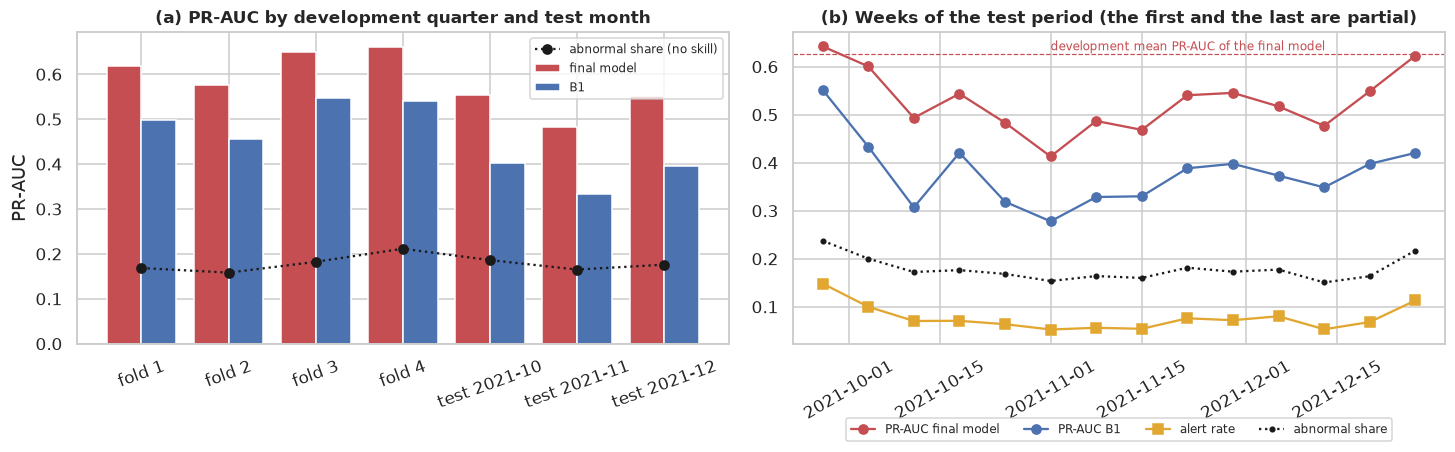

In [160]:
week = test["start_time"].dt.to_period("W-SUN").dt.start_time
weekly = pd.DataFrame({w: period_row(g[TARGET], g["score"], g["b1"], g["flag"]) for w, g in test.groupby(week)}).T
weekly.index = [d.date() for d in weekly.index]
display(weekly[["sessions", "abnormal share", "PR-AUC final", "PR-AUC B1", "alert rate", "precision", "recall"]].style.format(TIME_FMT, na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
labels = [f"fold {f['fold']}" for f in FOLDS] + [str(m) for m in time_table.index[4:7]]
vals = time_table.iloc[:7]
x = np.arange(len(vals))
axes[0].bar(x - 0.2, vals["PR-AUC final"], width=0.4, color=C_ABN, label="final model")
axes[0].bar(x + 0.2, vals["PR-AUC B1"], width=0.4, color=C_NORMAL, label="B1")
axes[0].plot(x, vals["abnormal share"], color="k", marker="o", ls=":", label="abnormal share (no skill)")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=20); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) PR-AUC by development quarter and test month"); axes[0].legend(fontsize=8)
wk = weekly.index
axes[1].plot(wk, weekly["PR-AUC final"], color=C_ABN, marker="o", label="PR-AUC final model")
axes[1].plot(wk, weekly["PR-AUC B1"], color=C_NORMAL, marker="o", label="PR-AUC B1")
axes[1].plot(wk, weekly["alert rate"], color=C_ORANGE, marker="s", label="alert rate")
axes[1].plot(wk, weekly["abnormal share"], color="k", ls=":", marker=".", label="abnormal share")
axes[1].axhline(FROZEN["development_estimates"]["PR-AUC mean"], color=C_ABN, ls="--", lw=0.8)
axes[1].text(wk[5], FROZEN["development_estimates"]["PR-AUC mean"] + 0.008, "development mean PR-AUC of the final model", fontsize=8, color=C_ABN)
axes[1].set_title("(b) Weeks of the test period (the first and the last are partial)"); axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
fig.tight_layout()
savefig(fig, "06_1_performance_over_time")

The weekly PR-AUC of the final model runs from 0.413 (week of 1 November) to 0.642 in the first, partial week (1 to 3 October), and 0.623 in the last partial week. The two partial weeks have the highest abnormal shares (23.7% and 21.7%) and the highest alert rates (14.8% and 11.3%), and the weeks with a share
below 17% have a PR-AUC between 0.41 and 0.55. The weekly curves of the model and of B1 move together, and they follow the abnormal share, which is the reading of Section 6.1. We see no downward drift inside the quarter: the lowest weeks are at the end of October and the beginning of November, and the model recovers in the second half of November (0.540 and 0.545), before falling again in mid-December (0.477). The alert rate goes from 5.3% to 14.8% by week (Section 10.1 gives the daily range), so the workload of an operator will change from week to week with the failures. Each weekly point rests on about 1,000 abnormal sessions, so differences of a few hundredths between weeks are within noise.

---
## 7. Performance across operational groups

The operator acts on districts, stations and charging posts, so a model that works on average could still fail for some of them. For each group we report the
same measures as above at the frozen cut-off, the PR-AUC of the final model and of B1, and the alert rate. A group is shown with a PR-AUC only when it has
at least 30 abnormal sessions.

### 7.1 Districts and stations

In [161]:
def group_table(frame, key):
    rows = {name: period_row(g[TARGET], g["score"], g["b1"], g["flag"]) for name, g in frame.groupby(key)}
    t = pd.DataFrame(rows).T
    t["gain over B1"] = t["PR-AUC final"] - t["PR-AUC B1"]
    return t


GROUP_FMT = {**TIME_FMT, "gain over B1": "{:+.4f}"}
district_table = group_table(test, "district")
station_table = group_table(test, "location").sort_values("PR-AUC final", ascending=False)
print("Districts")
display(district_table.style.format(GROUP_FMT, na_rep="—"))
print("Stations (sorted by PR-AUC of the final model)")
display(station_table.style.format(GROUP_FMT, na_rep="—"))
print(f"Stations: {len(station_table)} | abnormal share from {station_table['abnormal share'].min():.1%} to {station_table['abnormal share'].max():.1%} | "
      f"PR-AUC of the final model from {station_table['PR-AUC final'].min():.3f} to {station_table['PR-AUC final'].max():.3f} | "
      f"final model above B1 in {(station_table['gain over B1'] > 0).sum()} of {station_table['gain over B1'].notna().sum()} stations")

Districts


,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
Nanhu,"10,891",23.9%,0.5767,0.3879,0.770,0.665,11.0%,0.693,0.320,0.438,33.9,162.2,+0.1887
Tongxiang,"38,337",12.0%,0.4743,0.3300,0.803,0.722,3.8%,0.706,0.224,0.341,11.3,93.3,+0.1443
Xiuzhou,"30,853",22.3%,0.5524,0.3999,0.759,0.683,10.6%,0.658,0.314,0.425,36.3,153.0,+0.1525


Stations (sorted by PR-AUC of the final model)


,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
Expressway Service District B,"3,295",22.9%,0.6299,0.3691,0.780,0.652,14.5%,0.705,0.446,0.546,42.8,127.2,+0.2608
Tourist Attraction,"7,313",27.1%,0.6143,0.4111,0.772,0.650,13.3%,0.710,0.349,0.468,38.7,176.4,+0.2032
Expressway Service District C,"10,908",27.3%,0.5954,0.4642,0.743,0.682,15.5%,0.655,0.372,0.475,53.6,171.4,+0.1312
Shopping Mall,"9,529",19.5%,0.5763,0.4184,0.774,0.693,8.8%,0.749,0.337,0.465,21.9,129.1,+0.1579
Expressway Service District A,"3,654",18.6%,0.5644,0.2956,0.751,0.624,9.6%,0.728,0.374,0.494,26.0,116.3,+0.2688
Park A,"4,322",23.0%,0.5034,0.4207,0.737,0.688,8.8%,0.624,0.238,0.345,33.1,175.2,+0.0826
Wholesale Market,"6,763",24.7%,0.4670,0.3773,0.695,0.642,8.0%,0.587,0.190,0.287,33.1,200.2,+0.0897
Financial Industrial Park,"3,578",17.2%,0.4343,0.2881,0.734,0.639,6.3%,0.618,0.226,0.331,24.0,133.0,+0.1462
Government Agency,"6,233",12.7%,0.4126,0.2592,0.780,0.678,3.4%,0.651,0.177,0.278,12.0,104.6,+0.1534
Industrial Park,"3,819",6.8%,0.3728,0.1175,0.796,0.628,1.2%,0.787,0.143,0.243,2.6,57.9,+0.2553


Stations: 12 | abnormal share from 6.8% to 27.3% | PR-AUC of the final model from 0.251 to 0.630 | final model above B1 in 12 of 12 stations


The model is above B1 in all three districts (gains of +0.144 to +0.189) and in all 12 stations that appear in the test (+0.083 to +0.269), so it improves on the baseline everywhere. Its quality still varies a lot. Tongxiang holds 47.9% of the sessions but has a low abnormal share (12.0%), and there the model
flags 3.8% of the sessions and catches 22.4% of the failures (PR-AUC 0.474), while Nanhu and Xiuzhou (23.9% and 22.3% abnormal) have PR-AUC of 0.577 and 0.552, alert rates of about 11% and recalls of 0.32 and 0.31. The precision of the alerts is similar in the three districts (0.658 to 0.706), but the false alerts per 1,000 sessions are
three times higher in Nanhu and Xiuzhou (33.9 and 36.3) than in Tongxiang (11.3), because that is where the alerts are.

Among stations, the PR-AUC runs from 0.251 (Park B) to 0.630 (Expressway Service District B). The three stations with the lowest abnormal share (Industrial Park 6.8%, Park B 7.1% and Bus Station 7.4%) are the three with the lowest PR-AUC, and there the model is almost silent: alert rates of 0.6% to 1.3% and recalls of 0.04 to 0.14.
Their lift is high (about 3.5 to 5.5), so the alerts that it raises there are well placed, but it finds very few of the failures. The raw PR-AUC of a station should be read with its abnormal share, as in Section 6.

### 7.2 Charging posts

There are 92 posts, so a table of all of them would be long. We summarise them in three ways: how the alerts and the abnormal sessions are spread over the posts, the ten
posts that receive the most alerts, and how precision and recall vary between posts with enough sessions (at least 200 test sessions, and at least 20 alerts for the
precision or 30 abnormal sessions for the recall). The post identifier is used only to group results, never as a predictor.

,sessions,abnormal,alerts,TP,abnormal share,alert rate,precision,recall
post_id,,,,,,,,
27,"1,338",618,506,417,46.2%,37.8%,0.824,0.675
83,"1,816",718,428,229,39.5%,23.6%,0.535,0.319
81,"1,450",507,372,288,35.0%,25.7%,0.774,0.568
32,731,389,311,203,53.2%,42.5%,0.653,0.522
78,"1,278",432,269,212,33.8%,21.0%,0.788,0.491
89,802,382,256,164,47.6%,31.9%,0.641,0.429
77,"1,731",378,236,159,21.8%,13.6%,0.674,0.421
4,668,294,197,148,44.0%,29.5%,0.751,0.503
5,973,269,186,165,27.6%,19.1%,0.887,0.613


,value
posts,88.000
posts with at least one alert,88.000
top 10% of posts by alerts,9.000
their share of all alerts,0.464
their share of all abnormal sessions,0.283
their share of all sessions,0.135
"Spearman, post abnormal share vs alert rate",0.909


Precision at the frozen cut-off across 44 posts: min 0.312, median 0.654, max 0.887
Recall across 80 posts: min 0.000, median 0.142, max 0.675


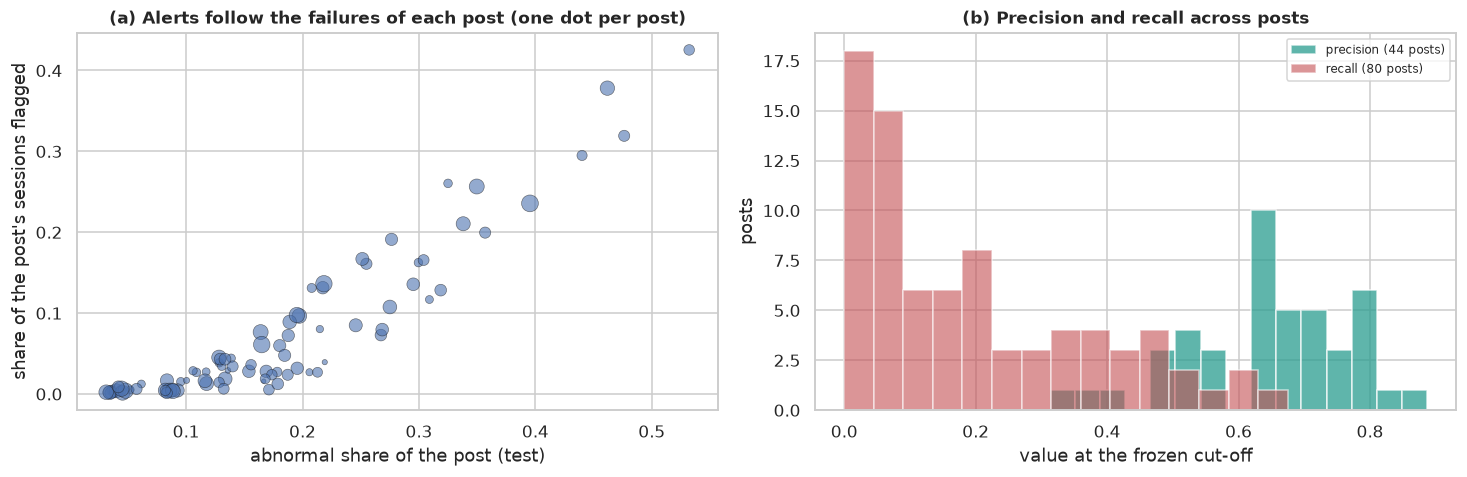

In [162]:
test["post_id"] = test["post_id"].astype(str)
by_post = test.groupby("post_id").apply(
    lambda g: pd.Series({"sessions": len(g), "abnormal": int(g[TARGET].sum()), "alerts": int(g["flag"].sum()), "TP": int((g["flag"] & (g[TARGET] == 1)).sum())}),
    include_groups=False)
by_post["abnormal share"] = by_post["abnormal"] / by_post["sessions"]
by_post["alert rate"] = by_post["alerts"] / by_post["sessions"]
by_post["precision"] = by_post["TP"] / by_post["alerts"].where(by_post["alerts"] > 0)
by_post["recall"] = by_post["TP"] / by_post["abnormal"].where(by_post["abnormal"] > 0)
top_posts = by_post.sort_values("alerts", ascending=False).head(10)
display(top_posts.style.format({"sessions": "{:,.0f}", "abnormal": "{:,.0f}", "alerts": "{:,.0f}", "TP": "{:,.0f}", "abnormal share": "{:.1%}", "alert rate": "{:.1%}",
                                "precision": "{:.3f}", "recall": "{:.3f}"}, na_rep="—"))

sorted_alerts = by_post["alerts"].sort_values(ascending=False)
n_top = max(1, int(round(0.1 * len(by_post))))
top10 = by_post.loc[sorted_alerts.index[:n_top]]
concentration = {"posts": len(by_post), "posts with at least one alert": int((by_post["alerts"] > 0).sum()), "top 10% of posts by alerts": n_top,
                 "their share of all alerts": float(top10["alerts"].sum() / by_post["alerts"].sum()),
                 "their share of all abnormal sessions": float(top10["abnormal"].sum() / by_post["abnormal"].sum()),
                 "their share of all sessions": float(top10["sessions"].sum() / by_post["sessions"].sum())}
rho = spearmanr(by_post["abnormal share"], by_post["alert rate"])
concentration["Spearman, post abnormal share vs alert rate"] = float(rho.statistic)
display(pd.Series(concentration, name="value").to_frame().style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else f"{v}"))

big = by_post[by_post["sessions"] >= 200]
prec_posts, rec_posts = big[big["alerts"] >= 20]["precision"].dropna(), big[big["abnormal"] >= 30]["recall"].dropna()
print(f"Precision at the frozen cut-off across {len(prec_posts)} posts: min {prec_posts.min():.3f}, median {prec_posts.median():.3f}, max {prec_posts.max():.3f}")
print(f"Recall across {len(rec_posts)} posts: min {rec_posts.min():.3f}, median {rec_posts.median():.3f}, max {rec_posts.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
axes[0].scatter(by_post["abnormal share"], by_post["alert rate"], s=by_post["sessions"] / 15, color=C_NORMAL, alpha=0.6, edgecolor="k", lw=0.4)
axes[0].set_xlabel("abnormal share of the post (test)"); axes[0].set_ylabel("share of the post's sessions flagged")
axes[0].set_title("(a) Alerts follow the failures of each post (one dot per post)")
axes[1].hist(prec_posts, bins=15, color=C_GREEN, alpha=0.75, label=f"precision ({len(prec_posts)} posts)")
axes[1].hist(rec_posts, bins=15, color=C_ABN, alpha=0.6, label=f"recall ({len(rec_posts)} posts)")
axes[1].set_xlabel("value at the frozen cut-off"); axes[1].set_ylabel("posts"); axes[1].set_title("(b) Precision and recall across posts"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "07_1_posts")

The 88 posts that appear in the test period all receive at least one alert. The alerts are concentrated: the nine posts with the most alerts (10% of the posts) receive 46.4% of them, hold 28.3% of the abnormal sessions and 13.5% of all sessions, and the Spearman correlation between the abnormal share of a post and its alert rate is 0.909 (figure a).
The model sends its alerts to the posts that are failing most, which agrees with the dominance of the post history in Section 9. At the busiest posts the alerts work well, for instance post 27 (506 alerts, precision 0.824, recall 0.675), but not everywhere: post 83 has 428 alerts with a precision of 0.535 and a recall of 0.319.

Across the 44 posts with at least 20 alerts the precision at the frozen cut-off goes from 0.312 to 0.887 (median 0.654). The recall is the weak point: across the 80 posts with at least 30 abnormal sessions the median is 0.142, the maximum 0.675, and figure (b) shows a large group of posts with a recall close to zero. The model identifies which posts are failing at the moment, but
it finds few of the failures at the other posts.

### 7.3 New and returning users

Task 2 flagged the cold start as an assumption: the user-history group needs an identified account, and new accounts have no history. The next table checks the
final model on the two kinds of session.

In [163]:
test["user type"] = np.where(test["is_new_user"] == 1, "new user", "returning user")
user_table = group_table(test, "user type")
display(user_table.style.format(GROUP_FMT, na_rep="—"))

,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
new user,"10,353",17.6%,0.3939,0.3209,0.692,0.676,4.0%,0.639,0.146,0.237,14.5,150.3,+0.0730
returning user,"69,728",17.6%,0.5513,0.3922,0.806,0.730,7.9%,0.680,0.307,0.423,25.4,122.0,+0.1591


New users are 12.9% of the test sessions and the model works clearly worse for them: PR-AUC of 0.394 against 0.551 for returning users, recall of 0.146 against 0.307 and alert rate of 4.0% against 7.9%. The precision of the alerts is similar (0.639 and 0.680), so the model is not wrong more often for new users, it simply
raises fewer alerts because it has no user history to rely on (Section 9 shows how much it uses that group). It still beats B1 for new users, by +0.073 against +0.159 for returning users. This is the cold-start limit that Task 2 anticipated, and a possible reason to give these sessions a different treatment.

In [164]:
log_decision("6-7", "Time and group analysis", "Descriptive only: the frozen cut-off is applied everywhere and no group-specific threshold is introduced.",
             f"Test months PR-AUC {time_table.loc['test 2021-10', 'PR-AUC final']:.3f}, {time_table.loc['test 2021-11', 'PR-AUC final']:.3f}, {time_table.loc['test 2021-12', 'PR-AUC final']:.3f}; "
             f"districts {len(district_table)}, stations {len(station_table)}, posts {len(by_post)}.")

---
## 8. Error analysis

At the frozen cut-off every test session falls in one of four classes: a *true positive* (an alert on an abnormal session), a *false positive* (an alert on a normal
session), a *false negative* (an abnormal session without an alert) and a *true negative*. We look for patterns in the two kinds of error. The end cause of a session
is used here only to describe which failures are missed; it is a post-session variable and was never a predictor. As in Sections 6 and 7, the analysis is descriptive
and cannot change a frozen choice.

### 8.1 The four classes and the failures that are missed

In [165]:
err = test.copy()
y_bool = err[TARGET].to_numpy().astype(bool)
err["outcome"] = np.select([err["flag"] & y_bool, err["flag"] & ~y_bool, ~err["flag"] & y_bool], ["TP", "FP", "FN"], "TN")
outcome_counts = err["outcome"].value_counts().reindex(["TP", "FP", "FN", "TN"])
display(pd.DataFrame({"sessions": outcome_counts, "per 1,000 sessions": 1000 * outcome_counts / len(err), "share of the abnormal sessions": outcome_counts / y_bool.sum() * [1, np.nan, 1, np.nan],
                      "share of the alerts": outcome_counts / err["flag"].sum() * [1, 1, np.nan, np.nan]}).style.format(
    {"sessions": "{:,.0f}", "per 1,000 sessions": "{:.1f}", "share of the abnormal sessions": "{:.1%}", "share of the alerts": "{:.1%}"}, na_rep="—"))

abnormal = err[err[TARGET] == 1]
cause_table = abnormal.groupby("end_cause").agg(sessions=("flag", "size"), detected=("flag", "sum"), mean_score=("score", "mean"))
cause_table["recall"] = cause_table["detected"] / cause_table["sessions"]
cause_table["share of all abnormal"] = cause_table["sessions"] / cause_table["sessions"].sum()
cause_table["share of all missed"] = (cause_table["sessions"] - cause_table["detected"]) / (cause_table["sessions"] - cause_table["detected"]).sum()
cause_table = cause_table.sort_values("sessions", ascending=False).rename(columns={"mean_score": "mean score"})
display(cause_table.style.format({"sessions": "{:,.0f}", "detected": "{:,.0f}", "mean score": "{:.3f}", "recall": "{:.3f}", "share of all abnormal": "{:.1%}", "share of all missed": "{:.1%}"}))
print(f"End causes among the abnormal test sessions: {len(cause_table)} | overall recall {cause_table['detected'].sum() / cause_table['sessions'].sum():.3f}")

,sessions,"per 1,000 sessions",share of the abnormal sessions,share of the alerts
outcome,,,,
TP,"4,026",50.3,28.6%,67.7%
FP,"1,921",24.0,—,32.3%
FN,"10,062",125.6,71.4%,—
TN,"64,072",800.1,—,—


,sessions,detected,mean score,recall,share of all abnormal,share of all missed
end_cause,,,,,,
Other faults of the charging pile,"3,197","1,083",0.395,0.339,22.7%,21.0%
Vehicle communications failure,"2,316",745,0.381,0.322,16.4%,15.6%
DC Output Fault,"2,226",444,0.304,0.199,15.8%,17.7%
Vehicle charging faults,"1,661",620,0.425,0.373,11.8%,10.3%
BMS failure,"1,586",313,0.282,0.197,11.3%,12.7%
Faulty charging connection,"1,525",335,0.316,0.220,10.8%,11.8%
Failure of non-system control loop components and assemblies,818,157,0.268,0.192,5.8%,6.6%
DC switching device failure,467,235,0.475,0.503,3.3%,2.3%
Power conversion unit failure,259,80,0.375,0.309,1.8%,1.8%


End causes among the abnormal test sessions: 12 | overall recall 0.286


At the frozen cut-off the test has 4,026 true positives, 1,921 false positives, 10,062 false negatives and 64,072 true negatives. A third of the alerts (32.3%) are false, and 71.4% of the abnormal sessions go without an alert. By end cause (12 of the 13 causes appear in the test), the recall goes from 0.192 to 0.503. The causes
best detected are the DC switching device failure (recall 0.503, 467 sessions), the vehicle charging faults (0.373, 1,661) and the other faults of the charging pile (0.339, 3,197). The least detected are the failure of non-system control loop components (0.192, 818), the BMS failure (0.197, 1,586), the DC output fault (0.199, 2,226) and the faulty charging
connection (0.220, 1,525): four causes that make up 43.7% of the abnormal sessions but 48.8% of the missed ones. The three causes with fewer than 20 sessions give recalls that mean nothing. We do not read causal meaning into the differences, because the model never sees the cause. A likely reading is that some faults tend to come in bursts at a post that has just failed, which the model sees, and others
tend to appear alone.

### 8.2 Who is flagged and who is missed

The next table gives the typical value of the main variables in each of the four classes (median for numeric variables, share for the two indicators). It shows what
separates the false positives from the true positives, and the missed failures from the failures that the model finds.

In [166]:
profile_vars = ["score", "post_previous_abnormal_rate_1D", "post_previous_abnormal_rate_7D", "post_previous_abnormal_rate_30D", "post_previous_sessions_7D",
                "post_hours_since_previous_completed_abnormal", "user_previous_abnormal_rate_180D", "user_previous_sessions_180D", "user_active_sessions_at_start",
                "temperature", "hour"]
profile = pd.DataFrame({cls: err[err["outcome"] == cls][profile_vars].median() for cls in ["TP", "FP", "FN", "TN"]})
for col in ["is_new_user", "rain_flag"]:
    profile.loc[f"share with {col}"] = [err[err["outcome"] == cls][col].mean() for cls in ["TP", "FP", "FN", "TN"]]
profile.loc["share without a previous abnormal session at the post"] = [err[err["outcome"] == cls]["post_hours_since_previous_completed_abnormal"].isna().mean() for cls in ["TP", "FP", "FN", "TN"]]
profile.loc["sessions"] = [int((err["outcome"] == cls).sum()) for cls in ["TP", "FP", "FN", "TN"]]
display(profile.style.format("{:.3f}", na_rep="—"))

,TP,FP,FN,TN
score,0.701,0.574,0.188,0.094
post_previous_abnormal_rate_1D,0.487,0.364,0.182,0.125
post_previous_abnormal_rate_7D,0.404,0.333,0.184,0.125
post_previous_abnormal_rate_30D,0.331,0.325,0.189,0.132
post_previous_sessions_7D,101.000,91.000,85.000,88.000
post_hours_since_previous_completed_abnormal,0.024,0.025,6.929,14.814
user_previous_abnormal_rate_180D,0.333,0.333,0.200,0.167
user_previous_sessions_180D,7.000,6.000,12.000,17.000
user_active_sessions_at_start,0.000,0.000,0.000,0.000
temperature,12.900,13.700,13.200,13.100


The false positives look like the true positives, and the false negatives look like the true negatives. The median score is 0.701 for the true positives and 0.574 for the false positives, against 0.188 for the false negatives and 0.094 for the true negatives. The reason is the post history: the median time since the last abnormal session of the post is
0.024 and 0.025 hours (about a minute and a half) for the true positives and the false positives, 6.9 hours for the false negatives and 14.8 hours for the true negatives, and the abnormal rate of the post in the last day is 0.487 and 0.364 for the two kinds of alert but only 0.182 for the missed failures. A session that starts moments after a failure at its post is flagged, and
whether it fails too decides if the alert is true or false, which the model cannot tell. The failures that the model misses are the ones that begin at posts that have been quiet for hours. The user also matters: the missed failures have more experienced users (median 12 sessions in the last 180 days against 7 and 6 for the two kinds of alert), a lower abnormal rate of the user (0.200 against 0.333) and more new users (15.5% against 6.6% for the true positives).
Hour, temperature and rain do not separate the classes (median hour 14 in all four, temperature 12.9 to 13.7 °C, share with rain 24% to 28%).

### 8.3 Where the errors concentrate

For each band of a variable the table gives the abnormal share, the alert rate, the precision and recall at the frozen cut-off, the false alerts and missed abnormal
sessions per 1,000 sessions of the band, and the share of all false alerts and of all missed failures that the band holds. A band that holds a larger share of the
errors than of the sessions is a pattern to explain.

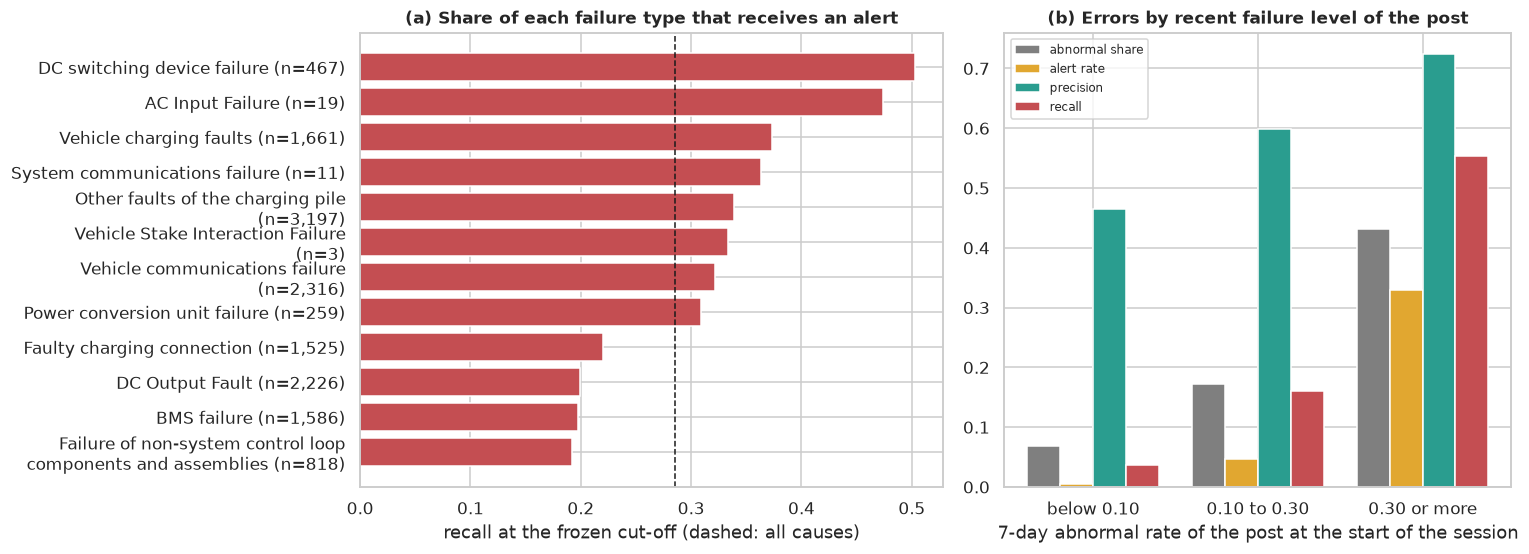

In [167]:
hours_since = err["post_hours_since_previous_completed_abnormal"]
BANDS = {
    "post failure rate, last 7 days": pd.cut(err["post_previous_abnormal_rate_7D"], [-np.inf, 0.10, 0.30, np.inf], right=False, labels=["below 0.10", "0.10 to 0.30", "0.30 or more"]),
    "post failure rate, last day": pd.cut(err["post_previous_abnormal_rate_1D"], [-np.inf, 0.10, 0.30, np.inf], right=False, labels=["below 0.10", "0.10 to 0.30", "0.30 or more"]),
    "time since the post's last abnormal session": pd.cut(hours_since, [-np.inf, 6, 24, 168, np.inf], right=False,
                                                         labels=["under 6 h", "6 to 24 h", "1 to 7 days", "over 7 days"]).cat.add_categories("none recorded").fillna("none recorded"),
    "user": pd.Series(np.where(err["is_new_user"] == 1, "new user", "returning user"), index=err.index),
    "hour of the day": pd.cut(err["hour"], [-1, 5, 11, 17, 23], labels=["00 to 05", "06 to 11", "12 to 17", "18 to 23"]),
    "day type": pd.Series(np.where(err["dow"] >= 5, "weekend", "weekday"), index=err.index),
    "weather": pd.Series(np.where(err["rain_flag"] == 1, "rain", "dry"), index=err.index),
    "district": err["district"],
}
total_fp, total_fn = int((err["outcome"] == "FP").sum()), int((err["outcome"] == "FN").sum())
rows = []
for variable, band_series in BANDS.items():
    for band, g in err.groupby(band_series, observed=True):
        m = confusion_metrics(g[TARGET], g["flag"])
        rows.append({"variable": variable, "band": band, "sessions": len(g), "share of sessions": len(g) / len(err), "abnormal share": g[TARGET].mean(),
                     "alert rate": m["alert rate"], "precision": m["precision"], "recall": m["recall"], "false per 1,000": m["false per 1,000"],
                     "missed per 1,000": m["missed per 1,000"], "share of all false alerts": m["FP"] / total_fp, "share of all missed": m["FN"] / total_fn})
band_table = pd.DataFrame(rows).set_index(["variable", "band"])
display(band_table.style.format({"sessions": "{:,.0f}", "share of sessions": "{:.1%}", "abnormal share": "{:.1%}", "alert rate": "{:.1%}", "precision": "{:.3f}",
                                 "recall": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}", "share of all false alerts": "{:.1%}", "share of all missed": "{:.1%}"}, na_rep="—"))

import textwrap
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
c = cause_table.sort_values("recall")
axes[0].barh(["\n".join(textwrap.wrap(f"{i} (n={int(n):,})", 38)) for i, n in zip(c.index, c["sessions"])], c["recall"], color=C_ABN)
axes[0].axvline(cause_table["detected"].sum() / cause_table["sessions"].sum(), color="k", ls="--", lw=1)
axes[0].set_xlabel("recall at the frozen cut-off (dashed: all causes)"); axes[0].set_title("(a) Share of each failure type that receives an alert")
bt = band_table.loc["post failure rate, last 7 days"]
x = np.arange(len(bt))
for j, (col, color) in enumerate([("abnormal share", C_GREY), ("alert rate", C_ORANGE), ("precision", C_GREEN), ("recall", C_ABN)]):
    axes[1].bar(x + (j - 1.5) * 0.2, bt[col], width=0.2, color=color, label=col)
axes[1].set_xticks(x); axes[1].set_xticklabels(bt.index); axes[1].set_xlabel("7-day abnormal rate of the post at the start of the session")
axes[1].set_title("(b) Errors by recent failure level of the post"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "08_1_error_analysis")

The errors follow how recently the post has failed. When the 7-day abnormal rate of the post is 0.30 or more (14.7% of the sessions, 43.2% abnormal), the model flags 33.0% of them with a precision of 0.723 and a recall of 0.553. Below 0.10 (33.3% of the sessions) it flags 0.5% and the recall is 0.037. The large middle band (0.10 to 0.30, 52.0% of the sessions, 17.2% abnormal) flags 4.6% and has a recall of 0.161, and it
holds 60.0% of the missed failures and 40.2% of the false alerts. The time since the last abnormal session of the post shows it more sharply. Sessions that start under 6 hours after a failure at their post (38.3% of the sessions, 27.8% abnormal) have an alert rate of 18.1%, a precision of 0.684 and a recall of 0.445, and hold 91.7% of all false alerts. Beyond 6 hours the alert rate is between 0.3% and 1.2% and
the recall between 0.023 and 0.050, yet these bands hold 52.9% of all missed failures (33.2% from 6 to 24 hours, 18.8% from 1 to 7 days, 0.9% beyond 7 days). The model is therefore close to a sharp version of "the post has just failed", and it has almost no way to flag a failure after a quiet period.

The other variables show no pattern. By time of day the recall is between 0.254 and 0.305 and the false alerts between 20.9 and 28.0 per 1,000 sessions; weekdays and weekends (0.283 and 0.294) and dry and rainy sessions (0.293 and 0.264) are close. Districts and new users repeat what Section 7 showed.

### 8.4 Charging posts with the most false alerts and the most missed failures

In [168]:
fp_posts = err[err["outcome"] == "FP"].groupby("post_id").size().rename("false alerts")
fn_posts = err[err["outcome"] == "FN"].groupby("post_id").size().rename("missed")
post_errors = by_post[["sessions", "abnormal share", "alerts"]].join(fp_posts).join(fn_posts).fillna({"false alerts": 0, "missed": 0})
post_errors["false alerts per 1,000 sessions"] = 1000 * post_errors["false alerts"] / post_errors["sessions"]
post_errors["missed per 1,000 sessions"] = 1000 * post_errors["missed"] / post_errors["sessions"]
print("Ten posts with the most false alerts")
display(post_errors.sort_values("false alerts", ascending=False).head(10).style.format(
    {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "alerts": "{:,.0f}", "false alerts": "{:,.0f}", "missed": "{:,.0f}", "false alerts per 1,000 sessions": "{:.1f}", "missed per 1,000 sessions": "{:.1f}"}))
print("Ten posts with the most missed abnormal sessions")
display(post_errors.sort_values("missed", ascending=False).head(10).style.format(
    {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "alerts": "{:,.0f}", "false alerts": "{:,.0f}", "missed": "{:,.0f}", "false alerts per 1,000 sessions": "{:.1f}", "missed per 1,000 sessions": "{:.1f}"}))
top10_fp = post_errors.sort_values("false alerts", ascending=False).head(n_top)
top10_fn = post_errors.sort_values("missed", ascending=False).head(n_top)
print(f"The {n_top} posts with the most false alerts hold {top10_fp['false alerts'].sum() / total_fp:.1%} of all false alerts and {top10_fp['sessions'].sum() / len(err):.1%} of the sessions")
print(f"The {n_top} posts with the most missed failures hold {top10_fn['missed'].sum() / total_fn:.1%} of all missed failures and {top10_fn['sessions'].sum() / len(err):.1%} of the sessions")

Ten posts with the most false alerts


,sessions,abnormal share,alerts,false alerts,missed,"false alerts per 1,000 sessions","missed per 1,000 sessions"
post_id,,,,,,,
83,"1,816",39.5%,428,199,489,109.6,269.3
32,731,53.2%,311,108,186,147.7,254.4
89,802,47.6%,256,92,218,114.7,271.8
27,"1,338",46.2%,506,89,201,66.5,150.2
81,"1,450",35.0%,372,84,219,57.9,151.0
77,"1,731",21.8%,236,77,219,44.5,126.5
82,"1,218",27.5%,131,63,267,51.7,219.2
78,"1,278",33.8%,269,57,220,44.6,172.1
2,807,35.7%,161,54,181,66.9,224.3


Ten posts with the most missed abnormal sessions


,sessions,abnormal share,alerts,false alerts,missed,"false alerts per 1,000 sessions","missed per 1,000 sessions"
post_id,,,,,,,
83,"1,816",39.5%,428,199,489,109.6,269.3
82,"1,218",27.5%,131,63,267,51.7,219.2
92,"1,043",26.8%,83,42,239,40.3,229.1
79,"1,752",16.5%,107,50,232,28.5,132.4
78,"1,278",33.8%,269,57,220,44.6,172.1
77,"1,731",21.8%,236,77,219,44.5,126.5
81,"1,450",35.0%,372,84,219,57.9,151.0
89,802,47.6%,256,92,218,114.7,271.8
7,"1,047",29.5%,142,49,216,46.8,206.3


The 9 posts with the most false alerts hold 42.8% of all false alerts and 13.9% of the sessions
The 9 posts with the most missed failures hold 23.0% of all missed failures and 15.2% of the sessions


The false alerts are concentrated at a few posts and these are also the posts that fail most. The nine posts with the most false alerts hold 42.8% of them and 13.9% of the sessions, and the top of the list (posts 83, 32, 89, 27 and 81) are posts with an abnormal share between 35% and 53%, where an alert is wrong more often because a post that fails often is flagged often. The missed failures are spread more evenly:
the nine posts with the most misses hold 23.0% of them and 15.2% of the sessions. Post 83 is at the top of both lists, with 199 false alerts and 489 missed failures: a busy post (1,816 sessions, 39.5% abnormal) where the model has a precision of 0.535 and a recall of 0.319. Other posts have many misses and few alerts (post 82, 131 alerts and 267 missed; post 92, 83 alerts and 239 missed).
This matters for the operator: repeated alerts at the same post are one inspection, so the burden of 65 alerts a day is smaller than it looks (Section 10.1).

In [169]:
log_decision("8", "Error analysis", "Descriptive: patterns by failure type, post history, user, time of day, weather, district and post. No change to the model or the cut-off.",
             f"At the frozen cut-off: {int(outcome_counts['TP']):,} true positives, {int(outcome_counts['FP']):,} false positives, {int(outcome_counts['FN']):,} false negatives; "
             f"overall recall {cause_table['detected'].sum() / cause_table['sessions'].sum():.3f} over {len(cause_table)} end causes.")

---
## 9. Interpretation of the final model

### 9.1 Method

The final model is an ensemble of 200 trees, so it has no coefficients to read, and the impurity importances of tree models favour variables with many distinct values and are not
available for `HistGradientBoostingClassifier`. We use two methods that work for any model and that look at what the predictions depend on. Permutation importance, in groups:
the columns of a feature group are shuffled together (one permutation for the whole group, which keeps the relations inside it) and we record how much the PR-AUC falls. We
shuffle groups because the 1-, 7- and 30-day windows describe the same events, so a model can recover a shuffled window from its neighbours and one-variable importances understate
each of them. Partial dependence: for one variable it shows the average predicted score as that variable moves across its range, with the other variables as observed.
It gives the shape of an effect (rising, falling, saturating), which importance does not.

Task 4 measured the group importances on the four development quarters with fold-specific models. Here we measure them on the test period with the final model, which tells us
whether the model relies on the same information in the last quarter as before. This is descriptive and uses the test labels, so it cannot change a frozen choice.

permutation importance on the test period computed in 41 s (base PR-AUC 0.5324)


,features,test: PR-AUC drop,test: std,development (Task 4): PR-AUC drop,test as a share of development
post history,8,0.2707,0.0015,0.3657,74%
user history,10,0.1140,0.0012,0.0974,117%
location,2,0.0094,0.0009,0.0121,78%
concurrency,1,0.0009,0.0003,0.0011,87%
weather,4,0.0005,0.0002,0.0007,77%
calendar,2,0.0004,0.0003,0.0016,26%


,group,test: PR-AUC drop,test: std,development (Task 4): PR-AUC drop
post_previous_abnormal_rate_1D,post history,0.1307,0.0007,0.1959
post_hours_since_previous_completed_abnormal,post history,0.0617,0.0017,0.0383
user_days_since_previous_completed_abnormal,user history,0.0279,0.0008,0.0243
user_previous_abnormal_rate_30D,user history,0.0170,0.0004,0.0067
user_previous_abnormal_rate_730D,user history,0.0133,0.0007,0.0093
post_previous_abnormal_rate_7D,post history,0.0109,0.0010,0.0258
post_previous_abnormal_rate_30D,post history,0.0103,0.0005,0.0119
location,location,0.0089,0.0004,0.0118
post_hours_since_previous_completed_session,post history,0.0042,0.0007,0.0046
user_previous_sessions_730D,user history,0.0018,0.0005,0.0023


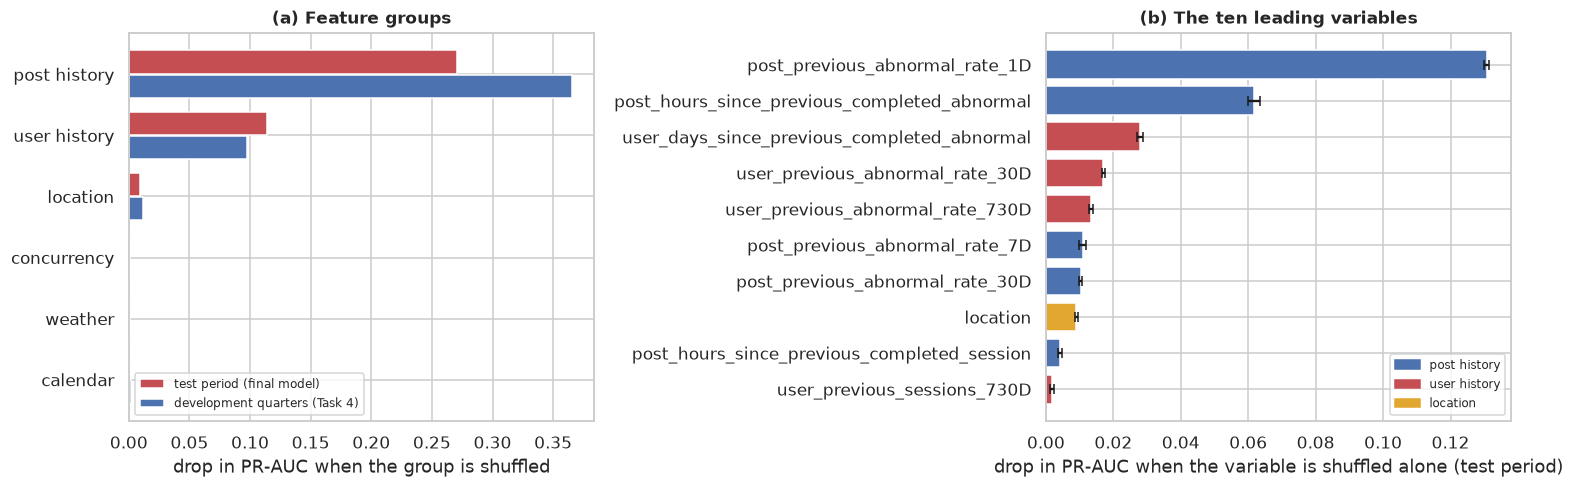

In [170]:
GROUPS = FEATURE_GROUPS["groups"]
INTERP_GROUPS = {"calendar": GROUPS["calendar"], "location": [c for c in GROUPS["location"] if c in FEATURES], "weather": GROUPS["weather"],
                 "post history": GROUPS["post_history"], "user history": GROUPS["user_history"], "concurrency": GROUPS["concurrency"]}
assert sorted(c for cols in INTERP_GROUPS.values() for c in cols) == sorted(FEATURES)


def permutation_drop(model, X, y, columns, repeats, rng):
    """PR-AUC drops when the rows of `columns` are shuffled jointly (one permutation per repeat, applied to every column of the group)."""
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        Xp = X.copy()
        perm = rng.permutation(len(X))
        for c in columns:
            Xp[c] = X[c].to_numpy()[perm]
        drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return drops


rng_perm = np.random.default_rng(SEED)
X_test = test[FEATURES]
t0 = time.time()
group_drops = {g: permutation_drop(final_model, X_test, y_test, cols, 5, rng_perm) for g, cols in INTERP_GROUPS.items()}
var_drops = {c: permutation_drop(final_model, X_test, y_test, [c], 3, rng_perm) for c in FEATURES}
print(f"permutation importance on the test period computed in {time.time() - t0:.0f} s (base PR-AUC {pr_final:.4f})")

dev_groups = {r["name"]: r for r in TASK4["importance"]["groups"]}
dev_vars = {r["name"]: r for r in TASK4["importance"]["variables"]}
group_importance = pd.DataFrame({"features": {g: len(c) for g, c in INTERP_GROUPS.items()},
                                 "test: PR-AUC drop": {g: np.mean(d) for g, d in group_drops.items()},
                                 "test: std": {g: np.std(d, ddof=1) for g, d in group_drops.items()},
                                 "development (Task 4): PR-AUC drop": {g: dev_groups[g]["PR-AUC drop"] for g in INTERP_GROUPS}}).sort_values("test: PR-AUC drop", ascending=False)
group_importance["test as a share of development"] = group_importance["test: PR-AUC drop"] / group_importance["development (Task 4): PR-AUC drop"]
display(group_importance.style.format({"test: PR-AUC drop": "{:.4f}", "test: std": "{:.4f}", "development (Task 4): PR-AUC drop": "{:.4f}", "test as a share of development": "{:.0%}"}))
var_importance = pd.DataFrame({"group": {c: g for g, cols in INTERP_GROUPS.items() for c in cols}, "test: PR-AUC drop": {c: np.mean(d) for c, d in var_drops.items()},
                               "test: std": {c: np.std(d, ddof=1) for c, d in var_drops.items()},
                               "development (Task 4): PR-AUC drop": {c: dev_vars[c]["PR-AUC drop"] for c in FEATURES}}).sort_values("test: PR-AUC drop", ascending=False)
display(var_importance.head(10).style.format({"test: PR-AUC drop": "{:.4f}", "test: std": "{:.4f}", "development (Task 4): PR-AUC drop": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
g = group_importance.iloc[::-1]
axes[0].barh(np.arange(len(g)) + 0.2, g["test: PR-AUC drop"], height=0.38, color=C_ABN, label="test period (final model)")
axes[0].barh(np.arange(len(g)) - 0.2, g["development (Task 4): PR-AUC drop"], height=0.38, color=C_NORMAL, label="development quarters (Task 4)")
axes[0].set_yticks(np.arange(len(g))); axes[0].set_yticklabels(g.index)
axes[0].set_xlabel("drop in PR-AUC when the group is shuffled"); axes[0].set_title("(a) Feature groups"); axes[0].legend(fontsize=8)
v = var_importance.head(10).iloc[::-1]
palette = dict(zip(INTERP_GROUPS, [C_GREY, C_ORANGE, C_GREEN, C_NORMAL, C_ABN, C_PURPLE]))
axes[1].barh(v.index, v["test: PR-AUC drop"], xerr=v["test: std"], color=[palette[x] for x in v["group"]], capsize=3)
axes[1].set_xlabel("drop in PR-AUC when the variable is shuffled alone (test period)"); axes[1].set_title("(b) The ten leading variables")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[x]) for x in dict.fromkeys(v["group"][::-1])], labels=list(dict.fromkeys(v["group"][::-1])), fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "09_1_permutation_importance")

The model relies on the same two groups in the same order as in development. On the test period, shuffling the post history lowers the PR-AUC by 0.271 and shuffling the user history by 0.114; location costs 0.009 and concurrency, weather and calendar less than 0.001 each, so the model barely uses them. The Task 4 values on the four validation quarters are 0.366 for the post history and 0.097 for the user history.
Two changes stand out. The post history counts for less than before (74% of its development value), and the user history for more (117%). Because the test PR-AUC is lower (0.532 against 0.626), all the drops are expected to be smaller, so the rise of the user history is stronger than the figures suggest.

Among single variables, the abnormal rate of the post in the last day is still the leading one (0.131, against 0.196 in development), but the time since the last abnormal session of the post grows from 0.038 to 0.062, and the user variables gain weight: the days since the last abnormal session of the user (0.028), the abnormal rate of the user in 30 days (0.017, against 0.007) and in 730 days (0.013). The 7-day rate that B1 uses falls to 0.011 (from 0.026), well behind the two variables
that give the most recent information on the post. The standard deviations over the shuffles are at most 0.0017, so they are not what limits the comparison: the limit is that the development values come from four different fitted models.

### 9.2 The shape of the effects: partial dependence

Partial dependence is not in the course slides. We use it because it is the model-based version of the decile curves of Task 1: those show the abnormal share as one history variable rises, and partial dependence shows the average score of the model as one variable moves while the others stay as observed. It is computed on a random sample of 20,000 test sessions with the final model. It needs complete values to build its grid, so we take the two most important variables
without missing values of each of the two information groups that the model uses, post history and user history. The dashed line is the abnormal share of the test period. The hours
since the last abnormal session of the post are drawn for the first 48 hours only, because the effect is concentrated there.

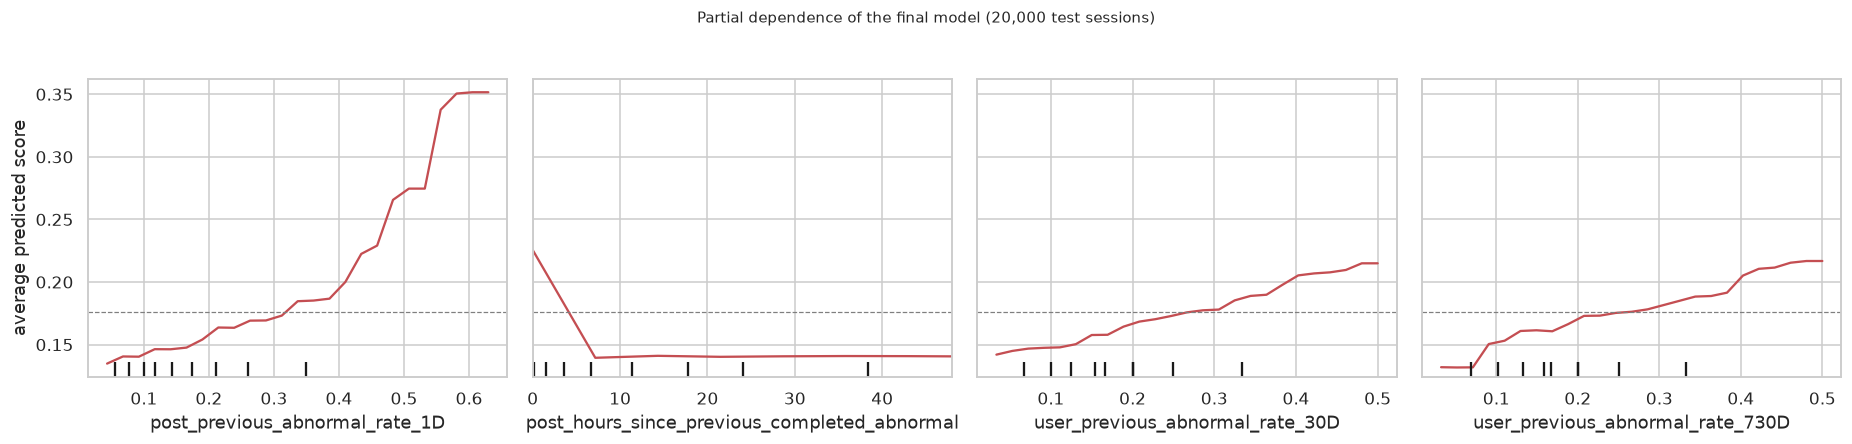

Variables shown: ['post_previous_abnormal_rate_1D', 'post_hours_since_previous_completed_abnormal', 'user_previous_abnormal_rate_30D', 'user_previous_abnormal_rate_730D']


In [171]:
pd_sample = test.sample(20_000, random_state=SEED)[FEATURES]
excluded = set(FEATURE_GROUPS["categorical"]) | set(FEATURE_GROUPS["binary"]) | {"hour", "dow"}
complete = [c for c in var_importance.index if pd_sample[c].notna().all() and c not in excluded]
pdp_vars = [c for c in complete if c in INTERP_GROUPS["post history"]][:2] + [c for c in complete if c in INTERP_GROUPS["user history"]][:2]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
PartialDependenceDisplay.from_estimator(final_model, pd_sample, features=pdp_vars, kind="average", grid_resolution=25, percentiles=(0.02, 0.98), ax=axes, line_kw={"color": C_ABN})
for ax, name in zip(axes, pdp_vars):
    ax.axhline(y_test.mean(), color=C_GREY, ls="--", lw=0.8)
    ax.set_ylabel("")
    if name == "post_hours_since_previous_completed_abnormal":
        ax.set_xlim(0, 48)
axes[0].set_ylabel("average predicted score")
fig.suptitle("Partial dependence of the final model (20,000 test sessions)", fontsize=10, y=1.03)
fig.tight_layout()
savefig(fig, "09_2_partial_dependence")
print("Variables shown:", pdp_vars)

The average predicted score stays between 0.13 and 0.17 while the 1-day abnormal rate of the post is below 0.3, then rises faster and reaches about 0.35 at a rate of 0.6, so the model reacts to a post that is failing and not to small differences in a healthy one. For the time since the last abnormal session, the score is about 0.23 right after a failure and falls to about 0.14 in the first hours (the grid is too coarse to resolve the first 7 hours) and stays flat afterwards: the signal is
"a failure at this post a few hours ago", not a slow decay. The two user variables raise the score gradually, from about 0.14 to about 0.22 as the abnormal rate of the user goes from near 0 to 0.5, an effect much smaller than that of the post. All the effects have the expected direction, with no sign of a reversed or irregular relation, and the score is above the abnormal share of the test (dashed line, 0.176) only from a 1-day post rate of about 0.3, or from a user rate of about 0.25 to 0.3.

### 9.3 What this interpretation cannot tell us

These methods describe how the fitted model uses its inputs, not what causes failures. Permutation importance gives an importance to correlated variables jointly: when a single window is shuffled, the other windows still carry part of its information, so the single-variable values understate each of them, and the group values avoid this only for the ranking of groups. A shuffled group can also create combinations
of values that never occur (a low 1-day rate with a failure a minute ago), on which the model is not meant to work. Partial dependence has the same weakness, since it assumes that a variable can vary on its own while the others stay as observed, and the 1-day rate and the time since the last failure of the post are strongly linked. It also averages over sessions, so it hides differences between them; individual conditional curves would show them.
Both methods use the test labels here, so they are descriptive, and they explain the model as a whole, not why a given session was flagged; for that we would need a local method such as SHAP, which the course does not cover and we did not implement. Finally, the two leading groups are made of earlier outcomes (failures at the post and of the user), so "the history matters" says that the model reads recent failures, not what makes a post fail.

---
## 10. Practical consequences of the threshold and usefulness of the model

### 10.1 What the frozen cut-off means for an operator

The cut-off of 0.490 is a score, not a number of alerts, so the workload follows the number of sessions and the level of failures. The table translates the test result into
daily work. A session is an alert if its score is at least the cut-off. Posts with an alert are counted once per day.

In [172]:
test["date"] = test["start_time"].dt.normalize()
daily = test.groupby("date").agg(sessions=("flag", "size"), alerts=("flag", "sum"), abnormal=(TARGET, "sum"))
daily["correct alerts"] = test[test["flag"] & (test[TARGET] == 1)].groupby("date").size().reindex(daily.index).fillna(0)
daily["false alerts"] = daily["alerts"] - daily["correct alerts"]
daily["missed"] = daily["abnormal"] - daily["correct alerts"]
daily["posts with an alert"] = test[test["flag"]].groupby("date")["post_id"].nunique().reindex(daily.index).fillna(0)
daily["alert rate"] = daily["alerts"] / daily["sessions"]
per_day = pd.DataFrame({"mean per day": daily.mean(), "minimum": daily.min(), "maximum": daily.max()}).loc[
    ["sessions", "alerts", "correct alerts", "false alerts", "missed", "posts with an alert", "alert rate"]]
display(per_day.style.format("{:.1f}").format({"mean per day": "{:.3f}", "minimum": "{:.3f}", "maximum": "{:.3f}"}, subset=pd.IndexSlice[["alert rate"], :]))
print(f"{len(daily)} days in the test period | the 10% target would give {0.10 * daily['sessions'].mean():.1f} alerts per day; the frozen cut-off gives {daily['alerts'].mean():.1f}")

,mean per day,minimum,maximum
sessions,870.4,668.0,1128.0
alerts,64.6,18.0,210.0
correct alerts,43.8,10.0,156.0
false alerts,20.9,7.0,54.0
missed,109.4,61.0,164.0
posts with an alert,19.8,10.0,30.0
alert rate,0.073,0.022,0.192


92 days in the test period | the 10% target would give 87.0 alerts per day; the frozen cut-off gives 64.6


On an average day the test period has 870 sessions and the frozen cut-off raises 64.6 alerts, of which 43.8 are correct and 20.9 are false, and 109.4 abnormal sessions go without an alert. The alerts come from 19.8 posts a day on average (10 to 30), about three alerts per post, so the number of inspections is lower than the number of alerts. The daily alert rate is 7.3% on average and goes
from 2.2% to 19.2%, which is 18 to 210 alerts a day. The 10% target would give 87.0 alerts a day, 22.4 more than the cut-off gives. The workload follows the failures: on a bad day the operator receives three times the average number of alerts, and a team sized for the average would be overwhelmed. If the team has a daily capacity, the alternative is to inspect only
the highest scores of each day. Even in a quiet day, the model finds only a part of the failures: the 109 sessions missed a day are about 1.7 times the 65 alerts, so the model is a tool to prioritise the posts that are failing, not a complete detector.

### 10.2 What a different capacity would give

The 10% budget was an assumption. The table applies the three budgets of the protocol to the test scores (the sessions with the highest scores, ties broken at random), next to the
frozen cut-off and next to the cut-off that would flag exactly 10% of the test sessions. These cut-offs are computed from the test scores after the fact. They only show what another capacity would
have given on this quarter, they did not exist when the cut-off was chosen, and the frozen cut-off of 0.490 is the one in force. The figure shows how precision, recall and the alert rate change with the cut-off on the test scores.

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
frozen cut-off 0.490,0.490,0.677,0.286,0.402,7.4%,50.3,24.0,125.6
top 5% of the scores,0.577,0.766,0.218,0.339,5.0%,38.3,11.7,137.6
top 10% of the scores,0.413,0.614,0.349,0.445,10.0%,61.4,38.6,114.5
top 20% of the scores,0.245,0.466,0.529,0.495,20.0%,93.1,106.9,82.8


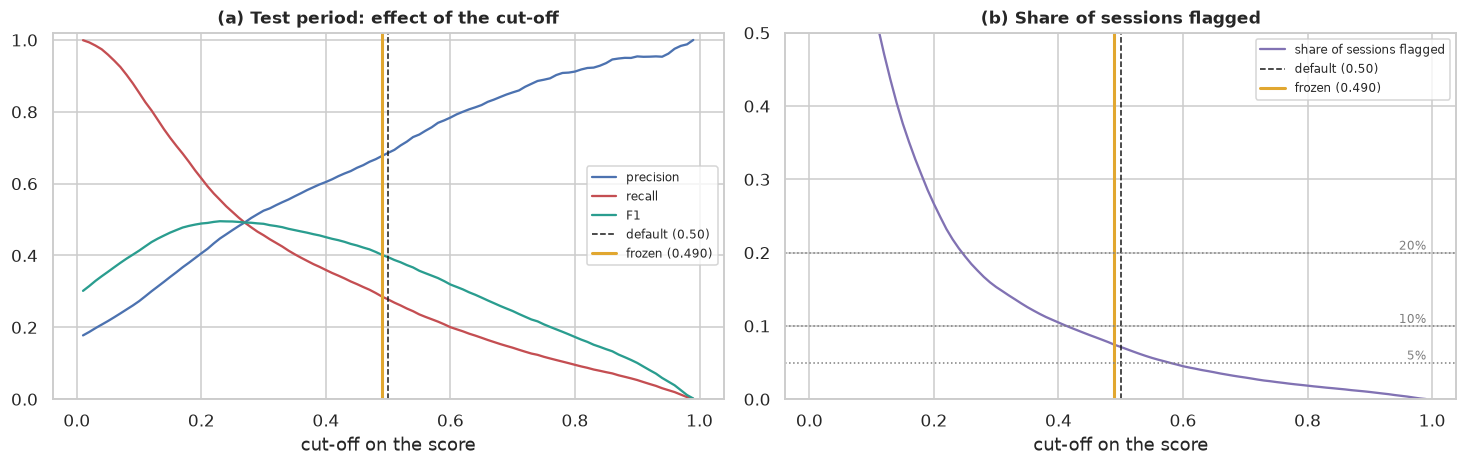

In [173]:
budget_rows = {f"frozen cut-off {CUT_OFF:.3f}": flag_final}
for q in ALERT_BUDGETS:
    budget_rows[f"top {q:.0%} of the scores"] = top_k_flags(p_test, int(round(q * len(p_test))))
budget_table = pd.DataFrame({name: confusion_metrics(y_test, flagged) for name, flagged in budget_rows.items()}).T
budget_table["cut-off"] = [CUT_OFF] + [float(np.sort(p_test)[::-1][int(round(q * len(p_test))) - 1]) for q in ALERT_BUDGETS]
display(budget_table[["cut-off", "precision", "recall", "F1", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]].style.format(
    {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}", "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}))

grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
curve = pd.DataFrame([{"cut-off": t, **confusion_metrics(y_test, p_test >= t)} for t in grid])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].plot(grid, curve["precision"], color=C_NORMAL, label="precision"); axes[0].plot(grid, curve["recall"], color=C_ABN, label="recall"); axes[0].plot(grid, curve["F1"], color=C_GREEN, label="F1")
axes[1].plot(grid, curve["alert rate"], color=C_PURPLE, label="share of sessions flagged")
for ax in axes:
    ax.axvline(0.5, color="k", ls="--", lw=1, label="default (0.50)")
    ax.axvline(CUT_OFF, color=C_ORANGE, lw=2, label=f"frozen ({CUT_OFF:.3f})")
    ax.set_xlabel("cut-off on the score")
axes[0].set_ylim(0, 1.02); axes[0].set_title("(a) Test period: effect of the cut-off"); axes[0].legend(fontsize=8, loc="center right")
for q in ALERT_BUDGETS:
    axes[1].axhline(q, color=C_GREY, ls=":", lw=1); axes[1].text(0.99, q, f"{q:.0%}", ha="right", va="bottom", fontsize=8, color=C_GREY)
axes[1].set_ylim(0, 0.5); axes[1].set_title("(b) Share of sessions flagged"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "10_1_threshold_on_test")

With the sessions of highest score, the three budgets of the protocol give, per 1,000 sessions, 38.3 correct and 11.7 false alerts at 5% (precision 0.766, recall 0.218), 61.4 and 38.6 at 10% (0.614, 0.349) and 93.1 and 106.9 at 20% (0.466, 0.529). The cut-offs that would give these budgets on the test scores are 0.577, 0.413 and 0.245. The frozen cut-off of 0.490 sits between the first two. On these test scores, flagging
exactly 10% of the sessions takes a cut-off of 0.413, a value that can only be known after the test. Going from 5% to 10% adds 23.1 correct alerts for 26.9 false ones (marginal precision 0.46), and from 10% to 20% adds 31.7 correct for 68.3 false (0.32), more than two false alerts for each extra failure found. In development the step from 5% to 10% was still better than even (Task 4: 29.3 correct against 20.7 false), so the quarter makes extra alerts less worthwhile.
The figure shows that the F1-score on the test peaks near a cut-off of 0.2 to 0.3, well below the frozen cut-off (F1 of 0.402 at the frozen cut-off, about 0.50 at the peak). The protocol does not use F1 to choose, so none of these after-the-fact cut-offs replaces the frozen 0.490.

### 10.3 Is the model worth using? Costs of the two errors

Task 2 left the cost ratio `c` (cost of a missed failure divided by cost of a false alert) open. Instead of fixing it, we ask for which values of `c` an operator is better off
with the model than without it. The cost per 1,000 sessions is measured in false alerts (one false alert costs 1): `cost = false alerts + c × missed failures`. The model is compared
with three alternatives: no alerts at all (every failure is missed), an alert on every session (every normal session is a false alert) and B1 with the same number of alerts. The
evaluation lab used `c = 10`; the other values show how the result depends on it. These costs are an assumption of this notebook, not data.

In [174]:
n = len(y_test)
final_m = confusion_metrics(y_test, flag_final)
b1_m = confusion_metrics(y_test, flag_b1_matched)
abnormal_per_1000, normal_per_1000 = 1000 * y_test.mean(), 1000 * (1 - y_test.mean())
options = {"final model": (final_m["false per 1,000"], final_m["missed per 1,000"]), "B1, same number of alerts": (b1_m["false per 1,000"], b1_m["missed per 1,000"]),
           "no alerts": (0.0, abnormal_per_1000), "alert on every session": (normal_per_1000, 0.0)}
cost_table = pd.DataFrame({f"c = {c}": {name: fp + c * fn for name, (fp, fn) in options.items()} for c in (1, 2, 3, 5, 10)})
cost_table["cheapest option"] = ""
cheapest = cost_table.drop(columns="cheapest option").idxmin()
display(cost_table.drop(columns="cheapest option").style.format("{:.1f}").highlight_min(axis=0, color="#d8f0d8"))
lower = final_m["false per 1,000"] / final_m["correct per 1,000"]
upper = (normal_per_1000 - final_m["false per 1,000"]) / final_m["missed per 1,000"]
print(f"Per 1,000 sessions: {abnormal_per_1000:.1f} abnormal and {normal_per_1000:.1f} normal. Cheapest option by c: {cheapest.to_dict()}")
print(f"The final model costs less than no alerts when c > {lower:.2f} and less than an alert on every session when c < {upper:.2f}.")
print(f"Against B1 with the same number of alerts: {final_m['correct per 1,000'] - b1_m['correct per 1,000']:+.1f} correct, "
      f"{final_m['false per 1,000'] - b1_m['false per 1,000']:+.1f} false and {final_m['missed per 1,000'] - b1_m['missed per 1,000']:+.1f} missed alerts per 1,000 sessions.")

# If an operator did know c, the cut-off of Task 2 (Section 5) would be t* = 1 / (1 + c), valid when the scores are probabilities (Task 4 found them close to calibrated).
# The rule uses only c, not the test labels. The table shows what each value of c would give next to the frozen cut-off; it is a what-if and changes nothing.
rows = {}
for c in (1, 2, 3, 5, 10):
    t = 1 / (1 + c)
    m = confusion_metrics(y_test, p_test >= t)
    own, frozen_cost = m["false per 1,000"] + c * m["missed per 1,000"], final_m["false per 1,000"] + c * final_m["missed per 1,000"]
    rows[f"c = {c}"] = {"cut-off t*": t, "alert rate": m["alert rate"], "precision": m["precision"], "recall": m["recall"], "false per 1,000": m["false per 1,000"],
                        "missed per 1,000": m["missed per 1,000"], "cost with t*": own, "cost with the frozen cut-off": frozen_cost, "saving": frozen_cost - own}
cost_cutoff_table = pd.DataFrame(rows).T
display(cost_cutoff_table.style.format({"cut-off t*": "{:.3f}", "alert rate": "{:.1%}", "precision": "{:.3f}", "recall": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}",
                                        "cost with t*": "{:.1f}", "cost with the frozen cut-off": "{:.1f}", "saving": "{:.1f}"}))

,c = 1,c = 2,c = 3,c = 5,c = 10
final model,149.6,275.3,400.9,652.2,1280.5
"B1, same number of alerts",174.5,312.6,450.7,726.9,1417.4
no alerts,175.9,351.8,527.8,879.6,1759.2
alert on every session,824.1,824.1,824.1,824.1,824.1


Per 1,000 sessions: 175.9 abnormal and 824.1 normal. Cheapest option by c: {'c = 1': 'final model', 'c = 2': 'final model', 'c = 3': 'final model', 'c = 5': 'final model', 'c = 10': 'alert on every session'}
The final model costs less than no alerts when c > 0.48 and less than an alert on every session when c < 6.37.
Against B1 with the same number of alerts: +12.4 correct, -12.4 false and -12.4 missed alerts per 1,000 sessions.


,cut-off t*,alert rate,precision,recall,"false per 1,000","missed per 1,000",cost with t*,cost with the frozen cut-off,saving
c = 1,0.500,7.1%,0.686,0.278,22.4,127.1,149.5,149.6,0.2
c = 2,0.333,13.4%,0.551,0.421,60.3,101.8,264.0,275.3,11.3
c = 3,0.250,19.5%,0.471,0.521,103.1,84.2,355.9,400.9,45.1
c = 5,0.167,33.5%,0.363,0.691,213.7,54.3,485.2,652.2,167.1
c = 10,0.091,58.9%,0.262,0.877,434.9,21.7,651.8,1280.5,628.6


For a cost of one false alert and c for a missed failure, the final model is the cheapest of the four options for c from 1 to 5. At c = 10, the value of the evaluation lab, an alert on every session is cheaper (824.1 against 1,280.5 per 1,000 sessions). The model costs less than no alerts when c is above 0.48 (false alerts divided by correct alerts) and less than alerting every session when c is below 6.37. Against B1 with the same number of alerts, the model is cheaper for any c, because it
has 12.4 more correct alerts, 12.4 fewer false alerts and 12.4 fewer missed sessions per 1,000.

The cost-based cut-off of Task 2, t* = 1/(1 + c), tells us which cost ratio the frozen cut-off assumes. For c = 1 it is 0.500, almost the frozen 0.490 (the costs differ by 0.2 per 1,000 sessions), which is the cost ratio of about 1.04 that Task 4 found. On the test scores, a higher c would have meant a lower cut-off and much more work: at c = 2 (t* = 0.333) the alert rate would be 13.4% and the cost 264.0 instead of 275.3; at c = 5 (t* = 0.167) it would be 33.5%, with a
precision of 0.363 and a recall of 0.691, and the cost 485.2 instead of 652.2; at c = 10 (t* = 0.091) it would be 58.9% with a precision of 0.262 and a recall of 0.877, and the cost 651.8, below the 824.1 of alerting every session. These figures come from the test period, so they describe what the frozen cut-off assumes and cannot be used to set it; the frozen 0.490 stays. It fits a missed failure that costs about as much as a false alert, while Task 2 argued that a miss costs more, so the cost ratio is the main assumption behind the operating point.
That ratio and the capacity are not in the data. They have to come from the operator, and a new cut-off would be chosen from them on development data at a future refit.

In [175]:
log_decision("10", "Threshold consequences and usefulness", "The frozen cut-off is kept; the capacity and cost ratio remain assumptions and are reported as ranges.",
             f"On average {daily['alerts'].mean():.0f} alerts per day ({daily['false alerts'].mean():.0f} false) for {daily['sessions'].mean():.0f} sessions; the model costs less than no alerts "
             f"for c > {lower:.2f} and less than alerting every session for c < {upper:.2f}.")

---
## 11. Conclusions, limitations and recommendations

### 11.1 Main findings

The final model is gradient boosting with its Task 3 configuration (200 trees of depth 6). Its mean development PR-AUC is 0.626, within the tolerance of the random forest (0.622), and we chose it for its better worst fold, its lower variation between folds and a cost four times smaller. Tuning did not improve it, and the baseline is B1, the 7-day abnormal rate of the post.

On the test period the model reaches a PR-AUC of 0.532, against 0.381 for B1 and 0.178 for no skill, a gain of 0.152 over B1 (interval +0.145 to +0.158) that is larger than in any development fold. At the frozen cut-off of 0.490 it flags 7.4% of the sessions with a precision of 0.677, a recall of 0.286, an F1 of 0.402, a balanced accuracy of 0.628 and an MCC of 0.373: 50.3 correct alerts, 24.0 false alerts and 125.6 missed abnormal sessions per 1,000 sessions.

The fall from development is mostly arithmetic: 87% of the drop in PR-AUC from fold 4 comes from the lower abnormal share (21.1% to 17.6%). The ranking did weaken (ROC-AUC 0.838 to 0.794, lift 3.12 to 3.03, a decline that was already visible in development), and B1 weakened more. We see no drift inside the quarter.

The model beats B1 in every district and station. It works best at the posts that are failing now, where 9 posts take 46.4% of the alerts, and worst in low-failure stations, for new users (recall 0.146) and for failures that start more than 6 hours after the last failure of the post, which hold 52.9% of all missed failures. The false positives look like the true positives (a failure at the post minutes before), and the missed failures look like normal sessions. The causes least detected are the DC output fault, the BMS failure, the faulty connection and the control-loop failure (recall 0.19 to 0.22). The model relies on the post history, then on the user history, and the user history gains weight on the test.

For its operator, the model costs less than no alerts for c above 0.48 and less than alerting every session for c below 6.37. It gives about 65 alerts a day (21 false), concentrated in about 20 posts, which helps to prioritise the posts that are failing, but it finds only 29% of the failures, so it cannot work as a complete detector.

### 11.2 Limitations

The test result is one quarter of 80,081 sessions, so it measures that quarter and not a long-run average, and it was scored first in Task 4, which means that no analysis in this notebook could have changed a choice, but also that we have no second test. The capacity of the operator and the cost ratio are unknown: the 10% budget is an assumption, the frozen cut-off corresponds to a cost ratio of about 1, and the costs of Section 10.3 are an assumption of the notebook.
Subgroup, weekly and per-post results come from the same quarter, some of them from few abnormal sessions, and only the overall comparison has a confidence interval, so small differences between groups should not be read as findings. The bootstrap and the McNemar test treat sessions as independent, which they are not. The model depends on histories that are supplied with the data and assumed available at the start of the session, and on weather taken as a forecast (Task 2).
The error analysis uses the end cause only after the fact, and three causes have fewer than 20 test sessions. The calibration of the scores was checked on the development quarters (Task 4) and not on the test. The interpretation has the limits of Section 9.3, and the user history is a behaviour profile of identified drivers, which raises the privacy question that Task 2 noted.

### 11.3 Recommendations for future improvement

Several improvements follow from these results. The first is to keep the model current: refit it every quarter with the rolling origin used here and follow the lift, the ROC-AUC and the alert rate week by week. The development ROC-AUC lay between 0.825 and 0.844 and the test is at 0.794, so a value below the development range is a reasonable trigger for a review, and the reliability of the scores should be checked on the most recent quarter before a score is read as a probability. The operator should also give us the real cost of a missed failure and the daily inspection capacity before the next refit, so that the cut-off is set from them on development data instead of from our assumed 10%. With a fixed team, inspecting the highest scores of each day would keep the workload steady, and grouping the alerts by post and day (about three alerts per alerted post) would match how maintenance is organised.

The other improvements concern the failures the model misses. It sees almost nothing of the 52.9% of missed failures that follow more than 6 hours without a failure at the post. Variables known at the start of a session that are not in this dataset (age, maintenance record and firmware of the post, charger type, vehicle model), or telemetry from the previous sessions, could help there. New users, with a recall of 0.146, could get a fallback based on the post only, unless the platform can identify the account before the start. Finally, the target merges 13 causes, and the model finds some (DC switching device, recall 0.50) much better than others (BMS, DC output, control loop, about 0.2), so a model per group of causes, or a cost per cause, would let the operator act on the severe faults first.

---
## 12. Saved files and decision log

The notebook writes its results (`prepared/task5_results.json`), the decision log (`prepared/task5_decision_log.csv`) and its figures (`prepared/figures_task5/`). It reads the Task 4 files
and changes none of them. The last check confirms that the frozen file is the one that Section 1 hashed.

In [176]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records", date_format="iso"))


RESULTS = {
    "note": "Task 4 scored the test period once on 2026-10-27; this notebook reproduces that score from the frozen file and adds descriptive analyses. No choice was changed.",
    "frozen_file": {"path": str(FROZEN_FILE), "sha256": FROZEN_HASH, "frozen_at": FROZEN["frozen_at"]},
    "final_model": {"model": FROZEN["model"], "configuration": FROZEN["configuration"], "cut_off": CUT_OFF, "baseline": "B1 post failure rate (7 days)", "baseline_cut_off": B1_CUT},
    "selection": {"candidates": records(candidates), "within_tolerance": list(step1.index), "selected": SELECTED_NAME},
    "test": {"sessions": int(len(test)), "abnormal_share": float(y_test.mean()), "PR-AUC": {"final": pr_final, "B1": pr_b1, "B0": pr_b0},
             "PR-AUC_gain_over_B1": {"value": pr_final - pr_b1, "bootstrap_95_interval": list(gain_ci)}, "mcnemar": {"only_final_right": only_final, "only_b1_right": only_b1, "p": mcnemar_p},
             "comparison": records(comparison[["PR-AUC"] + COLUMNS[1:] + ["TP", "FP", "FN", "TN"]]), "development_vs_test": records(dev_vs_test)},
    "time": {"periods": records(time_table), "weekly": records(weekly), "fall_from_fold_4_to_test": FALL_SPLIT},
    "groups": {"districts": records(district_table), "stations": records(station_table), "users": records(user_table), "posts_concentration": concentration},
    "error_analysis": {"outcomes": {k_: int(v_) for k_, v_ in outcome_counts.items()}, "end_causes": records(cause_table), "bands": records(band_table)},
    "interpretation": {"groups": records(group_importance), "top_variables": records(var_importance.head(10)), "partial_dependence_variables": pdp_vars},
    "operations": {"per_day": records(per_day), "budgets_on_test": records(budget_table[["cut-off", "precision", "recall", "F1", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]]),
                   "costs": records(cost_table.drop(columns="cheapest option")), "cost_based_cut_offs": records(cost_cutoff_table), "break_even_c": {"lower": lower, "upper": upper}},
}
(OUT_DIR / "task5_results.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task5_decision_log.csv", index=False)
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()
print("Saved: task5_results.json, task5_decision_log.csv | figures in", FIG_DIR, "| the frozen file is unchanged")
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: task5_results.json, task5_decision_log.csv | figures in prepared/figures_task5 | the frozen file is unchanged


section,topic,decision,evidence
2,Final model,"Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, 27 features; baseline B1 (7-day failure rate of the post), B0 as the chance reference.","Mean PR-AUC 0.626, within the tolerance of 0.005 of the random forest (0.622), with the better worst fold and standard deviation, the lower cost per fold and no tuned configuration that passed the rule of Task 4. Selection used development results only."
2,Threshold,"Cut-off 0.4899 from the 10% alert rate on the pooled out-of-fold predictions (Task 4), no calibrator.","Development operating point: precision 0.740, recall 0.403; calibration gap at most 0.015."
3,Refit and baseline cut-off,"Final model refitted on 346,931 development sessions; B1 cut-off 0.3931 from the same 10% criterion on development data.",48 sessions purged (ended on or after the test start); the four-fold refit reproduces the frozen mean PR-AUC (0.6258) and the frozen cut-off (0.4899).
4,Test scoring,The frozen model scores the test period; nothing is changed after this point and every later analysis is descriptive.,"Test PR-AUC 0.5324, equal to the Task 4 value 0.5324; alert rate 7.43% at the frozen cut-off; frozen file unchanged (SHA-256 9f111a92abfd...)."
5,Comparison with the baseline,Reported as observed at the frozen operating points; no choice changes.,"Test PR-AUC 0.5324 against 0.3809 for B1 (gain +0.1516, 95% interval [+0.1449, +0.1580]); at the frozen cut-off: precision 0.677, recall 0.286, F1 0.402, balanced accuracy 0.628, MCC 0.373, alert rate 7.43%."
6-7,Time and group analysis,Descriptive only: the frozen cut-off is applied everywhere and no group-specific threshold is introduced.,"Test months PR-AUC 0.553, 0.483, 0.551; districts 3, stations 12, posts 88."
8,Error analysis,"Descriptive: patterns by failure type, post history, user, time of day, weather, district and post. No change to the model or the cut-off.","At the frozen cut-off: 4,026 true positives, 1,921 false positives, 10,062 false negatives; overall recall 0.286 over 12 end causes."
10,Threshold consequences and usefulness,The frozen cut-off is kept; the capacity and cost ratio remain assumptions and are reported as ranges.,On average 65 alerts per day (21 false) for 870 sessions; the model costs less than no alerts for c > 0.48 and less than alerting every session for c < 6.37.
